In [ ]:
# ============================================================
# DOAR E1-A2 — FULL COLAB GPU EXPERIMENT RUNNER
# FIXED: Restores + verifies frozen T0 manifest before training
#
# Repository: GitHub
# Dataset: Google Drive
# Frozen T0 manifest: Google Drive -> restored into cloned repo
# Results: Google Drive (persistent)
# ============================================================

# ----------------------------
# 1. MOUNT GOOGLE DRIVE
# ----------------------------
from google.colab import drive
drive.mount("/content/drive")

# ----------------------------
# 2. IMPORTS
# ----------------------------
from pathlib import Path
import os
import sys
import json
import shutil
import subprocess
import hashlib
import pandas as pd

# ----------------------------
# 3. CONFIGURATION
# ----------------------------

GITHUB_REPO = "https://github.com/HHemaly/DOAR.git"

# Frozen E1 GPU-ready checkpoint.
GIT_REF = "checkpoint/e1-gpu-ready-v1"

EXPECTED_COMMIT = (
    "a3affe71c1838dc1e0c2b0a606dfbac08c41470c"
)

REPO_DIR = Path("/content/DOAR")

# ------------------------------------------------------------
# YOUR DATASET IN GOOGLE DRIVE
# ------------------------------------------------------------
DATASET_ROOT = Path(
    "/content/drive/MyDrive/Masters/Datasets/Combined_Drawing"
)

# ------------------------------------------------------------
# PERMANENT E1 RESULTS
# ------------------------------------------------------------
OUTPUT_ROOT = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1A"
)

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# FROZEN T0 MANIFEST
#
# Recommended permanent location in Google Drive:
# MyDrive/Masters/DOAR_FROZEN_T0/partition_manifest.csv
# ------------------------------------------------------------
T0_DRIVE_MANIFEST = Path(
    "/content/drive/MyDrive/Masters/DOAR_FROZEN_T0/partition_manifest.csv"
)

# Location required by the existing E1 code inside cloned repo.
T0_REPO_MANIFEST = (
    REPO_DIR
    / "outputs"
    / "t0_automated"
    / "final_partition"
    / "partition_manifest.csv"
)

# Exact frozen scientific manifest.
EXPECTED_T0_SHA256 = (
    "4631ce8bddde64755ba44758827310703"
    "f1b332bcb28f72b55f22b3b19b92c9d"
)

EXPECTED_COUNTS = {
    "train": 2599,
    "valid": 284,
    "test": 512,
}

print("=" * 70)
print("DOAR E1-A2 GPU EXPERIMENT — FIXED COLAB RUNNER")
print("=" * 70)

print("Dataset:")
print(DATASET_ROOT)

print("\nOutput:")
print(OUTPUT_ROOT)

print("\nGit ref:")
print(GIT_REF)

print("\nExpected frozen T0 SHA-256:")
print(EXPECTED_T0_SHA256)


# ============================================================
# HELPER FUNCTIONS
# ============================================================

def sha256_file(path: Path) -> str:
    """
    Compute SHA-256 without modifying the file.
    """
    h = hashlib.sha256()

    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)

    return h.hexdigest()


def verify_sha(path: Path, expected_sha: str) -> bool:
    """
    Return True only when file matches expected SHA exactly.
    """
    if not path.exists():
        return False

    actual = sha256_file(path)

    print(f"\nChecking:")
    print(path)
    print("SHA-256:", actual)

    return actual == expected_sha


def locate_frozen_t0_manifest() -> Path:
    """
    Find the exact frozen T0 manifest.

    Priority:
      1. Recommended permanent Drive location
      2. Several sensible known locations
      3. Search MyDrive/Masters for partition_manifest.csv

    A candidate is accepted ONLY if SHA-256 equals
    EXPECTED_T0_SHA256.
    """

    print("\n" + "=" * 70)
    print("LOCATING FROZEN T0 MANIFEST")
    print("=" * 70)

    candidates = [
        T0_DRIVE_MANIFEST,

        DATASET_ROOT / "_t0_frozen" / "partition_manifest.csv",

        DATASET_ROOT / "partition_manifest.csv",

        DATASET_ROOT.parent
        / "DOAR_FROZEN_T0"
        / "partition_manifest.csv",

        Path(
            "/content/drive/MyDrive/Masters/"
            "Datasets/DOAR_FROZEN_T0/partition_manifest.csv"
        ),
    ]

    checked = set()

    # --------------------------------------------------------
    # Check known locations first.
    # --------------------------------------------------------
    for candidate in candidates:

        candidate = candidate.resolve()

        if str(candidate) in checked:
            continue

        checked.add(str(candidate))

        if candidate.is_file():

            actual = sha256_file(candidate)

            print("\nFound candidate:")
            print(candidate)
            print("SHA-256:", actual)

            if actual == EXPECTED_T0_SHA256:

                print("\n✓ EXACT FROZEN T0 MANIFEST FOUND")
                return candidate

            else:

                print(
                    "✗ File name matches, but SHA is WRONG. "
                    "Ignoring this candidate."
                )

    # --------------------------------------------------------
    # Fallback:
    # Search only within MyDrive/Masters, not entire Drive.
    # --------------------------------------------------------
    masters_root = Path(
        "/content/drive/MyDrive/Masters"
    )

    print("\nSearching MyDrive/Masters for partition_manifest.csv ...")

    if masters_root.exists():

        try:

            for candidate in masters_root.rglob(
                "partition_manifest.csv"
            ):

                candidate = candidate.resolve()

                if str(candidate) in checked:
                    continue

                checked.add(str(candidate))

                try:
                    actual = sha256_file(candidate)
                except Exception as exc:
                    print(
                        "Could not hash:",
                        candidate,
                        exc
                    )
                    continue

                print("\nCandidate:")
                print(candidate)
                print("SHA-256:", actual)

                if actual == EXPECTED_T0_SHA256:

                    print(
                        "\n✓ EXACT FROZEN T0 MANIFEST FOUND"
                    )

                    return candidate

        except Exception as exc:

            print(
                "Drive search warning:",
                exc
            )

    # --------------------------------------------------------
    # Nothing with the correct SHA was found.
    # --------------------------------------------------------
    raise FileNotFoundError(
        "\n\n"
        "============================================================\n"
        "FROZEN T0 MANIFEST NOT FOUND\n"
        "============================================================\n\n"
        "This is NOT an image-dataset problem.\n\n"
        "The E1 experiment requires the exact frozen file:\n\n"
        "outputs/t0_automated/final_partition/"
        "partition_manifest.csv\n\n"
        "Expected SHA-256:\n"
        f"{EXPECTED_T0_SHA256}\n\n"
        "On the PC where the T0 experiment was created, locate:\n\n"
        "DOAR-work/outputs/t0_automated/final_partition/"
        "partition_manifest.csv\n\n"
        "Upload that EXACT file, without editing/resaving it, to:\n\n"
        "Google Drive -> MyDrive -> Masters -> DOAR_FROZEN_T0 -> "
        "partition_manifest.csv\n\n"
        "Then rerun this Colab cell.\n\n"
        "DO NOT bypass the SHA check and DO NOT train on a newly "
        "invented split."
    )


# ============================================================
# 4. VERIFY DATASET EXISTS
# ============================================================

print("\n" + "=" * 70)
print("VERIFYING IMAGE DATASET")
print("=" * 70)

assert DATASET_ROOT.exists(), (
    f"Dataset folder not found:\n{DATASET_ROOT}\n"
    "Check the Google Drive dataset path."
)

print("Dataset folder found.")

for folder in ["train", "valid", "test"]:

    path = DATASET_ROOT / folder

    print(
        f"{folder:5s}:",
        path.exists(),
        "->",
        path
    )

    assert path.exists(), (
        f"Required dataset folder missing: {path}"
    )

print("\n✓ Dataset top-level structure looks correct.")


# ============================================================
# 5. LOCATE FROZEN T0 MANIFEST IN DRIVE
# ============================================================

T0_SOURCE_MANIFEST = locate_frozen_t0_manifest()

source_sha = sha256_file(T0_SOURCE_MANIFEST)

assert source_sha == EXPECTED_T0_SHA256

print("\nFrozen manifest source:")
print(T0_SOURCE_MANIFEST)

print("\n✓ Frozen manifest SHA verified:")
print(source_sha)


# ============================================================
# 6. CLONE EXACT DOAR REPOSITORY
# ============================================================

print("\n" + "=" * 70)
print("CLONING DOAR REPOSITORY")
print("=" * 70)

if REPO_DIR.exists():
    shutil.rmtree(REPO_DIR)

subprocess.run(
    [
        "git",
        "clone",
        GITHUB_REPO,
        str(REPO_DIR),
    ],
    check=True,
)

os.chdir(REPO_DIR)

subprocess.run(
    [
        "git",
        "fetch",
        "--all",
        "--tags",
    ],
    check=True,
)

subprocess.run(
    [
        "git",
        "checkout",
        GIT_REF,
    ],
    check=True,
)

commit = subprocess.check_output(
    [
        "git",
        "rev-parse",
        "HEAD",
    ],
    text=True,
).strip()

print("\nRepository ready.")
print("Commit:", commit)

assert commit == EXPECTED_COMMIT, (
    "\nUnexpected experiment commit.\n"
    f"Expected: {EXPECTED_COMMIT}\n"
    f"Actual:   {commit}\n"
    "STOPPING for reproducibility."
)

print("\n✓ E1 GPU-ready checkpoint verified.")


# ============================================================
# 7. RESTORE FROZEN T0 MANIFEST INTO CLONED REPOSITORY
# ============================================================

print("\n" + "=" * 70)
print("RESTORING FROZEN T0 MANIFEST")
print("=" * 70)

T0_REPO_MANIFEST.parent.mkdir(
    parents=True,
    exist_ok=True,
)

shutil.copy2(
    T0_SOURCE_MANIFEST,
    T0_REPO_MANIFEST,
)

assert T0_REPO_MANIFEST.exists(), (
    "Failed to restore T0 manifest into cloned repository."
)

restored_sha = sha256_file(
    T0_REPO_MANIFEST
)

print("Source:")
print(T0_SOURCE_MANIFEST)

print("\nRestored to:")
print(T0_REPO_MANIFEST)

print("\nRestored SHA-256:")
print(restored_sha)

assert restored_sha == EXPECTED_T0_SHA256, (
    "\nRestored manifest SHA mismatch.\n"
    f"Expected: {EXPECTED_T0_SHA256}\n"
    f"Actual:   {restored_sha}\n"
    "STOPPING."
)

print(
    "\n✓ Frozen T0 manifest restored successfully "
    "and is byte-identical."
)


# ============================================================
# 8. INSTALL E1 DEPENDENCIES
# ============================================================

print("\n" + "=" * 70)
print("INSTALLING E1 DEPENDENCIES")
print("=" * 70)

requirements_file = (
    REPO_DIR
    / "experiments"
    / "E1_visual_representation"
    / "requirements-e1.txt"
)

assert requirements_file.exists(), (
    f"E1 requirements file missing: {requirements_file}"
)

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "-r",
        str(requirements_file),
        "--upgrade-strategy",
        "only-if-needed",
    ],
    check=True,
)

print("✓ Dependencies installed.")


# ============================================================
# 9. VERIFY GPU / CUDA
# ============================================================

import torch

print("\n" + "=" * 70)
print("GPU CHECK")
print("=" * 70)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

assert torch.cuda.is_available(), (
    "\nCUDA GPU is NOT available.\n"
    "In Colab choose:\n"
    "Runtime -> Change runtime type -> GPU\n"
    "then restart the runtime."
)

GPU_NAME = torch.cuda.get_device_name(0)

VRAM_GB = (
    torch.cuda.get_device_properties(0).total_memory
    / (1024 ** 3)
)

print("GPU:", GPU_NAME)
print("CUDA:", torch.version.cuda)
print("VRAM:", round(VRAM_GB, 2), "GB")

print("\n✓ GPU ready.")


# ============================================================
# 10. VERIFY FROZEN T0 DATASET USING ORIGINAL REPO CODE
# ============================================================

print("\n" + "=" * 70)
print("VERIFYING FROZEN T0 DATASET")
print("=" * 70)

verification_report_path = (
    OUTPUT_ROOT
    / "T0_COLAB_VERIFICATION.json"
)

verify_cmd = [
    sys.executable,

    "experiments/E1_visual_representation/"
    "scripts/prepare_e1_dataset.py",

    "--dataset-root",
    str(DATASET_ROOT),

    "--verify-only",

    "--output",
    str(verification_report_path),
]

verify = subprocess.run(
    verify_cmd,
    text=True,
    capture_output=True,
)

print("\n--- verification stdout ---")
print(verify.stdout)

if verify.stderr.strip():

    print("\n--- verification stderr ---")
    print(verify.stderr)

if verify.returncode != 0:

    raise RuntimeError(
        "\nT0 dataset verification FAILED.\n"
        "Training has NOT started.\n"
        "Do NOT bypass this check."
    )

assert verification_report_path.exists(), (
    "T0 verification completed but report was not saved."
)

with open(
    verification_report_path,
    "r",
    encoding="utf-8",
) as f:

    t0_report = json.load(f)

assert t0_report.get("ok") is True, (
    "T0 verification report does not report ok=true."
)

assert t0_report.get("manifest_sha256") == EXPECTED_T0_SHA256

assert t0_report.get("n_train") == EXPECTED_COUNTS["train"]

assert t0_report.get("n_valid") == EXPECTED_COUNTS["valid"]

assert t0_report.get("n_test") == EXPECTED_COUNTS["test"]

assert (
    t0_report.get(
        "all_train_valid_paths_resolve"
    )
    is True
)

print("\n" + "-" * 70)
print("T0 VERIFICATION SUMMARY")
print("-" * 70)

print(
    "Manifest SHA: ",
    t0_report["manifest_sha256"]
)

print(
    "Train:        ",
    t0_report["n_train"]
)

print(
    "Validation:   ",
    t0_report["n_valid"]
)

print(
    "Test:         ",
    t0_report["n_test"],
    "(LOCKED)"
)

print(
    "Missing train:",
    len(t0_report["missing_train"])
)

print(
    "Missing valid:",
    len(t0_report["missing_valid"])
)

print("\n✓ T0 VERIFICATION PASSED.")
print("✓ Correct frozen partition confirmed.")
print("✓ Train/Validation paths resolve.")
print("✓ Test remains locked for E1-A.")


# ============================================================
# 11. SAVE COLAB / EXPERIMENT ENVIRONMENT
# ============================================================

environment = {

    "git_commit": commit,

    "git_ref": GIT_REF,

    "dataset_root": str(
        DATASET_ROOT
    ),

    "output_root": str(
        OUTPUT_ROOT
    ),

    "t0_manifest_drive_source": str(
        T0_SOURCE_MANIFEST
    ),

    "t0_manifest_repo_path": str(
        T0_REPO_MANIFEST
    ),

    "t0_manifest_sha256": (
        EXPECTED_T0_SHA256
    ),

    "t0_train_n": 2599,

    "t0_valid_n": 284,

    "t0_test_n_locked": 512,

    "gpu": GPU_NAME,

    "vram_gb": VRAM_GB,

    "pytorch": torch.__version__,

    "cuda": torch.version.cuda,

    "experiment": (
        "E1-A2_standardized_frozen_linear_probe"
    ),

    "seed": 42,

    "max_epochs": 30,

    "early_stopping_patience": 5,

    "selection_metric": (
        "validation_macro_f1"
    ),

    "test_used": False,
}

environment_path = (
    OUTPUT_ROOT
    / "COLAB_ENVIRONMENT.json"
)

with open(
    environment_path,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        environment,
        f,
        indent=2,
    )

print("\nEnvironment saved:")
print(environment_path)


# ============================================================
# 12. RUN FULL E1-A2 EXPERIMENT
# ============================================================

print("\n" + "=" * 70)
print("STARTING FULL E1-A2 GPU SCREENING")
print("=" * 70)

print(
    """
MODELS

1. MobileNetV3-Small
2. ResNet18
3. EfficientNet-B0
4. DenseNet121
5. ConvNeXt-Tiny
6. ViT-B/16
7. CLIP ViT-B/32
8. DINOv2 ViT-S/14
9. SigLIP2 ViT-B/16

FROZEN DATASET

Train:       2,599
Validation:    284
Test:          512  [LOCKED / UNUSED]

EXPERIMENT

Seed: 42
Maximum epochs: 30
Early stopping patience: 5

PRIMARY MODEL-SELECTION METRIC

Validation Macro-F1

IMPORTANT

This is architecture screening.
The test set is NOT used to rank these models.
"""
)

run_script = (
    REPO_DIR
    / "experiments"
    / "E1_visual_representation"
    / "scripts"
    / "run_e1a_all.py"
)

assert run_script.exists(), (
    f"E1-A2 runner missing: {run_script}"
)

run_cmd = [
    sys.executable,

    str(run_script),

    "--dataset-root",
    str(DATASET_ROOT),

    "--output-root",
    str(OUTPUT_ROOT),

    "--device",
    "cuda",

    "--seed",
    "42",

    "--max-epochs",
    "30",

    "--patience",
    "5",

    "--resume",
]

print("\nCommand:")
print(" ".join(run_cmd))

process = subprocess.run(
    run_cmd
)

if process.returncode != 0:

    print(
        "\n"
        + "=" * 70
    )

    print(
        "E1-A2 STOPPED WITH AN ERROR"
    )

    print(
        "=" * 70
    )

    print(
        "\nArtifacts already written to Google Drive "
        "are preserved."
    )

    print(
        "Do NOT delete OUTPUT_ROOT."
    )

    print(
        "\nBecause --resume is enabled, rerunning this cell "
        "can reuse completed work when the underlying "
        "failure is corrected."
    )

    raise RuntimeError(
        "E1-A2 runner returned an error."
    )


# ============================================================
# 13. COPY THESIS TABLES / FIGURES TO GOOGLE DRIVE
# ============================================================

print("\n" + "=" * 70)
print("SAVING REPORTING ARTIFACTS")
print("=" * 70)

REPORT_ROOT = (
    OUTPUT_ROOT
    / "REPORTS"
)

TABLES_DRIVE = (
    REPORT_ROOT
    / "tables"
)

FIGURES_DRIVE = (
    REPORT_ROOT
    / "figures"
)

THESIS_DRIVE = (
    REPORT_ROOT
    / "thesis"
)

for directory in [
    REPORT_ROOT,
    TABLES_DRIVE,
    FIGURES_DRIVE,
    THESIS_DRIVE,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

repo_e1 = (
    REPO_DIR
    / "experiments"
    / "E1_visual_representation"
)

repo_tables = (
    repo_e1
    / "tables"
)

repo_figures = (
    repo_e1
    / "figures"
)

repo_thesis = (
    repo_e1
    / "thesis"
)


def copy_files(
    source_dir: Path,
    target_dir: Path,
):

    if not source_dir.exists():
        return

    for p in source_dir.iterdir():

        if p.is_file():

            shutil.copy2(
                p,
                target_dir / p.name,
            )


copy_files(
    repo_tables,
    TABLES_DRIVE,
)

copy_files(
    repo_figures,
    FIGURES_DRIVE,
)

copy_files(
    repo_thesis,
    THESIS_DRIVE,
)

print("✓ Reporting artifacts copied to Drive.")


# ============================================================
# 14. PRIMARY MODEL COMPARISON
# ============================================================

comparison_file = (
    repo_tables
    / "E1A_T2_standardized_linear_probe.csv"
)

if comparison_file.exists():

    df = pd.read_csv(
        comparison_file
    )

    assert "status" in df.columns
    assert "val_macro_f1" in df.columns

    valid_models = df[
        df["status"]
        .astype(str)
        .str.lower()
        == "ok"
    ].copy()

    valid_models = (
        valid_models
        .sort_values(
            "val_macro_f1",
            ascending=False,
        )
        .reset_index(drop=True)
    )

    valid_models.insert(
        0,
        "rank",
        range(
            1,
            len(valid_models) + 1,
        ),
    )

    final_comparison_path = (
        REPORT_ROOT
        / "E1A_FINAL_MODEL_RANKING.csv"
    )

    valid_models.to_csv(
        final_comparison_path,
        index=False,
    )

    print(
        "\n"
        + "=" * 70
    )

    print(
        "PRIMARY E1-A2 MODEL RANKING"
    )

    print(
        "=" * 70
    )

    display(
        valid_models
    )

    print(
        "\nRanking saved to:"
    )

    print(
        final_comparison_path
    )

else:

    print(
        "\nWARNING:"
    )

    print(
        "Primary comparison table was not generated."
    )

    print(
        "Check RUN_MANIFEST.json and individual model results."
    )


# ============================================================
# 15. PER-CLASS PERFORMANCE
# ============================================================

per_class_file = (
    repo_tables
    / "E1A_T3_per_class_metrics.csv"
)

if per_class_file.exists():

    print(
        "\n"
        + "=" * 70
    )

    print(
        "PER-CLASS PERFORMANCE"
    )

    print(
        "=" * 70
    )

    display(
        pd.read_csv(
            per_class_file
        )
    )


# ============================================================
# 16. EPOCH SENSITIVITY
# ============================================================

epoch_file = (
    repo_tables
    / "E1A_T5_epoch_sensitivity.csv"
)

if epoch_file.exists():

    print(
        "\n"
        + "=" * 70
    )

    print(
        "EPOCH 5 / 10 / 20 / 30 / BEST COMPARISON"
    )

    print(
        "=" * 70
    )

    display(
        pd.read_csv(
            epoch_file
        )
    )


# ============================================================
# 17. RESOURCE / SPEED COMPARISON
# ============================================================

resource_file = (
    repo_tables
    / "E1A_T6_resource_comparison.csv"
)

if resource_file.exists():

    print(
        "\n"
        + "=" * 70
    )

    print(
        "MODEL RESOURCE / SPEED COMPARISON"
    )

    print(
        "=" * 70
    )

    display(
        pd.read_csv(
            resource_file
        )
    )


# ============================================================
# 18. SHOW GENERATED THESIS FIGURES
# ============================================================

from IPython.display import (
    Image,
    display as display_image,
)

print(
    "\n"
    + "=" * 70
)

print(
    "GENERATED THESIS FIGURES"
)

print(
    "=" * 70
)

figure_names = [

    "E1A_F1_macro_f1_comparison.png",

    "E1A_F2_per_class_f1.png",

    "E1A_F3_macro_f1_vs_latency.png",

    "E1A_F4_learning_curves.png",

    "E1A_F5_train_vs_validation_loss.png",

    "E1A_F6_best_epoch_by_model.png",
]

for name in figure_names:

    p = (
        repo_figures
        / name
    )

    if p.exists():

        print(
            "\n",
            name,
        )

        display_image(
            Image(
                filename=str(p)
            )
        )


# ============================================================
# 19. RUN MANIFEST SUMMARY
# ============================================================

manifest_path = (
    OUTPUT_ROOT
    / "RUN_MANIFEST.json"
)

if manifest_path.exists():

    with open(
        manifest_path,
        encoding="utf-8",
    ) as f:

        run_manifest = json.load(f)

    print(
        "\n"
        + "=" * 70
    )

    print(
        "RUN MANIFEST"
    )

    print(
        "=" * 70
    )

    for model, result in (
        run_manifest
        .get("models", {})
        .items()
    ):

        print(
            f"{model:25s}",
            "Status:",
            result.get("status"),
            "| Macro-F1:",
            result.get(
                "best_valid_macro_f1"
            ),
            "| Best epoch:",
            result.get(
                "best_epoch"
            ),
        )


# ============================================================
# 20. FINAL SAFETY CHECK
# ============================================================

# Re-check frozen manifest after experiment.
final_manifest_sha = sha256_file(
    T0_REPO_MANIFEST
)

assert (
    final_manifest_sha
    == EXPECTED_T0_SHA256
), (
    "CRITICAL: T0 manifest changed during experiment."
)

print(
    "\n✓ Post-run T0 SHA check passed."
)


# ============================================================
# 21. FINAL SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 70
)

print(
    "E1-A2 COMPLETE"
)

print(
    "=" * 70
)

print(
    f"""
SCIENTIFIC STATUS

Frozen T0 manifest:
    VERIFIED

Manifest SHA-256:
    {EXPECTED_T0_SHA256}

Train:
    2,599

Validation:
    284

Locked Test:
    512

Test used for E1-A model selection:
    NO

Primary screening metric:
    Validation Macro-F1

IMPORTANT INTERPRETATION

- These are DEVELOPMENT / VALIDATION screening results.
- The locked 512-image Test set has NOT been evaluated.
- The highest E1-A Macro-F1 is NOT automatically the final DOAR model.
- Approximately the strongest 3–4 candidates should move to E1-B.

E1-B should compare adaptation strategy, for example:

    1. Frozen representation
    2. Partial fine-tuning
    3. Full fine-tuning
    4. PEFT / LoRA where technically justified

After E1-B:

E1-C should perform repeated-seed confirmation and only then the
final locked-Test evaluation according to the frozen experimental
protocol.
"""
)

print(
    "\nPermanent experiment root:"
)

print(
    OUTPUT_ROOT
)

print(
    "\nPermanent reports:"
)

print(
    REPORT_ROOT
)

print(
    "\nImportant files:"
)

print(
    OUTPUT_ROOT
    / "T0_COLAB_VERIFICATION.json"
)

print(
    OUTPUT_ROOT
    / "COLAB_ENVIRONMENT.json"
)

print(
    OUTPUT_ROOT
    / "RUN_MANIFEST.json"
)

print(
    REPORT_ROOT
    / "E1A_FINAL_MODEL_RANKING.csv"
)

print(
    TABLES_DRIVE
)

print(
    FIGURES_DRIVE
)

print(
    "\nDONE."
)

Mounted at /content/drive
DOAR E1-A2 GPU EXPERIMENT — FIXED COLAB RUNNER
Dataset:
/content/drive/MyDrive/Masters/Datasets/Combined_Drawing

Output:
/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1A

Git ref:
checkpoint/e1-gpu-ready-v1

Expected frozen T0 SHA-256:
4631ce8bddde64755ba44758827310703f1b332bcb28f72b55f22b3b19b92c9d

VERIFYING IMAGE DATASET
Dataset folder found.
train: True -> /content/drive/MyDrive/Masters/Datasets/Combined_Drawing/train
valid: True -> /content/drive/MyDrive/Masters/Datasets/Combined_Drawing/valid
test : True -> /content/drive/MyDrive/Masters/Datasets/Combined_Drawing/test

✓ Dataset top-level structure looks correct.

LOCATING FROZEN T0 MANIFEST

Searching MyDrive/Masters for partition_manifest.csv ...


FileNotFoundError: 

============================================================
FROZEN T0 MANIFEST NOT FOUND
============================================================

This is NOT an image-dataset problem.

The E1 experiment requires the exact frozen file:

outputs/t0_automated/final_partition/partition_manifest.csv

Expected SHA-256:
4631ce8bddde64755ba44758827310703f1b332bcb28f72b55f22b3b19b92c9d

On the PC where the T0 experiment was created, locate:

DOAR-work/outputs/t0_automated/final_partition/partition_manifest.csv

Upload that EXACT file, without editing/resaving it, to:

Google Drive -> MyDrive -> Masters -> DOAR_FROZEN_T0 -> partition_manifest.csv

Then rerun this Colab cell.

DO NOT bypass the SHA check and DO NOT train on a newly invented split.

Mounted at /content/drive
DOAR E1-A2 — COMPLETE MASTER THESIS GPU EXPERIMENT
Dataset       : /content/drive/MyDrive/Masters/Datasets/Combined_Drawing
Results       : /content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1A
Git ref       : checkpoint/e1-gpu-ready-v1
Expected SHA  : 4631ce8bddde64755ba44758827310703f1b332bcb28f72b55f22b3b19b92c9d
Models        : 9

2. VERIFYING IMAGE DATASET
train: True -> /content/drive/MyDrive/Masters/Datasets/Combined_Drawing/train
valid: True -> /content/drive/MyDrive/Masters/Datasets/Combined_Drawing/valid
test : True -> /content/drive/MyDrive/Masters/Datasets/Combined_Drawing/test

✓ Dataset train/valid/test folders found.

1. LOCATING EXACT FROZEN T0 MANIFEST
Found screenshot-path manifest:
/content/drive/MyDrive/Masters/Datasets/DOAR_FROZEN_TO/final_partition/partition_manifest.csv
SHA-256: 4631ce8bddde64755ba44758827310703f1b332bcb28f72b55f22b3b19b92c9d

✓ EXACT FROZEN T0 MANIFEST FOUND AT SCREENSHOT LOCATION

Frozen manifest being used:
/content/

,rank,model,status,best_epoch,val_macro_f1,balanced_accuracy,accuracy,params,trainable_params,training_time,latency,peak_vram
0,1,siglip2_vit_b16,ok,16,0.7493,0.7518,0.7676,375187970,3076,2.44,0.002812,1649.781760
1,2,clip_vit_b32,ok,18,0.7150,0.7188,0.7324,151277313,2052,2.65,0.000925,678.927360
2,3,convnext_tiny,ok,26,0.7120,0.7121,0.7359,27820128,3076,3.23,0.003690,334.766592
3,4,efficientnet_b0,ok,21,0.7031,0.7064,0.7254,4007548,5124,3.00,0.000709,212.853248
4,5,vit_b_16,ok,9,0.6761,0.6745,0.7007,85798656,3076,1.64,0.002709,500.710400
5,6,mobilenet_v3_small,ok,12,0.6728,0.6794,0.6831,1517856,4100,3.60,0.000815,58.413568
6,7,dinov2_vits14,ok,12,0.6495,0.6494,0.6761,22056576,1540,1.92,0.001324,678.927360
7,8,densenet121,ok,11,0.6474,0.6536,0.6620,6953856,4100,1.88,0.001227,218.050048
8,9,resnet18,ok,8,0.6303,0.6298,0.6549,11176512,2052,1.56,0.000286,186.421248



✓ Ranking saved:
/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1A/FINAL_E1A_MODEL_RANKING.csv

11. GENERATED THESIS FIGURES
✓ E1A_F1_macro_f1_comparison.png
✓ E1A_F2_per_class_f1.png
✓ E1A_F3_macro_f1_vs_latency.png
✓ E1A_F4_learning_curves.png
✓ E1A_F5_train_vs_validation_loss.png
✓ E1A_F6_best_epoch_by_model.png

PRIMARY E1-A2 RESULT:



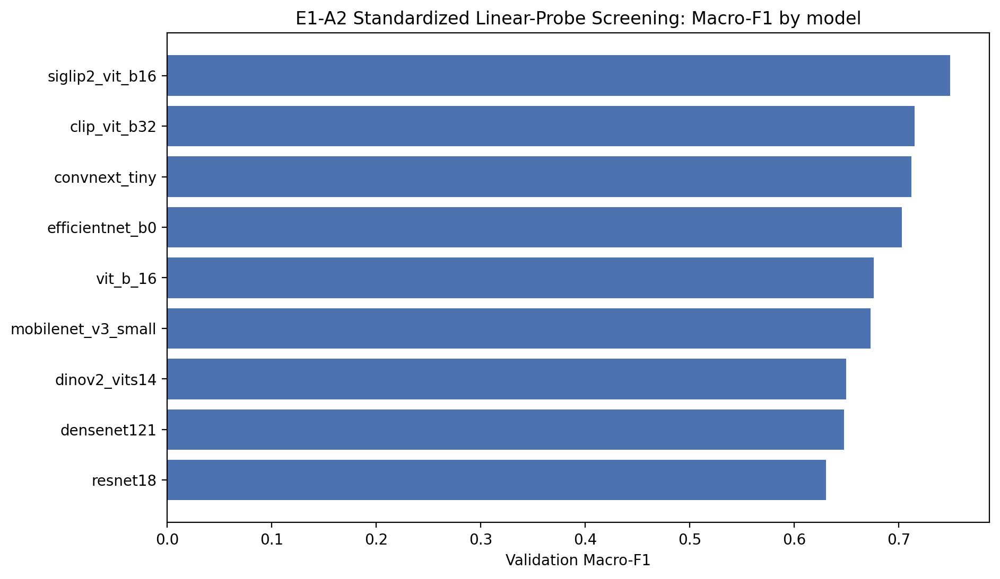


12. FINAL T0 INTEGRITY CHECK
Expected : 4631ce8bddde64755ba44758827310703f1b332bcb28f72b55f22b3b19b92c9d
Final    : 4631ce8bddde64755ba44758827310703f1b332bcb28f72b55f22b3b19b92c9d

✓ Frozen T0 remained unchanged.


####################################################################################################
#                              E1-A2 RUN FINISHED
####################################################################################################

Git commit:
a3affe71c1838dc1e0c2b0a606dfbac08c41470c

Frozen T0 SHA:
4631ce8bddde64755ba44758827310703f1b332bcb28f72b55f22b3b19b92c9d

Dataset:
/content/drive/MyDrive/Masters/Datasets/Combined_Drawing

Permanent results:
/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1A

Completed models: 9 / 9

✓ No model was recorded as failed.

Test set:
LOCKED — NOT USED FOR E1-A2 ARCHITECTURE SELECTION

Primary selection metric:
VALIDATION MACRO-F1

###################################################################################

In [ ]:
# ==================================================================================================
# DOAR MASTER THESIS — E1-A2 COMPLETE GOOGLE COLAB GPU RUNNER
# Frozen T0 verification + exact Git checkpoint + GPU + 9-model E1-A2 screening
# Resumable + Google Drive persistence + final tables/figures/ranking
# ==================================================================================================

from google.colab import drive
drive.mount("/content/drive", force_remount=False)

from pathlib import Path
import subprocess
import sys
import os
import shutil
import hashlib
import json
import time

# ==================================================================================================
# 0. CONFIGURATION
# ==================================================================================================

REPO_URL = "https://github.com/HHemaly/DOAR.git"
REPO_DIR = Path("/content/DOAR")

GIT_REF = "checkpoint/e1-gpu-ready-v1"
EXPECTED_COMMIT = "a3affe71c1838dc1e0c2b0a606dfbac08c41470c"

DATASET_ROOT = Path(
    "/content/drive/MyDrive/Masters/Datasets/Combined_Drawing"
)

OUTPUT_ROOT = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1A"
)

# This is the location visible in your screenshot.
SCREENSHOT_T0_MANIFEST = Path(
    "/content/drive/MyDrive/Masters/Datasets/DOAR_FROZEN_TO/final_partition/partition_manifest.csv"
)

EXPECTED_T0_SHA256 = (
    "4631ce8bddde64755ba44758827310703f1b332bcb28f72b55f22b3b19b92c9d"
)

EXPECTED_COUNTS = {
    "train": 2599,
    "valid": 284,
    "test": 512,
}

EXPECTED_MODELS = [
    "mobilenet_v3_small",
    "resnet18",
    "efficientnet_b0",
    "densenet121",
    "convnext_tiny",
    "vit_b_16",
    "clip_vit_b32",
    "dinov2_vits14",
    "siglip2_vit_b16",
]

SEED = 42
MAX_EPOCHS = 30
PATIENCE = 5

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print("=" * 100)
print("DOAR E1-A2 — COMPLETE MASTER THESIS GPU EXPERIMENT")
print("=" * 100)
print("Dataset       :", DATASET_ROOT)
print("Results       :", OUTPUT_ROOT)
print("Git ref       :", GIT_REF)
print("Expected SHA  :", EXPECTED_T0_SHA256)
print("Models        :", len(EXPECTED_MODELS))
print("=" * 100)


# ==================================================================================================
# 1. HELPERS
# ==================================================================================================

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


def run_command(cmd, cwd=None):
    print("\n>>>", " ".join(str(x) for x in cmd))
    subprocess.run(
        [str(x) for x in cmd],
        cwd=str(cwd) if cwd else None,
        check=True,
    )


def locate_frozen_manifest():
    print("\n" + "=" * 100)
    print("1. LOCATING EXACT FROZEN T0 MANIFEST")
    print("=" * 100)

    # First: location shown in screenshot
    if SCREENSHOT_T0_MANIFEST.exists():
        actual_sha = sha256_file(SCREENSHOT_T0_MANIFEST)
        print("Found screenshot-path manifest:")
        print(SCREENSHOT_T0_MANIFEST)
        print("SHA-256:", actual_sha)

        if actual_sha.lower() == EXPECTED_T0_SHA256.lower():
            print("\n✓ EXACT FROZEN T0 MANIFEST FOUND AT SCREENSHOT LOCATION")
            return SCREENSHOT_T0_MANIFEST
        else:
            print("⚠ File exists there, but SHA does not match frozen T0.")

    # Search all Masters recursively.
    # This also handles DOAR_FROZEN_T0 vs DOAR_FROZEN_TO naming differences.
    search_root = Path("/content/drive/MyDrive/Masters")

    print("\nSearching all of:")
    print(search_root)
    print("for partition_manifest.csv with the EXACT frozen SHA...\n")

    candidates = list(search_root.rglob("partition_manifest.csv"))

    if not candidates:
        raise FileNotFoundError(
            "No partition_manifest.csv was found anywhere under MyDrive/Masters."
        )

    for candidate in candidates:
        try:
            candidate_sha = sha256_file(candidate)
            print("Candidate:")
            print(" ", candidate)
            print("  SHA:", candidate_sha)

            if candidate_sha.lower() == EXPECTED_T0_SHA256.lower():
                print("\n✓ EXACT FROZEN T0 MANIFEST FOUND")
                print(candidate)
                return candidate

        except Exception as exc:
            print("Could not read:", candidate, exc)

    raise RuntimeError(
        "\nA partition_manifest.csv was found, but NONE matched the frozen SHA.\n"
        f"Required SHA: {EXPECTED_T0_SHA256}\n"
        "Training has intentionally been stopped."
    )


# ==================================================================================================
# 2. VERIFY IMAGE DATASET
# ==================================================================================================

print("\n" + "=" * 100)
print("2. VERIFYING IMAGE DATASET")
print("=" * 100)

if not DATASET_ROOT.exists():
    raise FileNotFoundError(
        f"Dataset root does not exist:\n{DATASET_ROOT}"
    )

for split in ["train", "valid", "test"]:
    p = DATASET_ROOT / split
    print(f"{split:5s}: {p.exists()} -> {p}")
    if not p.exists():
        raise FileNotFoundError(
            f"Required dataset split missing: {p}"
        )

print("\n✓ Dataset train/valid/test folders found.")


# ==================================================================================================
# 3. LOCATE + VERIFY FROZEN T0
# ==================================================================================================

T0_SOURCE_MANIFEST = locate_frozen_manifest()

SOURCE_SHA = sha256_file(T0_SOURCE_MANIFEST)

if SOURCE_SHA.lower() != EXPECTED_T0_SHA256.lower():
    raise RuntimeError("Frozen T0 SHA verification failed.")

print("\nFrozen manifest being used:")
print(T0_SOURCE_MANIFEST)
print("SHA-256:")
print(SOURCE_SHA)


# ==================================================================================================
# 4. CLONE EXACT SCIENTIFIC CHECKPOINT
# ==================================================================================================

print("\n" + "=" * 100)
print("3. PREPARING EXACT GITHUB CHECKPOINT")
print("=" * 100)

# /content is temporary. Removing this does NOT delete Drive experiment results.
if REPO_DIR.exists():
    print("Removing previous temporary Colab clone...")
    shutil.rmtree(REPO_DIR)

run_command([
    "git",
    "clone",
    REPO_URL,
    str(REPO_DIR),
])

run_command([
    "git",
    "fetch",
    "--all",
    "--tags",
], cwd=REPO_DIR)

run_command([
    "git",
    "checkout",
    GIT_REF,
], cwd=REPO_DIR)

ACTUAL_COMMIT = subprocess.check_output(
    ["git", "rev-parse", "HEAD"],
    cwd=str(REPO_DIR),
    text=True,
).strip()

print("\nGit HEAD:")
print(ACTUAL_COMMIT)

if ACTUAL_COMMIT != EXPECTED_COMMIT:
    raise RuntimeError(
        "\nWRONG REPOSITORY COMMIT.\n"
        f"Expected: {EXPECTED_COMMIT}\n"
        f"Actual:   {ACTUAL_COMMIT}\n"
        "Refusing to run a different scientific implementation."
    )

print("\n✓ Exact E1 GPU-ready checkpoint verified.")


# ==================================================================================================
# 5. RESTORE FROZEN T0 INTO REPOSITORY
# ==================================================================================================

print("\n" + "=" * 100)
print("4. RESTORING FROZEN T0 MANIFEST INTO CLONED CHECKPOINT")
print("=" * 100)

T0_REPO_MANIFEST = (
    REPO_DIR
    / "outputs"
    / "t0_automated"
    / "final_partition"
    / "partition_manifest.csv"
)

T0_REPO_MANIFEST.parent.mkdir(
    parents=True,
    exist_ok=True,
)

shutil.copy2(
    T0_SOURCE_MANIFEST,
    T0_REPO_MANIFEST,
)

RESTORED_SHA = sha256_file(T0_REPO_MANIFEST)

print("Source:")
print(T0_SOURCE_MANIFEST)

print("\nRestored to:")
print(T0_REPO_MANIFEST)

print("\nRestored SHA-256:")
print(RESTORED_SHA)

if RESTORED_SHA.lower() != EXPECTED_T0_SHA256.lower():
    raise RuntimeError(
        "Restored manifest is not byte-identical to frozen T0."
    )

print("\n✓ Frozen T0 restored and byte-identical.")


# ==================================================================================================
# 6. INSTALL E1 DEPENDENCIES
# ==================================================================================================

print("\n" + "=" * 100)
print("5. INSTALLING E1 DEPENDENCIES")
print("=" * 100)

REQUIREMENTS = (
    REPO_DIR
    / "experiments"
    / "E1_visual_representation"
    / "requirements-e1.txt"
)

if not REQUIREMENTS.exists():
    raise FileNotFoundError(
        f"E1 requirements file missing: {REQUIREMENTS}"
    )

run_command([
    sys.executable,
    "-m",
    "pip",
    "install",
    "-q",
    "--upgrade-strategy",
    "only-if-needed",
    "-r",
    REQUIREMENTS,
])

print("\n✓ E1 dependencies installed.")


# ==================================================================================================
# 7. GPU VERIFICATION
# ==================================================================================================

print("\n" + "=" * 100)
print("6. VERIFYING GPU")
print("=" * 100)

import torch

print("PyTorch version :", torch.__version__)
print("CUDA available  :", torch.cuda.is_available())
print("CUDA version    :", torch.version.cuda)

if not torch.cuda.is_available():
    raise RuntimeError(
        "\nNO CUDA GPU DETECTED.\n"
        "In Colab choose:\n"
        "Runtime -> Change runtime type -> GPU\n"
        "Then rerun this cell."
    )

GPU_NAME = torch.cuda.get_device_name(0)
GPU_VRAM_GB = (
    torch.cuda.get_device_properties(0).total_memory
    / (1024 ** 3)
)

print("GPU             :", GPU_NAME)
print("VRAM            :", round(GPU_VRAM_GB, 2), "GB")

print("\n✓ GPU ready.")


# ==================================================================================================
# 8. RUN OFFICIAL FROZEN T0 VERIFIER
# ==================================================================================================

print("\n" + "=" * 100)
print("7. VERIFYING FROZEN T0 AGAINST GOOGLE DRIVE DATASET")
print("=" * 100)

PREPARE_SCRIPT = (
    REPO_DIR
    / "experiments"
    / "E1_visual_representation"
    / "scripts"
    / "prepare_e1_dataset.py"
)

VERIFICATION_REPORT = (
    OUTPUT_ROOT
    / "T0_COLAB_VERIFICATION.json"
)

run_command([
    sys.executable,
    PREPARE_SCRIPT,
    "--dataset-root",
    DATASET_ROOT,
    "--verify-only",
    "--output",
    VERIFICATION_REPORT,
], cwd=REPO_DIR)

if not VERIFICATION_REPORT.exists():
    raise RuntimeError(
        "T0 verification report was not generated."
    )

with open(VERIFICATION_REPORT, "r", encoding="utf-8") as f:
    verification = json.load(f)

print("\nVerification summary:")
print("manifest_sha256_ok :", verification.get("manifest_sha256_ok"))
print("train              :", verification.get("n_train"))
print("valid              :", verification.get("n_valid"))
print("test               :", verification.get("n_test"))
print("missing train      :", len(verification.get("missing_train", [])))
print("missing valid      :", len(verification.get("missing_valid", [])))
print("overall OK         :", verification.get("ok"))

if verification.get("manifest_sha256") != EXPECTED_T0_SHA256:
    raise RuntimeError("Manifest SHA drift detected.")

if verification.get("n_train") != EXPECTED_COUNTS["train"]:
    raise RuntimeError("Train count does not match frozen T0.")

if verification.get("n_valid") != EXPECTED_COUNTS["valid"]:
    raise RuntimeError("Validation count does not match frozen T0.")

if verification.get("n_test") != EXPECTED_COUNTS["test"]:
    raise RuntimeError("Test count does not match frozen T0.")

if verification.get("missing_train"):
    raise RuntimeError(
        f"{len(verification['missing_train'])} training files are missing."
    )

if verification.get("missing_valid"):
    raise RuntimeError(
        f"{len(verification['missing_valid'])} validation files are missing."
    )

if not verification.get("ok"):
    raise RuntimeError(
        "T0 verification failed. Training will not start."
    )

print("\n" + "=" * 100)
print("✓ FROZEN T0 SCIENTIFIC PARTITION VERIFIED")
print("✓ TRAIN = 2599")
print("✓ VALID = 284")
print("✓ TEST  = 512 — LOCKED AND UNUSED DURING E1-A2")
print("=" * 100)


# ==================================================================================================
# 9. SAVE COLAB ENVIRONMENT / PROVENANCE
# ==================================================================================================

environment_record = {
    "experiment": "E1-A2 standardized frozen linear-probe screening",
    "timestamp_utc": time.strftime(
        "%Y-%m-%dT%H:%M:%SZ",
        time.gmtime()
    ),
    "repository": REPO_URL,
    "git_ref": GIT_REF,
    "git_commit": ACTUAL_COMMIT,
    "dataset_root": str(DATASET_ROOT),
    "output_root": str(OUTPUT_ROOT),
    "t0_source_manifest": str(T0_SOURCE_MANIFEST),
    "t0_manifest_sha256": SOURCE_SHA,
    "train_count": EXPECTED_COUNTS["train"],
    "valid_count": EXPECTED_COUNTS["valid"],
    "test_count_locked": EXPECTED_COUNTS["test"],
    "seed": SEED,
    "max_epochs": MAX_EPOCHS,
    "early_stopping_patience": PATIENCE,
    "selection_metric": "validation Macro-F1",
    "gpu": GPU_NAME,
    "gpu_vram_gb": round(GPU_VRAM_GB, 2),
    "pytorch": torch.__version__,
    "cuda": torch.version.cuda,
    "models": EXPECTED_MODELS,
}

with open(
    OUTPUT_ROOT / "COLAB_ENVIRONMENT.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        environment_record,
        f,
        indent=2,
    )

print("\n✓ Experimental provenance saved to:")
print(OUTPUT_ROOT / "COLAB_ENVIRONMENT.json")


# ==================================================================================================
# 10. START THE REAL E1-A2 EXPERIMENT
# ==================================================================================================

RUN_SCRIPT = (
    REPO_DIR
    / "experiments"
    / "E1_visual_representation"
    / "scripts"
    / "run_e1a_all.py"
)

if not RUN_SCRIPT.exists():
    raise FileNotFoundError(
        f"E1-A2 runner missing: {RUN_SCRIPT}"
    )

print("\n")
print("#" * 100)
print("#")
print("#                       STARTING FULL E1-A2 GPU SCREENING")
print("#")
print("#  9 REPRESENTATION MODELS")
print("#  TRAIN: 2599")
print("#  VALID: 284")
print("#  TEST: LOCKED")
print("#  MAX EPOCHS: 30")
print("#  EARLY STOPPING PATIENCE: 5")
print("#  PRIMARY METRIC: VALIDATION MACRO-F1")
print("#  RESUME ENABLED")
print("#")
print("#" * 100)

for i, model in enumerate(EXPECTED_MODELS, start=1):
    print(f"{i}. {model}")

print("\nResults are being written DIRECTLY to Google Drive:")
print(OUTPUT_ROOT)

print(
    "\nIf Colab disconnects, run THIS SAME CELL again. "
    "--resume will reuse completed experiments/checkpoints."
)

# Make Python logs appear immediately
os.environ["PYTHONUNBUFFERED"] = "1"

RUN_CMD = [
    sys.executable,
    "-u",
    str(RUN_SCRIPT),
    "--dataset-root",
    str(DATASET_ROOT),
    "--output-root",
    str(OUTPUT_ROOT),
    "--device",
    "cuda",
    "--seed",
    str(SEED),
    "--max-epochs",
    str(MAX_EPOCHS),
    "--patience",
    str(PATIENCE),
    "--resume",
]

print("\nACTUAL TRAINING COMMAND:")
print(" ".join(RUN_CMD))
print("\n" + "=" * 100)
print("TRAINING HAS NOW STARTED")
print("=" * 100 + "\n")

# THIS IS THE LINE THAT ACTUALLY EXECUTES THE FULL EXPERIMENT
subprocess.run(
    RUN_CMD,
    cwd=str(REPO_DIR),
    check=True,
)


# ==================================================================================================
# 11. CHECK MODEL COMPLETION STATUS
# ==================================================================================================

print("\n" + "=" * 100)
print("8. CHECKING E1-A2 MODEL STATUS")
print("=" * 100)

RUN_MANIFEST = OUTPUT_ROOT / "RUN_MANIFEST.json"

if not RUN_MANIFEST.exists():
    raise RuntimeError(
        "RUN_MANIFEST.json was not produced."
    )

with open(RUN_MANIFEST, "r", encoding="utf-8") as f:
    run_manifest = json.load(f)

statuses = run_manifest.get("models", {})

trained = []
failed = []
other = []

for model in EXPECTED_MODELS:
    entry = statuses.get(model, {})
    status = entry.get("status", "not_run")

    if status == "trained":
        trained.append(model)
        print(
            f"✓ {model:22s} "
            f"Macro-F1={entry.get('best_valid_macro_f1')} "
            f"Best epoch={entry.get('best_epoch')}"
        )
    elif status == "failed":
        failed.append(model)
        print(
            f"✗ {model:22s} FAILED: "
            f"{entry.get('error', 'unknown error')}"
        )
    else:
        other.append(model)
        print(
            f"? {model:22s} status={status}"
        )

print("\nCompleted :", len(trained), "/", len(EXPECTED_MODELS))
print("Failed    :", len(failed))
print("Other     :", len(other))


# ==================================================================================================
# 12. COPY TABLES + FIGURES FROM TEMP REPOSITORY TO PERMANENT DRIVE
# ==================================================================================================

print("\n" + "=" * 100)
print("9. SAVING TABLES / FIGURES PERMANENTLY TO GOOGLE DRIVE")
print("=" * 100)

EXP_DIR = (
    REPO_DIR
    / "experiments"
    / "E1_visual_representation"
)

REPORTS_ROOT = OUTPUT_ROOT / "REPORTS"
REPORTS_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

for folder_name in [
    "tables",
    "figures",
    "thesis",
]:
    source = EXP_DIR / folder_name
    destination = REPORTS_ROOT / folder_name

    if source.exists():
        shutil.copytree(
            source,
            destination,
            dirs_exist_ok=True,
        )
        print(
            f"✓ Saved {folder_name}:",
            destination,
        )

# Also preserve protocol/readme for thesis provenance
for filename in [
    "PROTOCOL.md",
    "README.md",
]:
    source = EXP_DIR / filename
    if source.exists():
        shutil.copy2(
            source,
            REPORTS_ROOT / filename,
        )

print("\n✓ Thesis evidence copied to:")
print(REPORTS_ROOT)


# ==================================================================================================
# 13. DISPLAY FINAL MODEL COMPARISON TABLE
# ==================================================================================================

print("\n" + "=" * 100)
print("10. FINAL E1-A2 MODEL COMPARISON")
print("=" * 100)

import pandas as pd
from IPython.display import display, Image as IPImage

TABLE_T2 = (
    REPORTS_ROOT
    / "tables"
    / "E1A_T2_standardized_linear_probe.csv"
)

if TABLE_T2.exists():
    df = pd.read_csv(TABLE_T2)

    if (
        "status" in df.columns
        and "val_macro_f1" in df.columns
    ):
        ranking = (
            df[df["status"] == "ok"]
            .sort_values(
                "val_macro_f1",
                ascending=False,
            )
            .reset_index(drop=True)
        )

        ranking.insert(
            0,
            "rank",
            range(1, len(ranking) + 1),
        )

        print("\nFINAL VALIDATION MACRO-F1 RANKING:\n")
        display(ranking)

        ranking.to_csv(
            OUTPUT_ROOT / "FINAL_E1A_MODEL_RANKING.csv",
            index=False,
        )

        print("\n✓ Ranking saved:")
        print(
            OUTPUT_ROOT
            / "FINAL_E1A_MODEL_RANKING.csv"
        )

else:
    print(
        "E1A_T2 table not found. "
        "Raw model results remain saved in Drive."
    )


# ==================================================================================================
# 14. SHOW IMPORTANT GENERATED FIGURES
# ==================================================================================================

FIGURES_DIR = REPORTS_ROOT / "figures"

important_figures = [
    "E1A_F1_macro_f1_comparison.png",
    "E1A_F2_per_class_f1.png",
    "E1A_F3_macro_f1_vs_latency.png",
    "E1A_F4_learning_curves.png",
    "E1A_F5_train_vs_validation_loss.png",
    "E1A_F6_best_epoch_by_model.png",
]

print("\n" + "=" * 100)
print("11. GENERATED THESIS FIGURES")
print("=" * 100)

for name in important_figures:
    p = FIGURES_DIR / name

    if p.exists():
        print("✓", name)
    else:
        print("—", name, "(not generated)")

# Display the primary comparison figure
PRIMARY_FIGURE = (
    FIGURES_DIR
    / "E1A_F1_macro_f1_comparison.png"
)

if PRIMARY_FIGURE.exists():
    print("\nPRIMARY E1-A2 RESULT:\n")
    display(
        IPImage(
            filename=str(PRIMARY_FIGURE)
        )
    )


# ==================================================================================================
# 15. FINAL SCIENTIFIC INTEGRITY CHECK
# ==================================================================================================

print("\n" + "=" * 100)
print("12. FINAL T0 INTEGRITY CHECK")
print("=" * 100)

FINAL_T0_SHA = sha256_file(
    T0_REPO_MANIFEST
)

print("Expected :", EXPECTED_T0_SHA256)
print("Final    :", FINAL_T0_SHA)

if FINAL_T0_SHA.lower() != EXPECTED_T0_SHA256.lower():
    raise RuntimeError(
        "CRITICAL: frozen T0 manifest changed during experiment."
    )

print("\n✓ Frozen T0 remained unchanged.")


# ==================================================================================================
# 16. FINAL SUMMARY
# ==================================================================================================

print("\n")
print("#" * 100)
print("#                              E1-A2 RUN FINISHED")
print("#" * 100)
print()
print("Git commit:")
print(ACTUAL_COMMIT)
print()
print("Frozen T0 SHA:")
print(FINAL_T0_SHA)
print()
print("Dataset:")
print(DATASET_ROOT)
print()
print("Permanent results:")
print(OUTPUT_ROOT)
print()
print("Completed models:", len(trained), "/", len(EXPECTED_MODELS))

if failed:
    print()
    print("FAILED MODELS:")
    for model in failed:
        print(" -", model)
    print()
    print(
        "The successful models are already saved. "
        "Run the SAME cell again to retry failed models."
    )
else:
    print()
    print("✓ No model was recorded as failed.")

print()
print("Test set:")
print("LOCKED — NOT USED FOR E1-A2 ARCHITECTURE SELECTION")
print()
print("Primary selection metric:")
print("VALIDATION MACRO-F1")
print()
print("#" * 100)

In [ ]:
# ==================================================================================================
# DOAR MASTER THESIS
# E1-A2R — MULTI-SEED FROZEN REPRESENTATION STABILITY EXPERIMENT
#
# PURPOSE
# -------
# Confirm whether the E1-A2 representation ranking is stable across
# repeated linear-probe training runs with different random seeds.
#
# IMPORTANT
# ---------
# - Reuses the already extracted E1-A2 TRAIN + VALID embeddings.
# - Does NOT re-run the expensive encoders.
# - Does NOT load, embed, predict, or evaluate the locked Test set.
# - Uses the SAME classifier/training methodology as E1-A2.
# - Runs ALL 9 models because linear-probe repetition is cheap.
#
# SOURCE E1-A2:
# Git commit:
# a3affe71c1838dc1e0c2b0a606dfbac08c41470c
#
# Frozen T0 SHA:
# 4631ce8bddde64755ba44758827310703f1b332bcb28f72b55f22b3b19b92c9d
# ==================================================================================================

from google.colab import drive
drive.mount("/content/drive")

import json
import hashlib
import random
import time
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    f1_score,
)

from torch.utils.data import DataLoader, TensorDataset


# ==================================================================================================
# 1. CONFIGURATION
# ==================================================================================================

SOURCE_ROOT = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1A"
)

OUT_ROOT = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1A2R"
)

EXPECTED_T0_SHA = (
    "4631ce8bddde64755ba44758827310703f1b332bcb28f72b55f22b3b19b92c9d"
)

EXPECTED_COMMIT = (
    "a3affe71c1838dc1e0c2b0a606dfbac08c41470c"
)

MODELS = [
    "mobilenet_v3_small",
    "resnet18",
    "efficientnet_b0",
    "densenet121",
    "convnext_tiny",
    "vit_b_16",
    "clip_vit_b32",
    "dinov2_vits14",
    "siglip2_vit_b16",
]

# These four were the strongest E1-A2 models.
# They receive additional pairwise stability analysis.
TOP4 = [
    "siglip2_vit_b16",
    "clip_vit_b32",
    "convnext_tiny",
    "efficientnet_b0",
]

CLASSES = [
    "Angry",
    "Fear",
    "Happy",
    "Sad",
]

# 10 pre-declared random seeds.
# Seed 42 is included so that we can reproduce the original E1-A2 result.
SEEDS = [
    7,
    19,
    31,
    42,
    53,
    67,
    73,
    89,
    101,
    131,
]

# Same linear-probe training policy as E1-A2.
MAX_EPOCHS = 30
PATIENCE = 5
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.05
BATCH_SIZE = 64

# Bootstrap repetitions for uncertainty across seeds.
N_BOOTSTRAP = 10000


# ==================================================================================================
# 2. CREATE OUTPUT STRUCTURE
# ==================================================================================================

for directory in [
    OUT_ROOT,
    OUT_ROOT / "runs",
    OUT_ROOT / "tables",
    OUT_ROOT / "figures",
]:
    directory.mkdir(parents=True, exist_ok=True)

print("=" * 100)
print("DOAR E1-A2R — MULTI-SEED REPRESENTATION STABILITY")
print("=" * 100)
print(f"Source E1-A2 : {SOURCE_ROOT}")
print(f"Output       : {OUT_ROOT}")
print(f"Models       : {len(MODELS)}")
print(f"Seeds        : {len(SEEDS)}")
print(f"Total runs   : {len(MODELS) * len(SEEDS)}")
print()


# ==================================================================================================
# 3. HELPER FUNCTIONS
# ==================================================================================================

def sha256_file(path, chunk_size=1024 * 1024):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def compute_class_weights(targets):

    counts = np.bincount(
        targets,
        minlength=len(CLASSES),
    ).astype(np.float64)

    return counts.sum() / (
        len(CLASSES) * np.clip(counts, 1, None)
    )


def bootstrap_mean_ci(
    values,
    n_boot=N_BOOTSTRAP,
    seed=20260823,
):

    values = np.asarray(values, dtype=float)

    if len(values) == 1:

        value = float(values[0])

        return value, value

    rng = np.random.default_rng(seed)

    indices = rng.integers(
        0,
        len(values),
        size=(n_boot, len(values)),
    )

    sampled_means = values[indices].mean(axis=1)

    low = np.percentile(sampled_means, 2.5)
    high = np.percentile(sampled_means, 97.5)

    return float(low), float(high)


def evaluate(
    model,
    loader,
    criterion,
    device,
):

    model.eval()

    total_loss = 0.0
    total_n = 0

    truth = []
    predictions = []
    probabilities = []

    with torch.no_grad():

        for x, y in loader:

            x = x.to(device)
            y = y.to(device)

            logits = model(x)

            loss = criterion(
                logits,
                y,
            )

            total_loss += (
                float(loss.detach()) * len(y)
            )

            total_n += len(y)

            truth.extend(
                y.cpu().tolist()
            )

            predictions.extend(
                logits.argmax(1).cpu().tolist()
            )

            probabilities.extend(
                torch.softmax(
                    logits,
                    dim=1,
                )
                .cpu()
                .tolist()
            )

    return (
        total_loss / max(1, total_n),
        np.asarray(truth),
        np.asarray(predictions),
        np.asarray(
            probabilities,
            dtype=np.float32,
        ),
    )


def train_linear_probe(
    model_key,
    seed,
    x_train,
    y_train,
    x_valid,
    y_valid,
    valid_ids,
    device,
):

    # ----------------------------------------------------------------------------------------------
    # CRITICAL:
    # Unlike the original E1-A2 runner bug where the internal seed remained fixed at 42,
    # this function genuinely uses the supplied seed.
    # ----------------------------------------------------------------------------------------------

    set_seed(seed)

    embedding_dimension = x_train.shape[1]

    head = torch.nn.Linear(
        embedding_dimension,
        len(CLASSES),
    ).to(device)

    train_dataset = TensorDataset(
        torch.tensor(
            x_train,
            dtype=torch.float32,
        ),
        torch.tensor(
            y_train,
            dtype=torch.long,
        ),
    )

    valid_dataset = TensorDataset(
        torch.tensor(
            x_valid,
            dtype=torch.float32,
        ),
        torch.tensor(
            y_valid,
            dtype=torch.long,
        ),
    )

    generator = (
        torch.Generator()
        .manual_seed(seed)
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
    )

    valid_loader = DataLoader(
        valid_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
    )

    class_weights = torch.tensor(
        compute_class_weights(y_train),
        dtype=torch.float32,
        device=device,
    )

    criterion = torch.nn.CrossEntropyLoss(
        weight=class_weights,
        label_smoothing=LABEL_SMOOTHING,
    )

    optimizer = torch.optim.AdamW(
        head.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )

    best_macro_f1 = -1.0
    best_epoch = -1

    stale_epochs = 0

    best_state = None
    best_result = None

    history = []

    total_started = time.perf_counter()

    for epoch in range(MAX_EPOCHS):

        epoch_started = time.perf_counter()

        # ------------------------------------------------------------------------------------------
        # TRAIN
        # ------------------------------------------------------------------------------------------

        head.train()

        train_loss = 0.0
        train_correct = 0
        train_n = 0

        for x, y in train_loader:

            x = x.to(device)
            y = y.to(device)

            optimizer.zero_grad(
                set_to_none=True
            )

            logits = head(x)

            loss = criterion(
                logits,
                y,
            )

            loss.backward()

            optimizer.step()

            train_loss += (
                float(loss.detach()) * len(y)
            )

            train_correct += int(
                (
                    logits.argmax(1) == y
                ).sum()
            )

            train_n += len(y)

        # ------------------------------------------------------------------------------------------
        # VALIDATION
        # ------------------------------------------------------------------------------------------

        (
            validation_loss,
            truth,
            prediction,
            probabilities,
        ) = evaluate(
            head,
            valid_loader,
            criterion,
            device,
        )

        macro_f1 = f1_score(
            truth,
            prediction,
            average="macro",
            zero_division=0,
        )

        validation_accuracy = accuracy_score(
            truth,
            prediction,
        )

        validation_balanced_accuracy = (
            balanced_accuracy_score(
                truth,
                prediction,
            )
        )

        is_new_best = (
            macro_f1 > best_macro_f1
        )

        history.append(
            {
                "model": model_key,
                "seed": seed,
                "epoch": epoch,
                "train_loss":
                    train_loss / max(1, train_n),
                "val_loss":
                    validation_loss,
                "train_accuracy":
                    train_correct / max(1, train_n),
                "val_accuracy":
                    validation_accuracy,
                "val_balanced_accuracy":
                    validation_balanced_accuracy,
                "val_macro_f1":
                    macro_f1,
                "runtime_seconds":
                    time.perf_counter()
                    - epoch_started,
                "is_new_best":
                    is_new_best,
            }
        )

        if is_new_best:

            best_macro_f1 = macro_f1
            best_epoch = epoch
            stale_epochs = 0

            best_state = {
                key:
                    value
                    .detach()
                    .cpu()
                    .clone()

                for key, value
                in head.state_dict().items()
            }

            best_result = (
                truth.copy(),
                prediction.copy(),
                probabilities.copy(),
            )

        else:

            stale_epochs += 1

            if stale_epochs >= PATIENCE:
                break

    total_training_seconds = (
        time.perf_counter()
        - total_started
    )

    (
        truth,
        prediction,
        probabilities,
    ) = best_result

    (
        precision,
        recall,
        class_f1,
        support,
    ) = precision_recall_fscore_support(
        truth,
        prediction,
        labels=list(
            range(
                len(CLASSES)
            )
        ),
        zero_division=0,
    )

    return {
        "best_macro_f1":
            best_macro_f1,

        "best_epoch":
            best_epoch,

        "epochs_completed":
            len(history),

        "training_seconds":
            total_training_seconds,

        "history":
            history,

        "truth":
            truth,

        "prediction":
            prediction,

        "probabilities":
            probabilities,

        "precision":
            precision,

        "recall":
            recall,

        "class_f1":
            class_f1,

        "support":
            support,

        "state":
            best_state,
    }


# ==================================================================================================
# 4. VERIFY ORIGINAL E1-A2 PROVENANCE
# ==================================================================================================

print("=" * 100)
print("VERIFYING ORIGINAL E1-A2")
print("=" * 100)

required_files = [
    SOURCE_ROOT / "COLAB_ENVIRONMENT.json",
    SOURCE_ROOT / "T0_COLAB_VERIFICATION.json",
    SOURCE_ROOT / "RUN_MANIFEST.json",
    SOURCE_ROOT / "FINAL_E1A_MODEL_RANKING.csv",
]

for path in required_files:

    assert path.exists(), (
        f"STOP: required E1-A2 file missing: {path}"
    )


environment = json.loads(
    (
        SOURCE_ROOT
        / "COLAB_ENVIRONMENT.json"
    ).read_text()
)

t0_verification = json.loads(
    (
        SOURCE_ROOT
        / "T0_COLAB_VERIFICATION.json"
    ).read_text()
)

run_manifest = json.loads(
    (
        SOURCE_ROOT
        / "RUN_MANIFEST.json"
    ).read_text()
)


assert (
    environment["git_commit"]
    == EXPECTED_COMMIT
), "STOP: E1-A2 git commit mismatch."


assert (
    environment["t0_manifest_sha256"]
    == EXPECTED_T0_SHA
), "STOP: T0 SHA mismatch."


assert (
    t0_verification["manifest_sha256"]
    == EXPECTED_T0_SHA
), "STOP: verification SHA mismatch."


assert (
    t0_verification["ok"]
    is True
), "STOP: original T0 verification was not OK."


assert (
    t0_verification["n_train"]
    == 2599
)

assert (
    t0_verification["n_valid"]
    == 284
)

assert (
    t0_verification["n_test"]
    == 512
)


for model in MODELS:

    status = (
        run_manifest
        ["models"]
        .get(model, {})
        .get("status")
    )

    assert (
        status == "trained"
    ), (
        f"STOP: {model} was not "
        "successfully trained in E1-A2."
    )


# ----------------------------------------------------------------------------------------------
# STRICT TEST-LOCK CHECK
# ----------------------------------------------------------------------------------------------

test_embedding_files = list(
    (
        SOURCE_ROOT
        / "embeddings"
    ).glob(
        "*/test.npz"
    )
)

assert (
    len(test_embedding_files)
    == 0
), (
    "STOP: A Test embedding file was detected. "
    "Do not continue until investigated."
)

print("✓ Original commit verified.")
print("✓ Frozen T0 SHA verified.")
print("✓ Train = 2599")
print("✓ Validation = 284")
print("✓ Locked Test = 512")
print("✓ All 9 E1-A2 models completed.")
print("✓ No Test embedding files detected.")
print()


# ==================================================================================================
# 5. LOAD + VERIFY TRAIN/VALID EMBEDDINGS
# ==================================================================================================

print("=" * 100)
print("VERIFYING SAVED E1-A2 EMBEDDINGS")
print("=" * 100)

class_to_index = {
    class_name: index

    for index, class_name
    in enumerate(CLASSES)
}


embedding_cache = {}

reference_train_ids = None
reference_valid_ids = None

reference_train_labels = None
reference_valid_labels = None

input_hash_rows = []


for model in MODELS:

    train_path = (
        SOURCE_ROOT
        / "embeddings"
        / model
        / "train.npz"
    )

    valid_path = (
        SOURCE_ROOT
        / "embeddings"
        / model
        / "valid.npz"
    )

    assert train_path.exists(), (
        f"Missing TRAIN embedding: {model}"
    )

    assert valid_path.exists(), (
        f"Missing VALID embedding: {model}"
    )


    train_data = np.load(
        train_path,
        allow_pickle=False,
    )

    valid_data = np.load(
        valid_path,
        allow_pickle=False,
    )


    x_train = train_data[
        "embeddings"
    ].astype(
        np.float32,
        copy=False,
    )

    x_valid = valid_data[
        "embeddings"
    ].astype(
        np.float32,
        copy=False,
    )


    train_ids = train_data[
        "image_ids"
    ].astype(str)

    valid_ids = valid_data[
        "image_ids"
    ].astype(str)


    train_labels = train_data[
        "labels"
    ].astype(str)

    valid_labels = valid_data[
        "labels"
    ].astype(str)


    assert x_train.shape[0] == 2599
    assert x_valid.shape[0] == 284

    assert len(set(train_ids)) == 2599
    assert len(set(valid_ids)) == 284

    assert set(train_ids).isdisjoint(
        set(valid_ids)
    )

    assert np.isfinite(
        x_train
    ).all()

    assert np.isfinite(
        x_valid
    ).all()


    # Ensure every representation contains the EXACT SAME images
    # in the same order with the same labels.

    if reference_train_ids is None:

        reference_train_ids = train_ids
        reference_valid_ids = valid_ids

        reference_train_labels = train_labels
        reference_valid_labels = valid_labels

    else:

        assert np.array_equal(
            train_ids,
            reference_train_ids,
        )

        assert np.array_equal(
            valid_ids,
            reference_valid_ids,
        )

        assert np.array_equal(
            train_labels,
            reference_train_labels,
        )

        assert np.array_equal(
            valid_labels,
            reference_valid_labels,
        )


    y_train = np.asarray(
        [
            class_to_index[label]

            for label
            in train_labels
        ],
        dtype=np.int64,
    )

    y_valid = np.asarray(
        [
            class_to_index[label]

            for label
            in valid_labels
        ],
        dtype=np.int64,
    )


    embedding_cache[model] = (
        x_train,
        y_train,
        x_valid,
        y_valid,
        valid_ids,
    )


    input_hash_rows.append(
        {
            "model":
                model,

            "train_npz_sha256":
                sha256_file(
                    train_path
                ),

            "valid_npz_sha256":
                sha256_file(
                    valid_path
                ),

            "embedding_dimension":
                x_train.shape[1],
        }
    )


    print(
        f"✓ {model:<24} "
        f"Train={x_train.shape} "
        f"Valid={x_valid.shape}"
    )


pd.DataFrame(
    input_hash_rows
).to_csv(
    OUT_ROOT
    / "tables"
    / "E1A2R_T0_input_embedding_hashes.csv",
    index=False,
)


print()
print("✓ All model embeddings contain identical Train/Validation images.")
print("✓ Train/Validation overlap = 0.")
print("✓ No NaN/Inf embeddings detected.")
print()


# ==================================================================================================
# 6. SAVE EXPERIMENT PROVENANCE
# ==================================================================================================

device = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


provenance = {

    "experiment":
        "E1-A2R Multi-seed Frozen Linear-Probe Stability",

    "source_experiment":
        "E1-A2",

    "source_root":
        str(SOURCE_ROOT),

    "source_git_commit":
        EXPECTED_COMMIT,

    "t0_manifest_sha256":
        EXPECTED_T0_SHA,

    "train_count":
        2599,

    "validation_count":
        284,

    "test_count_locked":
        512,

    "test_policy":
        "NOT LOADED, NOT EMBEDDED, NOT PREDICTED, NOT EVALUATED",

    "models":
        MODELS,

    "seeds":
        SEEDS,

    "max_epochs":
        MAX_EPOCHS,

    "patience":
        PATIENCE,

    "learning_rate":
        LEARNING_RATE,

    "weight_decay":
        WEIGHT_DECAY,

    "label_smoothing":
        LABEL_SMOOTHING,

    "batch_size":
        BATCH_SIZE,

    "device":
        device,

    "torch_version":
        torch.__version__,

}


(
    OUT_ROOT
    / "E1A2R_PROVENANCE.json"
).write_text(
    json.dumps(
        provenance,
        indent=2,
    )
)


print("=" * 100)
print("STARTING E1-A2R")
print("=" * 100)

print(f"Device      : {device}")
print(f"Models      : {len(MODELS)}")
print(f"Seeds/model : {len(SEEDS)}")
print(
    f"Total runs  : "
    f"{len(MODELS) * len(SEEDS)}"
)
print()


# ==================================================================================================
# 7. RUN THE EXPERIMENT
# ==================================================================================================

run_rows = []
class_rows = []
history_rows = []


for model_index, model in enumerate(
    MODELS,
    start=1,
):

    (
        x_train,
        y_train,
        x_valid,
        y_valid,
        valid_ids,
    ) = embedding_cache[model]


    for seed_index, seed in enumerate(
        SEEDS,
        start=1,
    ):

        print(
            f"[{model_index}/{len(MODELS)}] "
            f"{model:<24} "
            f"seed={seed:<3} "
            f"({seed_index}/{len(SEEDS)}) ... ",
            end="",
        )


        result = train_linear_probe(
            model,
            seed,
            x_train,
            y_train,
            x_valid,
            y_valid,
            valid_ids,
            device,
        )


        run_dir = (
            OUT_ROOT
            / "runs"
            / model
            / f"seed_{seed}"
        )

        run_dir.mkdir(
            parents=True,
            exist_ok=True,
        )


        # ------------------------------------------------------------------------------------------
        # SAVE BEST LINEAR HEAD
        # ------------------------------------------------------------------------------------------

        torch.save(
            {
                "model_state":
                    result["state"],

                "model":
                    model,

                "seed":
                    seed,

                "embedding_dimension":
                    x_train.shape[1],

                "val_macro_f1":
                    result[
                        "best_macro_f1"
                    ],

                "best_epoch":
                    result[
                        "best_epoch"
                    ],
            },
            run_dir / "best.pt",
        )


        # ------------------------------------------------------------------------------------------
        # SAVE VALIDATION PREDICTIONS
        # ------------------------------------------------------------------------------------------

        prediction_df = pd.DataFrame(
            {
                "image_id":
                    valid_ids,

                "true_class":
                    [
                        CLASSES[index]

                        for index
                        in result["truth"]
                    ],

                "predicted_class":
                    [
                        CLASSES[index]

                        for index
                        in result[
                            "prediction"
                        ]
                    ],
            }
        )


        for class_index, class_name in enumerate(
            CLASSES
        ):

            prediction_df[
                f"prob_{class_name}"
            ] = result[
                "probabilities"
            ][:, class_index]


        prediction_df.to_csv(
            run_dir
            / "best_valid_predictions.csv",
            index=False,
        )


        # ------------------------------------------------------------------------------------------
        # SAVE EPOCH HISTORY
        # ------------------------------------------------------------------------------------------

        pd.DataFrame(
            result["history"]
        ).to_csv(
            run_dir
            / "epoch_history.csv",
            index=False,
        )


        # ------------------------------------------------------------------------------------------
        # RUN-LEVEL RESULT
        # ------------------------------------------------------------------------------------------

        run_row = {

            "model":
                model,

            "seed":
                seed,

            "best_epoch":
                result[
                    "best_epoch"
                ],

            "epochs_completed":
                result[
                    "epochs_completed"
                ],

            "val_macro_f1":
                result[
                    "best_macro_f1"
                ],

            "val_accuracy":
                accuracy_score(
                    result["truth"],
                    result[
                        "prediction"
                    ],
                ),

            "val_balanced_accuracy":
                balanced_accuracy_score(
                    result["truth"],
                    result[
                        "prediction"
                    ],
                ),

            "training_seconds":
                result[
                    "training_seconds"
                ],
        }


        for class_index, class_name in enumerate(
            CLASSES
        ):

            run_row[
                f"f1_{class_name}"
            ] = result[
                "class_f1"
            ][class_index]


        run_rows.append(
            run_row
        )


        history_rows.extend(
            result["history"]
        )


        # ------------------------------------------------------------------------------------------
        # CLASS-LEVEL RESULTS
        # ------------------------------------------------------------------------------------------

        for class_index, class_name in enumerate(
            CLASSES
        ):

            class_rows.append(
                {

                    "model":
                        model,

                    "seed":
                        seed,

                    "class":
                        class_name,

                    "precision":
                        result[
                            "precision"
                        ][class_index],

                    "recall":
                        result[
                            "recall"
                        ][class_index],

                    "f1":
                        result[
                            "class_f1"
                        ][class_index],

                    "support":
                        int(
                            result[
                                "support"
                            ][class_index]
                        ),
                }
            )


        print(
            f"Macro-F1="
            f"{result['best_macro_f1']:.4f} "
            f"best_epoch="
            f"{result['best_epoch']}"
        )


# ==================================================================================================
# 8. BUILD RUN-LEVEL TABLE
# ==================================================================================================

runs = pd.DataFrame(
    run_rows
)


runs[
    "rank_within_seed"
] = (
    runs
    .groupby("seed")[
        "val_macro_f1"
    ]
    .rank(
        method="min",
        ascending=False,
    )
    .astype(int)
)


runs.to_csv(
    OUT_ROOT
    / "tables"
    / "E1A2R_T1_run_level_metrics.csv",
    index=False,
)


pd.DataFrame(
    class_rows
).to_csv(
    OUT_ROOT
    / "tables"
    / "E1A2R_T3_per_class_runs.csv",
    index=False,
)


pd.DataFrame(
    history_rows
).to_csv(
    OUT_ROOT
    / "tables"
    / "E1A2R_T5_epoch_history.csv",
    index=False,
)


# ==================================================================================================
# 9. MODEL STABILITY SUMMARY
# ==================================================================================================

summary_rows = []


for model, group in runs.groupby(
    "model"
):

    ci_low, ci_high = (
        bootstrap_mean_ci(
            group[
                "val_macro_f1"
            ].values
        )
    )


    summary_rows.append(
        {

            "model":
                model,

            "n_seeds":
                len(group),

            "mean_macro_f1":
                group[
                    "val_macro_f1"
                ].mean(),

            "std_macro_f1":
                group[
                    "val_macro_f1"
                ].std(ddof=1),

            "median_macro_f1":
                group[
                    "val_macro_f1"
                ].median(),

            "min_macro_f1":
                group[
                    "val_macro_f1"
                ].min(),

            "max_macro_f1":
                group[
                    "val_macro_f1"
                ].max(),

            "mean_macro_f1_ci95_low":
                ci_low,

            "mean_macro_f1_ci95_high":
                ci_high,

            "mean_accuracy":
                group[
                    "val_accuracy"
                ].mean(),

            "mean_balanced_accuracy":
                group[
                    "val_balanced_accuracy"
                ].mean(),

            "mean_rank":
                group[
                    "rank_within_seed"
                ].mean(),

            "rank1_count":
                int(
                    (
                        group[
                            "rank_within_seed"
                        ] == 1
                    ).sum()
                ),

            "rank_top3_count":
                int(
                    (
                        group[
                            "rank_within_seed"
                        ] <= 3
                    ).sum()
                ),
        }
    )


summary = (
    pd.DataFrame(
        summary_rows
    )
    .sort_values(
        [
            "mean_macro_f1",
            "std_macro_f1",
        ],
        ascending=[
            False,
            True,
        ],
    )
    .reset_index(
        drop=True
    )
)


summary.insert(
    0,
    "rank_by_mean_macro_f1",
    np.arange(
        1,
        len(summary) + 1,
    ),
)


summary.to_csv(
    OUT_ROOT
    / "tables"
    / "E1A2R_T2_model_stability_summary.csv",
    index=False,
)


# ==================================================================================================
# 10. PER-CLASS STABILITY
# ==================================================================================================

class_results = pd.DataFrame(
    class_rows
)


per_class_summary = (
    class_results
    .groupby(
        [
            "model",
            "class",
        ]
    )
    .agg(
        mean_f1=(
            "f1",
            "mean",
        ),

        std_f1=(
            "f1",
            "std",
        ),

        mean_precision=(
            "precision",
            "mean",
        ),

        mean_recall=(
            "recall",
            "mean",
        ),

        support=(
            "support",
            "first",
        ),
    )
    .reset_index()
)


per_class_summary.to_csv(
    OUT_ROOT
    / "tables"
    / "E1A2R_T4_per_class_stability_summary.csv",
    index=False,
)


# ==================================================================================================
# 11. TOP-4 PAIRED SEED COMPARISON
# ==================================================================================================

pairwise_rows = []


for pair_index, (
    model_a,
    model_b,
) in enumerate(
    combinations(
        TOP4,
        2,
    )
):

    model_a_results = (
        runs[
            runs["model"]
            == model_a
        ][
            [
                "seed",
                "val_macro_f1",
            ]
        ]
        .rename(
            columns={
                "val_macro_f1":
                    "model_a_f1"
            }
        )
    )


    model_b_results = (
        runs[
            runs["model"]
            == model_b
        ][
            [
                "seed",
                "val_macro_f1",
            ]
        ]
        .rename(
            columns={
                "val_macro_f1":
                    "model_b_f1"
            }
        )
    )


    merged = (
        model_a_results
        .merge(
            model_b_results,
            on="seed",
        )
    )


    difference = (
        merged[
            "model_a_f1"
        ]
        -
        merged[
            "model_b_f1"
        ]
    ).to_numpy()


    ci_low, ci_high = (
        bootstrap_mean_ci(
            difference,
            seed=(
                20260823
                + pair_index
            ),
        )
    )


    pairwise_rows.append(
        {

            "model_A":
                model_a,

            "model_B":
                model_b,

            "mean_delta_A_minus_B":
                difference.mean(),

            "std_delta":
                difference.std(
                    ddof=1
                ),

            "ci95_low":
                ci_low,

            "ci95_high":
                ci_high,

            "A_wins":
                int(
                    (
                        difference > 0
                    ).sum()
                ),

            "ties":
                int(
                    (
                        difference == 0
                    ).sum()
                ),

            "B_wins":
                int(
                    (
                        difference < 0
                    ).sum()
                ),

            "n_seeds":
                len(
                    difference
                ),
        }
    )


pd.DataFrame(
    pairwise_rows
).to_csv(
    OUT_ROOT
    / "tables"
    / "E1A2R_T6_top4_pairwise_seed_deltas.csv",
    index=False,
)


# ==================================================================================================
# 12. IMPORTANT CONTROL:
#     DOES SEED 42 REPRODUCE ORIGINAL E1-A2?
# ==================================================================================================

original_rows = []

for model in MODELS:

    original_rows.append(
        {
            "model":
                model,

            "original_e1a2_macro_f1":
                run_manifest[
                    "models"
                ][model][
                    "best_valid_macro_f1"
                ],
        }
    )


original_results = pd.DataFrame(
    original_rows
)


seed_42_results = (
    runs[
        runs["seed"]
        == 42
    ][
        [
            "model",
            "val_macro_f1",
        ]
    ]
    .rename(
        columns={
            "val_macro_f1":
                "e1a2r_seed42_macro_f1"
        }
    )
)


reproduction = (
    seed_42_results
    .merge(
        original_results,
        on="model",
    )
)


reproduction[
    "absolute_difference"
] = (
    reproduction[
        "e1a2r_seed42_macro_f1"
    ]
    -
    reproduction[
        "original_e1a2_macro_f1"
    ]
).abs()


reproduction.to_csv(
    OUT_ROOT
    / "tables"
    / "E1A2R_T7_seed42_reproduction_check.csv",
    index=False,
)


max_reproduction_difference = (
    reproduction[
        "absolute_difference"
    ].max()
)


# ==================================================================================================
# 13. FIGURE 1 — SEED STABILITY DISTRIBUTION
# ==================================================================================================

model_order = (
    summary[
        "model"
    ]
    .tolist()
)


boxplot_data = [

    runs[
        runs["model"]
        == model
    ][
        "val_macro_f1"
    ].values

    for model
    in model_order
]


fig, ax = plt.subplots(
    figsize=(12, 6)
)


ax.boxplot(
    boxplot_data,
    tick_labels=model_order,
    showmeans=True,
)


ax.set_ylabel(
    "Validation Macro-F1"
)

ax.set_title(
    "E1-A2R: Macro-F1 Stability Across Random Seeds"
)

ax.tick_params(
    axis="x",
    rotation=45,
)

fig.tight_layout()


fig.savefig(
    OUT_ROOT
    / "figures"
    / "E1A2R_F1_macro_f1_seed_stability.png",
    dpi=200,
)

fig.savefig(
    OUT_ROOT
    / "figures"
    / "E1A2R_F1_macro_f1_seed_stability.pdf",
)

plt.close(fig)


# ==================================================================================================
# 14. FIGURE 2 — MEAN MACRO-F1 + 95% CI
# ==================================================================================================

plot_summary = (
    summary
    .sort_values(
        "mean_macro_f1",
        ascending=True,
    )
)


means = (
    plot_summary[
        "mean_macro_f1"
    ].to_numpy()
)


lower_errors = (
    means
    -
    plot_summary[
        "mean_macro_f1_ci95_low"
    ].to_numpy()
)


upper_errors = (
    plot_summary[
        "mean_macro_f1_ci95_high"
    ].to_numpy()
    -
    means
)


fig, ax = plt.subplots(
    figsize=(9, 6)
)


ax.errorbar(
    means,
    np.arange(
        len(
            plot_summary
        )
    ),
    xerr=np.vstack(
        [
            lower_errors,
            upper_errors,
        ]
    ),
    fmt="o",
    capsize=4,
)


ax.set_yticks(
    np.arange(
        len(
            plot_summary
        )
    )
)

ax.set_yticklabels(
    plot_summary[
        "model"
    ]
)

ax.set_xlabel(
    "Mean Validation Macro-F1 Across Seeds"
)

ax.set_title(
    "E1-A2R: Mean Macro-F1 with 95% Bootstrap CI"
)

fig.tight_layout()


fig.savefig(
    OUT_ROOT
    / "figures"
    / "E1A2R_F2_mean_macro_f1_ci.png",
    dpi=200,
)

fig.savefig(
    OUT_ROOT
    / "figures"
    / "E1A2R_F2_mean_macro_f1_ci.pdf",
)

plt.close(fig)


# ==================================================================================================
# 15. FIGURE 3 — HOW OFTEN EACH MODEL RANKED FIRST
# ==================================================================================================

rank_summary = (
    summary
    .sort_values(
        [
            "rank1_count",
            "mean_macro_f1",
        ],
        ascending=[
            False,
            False,
        ],
    )
)


fig, ax = plt.subplots(
    figsize=(10, 5)
)


ax.bar(
    rank_summary[
        "model"
    ],
    rank_summary[
        "rank1_count"
    ],
)


ax.set_ylabel(
    f"Number of Rank-1 Runs "
    f"(out of {len(SEEDS)} seeds)"
)

ax.set_title(
    "E1-A2R: Rank-1 Frequency"
)

ax.tick_params(
    axis="x",
    rotation=45,
)

fig.tight_layout()


fig.savefig(
    OUT_ROOT
    / "figures"
    / "E1A2R_F3_rank1_frequency.png",
    dpi=200,
)

fig.savefig(
    OUT_ROOT
    / "figures"
    / "E1A2R_F3_rank1_frequency.pdf",
)

plt.close(fig)


# ==================================================================================================
# 16. FIGURE 4 — TOP FOUR PER-CLASS PERFORMANCE
# ==================================================================================================

x = np.arange(
    len(TOP4)
)

width = 0.18


fig, ax = plt.subplots(
    figsize=(11, 6)
)


for class_index, class_name in enumerate(
    CLASSES
):

    values = [

        float(
            per_class_summary[
                (
                    per_class_summary[
                        "model"
                    ] == model
                )
                &
                (
                    per_class_summary[
                        "class"
                    ] == class_name
                )
            ][
                "mean_f1"
            ].iloc[0]
        )

        for model
        in TOP4
    ]


    ax.bar(
        x
        + class_index
        * width,
        values,
        width,
        label=class_name,
    )


ax.set_xticks(
    x
    + 1.5
    * width
)

ax.set_xticklabels(
    TOP4,
    rotation=25,
    ha="right",
)

ax.set_ylabel(
    "Mean Per-Class F1 Across Seeds"
)

ax.set_title(
    "E1-A2R: Per-Class Stability of Top Four E1-A2 Candidates"
)

ax.legend()

fig.tight_layout()


fig.savefig(
    OUT_ROOT
    / "figures"
    / "E1A2R_F4_top4_per_class_f1.png",
    dpi=200,
)

fig.savefig(
    OUT_ROOT
    / "figures"
    / "E1A2R_F4_top4_per_class_f1.pdf",
)

plt.close(fig)


# ==================================================================================================
# 17. SAVE HUMAN-READABLE SUMMARY
# ==================================================================================================

summary_lines = [

    "# DOAR E1-A2R Multi-Seed Stability Experiment",

    "",

    f"Source E1-A2 commit: {EXPECTED_COMMIT}",

    f"Frozen T0 SHA-256: {EXPECTED_T0_SHA}",

    "",

    "Train: 2599",

    "Validation: 284",

    "Locked Test: 512 — NOT LOADED OR EVALUATED",

    "",

    f"Models: {len(MODELS)}",

    f"Seeds/model: {len(SEEDS)}",

    f"Total linear-probe runs: {len(MODELS) * len(SEEDS)}",

    "",

    "Primary metric: Mean Validation Macro-F1 across seeds",

    "",

    "Ranking:",

    "",

    summary[
        [
            "rank_by_mean_macro_f1",
            "model",
            "mean_macro_f1",
            "std_macro_f1",
            "mean_rank",
            "rank1_count",
        ]
    ].to_string(
        index=False
    ),
]


(
    OUT_ROOT
    / "E1A2R_SUMMARY.txt"
).write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)


# ==================================================================================================
# 18. FINAL OUTPUT
# ==================================================================================================

print()
print("=" * 100)
print("E1-A2R COMPLETE")
print("=" * 100)

print()
print(
    summary[
        [
            "rank_by_mean_macro_f1",
            "model",
            "mean_macro_f1",
            "std_macro_f1",
            "mean_macro_f1_ci95_low",
            "mean_macro_f1_ci95_high",
            "mean_rank",
            "rank1_count",
            "rank_top3_count",
        ]
    ].to_string(
        index=False
    )
)

print()
print("-" * 100)

print(
    "Seed-42 reproduction maximum "
    f"absolute difference: "
    f"{max_reproduction_difference:.12f}"
)

if max_reproduction_difference < 1e-6:

    print(
        "✓ Seed 42 reproduces the original "
        "E1-A2 result."
    )

else:

    print(
        "WARNING: Seed-42 result does not "
        "exactly reproduce E1-A2."
    )

print("-" * 100)

print()
print(
    "✓ Test set was NOT loaded."
)

print(
    "✓ Test embeddings were NOT used."
)

print(
    "✓ Test predictions were NOT created."
)

print(
    "✓ Test metrics were NOT calculated."
)

print()
print(
    "All results saved permanently to:"
)

print(
    OUT_ROOT
)

print()
print(
    "IMPORTANT: Do NOT start locked-Test "
    "evaluation after this run."
)

print(
    "Send the E1A2R results back to ChatGPT "
    "so the E1-B finalists can be selected."
)

Mounted at /content/drive
DOAR E1-A2R — MULTI-SEED REPRESENTATION STABILITY
Source E1-A2 : /content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1A
Output       : /content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1A2R
Models       : 9
Seeds        : 10
Total runs   : 90

VERIFYING ORIGINAL E1-A2
✓ Original commit verified.
✓ Frozen T0 SHA verified.
✓ Train = 2599
✓ Validation = 284
✓ Locked Test = 512
✓ All 9 E1-A2 models completed.
✓ No Test embedding files detected.

VERIFYING SAVED E1-A2 EMBEDDINGS
✓ mobilenet_v3_small       Train=(2599, 1024) Valid=(284, 1024)
✓ resnet18                 Train=(2599, 512) Valid=(284, 512)
✓ efficientnet_b0          Train=(2599, 1280) Valid=(284, 1280)
✓ densenet121              Train=(2599, 1024) Valid=(284, 1024)
✓ convnext_tiny            Train=(2599, 768) Valid=(284, 768)
✓ vit_b_16                 Train=(2599, 768) Valid=(284, 768)
✓ clip_vit_b32             Train=(2599, 512) Valid=(284, 512)
✓ dinov2_vits14            Train=(2599, 384) Valid=(2

In [ ]:
# ================================================================================================
# DOAR MASTER THESIS
# E1-B SMOKE TEST — CONTROLLED REPRESENTATION ADAPTATION
#
# PURPOSE:
# Verify the complete E1-B training pipeline BEFORE launching the expensive
# 27-run scientific experiment.
#
# THIS IS NOT A THESIS RESULT.
# THIS IS PIPELINE VALIDATION ONLY.
#
# Models:
#   1. SigLIP2 ViT-B/16
#   2. CLIP ViT-B/32
#   3. EfficientNet-B0
#
# Adaptation modes:
#   frozen  = visual encoder frozen, classification head trainable
#   partial = final ~25% of visual encoder blocks/stages trainable
#   full    = complete visual encoder trainable
#
# TEST SET:
#   NEVER LOADED
#   NEVER PREDICTED
#   NEVER SCORED
#
# ================================================================================================

from google.colab import drive
drive.mount("/content/drive")

import os
import gc
import csv
import json
import math
import time
import random
import hashlib
import subprocess
import sys
from pathlib import Path

# ------------------------------------------------------------------------------------------------
# 1. PATHS / FROZEN PROVENANCE
# ------------------------------------------------------------------------------------------------

REPO_URL = "https://github.com/HHemaly/DOAR.git"

E1_SOURCE_COMMIT = "a3affe71c1838dc1e0c2b0a606dfbac08c41470c"

EXPECTED_T0_SHA = (
    "4631ce8bddde64755ba44758827310703f1b332bcb28f72b55f22b3b19b92c9d"
)

DATASET_ROOT = Path(
    "/content/drive/MyDrive/Masters/Datasets/Combined_Drawing"
)

T0_SOURCE = Path(
    "/content/drive/MyDrive/Masters/Datasets/DOAR_FROZEN_TO/"
    "final_partition/partition_manifest.csv"
)

E1A2R_ROOT = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1A2R"
)

OUT_ROOT = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1B_SMOKE"
)

REPO = Path("/content/DOAR")

CLASSES = ["Angry", "Fear", "Happy", "Sad"]

MODELS = [
    "siglip2_vit_b16",
    "clip_vit_b32",
    "efficientnet_b0",
]

MODES = [
    "frozen",
    "partial",
    "full",
]

SMOKE_SEED = 42

SMOKE_TRAIN = 48
SMOKE_VALID = 24
SMOKE_EPOCHS = 2

BATCH_SIZE = 8

HEAD_LR = 3e-4
ENCODER_LR = 3e-5
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.05

OUT_ROOT.mkdir(parents=True, exist_ok=True)

print("=" * 100)
print("DOAR E1-B SMOKE TEST")
print("=" * 100)


# ------------------------------------------------------------------------------------------------
# 2. CLONE EXACT E1 SCIENTIFIC CHECKPOINT
# ------------------------------------------------------------------------------------------------

if REPO.exists():
    subprocess.run(
        ["rm", "-rf", str(REPO)],
        check=True,
    )

subprocess.run(
    ["git", "clone", "-q", REPO_URL, str(REPO)],
    check=True,
)

subprocess.run(
    ["git", "-C", str(REPO), "checkout", "-q", E1_SOURCE_COMMIT],
    check=True,
)

actual_commit = subprocess.check_output(
    ["git", "-C", str(REPO), "rev-parse", "HEAD"],
    text=True,
).strip()

assert actual_commit == E1_SOURCE_COMMIT

print("✓ Exact E1 source commit checked out:")
print(actual_commit)


# ------------------------------------------------------------------------------------------------
# 3. INSTALL DEPENDENCIES
# ------------------------------------------------------------------------------------------------

requirements = (
    REPO
    / "experiments"
    / "E1_visual_representation"
    / "requirements-e1.txt"
)

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "--upgrade-strategy",
        "only-if-needed",
        "-r",
        str(requirements),
    ],
    check=True,
)

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from PIL import Image

from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    balanced_accuracy_score,
)

from torchvision import models, transforms


# ------------------------------------------------------------------------------------------------
# 4. HARDWARE
# ------------------------------------------------------------------------------------------------

assert torch.cuda.is_available(), (
    "CUDA GPU is required for the E1-B smoke test. "
    "In Colab choose Runtime -> Change runtime type -> GPU."
)

DEVICE = "cuda"

print()
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print(
    "VRAM:",
    round(
        torch.cuda.get_device_properties(0).total_memory / 1e9,
        2,
    ),
    "GB",
)


# ------------------------------------------------------------------------------------------------
# 5. VERIFY FROZEN T0
# ------------------------------------------------------------------------------------------------

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b"",
        ):
            h.update(chunk)

    return h.hexdigest()


assert T0_SOURCE.exists(), (
    f"Frozen T0 manifest missing:\n{T0_SOURCE}"
)

actual_sha = sha256_file(T0_SOURCE)

assert actual_sha == EXPECTED_T0_SHA, (
    f"T0 SHA mismatch.\n"
    f"Expected: {EXPECTED_T0_SHA}\n"
    f"Actual:   {actual_sha}"
)

print()
print("✓ Frozen T0 SHA verified.")


# ------------------------------------------------------------------------------------------------
# 6. VERIFY E1-A2R EXISTS
# ------------------------------------------------------------------------------------------------

required_a2r = (
    E1A2R_ROOT
    / "tables"
    / "E1A2R_T2_model_stability_summary.csv"
)

assert required_a2r.exists(), (
    "E1-A2R stability result is missing."
)

a2r = pd.read_csv(required_a2r)

print()
print("E1-A2R finalists:")

for model in MODELS:

    row = a2r[a2r["model"] == model]

    assert len(row) == 1

    print(
        f"✓ {model:<22} "
        f"mean Macro-F1="
        f"{float(row.iloc[0]['mean_macro_f1']):.4f}"
    )


# ------------------------------------------------------------------------------------------------
# 7. LOAD ONLY TRAIN + VALID ROWS
# ------------------------------------------------------------------------------------------------

train_rows = []
valid_rows = []

test_count = 0

with open(
    T0_SOURCE,
    encoding="utf-8",
    newline="",
) as f:

    reader = csv.DictReader(f)

    for row in reader:

        split = row["new_split"]

        if split == "train":

            train_rows.append(
                {
                    "image_id": row["image_id"],
                    "path": str(
                        DATASET_ROOT
                        / row["relative_path"]
                    ),
                    "class": row["class"],
                }
            )

        elif split == "valid":

            valid_rows.append(
                {
                    "image_id": row["image_id"],
                    "path": str(
                        DATASET_ROOT
                        / row["relative_path"]
                    ),
                    "class": row["class"],
                }
            )

        elif split == "test":

            # IMPORTANT:
            # Count only.
            # We do NOT construct Test samples.
            # We do NOT open Test images.
            # We do NOT create Test labels.
            test_count += 1


assert len(train_rows) == 2599
assert len(valid_rows) == 284
assert test_count == 512

assert set(
    r["image_id"] for r in train_rows
).isdisjoint(
    set(r["image_id"] for r in valid_rows)
)

print()
print("✓ Train =", len(train_rows))
print("✓ Valid =", len(valid_rows))
print("✓ Test  =", test_count, "(count only; locked)")
print("✓ Train/Validation overlap = 0")


# ------------------------------------------------------------------------------------------------
# 8. BALANCED SMOKE SUBSET
#
# 12 Train examples/class = 48
# 6 Validation examples/class = 24
# ------------------------------------------------------------------------------------------------

def balanced_subset(
    rows,
    n_per_class,
):

    selected = []

    for cls in CLASSES:

        cls_rows = [
            r
            for r in rows
            if r["class"] == cls
        ]

        selected.extend(
            cls_rows[:n_per_class]
        )

    return selected


smoke_train_rows = balanced_subset(
    train_rows,
    SMOKE_TRAIN // len(CLASSES),
)

smoke_valid_rows = balanced_subset(
    valid_rows,
    SMOKE_VALID // len(CLASSES),
)

assert len(smoke_train_rows) == SMOKE_TRAIN
assert len(smoke_valid_rows) == SMOKE_VALID


# ------------------------------------------------------------------------------------------------
# 9. RANDOMNESS
# ------------------------------------------------------------------------------------------------

def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True


# ------------------------------------------------------------------------------------------------
# 10. DRAWING-SAFE CONSERVATIVE AUGMENTATION
#
# Same profile already defined in DOAR:
# RandomAffine(7°, translate 3%, scale .95–1.05)
# mild ColorJitter
# ------------------------------------------------------------------------------------------------

def conservative_aug():

    return [
        transforms.RandomAffine(
            7,
            translate=(0.03, 0.03),
            scale=(0.95, 1.05),
        ),

        transforms.ColorJitter(
            brightness=0.1,
            contrast=0.1,
            saturation=0.05,
        ),
    ]


# ------------------------------------------------------------------------------------------------
# 11. DATASET
# ------------------------------------------------------------------------------------------------

CLASS_TO_INDEX = {
    cls: i
    for i, cls in enumerate(CLASSES)
}


class DrawingDataset(Dataset):

    def __init__(
        self,
        rows,
        transform,
    ):

        self.rows = rows
        self.transform = transform

    def __len__(self):

        return len(self.rows)

    def __getitem__(self, index):

        row = self.rows[index]

        image = Image.open(
            row["path"]
        ).convert("RGB")

        image = self.transform(image)

        target = CLASS_TO_INDEX[
            row["class"]
        ]

        return (
            image,
            target,
            row["image_id"],
        )


# ------------------------------------------------------------------------------------------------
# 12. TORCHVISION TRANSFORMS — EFFICIENTNET
# ------------------------------------------------------------------------------------------------

def build_efficientnet_transforms():

    weights = (
        models
        .EfficientNet_B0_Weights
        .DEFAULT
    )

    native = weights.transforms()

    resize_size = native.resize_size
    crop_size = native.crop_size

    mean = native.mean
    std = native.std
    interpolation = native.interpolation

    train_transform = transforms.Compose(
        [
            transforms.Resize(
                resize_size,
                interpolation=interpolation,
            ),

            transforms.CenterCrop(
                crop_size
            ),

            *conservative_aug(),

            transforms.ToTensor(),

            transforms.Normalize(
                mean,
                std,
            ),
        ]
    )

    valid_transform = native

    return (
        train_transform,
        valid_transform,
        weights,
    )


# ------------------------------------------------------------------------------------------------
# 13. OPENCLIP TRANSFORM
#
# We preserve each model's own deterministic native preprocessing and
# insert the SAME drawing-safe augmentation before tensor conversion.
# ------------------------------------------------------------------------------------------------

def inject_conservative_into_openclip(
    validation_transform
):

    if not hasattr(
        validation_transform,
        "transforms",
    ):

        raise RuntimeError(
            "Unexpected OpenCLIP preprocessing object."
        )

    source_steps = list(
        validation_transform.transforms
    )

    new_steps = []

    inserted = False

    tensor_converters = {
        "ToTensor",
        "PILToTensor",
        "ToImage",
    }

    for step in source_steps:

        name = step.__class__.__name__

        if (
            not inserted
            and name in tensor_converters
        ):

            new_steps.extend(
                conservative_aug()
            )

            inserted = True

        new_steps.append(step)

    if not inserted:

        # Fallback:
        # Insert immediately before Normalize.
        new_steps = []

        for step in source_steps:

            if (
                not inserted
                and step.__class__.__name__
                == "Normalize"
            ):

                new_steps.extend(
                    conservative_aug()
                )

                inserted = True

            new_steps.append(step)

    if not inserted:

        raise RuntimeError(
            "Could not locate tensor conversion/"
            "normalization in OpenCLIP transform."
        )

    return transforms.Compose(
        new_steps
    )


# ------------------------------------------------------------------------------------------------
# 14. MODEL WRAPPERS
# ------------------------------------------------------------------------------------------------

class OpenCLIPClassifier(nn.Module):

    def __init__(
        self,
        clip_model,
        embed_dim,
    ):

        super().__init__()

        self.clip_model = clip_model

        self.head = nn.Linear(
            embed_dim,
            len(CLASSES),
        )

    @property
    def visual(self):

        return self.clip_model.visual

    def forward(self, x):

        features = (
            self.clip_model
            .encode_image(
                x,
                normalize=False,
            )
        )

        features = features.flatten(1)

        return self.head(features)


# ------------------------------------------------------------------------------------------------
# 15. OPENCLIP PARTIAL UNFREEZING
#
# Prefer the final 25% of transformer blocks.
# ------------------------------------------------------------------------------------------------

def get_visual_blocks(visual):

    # Standard OpenCLIP VisionTransformer.
    if (
        hasattr(visual, "transformer")
        and hasattr(
            visual.transformer,
            "resblocks",
        )
    ):

        return list(
            visual
            .transformer
            .resblocks
        )

    # Some timm-backed OpenCLIP encoders.
    if (
        hasattr(visual, "trunk")
        and hasattr(
            visual.trunk,
            "blocks",
        )
    ):

        return list(
            visual
            .trunk
            .blocks
        )

    if hasattr(
        visual,
        "blocks",
    ):

        return list(
            visual.blocks
        )

    return None


def freeze_all(module):

    for parameter in module.parameters():

        parameter.requires_grad = False


def unfreeze_all(module):

    for parameter in module.parameters():

        parameter.requires_grad = True


def configure_openclip_trainability(
    wrapper,
    mode,
):

    freeze_all(
        wrapper.clip_model
    )

    unfreeze_all(
        wrapper.head
    )

    if mode == "frozen":

        return

    visual = wrapper.visual

    if mode == "full":

        unfreeze_all(
            visual
        )

        return

    if mode == "partial":

        blocks = get_visual_blocks(
            visual
        )

        if not blocks:

            raise RuntimeError(
                "Could not identify visual transformer "
                "blocks for partial fine-tuning."
            )

        n_unfreeze = max(
            1,
            math.ceil(
                len(blocks)
                * 0.25
            ),
        )

        for block in blocks[
            -n_unfreeze:
        ]:

            unfreeze_all(
                block
            )

        # Also permit final visual normalization /
        # projection layers to adapt.
        for attr_name in [
            "ln_post",
            "norm",
            "fc_norm",
            "head",
        ]:

            module = getattr(
                visual,
                attr_name,
                None,
            )

            if (
                module is not None
                and hasattr(
                    module,
                    "parameters",
                )
            ):

                unfreeze_all(
                    module
                )

        # Some OpenCLIP visual projections are
        # Parameter objects rather than modules.
        proj = getattr(
            visual,
            "proj",
            None,
        )

        if isinstance(
            proj,
            torch.nn.Parameter,
        ):

            proj.requires_grad = True

        return

    raise ValueError(mode)


# ------------------------------------------------------------------------------------------------
# 16. EFFICIENTNET PARTIAL UNFREEZING
#
# Freeze everything, then unfreeze complete final feature stages until
# approximately 25% of visual-encoder parameters are trainable.
# ------------------------------------------------------------------------------------------------

def configure_efficientnet_trainability(
    model,
    mode,
):

    freeze_all(model)

    unfreeze_all(
        model.classifier
    )

    if mode == "frozen":

        return

    if mode == "full":

        unfreeze_all(
            model.features
        )

        return

    if mode == "partial":

        stages = list(
            model.features
        )

        stage_param_counts = [
            sum(
                p.numel()
                for p in stage.parameters()
            )
            for stage in stages
        ]

        total_encoder_params = sum(
            stage_param_counts
        )

        target = (
            total_encoder_params
            * 0.25
        )

        accumulated = 0

        selected_stages = []

        for stage, count in reversed(
            list(
                zip(
                    stages,
                    stage_param_counts,
                )
            )
        ):

            selected_stages.append(
                stage
            )

            accumulated += count

            if accumulated >= target:
                break

        for stage in selected_stages:

            unfreeze_all(
                stage
            )

        return

    raise ValueError(mode)


# ------------------------------------------------------------------------------------------------
# 17. BUILD MODEL
# ------------------------------------------------------------------------------------------------

def build_model_and_transforms(
    model_key,
    mode,
):

    if model_key == "efficientnet_b0":

        (
            train_transform,
            valid_transform,
            weights,
        ) = build_efficientnet_transforms()

        model = models.efficientnet_b0(
            weights=weights
        )

        in_features = (
            model
            .classifier[-1]
            .in_features
        )

        model.classifier[-1] = (
            nn.Linear(
                in_features,
                len(CLASSES),
            )
        )

        configure_efficientnet_trainability(
            model,
            mode,
        )

        return (
            model,
            train_transform,
            valid_transform,
        )

    import open_clip

    if model_key == "clip_vit_b32":

        openclip_name = (
            "ViT-B-32-quickgelu"
        )

        pretrained = "openai"

    elif model_key == "siglip2_vit_b16":

        openclip_name = (
            "ViT-B-16-SigLIP2"
        )

        pretrained = "webli"

    else:

        raise ValueError(
            model_key
        )

    (
        clip_model,
        _native_train,
        native_valid,
    ) = (
        open_clip
        .create_model_and_transforms(
            openclip_name,
            pretrained=pretrained,
        )
    )

    train_transform = (
        inject_conservative_into_openclip(
            native_valid
        )
    )

    valid_transform = (
        native_valid
    )

    embed_dim = getattr(
        clip_model.visual,
        "output_dim",
        None,
    )

    if embed_dim is None:

        projection = getattr(
            clip_model,
            "text_projection",
            None,
        )

        if projection is not None:

            embed_dim = int(
                projection.shape[-1]
            )

    if embed_dim is None:

        raise RuntimeError(
            f"Cannot determine embedding "
            f"dimension for {model_key}."
        )

    wrapper = OpenCLIPClassifier(
        clip_model,
        embed_dim,
    )

    configure_openclip_trainability(
        wrapper,
        mode,
    )

    return (
        wrapper,
        train_transform,
        valid_transform,
    )


# ------------------------------------------------------------------------------------------------
# 18. PARAMETER ACCOUNTING
# ------------------------------------------------------------------------------------------------

def parameter_report(model):

    total = sum(
        p.numel()
        for p in model.parameters()
    )

    trainable = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    return {
        "total_params":
            int(total),

        "trainable_params":
            int(trainable),

        "trainable_percent":
            (
                100.0
                * trainable
                / max(1, total)
            ),
    }


# ------------------------------------------------------------------------------------------------
# 19. OPTIMIZER
# ------------------------------------------------------------------------------------------------

def build_optimizer(
    model,
):

    head_parameters = []

    encoder_parameters = []

    for name, parameter in (
        model.named_parameters()
    ):

        if not parameter.requires_grad:
            continue

        if (
            name.startswith("head.")
            or "classifier" in name
        ):

            head_parameters.append(
                parameter
            )

        else:

            encoder_parameters.append(
                parameter
            )

    groups = []

    if head_parameters:

        groups.append(
            {
                "params":
                    head_parameters,
                "lr":
                    HEAD_LR,
            }
        )

    if encoder_parameters:

        groups.append(
            {
                "params":
                    encoder_parameters,
                "lr":
                    ENCODER_LR,
            }
        )

    return torch.optim.AdamW(
        groups,
        weight_decay=WEIGHT_DECAY,
    )


# ------------------------------------------------------------------------------------------------
# 20. SMOKE TRAINING
# ------------------------------------------------------------------------------------------------

def run_smoke(
    model_key,
    mode,
):

    print()
    print("-" * 100)
    print(
        f"{model_key} | {mode}"
    )
    print("-" * 100)

    set_seed(
        SMOKE_SEED
    )

    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    (
        model,
        train_transform,
        valid_transform,
    ) = build_model_and_transforms(
        model_key,
        mode,
    )

    model = model.to(
        DEVICE
    )

    params = parameter_report(
        model
    )

    print(
        "Trainable:",
        f"{params['trainable_params']:,}",
        "/",
        f"{params['total_params']:,}",
        f"({params['trainable_percent']:.2f}%)",
    )

    train_dataset = DrawingDataset(
        smoke_train_rows,
        train_transform,
    )

    valid_dataset = DrawingDataset(
        smoke_valid_rows,
        valid_transform,
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        pin_memory=True,
    )

    valid_loader = DataLoader(
        valid_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=True,
    )

    targets = np.asarray(
        [
            CLASS_TO_INDEX[
                r["class"]
            ]
            for r in smoke_train_rows
        ]
    )

    counts = np.bincount(
        targets,
        minlength=len(CLASSES),
    ).astype(
        np.float64
    )

    weights = (
        counts.sum()
        /
        (
            len(CLASSES)
            * np.clip(
                counts,
                1,
                None,
            )
        )
    )

    class_weights = torch.tensor(
        weights,
        dtype=torch.float32,
        device=DEVICE,
    )

    criterion = nn.CrossEntropyLoss(
        weight=class_weights,
        label_smoothing=LABEL_SMOOTHING,
    )

    optimizer = build_optimizer(
        model
    )

    scaler = (
        torch.cuda
        .amp
        .GradScaler(
            enabled=True
        )
    )

    best_f1 = -1.0

    for epoch in range(
        SMOKE_EPOCHS
    ):

        # TRAIN
        model.train()

        train_loss = 0.0
        train_n = 0

        for (
            images,
            labels,
            _ids,
        ) in train_loader:

            images = images.to(
                DEVICE,
                non_blocking=True,
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True,
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            with torch.cuda.amp.autocast(
                enabled=True
            ):

                logits = model(
                    images
                )

                loss = criterion(
                    logits,
                    labels,
                )

            assert torch.isfinite(
                loss
            ).all(), (
                "Non-finite loss detected."
            )

            scaler.scale(
                loss
            ).backward()

            scaler.unscale_(
                optimizer
            )

            torch.nn.utils.clip_grad_norm_(
                [
                    p
                    for p in model.parameters()
                    if p.requires_grad
                ],
                max_norm=1.0,
            )

            scaler.step(
                optimizer
            )

            scaler.update()

            train_loss += (
                float(
                    loss.detach()
                )
                * len(labels)
            )

            train_n += len(
                labels
            )

        # VALID
        model.eval()

        truth = []
        predictions = []

        with torch.no_grad():

            for (
                images,
                labels,
                _ids,
            ) in valid_loader:

                images = images.to(
                    DEVICE,
                    non_blocking=True,
                )

                with torch.cuda.amp.autocast(
                    enabled=True
                ):

                    logits = model(
                        images
                    )

                pred = logits.argmax(
                    dim=1
                )

                truth.extend(
                    labels.tolist()
                )

                predictions.extend(
                    pred.cpu().tolist()
                )

        macro_f1 = f1_score(
            truth,
            predictions,
            average="macro",
            zero_division=0,
        )

        best_f1 = max(
            best_f1,
            macro_f1,
        )

        print(
            f"epoch={epoch + 1}/{SMOKE_EPOCHS} "
            f"train_loss="
            f"{train_loss / max(1, train_n):.4f} "
            f"val_macro_f1="
            f"{macro_f1:.4f}"
        )

    peak_vram_mb = (
        torch.cuda
        .max_memory_allocated()
        / 1e6
    )

    result = {
        "model":
            model_key,

        "mode":
            mode,

        "status":
            "PASS",

        "best_smoke_macro_f1":
            float(best_f1),

        "total_params":
            params[
                "total_params"
            ],

        "trainable_params":
            params[
                "trainable_params"
            ],

        "trainable_percent":
            params[
                "trainable_percent"
            ],

        "peak_vram_mb":
            float(
                peak_vram_mb
            ),
    }

    print(
        f"✓ PASS | "
        f"peak VRAM="
        f"{peak_vram_mb:.1f} MB"
    )

    del (
        model,
        train_loader,
        valid_loader,
        train_dataset,
        valid_dataset,
        optimizer,
        scaler,
    )

    gc.collect()
    torch.cuda.empty_cache()

    return result


# ------------------------------------------------------------------------------------------------
# 21. RUN ALL NINE SMOKE CONFIGURATIONS
# ------------------------------------------------------------------------------------------------

results = []

failures = []

for model_key in MODELS:

    for mode in MODES:

        try:

            result = run_smoke(
                model_key,
                mode,
            )

            results.append(
                result
            )

        except Exception as exc:

            failures.append(
                {
                    "model":
                        model_key,
                    "mode":
                        mode,
                    "error":
                        repr(exc),
                }
            )

            print()
            print(
                "❌ FAILED:",
                model_key,
                mode,
            )

            print(
                repr(exc)
            )

            gc.collect()
            torch.cuda.empty_cache()


# ------------------------------------------------------------------------------------------------
# 22. SAVE SMOKE EVIDENCE
# ------------------------------------------------------------------------------------------------

results_df = pd.DataFrame(
    results
)

results_df.to_csv(
    OUT_ROOT
    / "E1B_SMOKE_RESULTS.csv",
    index=False,
)

with open(
    OUT_ROOT
    / "E1B_SMOKE_FAILURES.json",
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        failures,
        f,
        indent=2,
    )


provenance = {
    "experiment":
        "E1-B smoke test",

    "scientific_result":
        False,

    "purpose":
        "Pipeline validation before full E1-B",

    "source_commit":
        E1_SOURCE_COMMIT,

    "t0_sha256":
        EXPECTED_T0_SHA,

    "models":
        MODELS,

    "adaptation_modes":
        MODES,

    "smoke_seed":
        SMOKE_SEED,

    "smoke_train":
        SMOKE_TRAIN,

    "smoke_valid":
        SMOKE_VALID,

    "smoke_epochs":
        SMOKE_EPOCHS,

    "test_policy":
        (
            "Locked Test counted for integrity only. "
            "No Test image loaded, predicted, or scored."
        ),

    "gpu":
        torch.cuda.get_device_name(0),

    "torch_version":
        torch.__version__,
}

with open(
    OUT_ROOT
    / "E1B_SMOKE_PROVENANCE.json",
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        provenance,
        f,
        indent=2,
    )


# ------------------------------------------------------------------------------------------------
# 23. FINAL STATUS
# ------------------------------------------------------------------------------------------------

print()
print("=" * 100)
print("E1-B SMOKE TEST COMPLETE")
print("=" * 100)

if len(results_df):

    print()
    print(
        results_df[
            [
                "model",
                "mode",
                "trainable_percent",
                "peak_vram_mb",
                "status",
            ]
        ].to_string(
            index=False
        )
    )

print()

if failures:

    print(
        f"❌ {len(failures)} configuration(s) failed."
    )

    print(
        "DO NOT START FULL E1-B."
    )

    print(
        "Send the complete Colab output back to ChatGPT."
    )

else:

    print(
        "✓ ALL 9 CONFIGURATIONS PASSED."
    )

    print(
        "✓ Frozen mode works."
    )

    print(
        "✓ Partial fine-tuning works."
    )

    print(
        "✓ Full fine-tuning works."
    )

    print(
        "✓ Locked Test remained untouched."
    )

    print()
    print(
        "E1-B PIPELINE IS READY FOR THE FULL 27-RUN EXPERIMENT."
    )

print()
print(
    "Smoke artifacts saved to:"
)

print(
    OUT_ROOT
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DOAR E1-B SMOKE TEST
✓ Exact E1 source commit checked out:
a3affe71c1838dc1e0c2b0a606dfbac08c41470c

GPU: NVIDIA A100-SXM4-40GB
PyTorch: 2.11.0+cu128
CUDA: 12.8
VRAM: 42.41 GB

✓ Frozen T0 SHA verified.

E1-A2R finalists:
✓ siglip2_vit_b16        mean Macro-F1=0.7308
✓ clip_vit_b32           mean Macro-F1=0.7146
✓ efficientnet_b0        mean Macro-F1=0.7050

✓ Train = 2599
✓ Valid = 284
✓ Test  = 512 (count only; locked)
✓ Train/Validation overlap = 0

----------------------------------------------------------------------------------------------------
siglip2_vit_b16 | frozen
----------------------------------------------------------------------------------------------------


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            


❌ FAILED: siglip2_vit_b16 frozen
RuntimeError('Cannot determine embedding dimension for siglip2_vit_b16.')

----------------------------------------------------------------------------------------------------
siglip2_vit_b16 | partial
----------------------------------------------------------------------------------------------------

❌ FAILED: siglip2_vit_b16 partial
RuntimeError('Cannot determine embedding dimension for siglip2_vit_b16.')

----------------------------------------------------------------------------------------------------
siglip2_vit_b16 | full
----------------------------------------------------------------------------------------------------

❌ FAILED: siglip2_vit_b16 full
RuntimeError('Cannot determine embedding dimension for siglip2_vit_b16.')

----------------------------------------------------------------------------------------------------
clip_vit_b32 | frozen
--------------------------------------------------------------------------------------------------

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

epoch=2/2 train_loss=1.3505 val_macro_f1=0.2121
✓ PASS | peak VRAM=95.4 MB

----------------------------------------------------------------------------------------------------
efficientnet_b0 | full
----------------------------------------------------------------------------------------------------
Trainable: 4,012,672 / 4,012,672 (100.00%)


/tmp/ipykernel_1779/2050767714.py:1265: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  .GradScaler(
/tmp/ipykernel_1779/2050767714.py:1302: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(


epoch=1/2 train_loss=1.3692 val_macro_f1=0.2896


/tmp/ipykernel_1779/2050767714.py:1374: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/tmp/ipykernel_1779/2050767714.py:1302: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/tmp/ipykernel_1779/2050767714.py:1374: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(


epoch=2/2 train_loss=1.3368 val_macro_f1=0.2491
✓ PASS | peak VRAM=439.9 MB

E1-B SMOKE TEST COMPLETE

          model    mode  trainable_percent  peak_vram_mb status
   clip_vit_b32  frozen           0.001356    659.499008   PASS
   clip_vit_b32 partial          14.318159    978.969600   PASS
   clip_vit_b32    full          58.072208   2039.161344   PASS
efficientnet_b0  frozen           0.127695    118.514688   PASS
efficientnet_b0 partial          28.273330     95.390720   PASS
efficientnet_b0    full         100.000000    439.880192   PASS

❌ 3 configuration(s) failed.
DO NOT START FULL E1-B.
Send the complete Colab output back to ChatGPT.

Smoke artifacts saved to:
/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1B_SMOKE


In [ ]:
# ==================================================================================================
# DOAR MASTER THESIS
# E1-B SMOKE TEST V2
#
# PURPOSE
# -------
# Technical validation of the E1-B controlled fine-tuning experiment.
#
# THIS IS NOT A THESIS PERFORMANCE RESULT.
#
# Finalists:
#   1. SigLIP2 ViT-B/16
#   2. CLIP ViT-B/32
#   3. EfficientNet-B0
#
# Adaptation modes:
#   frozen  -> visual encoder frozen; classification head only
#   partial -> approximately final 25% of visual encoder trainable
#   full    -> 100% of visual encoder trainable
#
# Expected configurations:
#   3 models x 3 modes = 9 smoke runs
#
# Locked Test:
#   count only
#   no Test image loading
#   no prediction
#   no scoring
#
# Also freezes 12 fixed Validation drawings for future thesis
# qualitative comparisons:
#   3 Angry + 3 Fear + 3 Happy + 3 Sad
# ==================================================================================================

from google.colab import drive
drive.mount("/content/drive")

import gc
import csv
import json
import math
import random
import hashlib
import shutil
import subprocess
import sys
from pathlib import Path

# ==================================================================================================
# 1. CONFIGURATION
# ==================================================================================================

REPO_URL = "https://github.com/HHemaly/DOAR.git"

SOURCE_COMMIT = "a3affe71c1838dc1e0c2b0a606dfbac08c41470c"

EXPECTED_T0_SHA = (
    "4631ce8bddde64755ba44758827310703f1b332bcb28f72b55f22b3b19b92c9d"
)

DATASET_ROOT = Path(
    "/content/drive/MyDrive/Masters/Datasets/Combined_Drawing"
)

T0_SOURCE = Path(
    "/content/drive/MyDrive/Masters/Datasets/DOAR_FROZEN_TO/"
    "final_partition/partition_manifest.csv"
)

E1A2R_ROOT = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1A2R"
)

OUT_ROOT = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1B_SMOKE_V2"
)

PROTOCOL_ROOT = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1B_PROTOCOL"
)

QUAL_ROOT = PROTOCOL_ROOT / "qualitative_examples"

QUAL_MANIFEST = (
    PROTOCOL_ROOT
    / "E1B_QUALITATIVE_EXAMPLE_MANIFEST.csv"
)

REPO = Path("/content/DOAR")

CLASSES = [
    "Angry",
    "Fear",
    "Happy",
    "Sad",
]

MODELS = [
    "siglip2_vit_b16",
    "clip_vit_b32",
    "efficientnet_b0",
]

MODES = [
    "frozen",
    "partial",
    "full",
]

SMOKE_SEED = 42

# Small balanced smoke dataset only.
SMOKE_TRAIN_PER_CLASS = 12
SMOKE_VALID_PER_CLASS = 6

SMOKE_EPOCHS = 2

BATCH_SIZE = 8

HEAD_LR = 3e-4
ENCODER_LR = 3e-5

WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.05

# Partial fine-tuning target.
PARTIAL_TARGET = 0.25

# Fixed qualitative thesis set.
QUALITATIVE_PER_CLASS = 3
QUALITATIVE_SELECTION_SEED = 20260823

OUT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

PROTOCOL_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

QUAL_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

print("=" * 110)
print("DOAR E1-B SMOKE TEST V2")
print("=" * 110)


# ==================================================================================================
# 2. CLONE EXACT SCIENTIFIC CHECKPOINT
# ==================================================================================================

if REPO.exists():

    subprocess.run(
        [
            "rm",
            "-rf",
            str(REPO),
        ],
        check=True,
    )

subprocess.run(
    [
        "git",
        "clone",
        "-q",
        REPO_URL,
        str(REPO),
    ],
    check=True,
)

subprocess.run(
    [
        "git",
        "-C",
        str(REPO),
        "checkout",
        "-q",
        SOURCE_COMMIT,
    ],
    check=True,
)

actual_commit = subprocess.check_output(
    [
        "git",
        "-C",
        str(REPO),
        "rev-parse",
        "HEAD",
    ],
    text=True,
).strip()

assert actual_commit == SOURCE_COMMIT

print("✓ Exact scientific source commit:")
print(actual_commit)


# ==================================================================================================
# 3. INSTALL E1 DEPENDENCIES
# ==================================================================================================

requirements = (
    REPO
    / "experiments"
    / "E1_visual_representation"
    / "requirements-e1.txt"
)

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "--upgrade-strategy",
        "only-if-needed",
        "-r",
        str(requirements),
    ],
    check=True,
)

import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from torch.nn.modules.batchnorm import _BatchNorm

from PIL import Image

from torch.utils.data import (
    Dataset,
    DataLoader,
)

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    balanced_accuracy_score,
)

from torchvision import (
    models,
    transforms,
)

import open_clip


# ==================================================================================================
# 4. VERIFY GPU
# ==================================================================================================

assert torch.cuda.is_available(), (
    "CUDA GPU required. "
    "In Colab use Runtime -> Change runtime type -> GPU."
)

DEVICE = "cuda"

AMP_DTYPE = (
    torch.bfloat16
    if torch.cuda.is_bf16_supported()
    else torch.float16
)

print()
print("GPU      :", torch.cuda.get_device_name(0))
print("PyTorch  :", torch.__version__)
print("CUDA     :", torch.version.cuda)
print("AMP dtype:", AMP_DTYPE)

print(
    "VRAM GB  :",
    round(
        torch.cuda
        .get_device_properties(0)
        .total_memory
        / 1e9,
        2,
    ),
)


# ==================================================================================================
# 5. VERIFY FROZEN T0
# ==================================================================================================

def sha256_file(path):

    hasher = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as file:

        for chunk in iter(
            lambda: file.read(
                1024 * 1024
            ),
            b"",
        ):

            hasher.update(
                chunk
            )

    return hasher.hexdigest()


assert T0_SOURCE.exists(), (
    f"Frozen T0 manifest missing:\n{T0_SOURCE}"
)

actual_t0_sha = sha256_file(
    T0_SOURCE
)

assert actual_t0_sha == EXPECTED_T0_SHA, (
    "T0 SHA mismatch.\n"
    f"Expected: {EXPECTED_T0_SHA}\n"
    f"Actual:   {actual_t0_sha}"
)

print()
print("✓ Frozen T0 SHA verified.")


# ==================================================================================================
# 6. VERIFY E1-A2R FINALISTS
# ==================================================================================================

a2r_path = (
    E1A2R_ROOT
    / "tables"
    / "E1A2R_T2_model_stability_summary.csv"
)

assert a2r_path.exists(), (
    "E1-A2R stability table is missing."
)

a2r = pd.read_csv(
    a2r_path
)

print()
print("E1-A2R finalists:")

for model_key in MODELS:

    row = a2r[
        a2r["model"]
        == model_key
    ]

    assert len(row) == 1

    score = float(
        row.iloc[0][
            "mean_macro_f1"
        ]
    )

    print(
        f"✓ {model_key:<22} "
        f"mean Macro-F1={score:.4f}"
    )


# ==================================================================================================
# 7. LOAD TRAIN + VALID ONLY
# ==================================================================================================

train_rows = []
valid_rows = []

test_count = 0

with open(
    T0_SOURCE,
    encoding="utf-8",
    newline="",
) as file:

    reader = csv.DictReader(
        file
    )

    for row in reader:

        split = row[
            "new_split"
        ]

        if split == "train":

            train_rows.append(
                {
                    "image_id":
                        row["image_id"],

                    "relative_path":
                        row[
                            "relative_path"
                        ],

                    "path":
                        str(
                            DATASET_ROOT
                            / row[
                                "relative_path"
                            ]
                        ),

                    "class":
                        row["class"],
                }
            )

        elif split == "valid":

            valid_rows.append(
                {
                    "image_id":
                        row["image_id"],

                    "relative_path":
                        row[
                            "relative_path"
                        ],

                    "path":
                        str(
                            DATASET_ROOT
                            / row[
                                "relative_path"
                            ]
                        ),

                    "class":
                        row["class"],
                }
            )

        elif split == "test":

            # Count only.
            # No Test sample is created.
            test_count += 1


assert len(train_rows) == 2599
assert len(valid_rows) == 284
assert test_count == 512

train_ids = {
    row["image_id"]
    for row in train_rows
}

valid_ids = {
    row["image_id"]
    for row in valid_rows
}

assert train_ids.isdisjoint(
    valid_ids
)

for row in (
    train_rows
    + valid_rows
):

    assert Path(
        row["path"]
    ).exists(), (
        f"Missing image: {row['path']}"
    )

print()
print("✓ Train =", len(train_rows))
print("✓ Valid =", len(valid_rows))
print("✓ Test  =", test_count, "(count only; locked)")
print("✓ Train/Validation overlap = 0")


# ==================================================================================================
# 8. FREEZE 12 QUALITATIVE THESIS DRAWINGS
#
# Important:
# Selection occurs before looking at E1-B predictions.
# This prevents us from manually choosing only nice-looking results.
# ==================================================================================================

def deterministic_score(
    image_id,
    seed,
):

    text = (
        f"{seed}|{image_id}"
    )

    return hashlib.sha256(
        text.encode("utf-8")
    ).hexdigest()


if QUAL_MANIFEST.exists():

    qualitative_df = pd.read_csv(
        QUAL_MANIFEST
    )

    assert len(
        qualitative_df
    ) == 12

    counts = (
        qualitative_df[
            "true_class"
        ]
        .value_counts()
        .to_dict()
    )

    for class_name in CLASSES:

        assert (
            counts.get(
                class_name,
                0,
            )
            == 3
        )

    print()
    print(
        "✓ Existing qualitative manifest verified."
    )

else:

    selected = []

    prefixes = {
        "Angry": "A",
        "Fear": "F",
        "Happy": "H",
        "Sad": "S",
    }

    for class_name in CLASSES:

        candidates = [
            row
            for row in valid_rows
            if row["class"]
            == class_name
        ]

        candidates = sorted(
            candidates,
            key=lambda row:
                deterministic_score(
                    row["image_id"],
                    QUALITATIVE_SELECTION_SEED,
                ),
        )

        chosen = candidates[
            :QUALITATIVE_PER_CLASS
        ]

        for index, row in enumerate(
            chosen,
            start=1,
        ):

            selected.append(
                {
                    "example_id":
                        (
                            f"{prefixes[class_name]}"
                            f"{index}"
                        ),

                    "image_id":
                        row["image_id"],

                    "true_class":
                        class_name,

                    "relative_path":
                        row[
                            "relative_path"
                        ],

                    "selection_method":
                        (
                            "deterministic_sha256_"
                            f"seed_"
                            f"{QUALITATIVE_SELECTION_SEED}"
                        ),
                }
            )

    qualitative_df = pd.DataFrame(
        selected
    )

    qualitative_df.to_csv(
        QUAL_MANIFEST,
        index=False,
    )

    print()
    print(
        "✓ NEW qualitative thesis manifest frozen."
    )


# Copy the 12 original drawings to a permanent evidence directory.

for _, row in (
    qualitative_df
    .iterrows()
):

    class_directory = (
        QUAL_ROOT
        / row["true_class"]
    )

    class_directory.mkdir(
        parents=True,
        exist_ok=True,
    )

    source = (
        DATASET_ROOT
        / row[
            "relative_path"
        ]
    )

    destination = (
        class_directory
        / (
            f"{row['example_id']}_"
            f"{row['image_id']}"
            f"{source.suffix.lower()}"
        )
    )

    if not destination.exists():

        shutil.copy2(
            source,
            destination,
        )


print()
print("Frozen qualitative examples:")

print(
    qualitative_df[
        [
            "example_id",
            "image_id",
            "true_class",
        ]
    ].to_string(
        index=False
    )
)


# ==================================================================================================
# 9. CREATE BALANCED SMOKE SUBSETS
# ==================================================================================================

def balanced_subset(
    rows,
    number_per_class,
):

    selected = []

    for class_name in CLASSES:

        class_rows = [
            row
            for row in rows
            if row["class"]
            == class_name
        ]

        class_rows = sorted(
            class_rows,
            key=lambda row:
                row["image_id"],
        )

        selected.extend(
            class_rows[
                :number_per_class
            ]
        )

    return selected


smoke_train_rows = balanced_subset(
    train_rows,
    SMOKE_TRAIN_PER_CLASS,
)

smoke_valid_rows = balanced_subset(
    valid_rows,
    SMOKE_VALID_PER_CLASS,
)

assert len(
    smoke_train_rows
) == 48

assert len(
    smoke_valid_rows
) == 24

print()
print(
    "✓ Smoke Train =",
    len(smoke_train_rows),
)

print(
    "✓ Smoke Valid =",
    len(smoke_valid_rows),
)


# ==================================================================================================
# 10. RANDOMNESS
# ==================================================================================================

def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    torch.cuda.manual_seed_all(
        seed
    )


# ==================================================================================================
# 11. DRAWING-SAFE AUGMENTATION
# ==================================================================================================

def conservative_augmentation():

    return [
        transforms.RandomAffine(
            degrees=7,
            translate=(
                0.03,
                0.03,
            ),
            scale=(
                0.95,
                1.05,
            ),
        ),

        transforms.ColorJitter(
            brightness=0.10,
            contrast=0.10,
            saturation=0.05,
        ),
    ]


# ==================================================================================================
# 12. DATASET
# ==================================================================================================

CLASS_TO_INDEX = {
    class_name: index
    for index, class_name
    in enumerate(
        CLASSES
    )
}


class DrawingDataset(
    Dataset
):

    def __init__(
        self,
        rows,
        transform,
    ):

        self.rows = rows
        self.transform = transform

    def __len__(
        self
    ):

        return len(
            self.rows
        )

    def __getitem__(
        self,
        index,
    ):

        row = self.rows[
            index
        ]

        with Image.open(
            row["path"]
        ) as image_file:

            image = (
                image_file
                .convert("RGB")
            )

        image = self.transform(
            image
        )

        label = (
            CLASS_TO_INDEX[
                row["class"]
            ]
        )

        return (
            image,
            label,
            row["image_id"],
        )


# ==================================================================================================
# 13. EFFICIENTNET TRANSFORMS
# ==================================================================================================

def build_efficientnet_transforms():

    weights = (
        models
        .EfficientNet_B0_Weights
        .DEFAULT
    )

    eval_transform = (
        weights.transforms()
    )

    train_transform = (
        transforms.Compose(
            [
                transforms.Resize(
                    eval_transform
                    .resize_size,

                    interpolation=
                    eval_transform
                    .interpolation,
                ),

                transforms.CenterCrop(
                    eval_transform
                    .crop_size
                ),

                *conservative_augmentation(),

                transforms.ToTensor(),

                transforms.Normalize(
                    eval_transform.mean,
                    eval_transform.std,
                ),
            ]
        )
    )

    return (
        train_transform,
        eval_transform,
        weights,
    )


# ==================================================================================================
# 14. OPENCLIP TRAINING TRANSFORM
# ==================================================================================================

def build_openclip_train_transform(
    native_eval_transform
):

    assert hasattr(
        native_eval_transform,
        "transforms",
    ), (
        "Unexpected OpenCLIP preprocessing type."
    )

    original_steps = list(
        native_eval_transform
        .transforms
    )

    output_steps = []

    inserted = False

    tensor_conversion_names = {
        "ToTensor",
        "PILToTensor",
        "ToImage",
    }

    for step in original_steps:

        step_name = (
            step
            .__class__
            .__name__
        )

        if (
            not inserted
            and step_name
            in tensor_conversion_names
        ):

            output_steps.extend(
                conservative_augmentation()
            )

            inserted = True

        output_steps.append(
            step
        )

    # Fallback if OpenCLIP transform structure differs.
    if not inserted:

        output_steps = []

        for step in original_steps:

            step_name = (
                step
                .__class__
                .__name__
            )

            if (
                not inserted
                and step_name
                == "Normalize"
            ):

                output_steps.extend(
                    conservative_augmentation()
                )

                inserted = True

            output_steps.append(
                step
            )

    if not inserted:

        raise RuntimeError(
            "Could not insert conservative augmentation "
            "into OpenCLIP preprocessing."
        )

    return transforms.Compose(
        output_steps
    )


# ==================================================================================================
# 15. OPENCLIP CLASSIFIER
# ==================================================================================================

class OpenCLIPClassifier(
    nn.Module
):

    def __init__(
        self,
        clip_model,
        embedding_dimension,
    ):

        super().__init__()

        self.clip_model = (
            clip_model
        )

        self.head = nn.Linear(
            embedding_dimension,
            len(CLASSES),
        )

    @property
    def visual(
        self
    ):

        return (
            self
            .clip_model
            .visual
        )

    def forward(
        self,
        images,
    ):

        features = (
            self
            .clip_model
            .encode_image(
                images,
                normalize=False,
            )
        )

        features = (
            features
            .flatten(1)
        )

        return self.head(
            features
        )


# ==================================================================================================
# 16. ROBUST OPENCLIP EMBEDDING-DIMENSION INFERENCE
#
# This is the main V2 fix for SigLIP2.
# Instead of assuming an internal model attribute, we run one actual Train
# drawing through the encoder and directly inspect the resulting dimension.
# ==================================================================================================

def infer_openclip_embedding_dimension(
    clip_model,
    eval_transform,
    sample_image_path,
):

    with Image.open(
        sample_image_path
    ) as image_file:

        image = (
            image_file
            .convert("RGB")
        )

    tensor = (
        eval_transform(
            image
        )
        .unsqueeze(0)
        .to(DEVICE)
    )

    clip_model = (
        clip_model
        .to(DEVICE)
    )

    clip_model.eval()

    with torch.no_grad():

        with torch.autocast(
            device_type="cuda",
            dtype=AMP_DTYPE,
        ):

            features = (
                clip_model
                .encode_image(
                    tensor,
                    normalize=False,
                )
            )

    features = (
        features
        .flatten(1)
    )

    assert features.ndim == 2
    assert features.shape[0] == 1
    assert features.shape[1] > 0

    dimension = int(
        features.shape[1]
    )

    del tensor
    del features

    torch.cuda.empty_cache()

    return dimension


# ==================================================================================================
# 17. PARAMETER HELPERS
# ==================================================================================================

def freeze_module(
    module
):

    for parameter in (
        module.parameters()
    ):

        parameter.requires_grad = False


def unfreeze_module(
    module
):

    for parameter in (
        module.parameters()
    ):

        parameter.requires_grad = True


def parameter_count(
    module
):

    return sum(
        parameter.numel()
        for parameter
        in module.parameters()
    )


def trainable_parameter_count(
    module
):

    return sum(
        parameter.numel()
        for parameter
        in module.parameters()
        if parameter.requires_grad
    )


# ==================================================================================================
# 18. FIND ORDERED OPENCLIP VISUAL BLOCKS/STAGES
# ==================================================================================================

def ordered_visual_units(
    visual
):

    # Common OpenCLIP VisionTransformer.
    if (
        hasattr(
            visual,
            "transformer",
        )
        and hasattr(
            visual.transformer,
            "resblocks",
        )
    ):

        return list(
            visual
            .transformer
            .resblocks
        )

    # Alternative transformer implementation.
    if (
        hasattr(
            visual,
            "transformer",
        )
        and hasattr(
            visual.transformer,
            "blocks",
        )
    ):

        return list(
            visual
            .transformer
            .blocks
        )

    # Timm-backed OpenCLIP.
    if (
        hasattr(
            visual,
            "trunk",
        )
        and hasattr(
            visual.trunk,
            "blocks",
        )
    ):

        return list(
            visual
            .trunk
            .blocks
        )

    if hasattr(
        visual,
        "blocks",
    ):

        return list(
            visual.blocks
        )

    if (
        hasattr(
            visual,
            "trunk",
        )
        and hasattr(
            visual.trunk,
            "stages",
        )
    ):

        return list(
            visual
            .trunk
            .stages
        )

    if hasattr(
        visual,
        "stages",
    ):

        return list(
            visual.stages
        )

    return None


# ==================================================================================================
# 19. CONFIGURE OPENCLIP TRAINABILITY
# ==================================================================================================

def configure_openclip_trainability(
    wrapper,
    mode,
):

    # Freeze everything first.
    freeze_module(
        wrapper.clip_model
    )

    # Classification head always trainable.
    unfreeze_module(
        wrapper.head
    )

    visual = wrapper.visual

    if mode == "frozen":

        return

    if mode == "full":

        # Full means FULL VISUAL encoder.
        # The unused text encoder remains frozen.
        unfreeze_module(
            visual
        )

        return

    if mode != "partial":

        raise ValueError(
            mode
        )

    units = ordered_visual_units(
        visual
    )

    if not units:

        raise RuntimeError(
            "Could not identify ordered visual blocks/stages "
            "for partial fine-tuning."
        )

    total_visual_parameters = (
        parameter_count(
            visual
        )
    )

    target_parameters = (
        total_visual_parameters
        * PARTIAL_TARGET
    )

    accumulated = 0

    selected_units = []

    # Select final blocks until ~25% of visual parameters.
    for unit in reversed(
        units
    ):

        selected_units.append(
            unit
        )

        accumulated += (
            parameter_count(
                unit
            )
        )

        if (
            accumulated
            >= target_parameters
        ):

            break

    for unit in selected_units:

        unfreeze_module(
            unit
        )

    # Allow final normalization / projection to adapt too.
    for attribute_name in [
        "ln_post",
        "norm",
        "fc_norm",
        "head",
    ]:

        item = getattr(
            visual,
            attribute_name,
            None,
        )

        if isinstance(
            item,
            nn.Module,
        ):

            unfreeze_module(
                item
            )

    projection = getattr(
        visual,
        "proj",
        None,
    )

    if isinstance(
        projection,
        nn.Parameter,
    ):

        projection.requires_grad = True


# ==================================================================================================
# 20. CONFIGURE EFFICIENTNET TRAINABILITY
# ==================================================================================================

def configure_efficientnet_trainability(
    model,
    mode,
):

    freeze_module(
        model
    )

    # Classification head always trainable.
    unfreeze_module(
        model.classifier
    )

    if mode == "frozen":

        return

    if mode == "full":

        unfreeze_module(
            model.features
        )

        return

    if mode != "partial":

        raise ValueError(
            mode
        )

    stages = list(
        model.features
    )

    total_visual_parameters = sum(
        parameter_count(
            stage
        )
        for stage in stages
    )

    target_parameters = (
        total_visual_parameters
        * PARTIAL_TARGET
    )

    accumulated = 0

    selected_stages = []

    for stage in reversed(
        stages
    ):

        selected_stages.append(
            stage
        )

        accumulated += (
            parameter_count(
                stage
            )
        )

        if (
            accumulated
            >= target_parameters
        ):

            break

    for stage in selected_stages:

        unfreeze_module(
            stage
        )


# ==================================================================================================
# 21. BUILD MODEL + TRANSFORMS
# ==================================================================================================

def build_model_and_transforms(
    model_key,
    mode,
):

    # ----------------------------------------------------------------------------------------------
    # EfficientNet-B0
    # ----------------------------------------------------------------------------------------------

    if (
        model_key
        == "efficientnet_b0"
    ):

        (
            train_transform,
            eval_transform,
            weights,
        ) = (
            build_efficientnet_transforms()
        )

        model = (
            models.efficientnet_b0(
                weights=weights
            )
        )

        in_features = (
            model
            .classifier[-1]
            .in_features
        )

        model.classifier[-1] = (
            nn.Linear(
                in_features,
                len(CLASSES),
            )
        )

        configure_efficientnet_trainability(
            model,
            mode,
        )

        metadata = {
            "family":
                "torchvision",

            "embedding_dimension":
                in_features,
        }

        return (
            model,
            train_transform,
            eval_transform,
            metadata,
        )

    # ----------------------------------------------------------------------------------------------
    # CLIP / SigLIP2
    # ----------------------------------------------------------------------------------------------

    if (
        model_key
        == "clip_vit_b32"
    ):

        openclip_name = (
            "ViT-B-32-quickgelu"
        )

        pretrained = (
            "openai"
        )

    elif (
        model_key
        == "siglip2_vit_b16"
    ):

        openclip_name = (
            "ViT-B-16-SigLIP2"
        )

        pretrained = (
            "webli"
        )

    else:

        raise ValueError(
            model_key
        )

    (
        clip_model,
        _native_train_transform,
        native_eval_transform,
    ) = (
        open_clip
        .create_model_and_transforms(
            openclip_name,
            pretrained=pretrained,
        )
    )

    train_transform = (
        build_openclip_train_transform(
            native_eval_transform
        )
    )

    # MAIN FIX:
    # Directly determine output dimension using a real Train image.
    embedding_dimension = (
        infer_openclip_embedding_dimension(
            clip_model,
            native_eval_transform,
            smoke_train_rows[0]["path"],
        )
    )

    print(
        "Detected embedding dimension:",
        embedding_dimension,
    )

    wrapper = (
        OpenCLIPClassifier(
            clip_model,
            embedding_dimension,
        )
    )

    configure_openclip_trainability(
        wrapper,
        mode,
    )

    metadata = {
        "family":
            "openclip",

        "embedding_dimension":
            embedding_dimension,
    }

    return (
        wrapper,
        train_transform,
        native_eval_transform,
        metadata,
    )


# ==================================================================================================
# 22. TRAINING MODE WITH FROZEN BATCHNORM PROTECTION
#
# Standard fine-tuning behavior:
# - model enters training mode
# - frozen BatchNorm layers are immediately returned to eval mode
#
# This prevents running-stat updates in frozen EfficientNet sections.
# ==================================================================================================

def set_training_mode(
    model
):

    model.train()

    for module in (
        model.modules()
    ):

        if isinstance(
            module,
            _BatchNorm,
        ):

            parameters = list(
                module.parameters()
            )

            if not any(
                parameter.requires_grad
                for parameter
                in parameters
            ):

                module.eval()


# ==================================================================================================
# 23. PARAMETER REPORT
# ==================================================================================================

def parameter_report(
    model,
    model_key,
):

    total_model = (
        parameter_count(
            model
        )
    )

    total_trainable = (
        trainable_parameter_count(
            model
        )
    )

    if (
        model_key
        == "efficientnet_b0"
    ):

        visual = (
            model.features
        )

        head = (
            model.classifier
        )

    else:

        visual = (
            model.visual
        )

        head = (
            model.head
        )

    visual_total = (
        parameter_count(
            visual
        )
    )

    visual_trainable = (
        trainable_parameter_count(
            visual
        )
    )

    head_total = (
        parameter_count(
            head
        )
    )

    head_trainable = (
        trainable_parameter_count(
            head
        )
    )

    return {
        "total_model_params":
            int(
                total_model
            ),

        "total_trainable_params":
            int(
                total_trainable
            ),

        "visual_encoder_params":
            int(
                visual_total
            ),

        "visual_trainable_params":
            int(
                visual_trainable
            ),

        "visual_trainable_percent":
            float(
                100.0
                * visual_trainable
                / max(
                    1,
                    visual_total,
                )
            ),

        "head_params":
            int(
                head_total
            ),

        "head_trainable_params":
            int(
                head_trainable
            ),
    }


# ==================================================================================================
# 24. OPTIMIZER
# ==================================================================================================

def build_optimizer(
    model,
    model_key,
):

    head_parameters = []
    encoder_parameters = []

    for name, parameter in (
        model.named_parameters()
    ):

        if not (
            parameter.requires_grad
        ):

            continue

        if (
            model_key
            == "efficientnet_b0"
        ):

            is_head = (
                name.startswith(
                    "classifier."
                )
            )

        else:

            is_head = (
                name.startswith(
                    "head."
                )
            )

        if is_head:

            head_parameters.append(
                parameter
            )

        else:

            encoder_parameters.append(
                parameter
            )

    parameter_groups = []

    if head_parameters:

        parameter_groups.append(
            {
                "params":
                    head_parameters,

                "lr":
                    HEAD_LR,
            }
        )

    if encoder_parameters:

        parameter_groups.append(
            {
                "params":
                    encoder_parameters,

                "lr":
                    ENCODER_LR,
            }
        )

    assert len(
        parameter_groups
    ) > 0

    return (
        torch.optim.AdamW(
            parameter_groups,
            weight_decay=
                WEIGHT_DECAY,
        )
    )


# ==================================================================================================
# 25. CLASS WEIGHTS
# ==================================================================================================

def compute_class_weights(
    rows
):

    targets = np.asarray(
        [
            CLASS_TO_INDEX[
                row["class"]
            ]
            for row in rows
        ],
        dtype=np.int64,
    )

    counts = np.bincount(
        targets,
        minlength=
            len(CLASSES),
    ).astype(
        np.float64
    )

    weights = (
        counts.sum()
        /
        (
            len(CLASSES)
            * np.clip(
                counts,
                1,
                None,
            )
        )
    )

    return weights


# ==================================================================================================
# 26. RUN ONE SMOKE CONFIGURATION
# ==================================================================================================

def run_smoke(
    model_key,
    mode,
):

    print()
    print("-" * 110)

    print(
        f"{model_key} | {mode}"
    )

    print("-" * 110)

    set_seed(
        SMOKE_SEED
    )

    gc.collect()

    torch.cuda.empty_cache()

    torch.cuda.reset_peak_memory_stats()

    (
        model,
        train_transform,
        eval_transform,
        metadata,
    ) = (
        build_model_and_transforms(
            model_key,
            mode,
        )
    )

    model = model.to(
        DEVICE
    )

    report = (
        parameter_report(
            model,
            model_key,
        )
    )

    print(
        "Visual encoder trainable:",
        f"{report['visual_trainable_params']:,}",
        "/",
        f"{report['visual_encoder_params']:,}",
        (
            f"("
            f"{report['visual_trainable_percent']:.2f}"
            f"%)"
        ),
    )

    print(
        "Head trainable:",
        f"{report['head_trainable_params']:,}",
        "/",
        f"{report['head_params']:,}",
    )

    # ----------------------------------------------------------------------------------------------
    # Protocol assertions
    # ----------------------------------------------------------------------------------------------

    if mode == "frozen":

        assert (
            report[
                "visual_trainable_params"
            ]
            == 0
        )

    elif mode == "partial":

        assert (
            0
            <
            report[
                "visual_trainable_percent"
            ]
            <
            100
        )

    elif mode == "full":

        assert (
            abs(
                report[
                    "visual_trainable_percent"
                ]
                - 100.0
            )
            < 1e-6
        )

    # ----------------------------------------------------------------------------------------------
    # Datasets
    # ----------------------------------------------------------------------------------------------

    train_dataset = (
        DrawingDataset(
            smoke_train_rows,
            train_transform,
        )
    )

    validation_dataset = (
        DrawingDataset(
            smoke_valid_rows,
            eval_transform,
        )
    )

    generator = (
        torch.Generator()
        .manual_seed(
            SMOKE_SEED
        )
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=
            BATCH_SIZE,
        shuffle=True,
        generator=
            generator,
        num_workers=2,
        pin_memory=True,
    )

    validation_loader = (
        DataLoader(
            validation_dataset,
            batch_size=
                BATCH_SIZE,
            shuffle=False,
            num_workers=2,
            pin_memory=True,
        )
    )

    # ----------------------------------------------------------------------------------------------
    # Loss
    # ----------------------------------------------------------------------------------------------

    class_weights = (
        torch.tensor(
            compute_class_weights(
                smoke_train_rows
            ),
            dtype=
                torch.float32,
            device=
                DEVICE,
        )
    )

    criterion = (
        nn.CrossEntropyLoss(
            weight=
                class_weights,

            label_smoothing=
                LABEL_SMOOTHING,
        )
    )

    optimizer = (
        build_optimizer(
            model,
            model_key,
        )
    )

    # GradScaler is only useful for float16.
    scaler = (
        torch.amp
        .GradScaler(
            "cuda",
            enabled=(
                AMP_DTYPE
                == torch.float16
            ),
        )
    )

    best_macro_f1 = (
        -1.0
    )

    # ----------------------------------------------------------------------------------------------
    # Training loop
    # ----------------------------------------------------------------------------------------------

    for epoch in range(
        SMOKE_EPOCHS
    ):

        set_training_mode(
            model
        )

        train_loss = 0.0
        train_correct = 0
        train_n = 0

        for (
            images,
            labels,
            _image_ids,
        ) in train_loader:

            images = images.to(
                DEVICE,
                non_blocking=True,
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True,
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=AMP_DTYPE,
            ):

                logits = model(
                    images
                )

                loss = criterion(
                    logits,
                    labels,
                )

            assert torch.isfinite(
                loss
            ).all(), (
                "Non-finite loss detected."
            )

            scaler.scale(
                loss
            ).backward()

            scaler.unscale_(
                optimizer
            )

            torch.nn.utils.clip_grad_norm_(
                [
                    parameter
                    for parameter
                    in model.parameters()
                    if parameter.requires_grad
                ],
                max_norm=1.0,
            )

            scaler.step(
                optimizer
            )

            scaler.update()

            train_loss += (
                float(
                    loss.detach()
                )
                * len(labels)
            )

            train_correct += int(
                (
                    logits.argmax(
                        dim=1
                    )
                    == labels
                ).sum()
            )

            train_n += (
                len(labels)
            )

        # ------------------------------------------------------------------------------------------
        # Validation
        # ------------------------------------------------------------------------------------------

        model.eval()

        truth = []
        predictions = []

        with torch.no_grad():

            for (
                images,
                labels,
                _image_ids,
            ) in validation_loader:

                images = images.to(
                    DEVICE,
                    non_blocking=True,
                )

                with torch.autocast(
                    device_type="cuda",
                    dtype=AMP_DTYPE,
                ):

                    logits = model(
                        images
                    )

                predicted = (
                    logits.argmax(
                        dim=1
                    )
                )

                truth.extend(
                    labels.tolist()
                )

                predictions.extend(
                    predicted
                    .cpu()
                    .tolist()
                )

        macro_f1 = (
            f1_score(
                truth,
                predictions,
                average="macro",
                zero_division=0,
            )
        )

        accuracy = (
            accuracy_score(
                truth,
                predictions,
            )
        )

        balanced_accuracy = (
            balanced_accuracy_score(
                truth,
                predictions,
            )
        )

        best_macro_f1 = max(
            best_macro_f1,
            macro_f1,
        )

        print(
            f"epoch="
            f"{epoch + 1}/"
            f"{SMOKE_EPOCHS} | "
            f"train_loss="
            f"{train_loss / max(1, train_n):.4f} | "
            f"train_acc="
            f"{train_correct / max(1, train_n):.4f} | "
            f"val_acc="
            f"{accuracy:.4f} | "
            f"val_bal_acc="
            f"{balanced_accuracy:.4f} | "
            f"val_macro_f1="
            f"{macro_f1:.4f}"
        )

    peak_vram_mb = (
        torch.cuda
        .max_memory_allocated()
        / 1e6
    )

    result = {
        "model":
            model_key,

        "mode":
            mode,

        "status":
            "PASS",

        "best_smoke_macro_f1":
            float(
                best_macro_f1
            ),

        **report,

        "peak_vram_mb":
            float(
                peak_vram_mb
            ),

        "embedding_dimension":
            metadata.get(
                "embedding_dimension"
            ),
    }

    print(
        "✓ PASS | peak VRAM="
        f"{peak_vram_mb:.1f} MB"
    )

    del model
    del train_dataset
    del validation_dataset
    del train_loader
    del validation_loader
    del optimizer
    del scaler

    gc.collect()

    torch.cuda.empty_cache()

    return result


# ==================================================================================================
# 27. RUN ALL 9 SMOKE CONFIGURATIONS
# ==================================================================================================

results = []
failures = []

for model_key in MODELS:

    for mode in MODES:

        try:

            result = run_smoke(
                model_key,
                mode,
            )

            results.append(
                result
            )

        except Exception as exception:

            failures.append(
                {
                    "model":
                        model_key,

                    "mode":
                        mode,

                    "error":
                        repr(
                            exception
                        ),
                }
            )

            print()
            print(
                "❌ FAILED:",
                model_key,
                "|",
                mode,
            )

            print(
                repr(
                    exception
                )
            )

            gc.collect()

            torch.cuda.empty_cache()


# ==================================================================================================
# 28. SAVE SMOKE ARTIFACTS
# ==================================================================================================

results_df = pd.DataFrame(
    results
)

results_df.to_csv(
    OUT_ROOT
    / "E1B_SMOKE_V2_RESULTS.csv",
    index=False,
)

with open(
    OUT_ROOT
    / "E1B_SMOKE_V2_FAILURES.json",
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        failures,
        file,
        indent=2,
    )


provenance = {
    "experiment":
        "E1-B Smoke Test V2",

    "scientific_performance_result":
        False,

    "purpose":
        (
            "Pipeline validation before full "
            "E1-B controlled adaptation."
        ),

    "source_commit":
        SOURCE_COMMIT,

    "t0_sha256":
        EXPECTED_T0_SHA,

    "models":
        MODELS,

    "adaptation_modes":
        MODES,

    "partial_target_visual_fraction":
        PARTIAL_TARGET,

    "smoke_seed":
        SMOKE_SEED,

    "smoke_train_count":
        len(
            smoke_train_rows
        ),

    "smoke_validation_count":
        len(
            smoke_valid_rows
        ),

    "smoke_epochs":
        SMOKE_EPOCHS,

    "batch_size":
        BATCH_SIZE,

    "head_learning_rate":
        HEAD_LR,

    "encoder_learning_rate":
        ENCODER_LR,

    "weight_decay":
        WEIGHT_DECAY,

    "label_smoothing":
        LABEL_SMOOTHING,

    "augmentation":
        (
            "Conservative drawing-safe profile: "
            "affine +/-7 degrees, translation +/-3%, "
            "scale 0.95-1.05, mild color jitter."
        ),

    "qualitative_manifest":
        str(
            QUAL_MANIFEST
        ),

    "qualitative_selection_seed":
        QUALITATIVE_SELECTION_SEED,

    "qualitative_example_count":
        12,

    "test_policy":
        (
            "Locked Test count only; "
            "no Test image loaded, "
            "no prediction, no metric."
        ),

    "gpu":
        torch.cuda.get_device_name(0),

    "torch_version":
        torch.__version__,

    "amp_dtype":
        str(
            AMP_DTYPE
        ),
}

with open(
    OUT_ROOT
    / "E1B_SMOKE_V2_PROVENANCE.json",
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        provenance,
        file,
        indent=2,
    )


# ==================================================================================================
# 29. FINAL STATUS
# ==================================================================================================

print()
print("=" * 110)
print("E1-B SMOKE TEST V2 COMPLETE")
print("=" * 110)

if len(
    results_df
) > 0:

    display_columns = [
        "model",
        "mode",
        "visual_trainable_percent",
        "head_trainable_params",
        "peak_vram_mb",
        "embedding_dimension",
        "status",
    ]

    print()

    print(
        results_df[
            display_columns
        ].to_string(
            index=False
        )
    )

print()

if failures:

    print(
        f"❌ {len(failures)} "
        "configuration(s) failed."
    )

    print()

    print(
        "DO NOT START FULL E1-B."
    )

    print(
        "Send the complete output back to ChatGPT."
    )

else:

    assert len(
        results_df
    ) == 9

    assert (
        results_df[
            "status"
        ]
        == "PASS"
    ).all()

    print(
        "✓ ALL 9 CONFIGURATIONS PASSED."
    )

    print(
        "✓ SigLIP2 embedding dimension inference works."
    )

    print(
        "✓ Frozen visual encoders = 0% trainable."
    )

    print(
        "✓ Partial visual fine-tuning works."
    )

    print(
        "✓ Full visual fine-tuning = 100% trainable."
    )

    print(
        "✓ Frozen BatchNorm state is protected."
    )

    print(
        "✓ 12 qualitative thesis examples are frozen."
    )

    print(
        "✓ Locked Test remained untouched."
    )

    print()

    print(
        "E1-B PIPELINE IS READY FOR "
        "THE FULL SCIENTIFIC EXPERIMENT."
    )

print()
print("Smoke V2 results saved to:")
print(OUT_ROOT)

print()
print("E1-B protocol / qualitative examples saved to:")
print(PROTOCOL_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DOAR E1-B SMOKE TEST V2
✓ Exact scientific source commit:
a3affe71c1838dc1e0c2b0a606dfbac08c41470c

GPU      : NVIDIA A100-SXM4-40GB
PyTorch  : 2.11.0+cu128
CUDA     : 12.8
AMP dtype: torch.bfloat16
VRAM GB  : 42.41

✓ Frozen T0 SHA verified.

E1-A2R finalists:
✓ siglip2_vit_b16        mean Macro-F1=0.7308
✓ clip_vit_b32           mean Macro-F1=0.7146
✓ efficientnet_b0        mean Macro-F1=0.7050

✓ Train = 2599
✓ Valid = 284
✓ Test  = 512 (count only; locked)
✓ Train/Validation overlap = 0

✓ NEW qualitative thesis manifest frozen.

Frozen qualitative examples:
example_id         image_id true_class
        A1 7639a203b8f5f0ff      Angry
        A2 7743041b18373dd8      Angry
        A3 d6f2d1cfe6a698a2      Angry
        F1 c6d0263247d971a2       Fear
        F2 d5e8cf785edfc132       Fear
        F3 3460a336792b356d       Fear
        H1 9bbbc792abfcebbd  

In [ ]:
# ==================================================================================================
# DOAR MASTER THESIS
# E1-B — CONTROLLED REPRESENTATION ADAPTATION EXPERIMENT
#
# SCIENTIFIC QUESTION
# -------------------
# After E1-A2/A2R representation screening, does task-specific adaptation improve the three
# justified finalist visual representations, and how much encoder adaptation is required?
#
# FINALISTS
# ----------
# 1. SigLIP2 ViT-B/16
# 2. CLIP ViT-B/32
# 3. EfficientNet-B0
#
# INDEPENDENT VARIABLES
# ---------------------
# A. Visual representation
# B. Adaptation depth:
#       frozen  = 0% visual encoder trainable
#       partial = final blocks/stages approximating 25% of visual parameters
#       full    = 100% visual encoder trainable
#
# REPETITIONS
# -----------
# Seeds = 19, 42, 73
# Total = 3 models x 3 modes x 3 seeds = 27 runs
#
# PRIMARY SELECTION METRIC
# ------------------------
# Mean Validation Macro-F1 across seeds.
#
# TEST POLICY
# -----------
# Locked 512-image Test split is NOT loaded, predicted, or scored.
#
# QUALITATIVE EVIDENCE
# --------------------
# Uses the 12 drawings frozen BEFORE E1-B:
# 3 Angry + 3 Fear + 3 Happy + 3 Sad.
#
# Resume:
# -------
# Completed runs are automatically reused if this cell is rerun.
# ==================================================================================================

from google.colab import drive
drive.mount("/content/drive")

import gc
import csv
import json
import math
import random
import hashlib
import shutil
import subprocess
import sys
import time
from pathlib import Path
from itertools import product

# ==================================================================================================
# 1. CONFIGURATION
# ==================================================================================================

REPO_URL = "https://github.com/HHemaly/DOAR.git"

SOURCE_COMMIT = "a3affe71c1838dc1e0c2b0a606dfbac08c41470c"

EXPECTED_T0_SHA = (
    "4631ce8bddde64755ba44758827310703f1b332bcb28f72b55f22b3b19b92c9d"
)

DATASET_ROOT = Path(
    "/content/drive/MyDrive/Masters/Datasets/Combined_Drawing"
)

T0_SOURCE = Path(
    "/content/drive/MyDrive/Masters/Datasets/DOAR_FROZEN_TO/"
    "final_partition/partition_manifest.csv"
)

E1A2R_ROOT = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1A2R"
)

PROTOCOL_ROOT = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1B_PROTOCOL"
)

QUAL_MANIFEST = (
    PROTOCOL_ROOT /
    "E1B_QUALITATIVE_EXAMPLE_MANIFEST.csv"
)

OUT_ROOT = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1B"
)

REPO = Path("/content/DOAR")

CLASSES = [
    "Angry",
    "Fear",
    "Happy",
    "Sad",
]

MODELS = [
    "siglip2_vit_b16",
    "clip_vit_b32",
    "efficientnet_b0",
]

MODES = [
    "frozen",
    "partial",
    "full",
]

SEEDS = [
    19,
    42,
    73,
]

# ----------------------------------------------------------------------------------------------
# TRAINING POLICY — identical across candidates
# ----------------------------------------------------------------------------------------------

MAX_EPOCHS = 30
PATIENCE = 5

BATCH_SIZE = 16

HEAD_LR = 3e-4
ENCODER_LR = 3e-5

WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.05

PARTIAL_TARGET = 0.25

NUM_WORKERS = 2

# ----------------------------------------------------------------------------------------------
# Output structure
# ----------------------------------------------------------------------------------------------

for directory in [
    OUT_ROOT,
    OUT_ROOT / "runs",
    OUT_ROOT / "tables",
    OUT_ROOT / "figures",
    OUT_ROOT / "qualitative",
    OUT_ROOT / "error_analysis",
]:

    directory.mkdir(
        parents=True,
        exist_ok=True
    )

RUN_MANIFEST_PATH = (
    OUT_ROOT /
    "E1B_RUN_MANIFEST.json"
)

print("=" * 110)
print("DOAR E1-B — CONTROLLED REPRESENTATION ADAPTATION")
print("=" * 110)

print("Models :", MODELS)
print("Modes  :", MODES)
print("Seeds  :", SEEDS)

print(
    "Total planned runs:",
    len(MODELS) * len(MODES) * len(SEEDS)
)


# ==================================================================================================
# 2. CLONE EXACT SCIENTIFIC SOURCE CHECKPOINT
# ==================================================================================================

if REPO.exists():

    subprocess.run(
        [
            "rm",
            "-rf",
            str(REPO)
        ],
        check=True
    )

subprocess.run(
    [
        "git",
        "clone",
        "-q",
        REPO_URL,
        str(REPO)
    ],
    check=True
)

subprocess.run(
    [
        "git",
        "-C",
        str(REPO),
        "checkout",
        "-q",
        SOURCE_COMMIT
    ],
    check=True
)

actual_commit = subprocess.check_output(
    [
        "git",
        "-C",
        str(REPO),
        "rev-parse",
        "HEAD"
    ],
    text=True
).strip()

assert actual_commit == SOURCE_COMMIT

print()
print("✓ Scientific source commit verified:")
print(actual_commit)


# ==================================================================================================
# 3. INSTALL DEPENDENCIES
# ==================================================================================================

requirements = (
    REPO /
    "experiments" /
    "E1_visual_representation" /
    "requirements-e1.txt"
)

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "--upgrade-strategy",
        "only-if-needed",
        "-r",
        str(requirements)
    ],
    check=True
)

import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from PIL import Image, ImageOps, ImageDraw

from torch.utils.data import (
    Dataset,
    DataLoader,
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_recall_fscore_support,
    confusion_matrix,
)

from torchvision import (
    models,
    transforms,
)

import open_clip

import matplotlib.pyplot as plt


# ==================================================================================================
# 4. HARDWARE
# ==================================================================================================

assert torch.cuda.is_available(), (
    "CUDA GPU required."
)

DEVICE = "cuda"

AMP_DTYPE = (
    torch.bfloat16
    if torch.cuda.is_bf16_supported()
    else torch.float16
)

print()
print("GPU      :", torch.cuda.get_device_name(0))
print("PyTorch  :", torch.__version__)
print("CUDA     :", torch.version.cuda)
print("AMP dtype:", AMP_DTYPE)

print(
    "VRAM GB  :",
    round(
        torch.cuda
        .get_device_properties(0)
        .total_memory / 1e9,
        2
    )
)


# ==================================================================================================
# 5. VERIFY T0
# ==================================================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):

            h.update(chunk)

    return h.hexdigest()


assert T0_SOURCE.exists()

actual_t0_sha = sha256_file(
    T0_SOURCE
)

assert actual_t0_sha == EXPECTED_T0_SHA

print()
print("✓ Frozen T0 SHA verified.")


# ==================================================================================================
# 6. VERIFY E1-A2R EVIDENCE
# ==================================================================================================

a2r_path = (
    E1A2R_ROOT /
    "tables" /
    "E1A2R_T2_model_stability_summary.csv"
)

assert a2r_path.exists()

a2r = pd.read_csv(
    a2r_path
)

print()
print("E1-A2R finalists:")

for model_key in MODELS:

    row = a2r[
        a2r["model"] == model_key
    ]

    assert len(row) == 1

    print(
        f"✓ {model_key:<22} "
        f"{float(row.iloc[0]['mean_macro_f1']):.4f}"
    )


# ==================================================================================================
# 7. LOAD ONLY TRAIN + VALID
# ==================================================================================================

train_rows = []
valid_rows = []

test_count = 0

with open(
    T0_SOURCE,
    encoding="utf-8",
    newline=""
) as f:

    reader = csv.DictReader(f)

    for row in reader:

        split = row["new_split"]

        if split == "train":

            train_rows.append(
                {
                    "image_id":
                        row["image_id"],

                    "relative_path":
                        row["relative_path"],

                    "path":
                        str(
                            DATASET_ROOT /
                            row["relative_path"]
                        ),

                    "class":
                        row["class"],
                }
            )

        elif split == "valid":

            valid_rows.append(
                {
                    "image_id":
                        row["image_id"],

                    "relative_path":
                        row["relative_path"],

                    "path":
                        str(
                            DATASET_ROOT /
                            row["relative_path"]
                        ),

                    "class":
                        row["class"],
                }
            )

        elif split == "test":

            test_count += 1


assert len(train_rows) == 2599
assert len(valid_rows) == 284
assert test_count == 512

assert {
    r["image_id"]
    for r in train_rows
}.isdisjoint(
    {
        r["image_id"]
        for r in valid_rows
    }
)

print()
print("✓ Train =", len(train_rows))
print("✓ Valid =", len(valid_rows))
print("✓ Test  =", test_count, "LOCKED")
print("✓ Train/Valid overlap = 0")


# ==================================================================================================
# 8. VERIFY FROZEN QUALITATIVE MANIFEST
# ==================================================================================================

assert QUAL_MANIFEST.exists(), (
    "STOP: E1-B qualitative manifest is missing. "
    "The Smoke V2 protocol should have created it."
)

qualitative_df = pd.read_csv(
    QUAL_MANIFEST
)

assert len(qualitative_df) == 12

for class_name in CLASSES:

    assert (
        qualitative_df[
            "true_class"
        ]
        .value_counts()
        .get(
            class_name,
            0
        )
        == 3
    )

QUAL_IDS = set(
    qualitative_df[
        "image_id"
    ].astype(str)
)

print()
print(
    "✓ Frozen qualitative manifest verified:"
)

print(
    qualitative_df[
        [
            "example_id",
            "image_id",
            "true_class",
        ]
    ].to_string(index=False)
)


# ==================================================================================================
# 9. LABEL MAPPING
# ==================================================================================================

CLASS_TO_INDEX = {
    class_name: index
    for index, class_name
    in enumerate(CLASSES)
}


# ==================================================================================================
# 10. RANDOMNESS
# ==================================================================================================

def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


# ==================================================================================================
# 11. AUGMENTATION
# ==================================================================================================

def conservative_augmentation():

    return [
        transforms.RandomAffine(
            degrees=7,
            translate=(0.03, 0.03),
            scale=(0.95, 1.05),
        ),

        transforms.ColorJitter(
            brightness=0.10,
            contrast=0.10,
            saturation=0.05,
        ),
    ]


# ==================================================================================================
# 12. DATASET
# ==================================================================================================

class DrawingDataset(Dataset):

    def __init__(
        self,
        rows,
        transform
    ):

        self.rows = rows
        self.transform = transform

    def __len__(self):

        return len(
            self.rows
        )

    def __getitem__(
        self,
        index
    ):

        row = self.rows[index]

        with Image.open(
            row["path"]
        ) as image_file:

            image = image_file.convert(
                "RGB"
            )

        image = self.transform(
            image
        )

        target = CLASS_TO_INDEX[
            row["class"]
        ]

        return (
            image,
            target,
            row["image_id"],
        )


# ==================================================================================================
# 13. EFFICIENTNET TRANSFORMS
# ==================================================================================================

def build_efficientnet_transforms():

    weights = (
        models
        .EfficientNet_B0_Weights
        .DEFAULT
    )

    native = weights.transforms()

    train_transform = transforms.Compose(
        [
            transforms.Resize(
                native.resize_size,
                interpolation=
                    native.interpolation,
            ),

            transforms.CenterCrop(
                native.crop_size
            ),

            *conservative_augmentation(),

            transforms.ToTensor(),

            transforms.Normalize(
                native.mean,
                native.std,
            ),
        ]
    )

    return (
        train_transform,
        native,
        weights,
    )


# ==================================================================================================
# 14. OPENCLIP TRAIN TRANSFORM
# ==================================================================================================

def build_openclip_train_transform(
    native_eval
):

    assert hasattr(
        native_eval,
        "transforms"
    )

    original_steps = list(
        native_eval.transforms
    )

    output_steps = []

    inserted = False

    tensor_step_names = {
        "ToTensor",
        "PILToTensor",
        "ToImage",
    }

    for step in original_steps:

        name = (
            step.__class__.__name__
        )

        if (
            not inserted
            and name in tensor_step_names
        ):

            output_steps.extend(
                conservative_augmentation()
            )

            inserted = True

        output_steps.append(step)

    if not inserted:

        output_steps = []

        for step in original_steps:

            name = (
                step.__class__.__name__
            )

            if (
                not inserted
                and name == "Normalize"
            ):

                output_steps.extend(
                    conservative_augmentation()
                )

                inserted = True

            output_steps.append(step)

    if not inserted:

        raise RuntimeError(
            "Could not insert augmentation "
            "into OpenCLIP preprocessing."
        )

    return transforms.Compose(
        output_steps
    )


# ==================================================================================================
# 15. OPENCLIP WRAPPER
# ==================================================================================================

class OpenCLIPClassifier(nn.Module):

    def __init__(
        self,
        clip_model,
        embedding_dimension
    ):

        super().__init__()

        self.clip_model = clip_model

        self.head = nn.Linear(
            embedding_dimension,
            len(CLASSES)
        )

    @property
    def visual(self):

        return self.clip_model.visual

    def forward(self, images):

        features = (
            self.clip_model
            .encode_image(
                images,
                normalize=False
            )
            .flatten(1)
        )

        return self.head(
            features
        )


# ==================================================================================================
# 16. OPENCLIP EMBEDDING DIMENSION
# ==================================================================================================

def infer_openclip_embedding_dimension(
    clip_model,
    eval_transform,
    sample_path
):

    with Image.open(
        sample_path
    ) as image_file:

        image = image_file.convert(
            "RGB"
        )

    tensor = (
        eval_transform(image)
        .unsqueeze(0)
        .to(DEVICE)
    )

    clip_model = clip_model.to(
        DEVICE
    )

    clip_model.eval()

    with torch.no_grad():

        with torch.autocast(
            device_type="cuda",
            dtype=AMP_DTYPE
        ):

            features = (
                clip_model
                .encode_image(
                    tensor,
                    normalize=False
                )
                .flatten(1)
            )

    dimension = int(
        features.shape[1]
    )

    del tensor
    del features

    torch.cuda.empty_cache()

    return dimension


# ==================================================================================================
# 17. PARAMETER HELPERS
# ==================================================================================================

def freeze_module(module):

    for parameter in (
        module.parameters()
    ):

        parameter.requires_grad = False


def unfreeze_module(module):

    for parameter in (
        module.parameters()
    ):

        parameter.requires_grad = True


def parameter_count(module):

    return sum(
        p.numel()
        for p in module.parameters()
    )


def trainable_parameter_count(
    module
):

    return sum(
        p.numel()
        for p in module.parameters()
        if p.requires_grad
    )


# ==================================================================================================
# 18. OPENCLIP VISUAL UNITS
# ==================================================================================================

def ordered_visual_units(
    visual
):

    if (
        hasattr(
            visual,
            "transformer"
        )
        and hasattr(
            visual.transformer,
            "resblocks"
        )
    ):

        return list(
            visual
            .transformer
            .resblocks
        )

    if (
        hasattr(
            visual,
            "transformer"
        )
        and hasattr(
            visual.transformer,
            "blocks"
        )
    ):

        return list(
            visual
            .transformer
            .blocks
        )

    if (
        hasattr(
            visual,
            "trunk"
        )
        and hasattr(
            visual.trunk,
            "blocks"
        )
    ):

        return list(
            visual.trunk.blocks
        )

    if hasattr(
        visual,
        "blocks"
    ):

        return list(
            visual.blocks
        )

    if (
        hasattr(
            visual,
            "trunk"
        )
        and hasattr(
            visual.trunk,
            "stages"
        )
    ):

        return list(
            visual.trunk.stages
        )

    if hasattr(
        visual,
        "stages"
    ):

        return list(
            visual.stages
        )

    return None


# ==================================================================================================
# 19. TRAINABILITY — OPENCLIP
# ==================================================================================================

def configure_openclip_trainability(
    wrapper,
    mode
):

    freeze_module(
        wrapper.clip_model
    )

    unfreeze_module(
        wrapper.head
    )

    visual = wrapper.visual

    if mode == "frozen":

        return

    if mode == "full":

        unfreeze_module(
            visual
        )

        return

    if mode != "partial":

        raise ValueError(mode)

    units = ordered_visual_units(
        visual
    )

    if not units:

        raise RuntimeError(
            "Cannot identify visual blocks."
        )

    visual_total = parameter_count(
        visual
    )

    target = (
        visual_total *
        PARTIAL_TARGET
    )

    accumulated = 0

    selected = []

    for unit in reversed(
        units
    ):

        selected.append(
            unit
        )

        accumulated += (
            parameter_count(unit)
        )

        if accumulated >= target:
            break

    for unit in selected:

        unfreeze_module(
            unit
        )

    for attribute_name in [
        "ln_post",
        "norm",
        "fc_norm",
        "head",
    ]:

        item = getattr(
            visual,
            attribute_name,
            None
        )

        if isinstance(
            item,
            nn.Module
        ):

            unfreeze_module(
                item
            )

    projection = getattr(
        visual,
        "proj",
        None
    )

    if isinstance(
        projection,
        nn.Parameter
    ):

        projection.requires_grad = True


# ==================================================================================================
# 20. TRAINABILITY — EFFICIENTNET
# ==================================================================================================

def configure_efficientnet_trainability(
    model,
    mode
):

    freeze_module(
        model
    )

    unfreeze_module(
        model.classifier
    )

    if mode == "frozen":

        return

    if mode == "full":

        unfreeze_module(
            model.features
        )

        return

    if mode != "partial":

        raise ValueError(mode)

    stages = list(
        model.features
    )

    visual_total = sum(
        parameter_count(stage)
        for stage in stages
    )

    target = (
        visual_total *
        PARTIAL_TARGET
    )

    accumulated = 0

    selected = []

    for stage in reversed(
        stages
    ):

        selected.append(
            stage
        )

        accumulated += (
            parameter_count(stage)
        )

        if accumulated >= target:
            break

    for stage in selected:

        unfreeze_module(
            stage
        )


# ==================================================================================================
# 21. BUILD MODEL
# ==================================================================================================

def build_model_and_transforms(
    model_key,
    mode
):

    if model_key == "efficientnet_b0":

        (
            train_transform,
            eval_transform,
            weights
        ) = (
            build_efficientnet_transforms()
        )

        model = (
            models.efficientnet_b0(
                weights=weights
            )
        )

        embedding_dimension = (
            model
            .classifier[-1]
            .in_features
        )

        model.classifier[-1] = (
            nn.Linear(
                embedding_dimension,
                len(CLASSES)
            )
        )

        configure_efficientnet_trainability(
            model,
            mode
        )

        return (
            model,
            train_transform,
            eval_transform,
            embedding_dimension
        )

    if model_key == "clip_vit_b32":

        openclip_name = (
            "ViT-B-32-quickgelu"
        )

        pretrained = "openai"

    elif model_key == "siglip2_vit_b16":

        openclip_name = (
            "ViT-B-16-SigLIP2"
        )

        pretrained = "webli"

    else:

        raise ValueError(
            model_key
        )

    (
        clip_model,
        _native_train,
        native_eval
    ) = (
        open_clip
        .create_model_and_transforms(
            openclip_name,
            pretrained=pretrained
        )
    )

    train_transform = (
        build_openclip_train_transform(
            native_eval
        )
    )

    embedding_dimension = (
        infer_openclip_embedding_dimension(
            clip_model,
            native_eval,
            train_rows[0]["path"]
        )
    )

    wrapper = OpenCLIPClassifier(
        clip_model,
        embedding_dimension
    )

    configure_openclip_trainability(
        wrapper,
        mode
    )

    return (
        wrapper,
        train_transform,
        native_eval,
        embedding_dimension
    )


# ==================================================================================================
# 22. STRICT TRAINING MODE CONTROL
#
# First model.train(), then every completely frozen parameterized subtree
# is put back into eval mode.
#
# This prevents frozen:
# - BatchNorm statistics
# - dropout
# - stochastic visual behavior
#
# from changing during Frozen / Partial fine-tuning.
# ==================================================================================================

def set_training_mode_respecting_freeze(
    model
):

    model.train()

    modules = list(
        model.modules()
    )

    # Larger parents first.
    for module in modules[1:]:

        parameters = list(
            module.parameters(
                recurse=True
            )
        )

        if (
            parameters
            and not any(
                p.requires_grad
                for p in parameters
            )
        ):

            module.eval()


# ==================================================================================================
# 23. PARAMETER REPORT
# ==================================================================================================

def parameter_report(
    model,
    model_key
):

    if model_key == "efficientnet_b0":

        visual = model.features
        head = model.classifier

    else:

        visual = model.visual
        head = model.head

    visual_total = (
        parameter_count(
            visual
        )
    )

    visual_trainable = (
        trainable_parameter_count(
            visual
        )
    )

    return {
        "total_model_params":
            int(
                parameter_count(model)
            ),

        "total_trainable_params":
            int(
                trainable_parameter_count(
                    model
                )
            ),

        "visual_encoder_params":
            int(
                visual_total
            ),

        "visual_trainable_params":
            int(
                visual_trainable
            ),

        "visual_trainable_percent":
            float(
                100.0 *
                visual_trainable /
                max(
                    1,
                    visual_total
                )
            ),

        "head_params":
            int(
                parameter_count(head)
            ),
    }


# ==================================================================================================
# 24. OPTIMIZER
# ==================================================================================================

def build_optimizer(
    model,
    model_key
):

    head_parameters = []

    encoder_parameters = []

    for name, parameter in (
        model.named_parameters()
    ):

        if not parameter.requires_grad:
            continue

        if model_key == "efficientnet_b0":

            is_head = (
                name.startswith(
                    "classifier."
                )
            )

        else:

            is_head = (
                name.startswith(
                    "head."
                )
            )

        if is_head:

            head_parameters.append(
                parameter
            )

        else:

            encoder_parameters.append(
                parameter
            )

    groups = []

    if head_parameters:

        groups.append(
            {
                "params":
                    head_parameters,

                "lr":
                    HEAD_LR,
            }
        )

    if encoder_parameters:

        groups.append(
            {
                "params":
                    encoder_parameters,

                "lr":
                    ENCODER_LR,
            }
        )

    return torch.optim.AdamW(
        groups,
        weight_decay=
            WEIGHT_DECAY
    )


# ==================================================================================================
# 25. CLASS WEIGHTS
# ==================================================================================================

def compute_class_weights(
    rows
):

    targets = np.asarray(
        [
            CLASS_TO_INDEX[
                row["class"]
            ]
            for row in rows
        ]
    )

    counts = np.bincount(
        targets,
        minlength=
            len(CLASSES)
    ).astype(
        np.float64
    )

    return (
        counts.sum() /
        (
            len(CLASSES) *
            np.clip(
                counts,
                1,
                None
            )
        )
    )


CLASS_WEIGHTS = (
    compute_class_weights(
        train_rows
    )
)


# ==================================================================================================
# 26. EVALUATION
# ==================================================================================================

def evaluate(
    model,
    loader,
    criterion
):

    model.eval()

    total_loss = 0.0
    total_n = 0

    truth = []
    predictions = []
    probabilities = []
    image_ids = []

    with torch.no_grad():

        for (
            images,
            labels,
            ids
        ) in loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=AMP_DTYPE
            ):

                logits = model(
                    images
                )

                loss = criterion(
                    logits,
                    labels
                )

            probs = (
                torch.softmax(
                    logits,
                    dim=1
                )
                .cpu()
                .numpy()
            )

            predicted = (
                logits
                .argmax(1)
                .cpu()
                .numpy()
            )

            total_loss += (
                float(
                    loss.detach()
                ) *
                len(labels)
            )

            total_n += len(labels)

            truth.extend(
                labels.cpu().tolist()
            )

            predictions.extend(
                predicted.tolist()
            )

            probabilities.extend(
                probs.tolist()
            )

            image_ids.extend(
                list(ids)
            )

    return {
        "loss":
            total_loss /
            max(1, total_n),

        "truth":
            np.asarray(
                truth
            ),

        "prediction":
            np.asarray(
                predictions
            ),

        "probabilities":
            np.asarray(
                probabilities,
                dtype=np.float32
            ),

        "image_ids":
            np.asarray(
                image_ids
            ),
    }


# ==================================================================================================
# 27. SAVE CHECKPOINT
# ==================================================================================================

def save_checkpoint(
    path,
    model,
    optimizer,
    epoch,
    best_f1,
    stale,
    history,
    metadata
):

    torch.save(
        {
            "model_state":
                model.state_dict(),

            "optimizer_state":
                optimizer.state_dict(),

            "epoch":
                epoch,

            "best_valid_macro_f1":
                best_f1,

            "stale_epochs":
                stale,

            "history":
                history,

            "metadata":
                metadata,
        },
        path
    )


# ==================================================================================================
# 28. RUN ONE FULL E1-B EXPERIMENT
# ==================================================================================================

def run_one(
    model_key,
    mode,
    seed
):

    run_name = (
        f"{model_key}__"
        f"{mode}__"
        f"seed_{seed}"
    )

    run_dir = (
        OUT_ROOT /
        "runs" /
        run_name
    )

    run_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    result_path = (
        run_dir /
        "result.json"
    )

    # ----------------------------------------------------------------------------------------------
    # RESUME — completed result
    # ----------------------------------------------------------------------------------------------

    if result_path.exists():

        result = json.loads(
            result_path.read_text(
                encoding="utf-8"
            )
        )

        if (
            result.get("status")
            == "complete"
        ):

            print(
                f"✓ SKIP completed: "
                f"{run_name}"
            )

            return result

    print()
    print("=" * 110)
    print(
        f"RUN: {run_name}"
    )
    print("=" * 110)

    set_seed(
        seed
    )

    gc.collect()

    torch.cuda.empty_cache()

    torch.cuda.reset_peak_memory_stats()

    (
        model,
        train_transform,
        eval_transform,
        embedding_dimension
    ) = (
        build_model_and_transforms(
            model_key,
            mode
        )
    )

    model = model.to(
        DEVICE
    )

    params = parameter_report(
        model,
        model_key
    )

    print(
        "Embedding dimension:",
        embedding_dimension
    )

    print(
        "Visual trainable:",
        f"{params['visual_trainable_percent']:.2f}%"
    )

    # ----------------------------------------------------------------------------------------------
    # Scientific protocol assertions
    # ----------------------------------------------------------------------------------------------

    if mode == "frozen":

        assert (
            params[
                "visual_trainable_params"
            ]
            == 0
        )

    elif mode == "partial":

        assert (
            0
            <
            params[
                "visual_trainable_percent"
            ]
            <
            100
        )

    elif mode == "full":

        assert (
            abs(
                params[
                    "visual_trainable_percent"
                ]
                - 100
            )
            < 1e-6
        )

    train_dataset = (
        DrawingDataset(
            train_rows,
            train_transform
        )
    )

    valid_dataset = (
        DrawingDataset(
            valid_rows,
            eval_transform
        )
    )

    generator = (
        torch.Generator()
        .manual_seed(
            seed
        )
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=
            BATCH_SIZE,
        shuffle=True,
        generator=
            generator,
        num_workers=
            NUM_WORKERS,
        pin_memory=True
    )

    valid_loader = DataLoader(
        valid_dataset,
        batch_size=
            BATCH_SIZE,
        shuffle=False,
        num_workers=
            NUM_WORKERS,
        pin_memory=True
    )

    class_weights = torch.tensor(
        CLASS_WEIGHTS,
        dtype=torch.float32,
        device=DEVICE
    )

    criterion = nn.CrossEntropyLoss(
        weight=
            class_weights,

        label_smoothing=
            LABEL_SMOOTHING
    )

    optimizer = build_optimizer(
        model,
        model_key
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=(
            AMP_DTYPE
            == torch.float16
        )
    )

    last_path = (
        run_dir /
        "last.pt"
    )

    best_path = (
        run_dir /
        "best.pt"
    )

    history = []

    best_f1 = -1.0
    best_epoch = -1
    stale = 0
    start_epoch = 0

    # ----------------------------------------------------------------------------------------------
    # Resume interrupted training
    # ----------------------------------------------------------------------------------------------

    if last_path.exists():

        payload = torch.load(
            last_path,
            map_location=DEVICE,
            weights_only=False
        )

        metadata = payload.get(
            "metadata",
            {}
        )

        if (
            metadata.get("model")
            == model_key
            and metadata.get("mode")
            == mode
            and metadata.get("seed")
            == seed
        ):

            model.load_state_dict(
                payload[
                    "model_state"
                ]
            )

            optimizer.load_state_dict(
                payload[
                    "optimizer_state"
                ]
            )

            start_epoch = (
                payload["epoch"] + 1
            )

            best_f1 = payload[
                "best_valid_macro_f1"
            ]

            stale = payload[
                "stale_epochs"
            ]

            history = payload[
                "history"
            ]

            if history:

                best_epoch = max(
                    history,
                    key=lambda x:
                        x["val_macro_f1"]
                )["epoch"]

            print(
                "Resuming at epoch",
                start_epoch
            )

    training_started = (
        time.perf_counter()
    )

    # ----------------------------------------------------------------------------------------------
    # Epoch loop
    # ----------------------------------------------------------------------------------------------

    for epoch in range(
        start_epoch,
        MAX_EPOCHS
    ):

        epoch_started = (
            time.perf_counter()
        )

        set_training_mode_respecting_freeze(
            model
        )

        train_loss = 0.0
        train_correct = 0
        train_n = 0

        for (
            images,
            labels,
            _ids
        ) in train_loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=AMP_DTYPE
            ):

                logits = model(
                    images
                )

                loss = criterion(
                    logits,
                    labels
                )

            if not torch.isfinite(
                loss
            ):

                raise RuntimeError(
                    "Non-finite training loss."
                )

            scaler.scale(
                loss
            ).backward()

            scaler.unscale_(
                optimizer
            )

            torch.nn.utils.clip_grad_norm_(
                [
                    p
                    for p
                    in model.parameters()
                    if p.requires_grad
                ],
                max_norm=1.0
            )

            scaler.step(
                optimizer
            )

            scaler.update()

            train_loss += (
                float(
                    loss.detach()
                ) *
                len(labels)
            )

            train_correct += int(
                (
                    logits.argmax(1)
                    == labels
                ).sum()
            )

            train_n += (
                len(labels)
            )

        validation = evaluate(
            model,
            valid_loader,
            criterion
        )

        val_macro_f1 = (
            f1_score(
                validation["truth"],
                validation["prediction"],
                average="macro",
                zero_division=0
            )
        )

        val_accuracy = (
            accuracy_score(
                validation["truth"],
                validation["prediction"]
            )
        )

        val_balanced = (
            balanced_accuracy_score(
                validation["truth"],
                validation["prediction"]
            )
        )

        epoch_seconds = (
            time.perf_counter()
            - epoch_started
        )

        is_best = (
            val_macro_f1
            > best_f1
        )

        record = {
            "model":
                model_key,

            "mode":
                mode,

            "seed":
                seed,

            "epoch":
                epoch,

            "train_loss":
                train_loss /
                max(
                    1,
                    train_n
                ),

            "train_accuracy":
                train_correct /
                max(
                    1,
                    train_n
                ),

            "val_loss":
                validation[
                    "loss"
                ],

            "val_accuracy":
                val_accuracy,

            "val_balanced_accuracy":
                val_balanced,

            "val_macro_f1":
                val_macro_f1,

            "runtime_seconds":
                epoch_seconds,

            "is_best_epoch":
                is_best,
        }

        history.append(
            record
        )

        if is_best:

            best_f1 = (
                val_macro_f1
            )

            best_epoch = (
                epoch
            )

            stale = 0

            torch.save(
                {
                    "model_state":
                        model.state_dict(),

                    "epoch":
                        epoch,

                    "model":
                        model_key,

                    "mode":
                        mode,

                    "seed":
                        seed,

                    "embedding_dimension":
                        embedding_dimension,

                    "val_macro_f1":
                        val_macro_f1,

                    "parameter_report":
                        params,
                },
                best_path
            )

            prediction_df = pd.DataFrame(
                {
                    "image_id":
                        validation[
                            "image_ids"
                        ],

                    "true_class":
                        [
                            CLASSES[i]
                            for i
                            in validation[
                                "truth"
                            ]
                        ],

                    "predicted_class":
                        [
                            CLASSES[i]
                            for i
                            in validation[
                                "prediction"
                            ]
                        ],
                }
            )

            for i, class_name in enumerate(
                CLASSES
            ):

                prediction_df[
                    f"prob_{class_name}"
                ] = (
                    validation[
                        "probabilities"
                    ][:, i]
                )

            prediction_df.to_csv(
                run_dir /
                "best_valid_predictions.csv",
                index=False
            )

        else:

            stale += 1

        save_checkpoint(
            last_path,
            model,
            optimizer,
            epoch,
            best_f1,
            stale,
            history,
            {
                "model":
                    model_key,

                "mode":
                    mode,

                "seed":
                    seed,

                "source_commit":
                    SOURCE_COMMIT,

                "t0_sha":
                    EXPECTED_T0_SHA,
            }
        )

        print(
            f"epoch={epoch + 1:02d}/"
            f"{MAX_EPOCHS} | "
            f"train_loss="
            f"{record['train_loss']:.4f} | "
            f"train_acc="
            f"{record['train_accuracy']:.4f} | "
            f"val_loss="
            f"{record['val_loss']:.4f} | "
            f"val_acc="
            f"{val_accuracy:.4f} | "
            f"val_macro_f1="
            f"{val_macro_f1:.4f}"
            + (
                " ★ BEST"
                if is_best
                else ""
            )
        )

        if stale >= PATIENCE:

            print(
                "Early stopping."
            )

            break

    training_seconds = (
        time.perf_counter()
        - training_started
    )

    peak_vram_mb = (
        torch.cuda
        .max_memory_allocated()
        / 1e6
    )

    # ----------------------------------------------------------------------------------------------
    # Reload best checkpoint
    # ----------------------------------------------------------------------------------------------

    best_payload = torch.load(
        best_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(
        best_payload[
            "model_state"
        ]
    )

    final_validation = evaluate(
        model,
        valid_loader,
        criterion
    )

    final_macro_f1 = f1_score(
        final_validation["truth"],
        final_validation["prediction"],
        average="macro",
        zero_division=0
    )

    assert abs(
        final_macro_f1
        - best_f1
    ) < 1e-8

    (
        precision,
        recall,
        class_f1,
        support
    ) = (
        precision_recall_fscore_support(
            final_validation["truth"],
            final_validation["prediction"],
            labels=
                list(
                    range(
                        len(CLASSES)
                    )
                ),
            zero_division=0
        )
    )

    # ----------------------------------------------------------------------------------------------
    # Per-class table
    # ----------------------------------------------------------------------------------------------

    class_rows = []

    for class_index, class_name in enumerate(
        CLASSES
    ):

        class_rows.append(
            {
                "model":
                    model_key,

                "mode":
                    mode,

                "seed":
                    seed,

                "class":
                    class_name,

                "precision":
                    float(
                        precision[
                            class_index
                        ]
                    ),

                "recall":
                    float(
                        recall[
                            class_index
                        ]
                    ),

                "f1":
                    float(
                        class_f1[
                            class_index
                        ]
                    ),

                "support":
                    int(
                        support[
                            class_index
                        ]
                    ),
            }
        )

    pd.DataFrame(
        class_rows
    ).to_csv(
        run_dir /
        "per_class_metrics.csv",
        index=False
    )

    # ----------------------------------------------------------------------------------------------
    # Confusion matrix
    # ----------------------------------------------------------------------------------------------

    cm = confusion_matrix(
        final_validation[
            "truth"
        ],
        final_validation[
            "prediction"
        ],
        labels=
            list(
                range(
                    len(CLASSES)
                )
            )
    )

    pd.DataFrame(
        cm,
        index=CLASSES,
        columns=CLASSES
    ).to_csv(
        run_dir /
        "confusion_matrix.csv"
    )

    # ----------------------------------------------------------------------------------------------
    # History
    # ----------------------------------------------------------------------------------------------

    pd.DataFrame(
        history
    ).to_csv(
        run_dir /
        "epoch_history.csv",
        index=False
    )

    # ----------------------------------------------------------------------------------------------
    # Qualitative fixed-example predictions
    # ----------------------------------------------------------------------------------------------

    best_predictions = pd.read_csv(
        run_dir /
        "best_valid_predictions.csv"
    )

    qualitative_predictions = (
        best_predictions[
            best_predictions[
                "image_id"
            ]
            .astype(str)
            .isin(
                QUAL_IDS
            )
        ]
        .copy()
    )

    qualitative_predictions[
        "model"
    ] = model_key

    qualitative_predictions[
        "mode"
    ] = mode

    qualitative_predictions[
        "seed"
    ] = seed

    qualitative_predictions.to_csv(
        run_dir /
        "qualitative_predictions.csv",
        index=False
    )

    result = {
        "status":
            "complete",

        "model":
            model_key,

        "mode":
            mode,

        "seed":
            seed,

        "best_epoch":
            int(
                best_epoch
            ),

        "epochs_completed":
            len(history),

        "best_valid_macro_f1":
            float(
                best_f1
            ),

        "val_accuracy":
            float(
                accuracy_score(
                    final_validation[
                        "truth"
                    ],
                    final_validation[
                        "prediction"
                    ]
                )
            ),

        "val_balanced_accuracy":
            float(
                balanced_accuracy_score(
                    final_validation[
                        "truth"
                    ],
                    final_validation[
                        "prediction"
                    ]
                )
            ),

        "training_seconds":
            float(
                training_seconds
            ),

        "peak_vram_mb":
            float(
                peak_vram_mb
            ),

        "embedding_dimension":
            int(
                embedding_dimension
            ),

        **params,
    }

    result_path.write_text(
        json.dumps(
            result,
            indent=2
        ),
        encoding="utf-8"
    )

    print(
        f"✓ COMPLETE | "
        f"Macro-F1={best_f1:.4f} | "
        f"best_epoch={best_epoch} | "
        f"VRAM={peak_vram_mb:.0f} MB"
    )

    del model
    del optimizer
    del scaler
    del train_dataset
    del valid_dataset
    del train_loader
    del valid_loader

    gc.collect()

    torch.cuda.empty_cache()

    return result


# ==================================================================================================
# 29. RUN MANIFEST
# ==================================================================================================

if RUN_MANIFEST_PATH.exists():

    run_manifest = json.loads(
        RUN_MANIFEST_PATH.read_text(
            encoding="utf-8"
        )
    )

else:

    run_manifest = {
        "experiment":
            "E1-B Controlled Representation Adaptation",

        "source_commit":
            SOURCE_COMMIT,

        "t0_sha256":
            EXPECTED_T0_SHA,

        "models":
            MODELS,

        "modes":
            MODES,

        "seeds":
            SEEDS,

        "runs":
            {},
    }


# ==================================================================================================
# 30. RUN ALL 27 EXPERIMENTS
# ==================================================================================================

for model_key, mode, seed in product(
    MODELS,
    MODES,
    SEEDS
):

    run_name = (
        f"{model_key}__"
        f"{mode}__"
        f"seed_{seed}"
    )

    try:

        result = run_one(
            model_key,
            mode,
            seed
        )

        run_manifest[
            "runs"
        ][run_name] = {
            "status":
                "complete",

            "best_valid_macro_f1":
                result[
                    "best_valid_macro_f1"
                ],
        }

    except Exception as exc:

        run_manifest[
            "runs"
        ][run_name] = {
            "status":
                "failed",

            "error":
                repr(exc),
        }

        RUN_MANIFEST_PATH.write_text(
            json.dumps(
                run_manifest,
                indent=2
            ),
            encoding="utf-8"
        )

        raise

    RUN_MANIFEST_PATH.write_text(
        json.dumps(
            run_manifest,
            indent=2
        ),
        encoding="utf-8"
    )


# ==================================================================================================
# 31. COLLECT RUN RESULTS
# ==================================================================================================

result_rows = []

history_rows = []

per_class_rows = []

qualitative_rows = []

for model_key, mode, seed in product(
    MODELS,
    MODES,
    SEEDS
):

    run_name = (
        f"{model_key}__"
        f"{mode}__"
        f"seed_{seed}"
    )

    run_dir = (
        OUT_ROOT /
        "runs" /
        run_name
    )

    result = json.loads(
        (
            run_dir /
            "result.json"
        ).read_text(
            encoding="utf-8"
        )
    )

    result_rows.append(
        result
    )

    history = pd.read_csv(
        run_dir /
        "epoch_history.csv"
    )

    history_rows.append(
        history
    )

    class_df = pd.read_csv(
        run_dir /
        "per_class_metrics.csv"
    )

    per_class_rows.append(
        class_df
    )

    qualitative_run = pd.read_csv(
        run_dir /
        "qualitative_predictions.csv"
    )

    qualitative_rows.append(
        qualitative_run
    )


runs = pd.DataFrame(
    result_rows
)

histories = pd.concat(
    history_rows,
    ignore_index=True
)

per_class = pd.concat(
    per_class_rows,
    ignore_index=True
)

qualitative = pd.concat(
    qualitative_rows,
    ignore_index=True
)


runs.to_csv(
    OUT_ROOT /
    "tables" /
    "E1B_T1_run_level_results.csv",
    index=False
)

histories.to_csv(
    OUT_ROOT /
    "tables" /
    "E1B_T2_epoch_history.csv",
    index=False
)

per_class.to_csv(
    OUT_ROOT /
    "tables" /
    "E1B_T3_per_class_results.csv",
    index=False
)

qualitative.to_csv(
    OUT_ROOT /
    "tables" /
    "E1B_T4_fixed_qualitative_predictions_all_seeds.csv",
    index=False
)


# ==================================================================================================
# 32. SUMMARY BY MODEL + ADAPTATION MODE
# ==================================================================================================

summary = (
    runs
    .groupby(
        [
            "model",
            "mode",
        ]
    )
    .agg(
        mean_macro_f1=(
            "best_valid_macro_f1",
            "mean"
        ),

        std_macro_f1=(
            "best_valid_macro_f1",
            "std"
        ),

        min_macro_f1=(
            "best_valid_macro_f1",
            "min"
        ),

        max_macro_f1=(
            "best_valid_macro_f1",
            "max"
        ),

        mean_accuracy=(
            "val_accuracy",
            "mean"
        ),

        mean_balanced_accuracy=(
            "val_balanced_accuracy",
            "mean"
        ),

        mean_best_epoch=(
            "best_epoch",
            "mean"
        ),

        mean_training_seconds=(
            "training_seconds",
            "mean"
        ),

        mean_peak_vram_mb=(
            "peak_vram_mb",
            "mean"
        ),

        visual_trainable_percent=(
            "visual_trainable_percent",
            "first"
        ),

        visual_encoder_params=(
            "visual_encoder_params",
            "first"
        ),

        visual_trainable_params=(
            "visual_trainable_params",
            "first"
        ),
    )
    .reset_index()
)


summary = summary.sort_values(
    [
        "mean_macro_f1",
        "std_macro_f1"
    ],
    ascending=[
        False,
        True
    ]
).reset_index(
    drop=True
)

summary.insert(
    0,
    "rank",
    np.arange(
        1,
        len(summary) + 1
    )
)


summary.to_csv(
    OUT_ROOT /
    "tables" /
    "E1B_T5_configuration_summary.csv",
    index=False
)


# ==================================================================================================
# 33. ADAPTATION GAINS
# ==================================================================================================

gain_rows = []

for model_key in MODELS:

    model_summary = (
        summary[
            summary["model"]
            == model_key
        ]
        .set_index("mode")
    )

    frozen = float(
        model_summary.loc[
            "frozen",
            "mean_macro_f1"
        ]
    )

    partial = float(
        model_summary.loc[
            "partial",
            "mean_macro_f1"
        ]
    )

    full = float(
        model_summary.loc[
            "full",
            "mean_macro_f1"
        ]
    )

    gain_rows.append(
        {
            "model":
                model_key,

            "frozen_mean_macro_f1":
                frozen,

            "partial_mean_macro_f1":
                partial,

            "full_mean_macro_f1":
                full,

            "partial_minus_frozen":
                partial - frozen,

            "full_minus_frozen":
                full - frozen,

            "full_minus_partial":
                full - partial,
        }
    )


gains = pd.DataFrame(
    gain_rows
)

gains.to_csv(
    OUT_ROOT /
    "tables" /
    "E1B_T6_adaptation_gains.csv",
    index=False
)


# ==================================================================================================
# 34. PER-CLASS SUMMARY
# ==================================================================================================

per_class_summary = (
    per_class
    .groupby(
        [
            "model",
            "mode",
            "class",
        ]
    )
    .agg(
        mean_precision=(
            "precision",
            "mean"
        ),

        std_precision=(
            "precision",
            "std"
        ),

        mean_recall=(
            "recall",
            "mean"
        ),

        std_recall=(
            "recall",
            "std"
        ),

        mean_f1=(
            "f1",
            "mean"
        ),

        std_f1=(
            "f1",
            "std"
        ),

        support=(
            "support",
            "first"
        ),
    )
    .reset_index()
)


per_class_summary.to_csv(
    OUT_ROOT /
    "tables" /
    "E1B_T7_per_class_summary.csv",
    index=False
)


# ==================================================================================================
# 35. FIGURE — MEAN MACRO-F1
# ==================================================================================================

plot_df = (
    summary
    .sort_values(
        "mean_macro_f1",
        ascending=True
    )
)

labels = [
    f"{row.model}\n{row.mode}"
    for row
    in plot_df.itertuples()
]

fig, ax = plt.subplots(
    figsize=(10, 7)
)

ax.barh(
    labels,
    plot_df[
        "mean_macro_f1"
    ],
    xerr=
        plot_df[
            "std_macro_f1"
        ]
)

ax.set_xlabel(
    "Mean Validation Macro-F1 ± SD (3 seeds)"
)

ax.set_title(
    "E1-B: Frozen vs Partial vs Full Representation Adaptation"
)

fig.tight_layout()

fig.savefig(
    OUT_ROOT /
    "figures" /
    "E1B_F1_configuration_macro_f1.png",
    dpi=220
)

fig.savefig(
    OUT_ROOT /
    "figures" /
    "E1B_F1_configuration_macro_f1.pdf"
)

plt.close(fig)


# ==================================================================================================
# 36. FIGURE — ADAPTATION TRAJECTORY
# ==================================================================================================

fig, ax = plt.subplots(
    figsize=(9, 6)
)

mode_order = [
    "frozen",
    "partial",
    "full",
]

for model_key in MODELS:

    values = []

    errors = []

    for mode in mode_order:

        row = summary[
            (
                summary["model"]
                == model_key
            )
            &
            (
                summary["mode"]
                == mode
            )
        ].iloc[0]

        values.append(
            row[
                "mean_macro_f1"
            ]
        )

        errors.append(
            row[
                "std_macro_f1"
            ]
        )

    ax.errorbar(
        mode_order,
        values,
        yerr=errors,
        marker="o",
        capsize=4,
        label=model_key
    )

ax.set_xlabel(
    "Adaptation depth"
)

ax.set_ylabel(
    "Mean Validation Macro-F1"
)

ax.set_title(
    "E1-B: Effect of Encoder Adaptation"
)

ax.legend()

fig.tight_layout()

fig.savefig(
    OUT_ROOT /
    "figures" /
    "E1B_F2_adaptation_trajectory.png",
    dpi=220
)

fig.savefig(
    OUT_ROOT /
    "figures" /
    "E1B_F2_adaptation_trajectory.pdf"
)

plt.close(fig)


# ==================================================================================================
# 37. FIGURE — PER-CLASS F1
# ==================================================================================================

config_order = [
    (
        row["model"],
        row["mode"]
    )
    for _, row
    in summary.iterrows()
]

x = np.arange(
    len(config_order)
)

width = 0.20

fig, ax = plt.subplots(
    figsize=(15, 7)
)

for class_index, class_name in enumerate(
    CLASSES
):

    values = []

    for model_key, mode in config_order:

        row = per_class_summary[
            (
                per_class_summary[
                    "model"
                ] == model_key
            )
            &
            (
                per_class_summary[
                    "mode"
                ] == mode
            )
            &
            (
                per_class_summary[
                    "class"
                ] == class_name
            )
        ].iloc[0]

        values.append(
            row["mean_f1"]
        )

    ax.bar(
        x + class_index * width,
        values,
        width,
        label=class_name
    )

ax.set_xticks(
    x + 1.5 * width
)

ax.set_xticklabels(
    [
        f"{m}\n{mode}"
        for m, mode
        in config_order
    ],
    rotation=35,
    ha="right"
)

ax.set_ylabel(
    "Mean class F1"
)

ax.set_title(
    "E1-B: Per-Class Performance"
)

ax.legend()

fig.tight_layout()

fig.savefig(
    OUT_ROOT /
    "figures" /
    "E1B_F3_per_class_f1.png",
    dpi=220
)

fig.savefig(
    OUT_ROOT /
    "figures" /
    "E1B_F3_per_class_f1.pdf"
)

plt.close(fig)


# ==================================================================================================
# 38. FIGURE — LEARNING CURVES
# ==================================================================================================

fig, ax = plt.subplots(
    figsize=(12, 7)
)

# Mean curve across available seeds at each epoch/configuration.

mean_history = (
    histories
    .groupby(
        [
            "model",
            "mode",
            "epoch",
        ]
    )[
        "val_macro_f1"
    ]
    .mean()
    .reset_index()
)

for (
    model_key,
    mode
), group in mean_history.groupby(
    [
        "model",
        "mode"
    ]
):

    group = group.sort_values(
        "epoch"
    )

    ax.plot(
        group["epoch"],
        group["val_macro_f1"],
        label=
            f"{model_key} | {mode}"
    )

ax.set_xlabel(
    "Epoch"
)

ax.set_ylabel(
    "Mean Validation Macro-F1"
)

ax.set_title(
    "E1-B Learning Curves"
)

ax.legend(
    fontsize=7,
    ncol=2
)

fig.tight_layout()

fig.savefig(
    OUT_ROOT /
    "figures" /
    "E1B_F4_learning_curves.png",
    dpi=220
)

fig.savefig(
    OUT_ROOT /
    "figures" /
    "E1B_F4_learning_curves.pdf"
)

plt.close(fig)


# ==================================================================================================
# 39. QUALITATIVE — AGGREGATE THREE SEEDS
# ==================================================================================================

prob_columns = [
    f"prob_{class_name}"
    for class_name in CLASSES
]

qualitative_ensemble = (
    qualitative
    .groupby(
        [
            "image_id",
            "true_class",
            "model",
            "mode",
        ],
        as_index=False
    )[
        prob_columns
    ]
    .mean()
)


qualitative_ensemble[
    "ensemble_predicted_class"
] = (
    qualitative_ensemble[
        prob_columns
    ]
    .idxmax(
        axis=1
    )
    .str.replace(
        "prob_",
        "",
        regex=False
    )
)


qualitative_ensemble[
    "ensemble_confidence"
] = (
    qualitative_ensemble[
        prob_columns
    ]
    .max(
        axis=1
    )
)


qualitative_ensemble[
    "correct"
] = (
    qualitative_ensemble[
        "ensemble_predicted_class"
    ]
    ==
    qualitative_ensemble[
        "true_class"
    ]
)


qualitative_ensemble = (
    qualitative_ensemble
    .merge(
        qualitative_df[
            [
                "example_id",
                "image_id",
                "relative_path",
            ]
        ],
        on="image_id",
        how="left"
    )
)


qualitative_ensemble.to_csv(
    OUT_ROOT /
    "tables" /
    "E1B_T8_fixed_examples_seed_ensemble.csv",
    index=False
)


# ==================================================================================================
# 40. CREATE 12 QUALITATIVE COMPARISON FIGURES
# ==================================================================================================

def make_example_panel(
    example_row
):

    image_id = str(
        example_row[
            "image_id"
        ]
    )

    example_id = (
        example_row[
            "example_id"
        ]
    )

    true_class = (
        example_row[
            "true_class"
        ]
    )

    path = (
        DATASET_ROOT /
        example_row[
            "relative_path"
        ]
    )

    with Image.open(
        path
    ) as img:

        image = img.convert(
            "RGB"
        )

    subset = (
        qualitative_ensemble[
            qualitative_ensemble[
                "image_id"
            ].astype(str)
            == image_id
        ]
        .copy()
    )

    fig = plt.figure(
        figsize=(14, 8)
    )

    grid = fig.add_gridspec(
        1,
        2,
        width_ratios=[
            1,
            2.2
        ]
    )

    image_ax = fig.add_subplot(
        grid[0, 0]
    )

    image_ax.imshow(
        image
    )

    image_ax.axis(
        "off"
    )

    image_ax.set_title(
        f"{example_id}\n"
        f"True class: {true_class}"
    )

    table_ax = fig.add_subplot(
        grid[0, 1]
    )

    table_ax.axis(
        "off"
    )

    rows = []

    for model_key in MODELS:

        for mode in MODES:

            row = subset[
                (
                    subset["model"]
                    == model_key
                )
                &
                (
                    subset["mode"]
                    == mode
                )
            ]

            if len(row) != 1:
                continue

            row = row.iloc[0]

            rows.append(
                [
                    model_key,
                    mode,
                    row[
                        "ensemble_predicted_class"
                    ],
                    f"{row['ensemble_confidence']:.3f}",
                    f"{row['prob_Angry']:.2f}",
                    f"{row['prob_Fear']:.2f}",
                    f"{row['prob_Happy']:.2f}",
                    f"{row['prob_Sad']:.2f}",
                    (
                        "✓"
                        if row["correct"]
                        else "✗"
                    ),
                ]
            )

    table = table_ax.table(
        cellText=rows,
        colLabels=[
            "Model",
            "Adaptation",
            "Prediction",
            "Confidence",
            "Angry",
            "Fear",
            "Happy",
            "Sad",
            "Correct",
        ],
        loc="center",
        cellLoc="center"
    )

    table.auto_set_font_size(
        False
    )

    table.set_fontsize(
        8
    )

    table.scale(
        1,
        1.5
    )

    table_ax.set_title(
        "Mean prediction probabilities across seeds 19, 42 and 73",
        pad=20
    )

    fig.suptitle(
        "E1-B Fixed Qualitative Example",
        fontsize=14
    )

    fig.tight_layout()

    output_stem = (
        OUT_ROOT /
        "qualitative" /
        f"E1B_Q_{example_id}_{image_id}"
    )

    fig.savefig(
        output_stem.with_suffix(
            ".png"
        ),
        dpi=220,
        bbox_inches="tight"
    )

    fig.savefig(
        output_stem.with_suffix(
            ".pdf"
        ),
        bbox_inches="tight"
    )

    plt.close(fig)


for _, example_row in (
    qualitative_df.iterrows()
):

    make_example_panel(
        example_row
    )


# ==================================================================================================
# 41. STRUCTURED ERROR ANALYSIS
#
# Uses seed-ensemble predictions for all Validation images.
# We do NOT manually cherry-pick.
# ==================================================================================================

all_prediction_frames = []

for model_key, mode, seed in product(
    MODELS,
    MODES,
    SEEDS
):

    run_name = (
        f"{model_key}__"
        f"{mode}__"
        f"seed_{seed}"
    )

    pred = pd.read_csv(
        OUT_ROOT /
        "runs" /
        run_name /
        "best_valid_predictions.csv"
    )

    pred["model"] = model_key
    pred["mode"] = mode
    pred["seed"] = seed

    all_prediction_frames.append(
        pred
    )


all_predictions = pd.concat(
    all_prediction_frames,
    ignore_index=True
)


ensemble_validation = (
    all_predictions
    .groupby(
        [
            "image_id",
            "true_class",
            "model",
            "mode",
        ],
        as_index=False
    )[
        prob_columns
    ]
    .mean()
)


ensemble_validation[
    "prediction"
] = (
    ensemble_validation[
        prob_columns
    ]
    .idxmax(axis=1)
    .str.replace(
        "prob_",
        "",
        regex=False
    )
)


ensemble_validation[
    "confidence"
] = (
    ensemble_validation[
        prob_columns
    ]
    .max(axis=1)
)


ensemble_validation[
    "correct"
] = (
    ensemble_validation[
        "prediction"
    ]
    ==
    ensemble_validation[
        "true_class"
    ]
)


ensemble_validation.to_csv(
    OUT_ROOT /
    "tables" /
    "E1B_T9_full_validation_seed_ensemble_predictions.csv",
    index=False
)


# ----------------------------------------------------------------------------------------------
# Find examples where adaptation changes the outcome.
# ----------------------------------------------------------------------------------------------

error_rows = []

for model_key in MODELS:

    model_data = (
        ensemble_validation[
            ensemble_validation[
                "model"
            ]
            == model_key
        ]
    )

    frozen = (
        model_data[
            model_data["mode"]
            == "frozen"
        ]
        .set_index(
            "image_id"
        )
    )

    partial = (
        model_data[
            model_data["mode"]
            == "partial"
        ]
        .set_index(
            "image_id"
        )
    )

    full = (
        model_data[
            model_data["mode"]
            == "full"
        ]
        .set_index(
            "image_id"
        )
    )

    common_ids = (
        frozen.index
        .intersection(
            partial.index
        )
        .intersection(
            full.index
        )
    )

    for image_id in common_ids:

        f = frozen.loc[
            image_id
        ]

        p = partial.loc[
            image_id
        ]

        u = full.loc[
            image_id
        ]

        category = None

        if (
            not f["correct"]
            and p["correct"]
        ):

            category = (
                "partial_corrected_frozen"
            )

        elif (
            not f["correct"]
            and u["correct"]
        ):

            category = (
                "full_corrected_frozen"
            )

        elif (
            f["correct"]
            and not p["correct"]
        ):

            category = (
                "partial_harmed_frozen"
            )

        elif (
            f["correct"]
            and not u["correct"]
        ):

            category = (
                "full_harmed_frozen"
            )

        if category:

            error_rows.append(
                {
                    "image_id":
                        image_id,

                    "model":
                        model_key,

                    "true_class":
                        f[
                            "true_class"
                        ],

                    "category":
                        category,

                    "frozen_prediction":
                        f[
                            "prediction"
                        ],

                    "partial_prediction":
                        p[
                            "prediction"
                        ],

                    "full_prediction":
                        u[
                            "prediction"
                        ],

                    "frozen_confidence":
                        f[
                            "confidence"
                        ],

                    "partial_confidence":
                        p[
                            "confidence"
                        ],

                    "full_confidence":
                        u[
                            "confidence"
                        ],
                }
            )


error_analysis = pd.DataFrame(
    error_rows
)

error_analysis.to_csv(
    OUT_ROOT /
    "tables" /
    "E1B_T10_structured_error_analysis.csv",
    index=False
)


# ==================================================================================================
# 42. SAVE A FEW ALGORITHMICALLY SELECTED ERROR DRAWINGS
#
# Maximum confidence change within each category.
# No manual selection.
# ==================================================================================================

if len(error_analysis):

    valid_lookup = {
        str(row["image_id"]):
            row

        for row
        in valid_rows
    }

    selected_error_examples = []

    for (
        model_key,
        category
    ), group in error_analysis.groupby(
        [
            "model",
            "category"
        ]
    ):

        group = group.copy()

        group[
            "confidence_change"
        ] = (
            np.maximum(
                group[
                    "partial_confidence"
                ],
                group[
                    "full_confidence"
                ]
            )
            -
            group[
                "frozen_confidence"
            ]
        ).abs()

        chosen = (
            group
            .sort_values(
                "confidence_change",
                ascending=False
            )
            .head(1)
        )

        selected_error_examples.append(
            chosen
        )


    selected_error_examples = pd.concat(
        selected_error_examples,
        ignore_index=True
    )


    selected_error_examples.to_csv(
        OUT_ROOT /
        "tables" /
        "E1B_T11_selected_error_examples.csv",
        index=False
    )


    for index, row in (
        selected_error_examples
        .iterrows()
    ):

        image_id = str(
            row[
                "image_id"
            ]
        )

        source_row = valid_lookup[
            image_id
        ]

        with Image.open(
            source_row[
                "path"
            ]
        ) as img:

            image = img.convert(
                "RGB"
            )

        fig, ax = plt.subplots(
            figsize=(7, 6)
        )

        ax.imshow(
            image
        )

        ax.axis(
            "off"
        )

        ax.set_title(
            f"{row['model']} — "
            f"{row['category']}\n"
            f"True: {row['true_class']} | "
            f"Frozen: {row['frozen_prediction']} | "
            f"Partial: {row['partial_prediction']} | "
            f"Full: {row['full_prediction']}"
        )

        fig.tight_layout()

        filename = (
            f"E1B_ERROR_{index + 1}_"
            f"{row['model']}_"
            f"{row['category']}.png"
        )

        fig.savefig(
            OUT_ROOT /
            "error_analysis" /
            filename,
            dpi=220,
            bbox_inches="tight"
        )

        plt.close(fig)


# ==================================================================================================
# 43. FINAL PROVENANCE
# ==================================================================================================

provenance = {
    "experiment":
        "E1-B Controlled Representation Adaptation",

    "source_commit":
        SOURCE_COMMIT,

    "t0_sha256":
        EXPECTED_T0_SHA,

    "train_count":
        2599,

    "validation_count":
        284,

    "locked_test_count":
        512,

    "models":
        MODELS,

    "adaptation_modes":
        MODES,

    "seeds":
        SEEDS,

    "total_runs":
        27,

    "primary_metric":
        "Mean Validation Macro-F1 across seeds",

    "max_epochs":
        MAX_EPOCHS,

    "patience":
        PATIENCE,

    "batch_size":
        BATCH_SIZE,

    "head_learning_rate":
        HEAD_LR,

    "encoder_learning_rate":
        ENCODER_LR,

    "weight_decay":
        WEIGHT_DECAY,

    "label_smoothing":
        LABEL_SMOOTHING,

    "partial_target":
        PARTIAL_TARGET,

    "augmentation":
        (
            "Conservative drawing-safe augmentation: "
            "RandomAffine ±7deg, translate ±3%, "
            "scale .95–1.05, mild ColorJitter"
        ),

    "qualitative_manifest":
        str(
            QUAL_MANIFEST
        ),

    "qualitative_policy":
        (
            "12 Validation examples frozen before E1-B; "
            "3 per emotion; model panels report mean probabilities "
            "across seeds 19/42/73."
        ),

    "test_policy":
        (
            "Locked Test was counted only. "
            "No Test image was loaded, predicted, scored, "
            "or used for configuration selection."
        ),

    "gpu":
        torch.cuda.get_device_name(0),

    "torch_version":
        torch.__version__,

    "cuda_version":
        torch.version.cuda,

    "amp_dtype":
        str(
            AMP_DTYPE
        ),
}


(
    OUT_ROOT /
    "E1B_PROVENANCE.json"
).write_text(
    json.dumps(
        provenance,
        indent=2
    ),
    encoding="utf-8"
)


# ==================================================================================================
# 44. FINAL SUMMARY
# ==================================================================================================

print()
print("=" * 110)
print("E1-B SCIENTIFIC EXPERIMENT COMPLETE")
print("=" * 110)

print()
print(
    summary[
        [
            "rank",
            "model",
            "mode",
            "mean_macro_f1",
            "std_macro_f1",
            "mean_accuracy",
            "mean_balanced_accuracy",
            "visual_trainable_percent",
            "mean_peak_vram_mb",
        ]
    ].to_string(
        index=False
    )
)

print()
print("=" * 110)

winner = summary.iloc[0]

print(
    "CURRENT VALIDATION LEADER:"
)

print(
    winner[
        "model"
    ],
    "|",
    winner[
        "mode"
    ],
    "| Mean Macro-F1 =",
    f"{winner['mean_macro_f1']:.4f}",
    "±",
    f"{winner['std_macro_f1']:.4f}"
)

print()
print(
    "IMPORTANT:"
)

print(
    "This is still VALIDATION model selection."
)

print(
    "The locked 512-image Test split remains unopened."
)

print()
print(
    "All E1-B evidence saved to:"
)

print(
    OUT_ROOT
)

print()
print(
    "SEND THIS OUTPUT + THE E1B FOLDER BACK TO CHATGPT."
)

print(
    "Do NOT evaluate the Test set yet."
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DOAR E1-B — CONTROLLED REPRESENTATION ADAPTATION
Models : ['siglip2_vit_b16', 'clip_vit_b32', 'efficientnet_b0']
Modes  : ['frozen', 'partial', 'full']
Seeds  : [19, 42, 73]
Total planned runs: 27

✓ Scientific source commit verified:
a3affe71c1838dc1e0c2b0a606dfbac08c41470c

GPU      : NVIDIA A100-SXM4-40GB
PyTorch  : 2.11.0+cu128
CUDA     : 12.8
AMP dtype: torch.bfloat16
VRAM GB  : 42.41

✓ Frozen T0 SHA verified.

E1-A2R finalists:
✓ siglip2_vit_b16        0.7308
✓ clip_vit_b32           0.7146
✓ efficientnet_b0        0.7050

✓ Train = 2599
✓ Valid = 284
✓ Test  = 512 LOCKED
✓ Train/Valid overlap = 0

✓ Frozen qualitative manifest verified:
example_id         image_id true_class
        A1 7639a203b8f5f0ff      Angry
        A2 7743041b18373dd8      Angry
        A3 d6f2d1cfe6a698a2      Angry
        F1 c6d0263247d971a2       Fear
        F2 d5e8cf785edf

TypeError: Got unsupported ScalarType BFloat16

In [ ]:
# ==================================================================================================
# E1-B BFLOAT16 -> NUMPY FIX
# ==================================================================================================

def evaluate(
    model,
    loader,
    criterion
):

    model.eval()

    total_loss = 0.0
    total_n = 0

    truth = []
    predictions = []
    probabilities = []
    image_ids = []

    with torch.no_grad():

        for (
            images,
            labels,
            ids
        ) in loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=AMP_DTYPE
            ):

                logits = model(
                    images
                )

                loss = criterion(
                    logits,
                    labels
                )

            # IMPORTANT FIX:
            # A100 autocast uses bfloat16.
            # NumPy cannot directly convert bfloat16,
            # therefore convert probabilities to float32 first.
            probs = (
                torch.softmax(
                    logits,
                    dim=1
                )
                .float()
                .cpu()
                .numpy()
            )

            predicted = (
                logits
                .argmax(dim=1)
                .cpu()
                .numpy()
            )

            total_loss += (
                float(
                    loss.detach()
                )
                * len(labels)
            )

            total_n += len(
                labels
            )

            truth.extend(
                labels
                .cpu()
                .tolist()
            )

            predictions.extend(
                predicted.tolist()
            )

            probabilities.extend(
                probs.tolist()
            )

            image_ids.extend(
                list(ids)
            )

    return {
        "loss":
            total_loss
            / max(
                1,
                total_n
            ),

        "truth":
            np.asarray(
                truth,
                dtype=np.int64
            ),

        "prediction":
            np.asarray(
                predictions,
                dtype=np.int64
            ),

        "probabilities":
            np.asarray(
                probabilities,
                dtype=np.float32
            ),

        "image_ids":
            np.asarray(
                image_ids
            ),
    }


print("✓ E1-B evaluate() patched.")
print("✓ bfloat16 probabilities will now be converted to float32 before NumPy.")
print("✓ Experimental protocol unchanged.")

✓ E1-B evaluate() patched.
✓ bfloat16 probabilities will now be converted to float32 before NumPy.
✓ Experimental protocol unchanged.


In [ ]:
# ==================================================================================================
# RESUME / START FULL E1-B AFTER BFLOAT16 FIX
# ==================================================================================================

from itertools import product

# Reload/create run manifest if necessary.
if RUN_MANIFEST_PATH.exists():

    run_manifest = json.loads(
        RUN_MANIFEST_PATH.read_text(
            encoding="utf-8"
        )
    )

else:

    run_manifest = {
        "experiment":
            "E1-B Controlled Representation Adaptation",

        "source_commit":
            SOURCE_COMMIT,

        "t0_sha256":
            EXPECTED_T0_SHA,

        "models":
            MODELS,

        "modes":
            MODES,

        "seeds":
            SEEDS,

        "runs":
            {},
    }


print("=" * 110)
print("RESUMING DOAR E1-B")
print("=" * 110)

print(
    "Planned runs:",
    len(MODELS)
    * len(MODES)
    * len(SEEDS)
)

print(
    "Test remains LOCKED."
)

print()


for model_key, mode, seed in product(
    MODELS,
    MODES,
    SEEDS
):

    run_name = (
        f"{model_key}__"
        f"{mode}__"
        f"seed_{seed}"
    )

    try:

        result = run_one(
            model_key,
            mode,
            seed
        )

        run_manifest[
            "runs"
        ][run_name] = {
            "status":
                "complete",

            "best_valid_macro_f1":
                result[
                    "best_valid_macro_f1"
                ],
        }

    except Exception as exc:

        run_manifest[
            "runs"
        ][run_name] = {
            "status":
                "failed",

            "error":
                repr(exc),
        }

        RUN_MANIFEST_PATH.write_text(
            json.dumps(
                run_manifest,
                indent=2
            ),
            encoding="utf-8"
        )

        print()
        print(
            "❌ E1-B stopped at:",
            run_name
        )

        print(
            "Error:",
            repr(exc)
        )

        raise

    RUN_MANIFEST_PATH.write_text(
        json.dumps(
            run_manifest,
            indent=2
        ),
        encoding="utf-8"
    )


print()
print("=" * 110)
print("✓ ALL 27 E1-B TRAINING RUNS COMPLETED")
print("=" * 110)

print(
    "Do NOT evaluate the locked Test set."
)

print(
    "Next step: generate E1-B summary tables, figures, "
    "qualitative panels and error analysis."
)

RESUMING DOAR E1-B
Planned runs: 27
Test remains LOCKED.


RUN: siglip2_vit_b16__frozen__seed_19
Embedding dimension: 768
Visual trainable: 0.00%
epoch=01/30 | train_loss=1.1729 | train_acc=0.6206 | val_loss=1.0582 | val_acc=0.6655 | val_macro_f1=0.6254 ★ BEST
epoch=02/30 | train_loss=0.9322 | train_acc=0.7384 | val_loss=0.9422 | val_acc=0.6866 | val_macro_f1=0.6572 ★ BEST
epoch=03/30 | train_loss=0.8332 | train_acc=0.7684 | val_loss=0.8904 | val_acc=0.6831 | val_macro_f1=0.6533
epoch=04/30 | train_loss=0.7759 | train_acc=0.7849 | val_loss=0.8612 | val_acc=0.6937 | val_macro_f1=0.6607 ★ BEST
epoch=05/30 | train_loss=0.7334 | train_acc=0.8049 | val_loss=0.8483 | val_acc=0.6937 | val_macro_f1=0.6565
epoch=06/30 | train_loss=0.7085 | train_acc=0.8034 | val_loss=0.8261 | val_acc=0.7148 | val_macro_f1=0.6840 ★ BEST
epoch=07/30 | train_loss=0.6830 | train_acc=0.8234 | val_loss=0.8098 | val_acc=0.7183 | val_macro_f1=0.6869 ★ BEST
epoch=08/30 | train_loss=0.6694 | train_acc=0.8242 | val_loss=0

Mounted at /content/drive
DOAR E1-B RECOVERY / ANALYSIS

✓ ALL 27 completed run folders recovered from Google Drive.
✓ 27 best checkpoints found.
✓ 27 Validation prediction files found.
✓ Test set NOT accessed.

FINAL E1-B VALIDATION RANKING
 rank           model    mode  mean_macro_f1  std_macro_f1  min_macro_f1  max_macro_f1  mean_accuracy  mean_balanced_accuracy  visual_trainable_percent
    1    clip_vit_b32 partial       0.829606      0.003598      0.827248      0.833748       0.849765                0.827044                 32.722250
    2 siglip2_vit_b16 partial       0.816088      0.014995      0.798787      0.825319       0.841549                0.812826                 30.523470
    3 efficientnet_b0    full       0.798250      0.027100      0.779615      0.829338       0.814554                0.795569                100.000000
    4 siglip2_vit_b16    full       0.794776      0.028339      0.762327      0.814658       0.813380                0.796325                100.00000

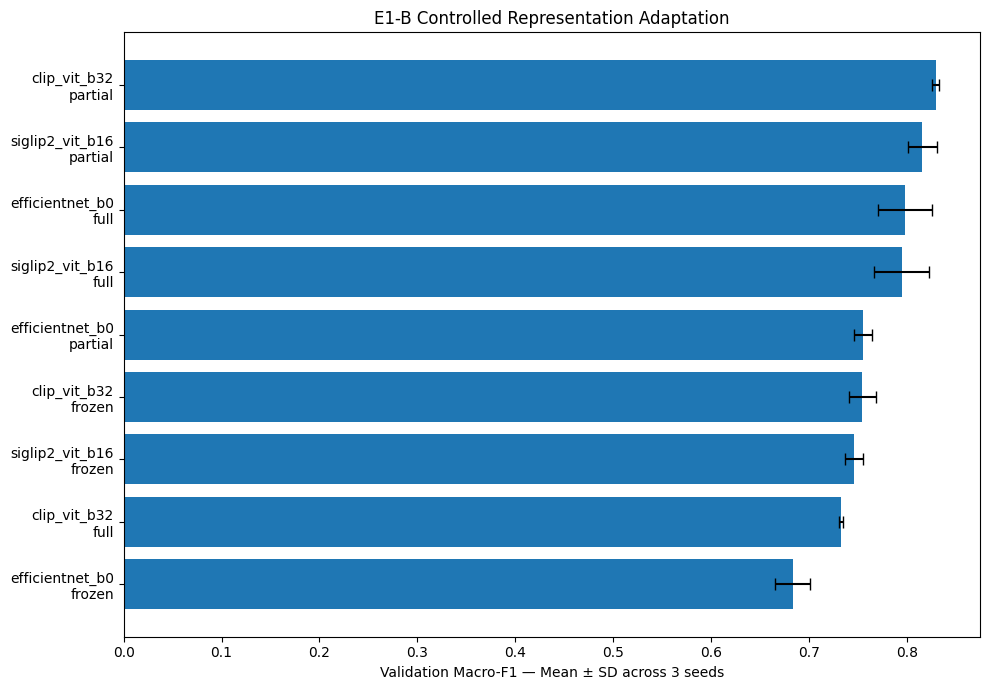

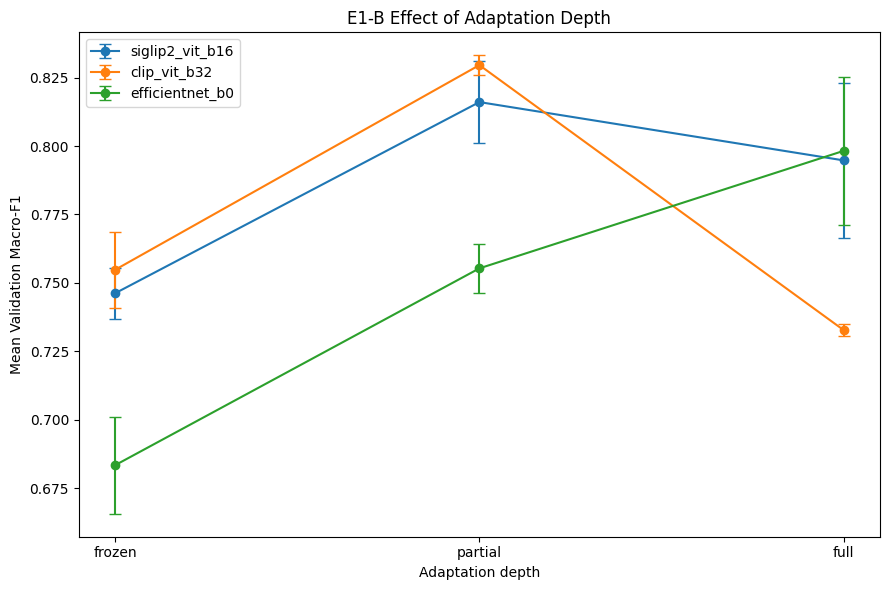

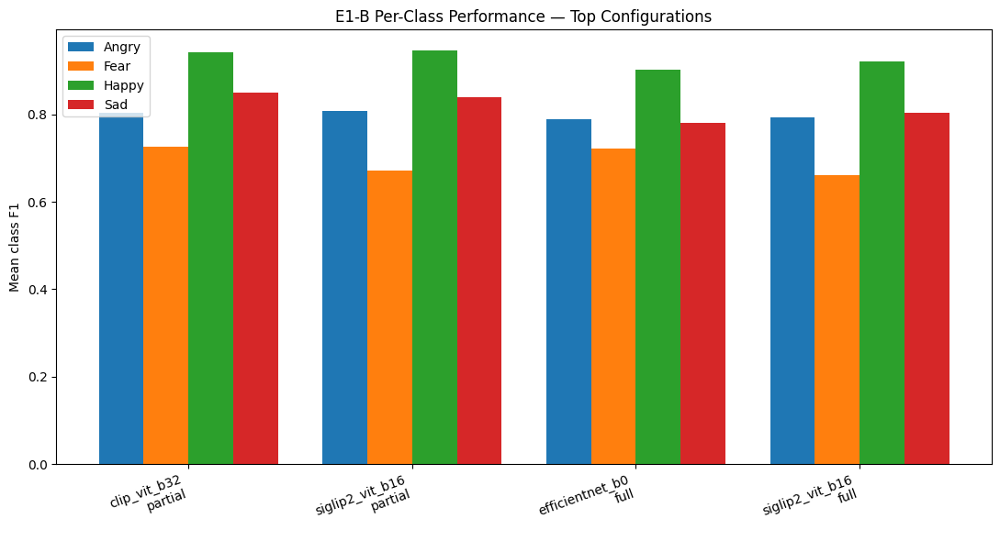


✓ Created 12 fixed drawing comparison panels.

EXAMPLE DRAWING PANELS

A1


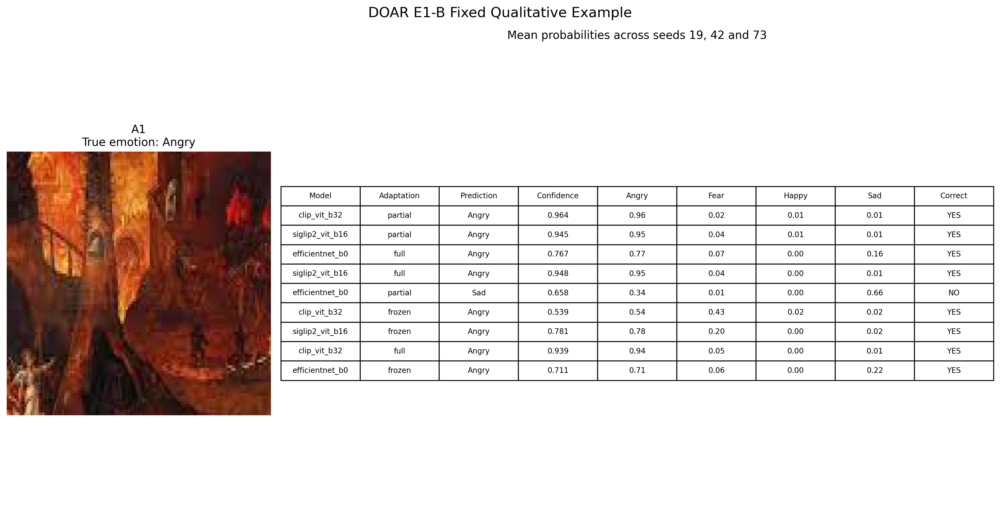


F1


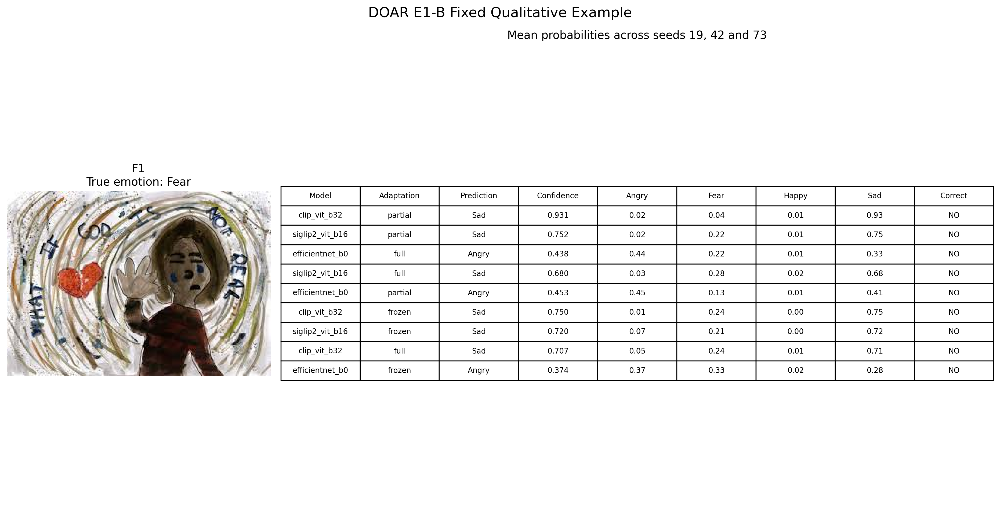


H1


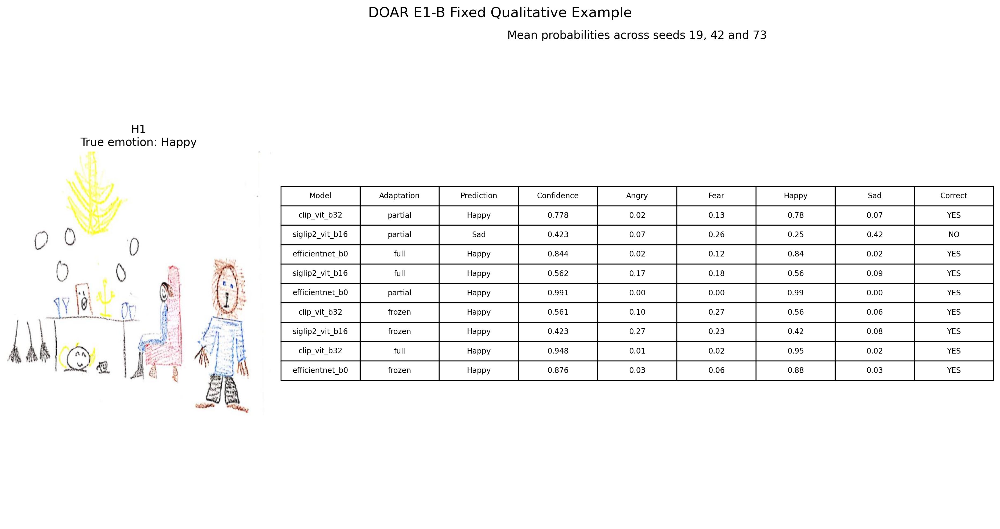


S1


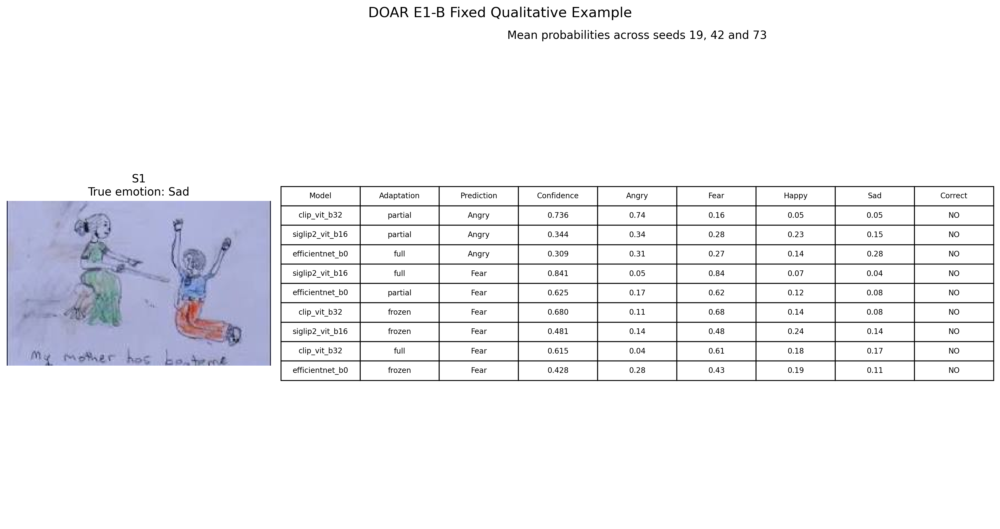


E1-B ANALYSIS RECOVERY COMPLETE

Current Validation leader:
clip_vit_b32 | partial | Macro-F1 = 0.8296 ± 0.0036

All tables:
/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1B/tables

All thesis figures:
/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1B/figures

All 12 drawing comparison panels:
/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1B/qualitative

LOCKED TEST REMAINS UNTOUCHED.
Do NOT run Test evaluation yet.


In [ ]:
# ==================================================================================================
# DOAR E1-B — RECOVERY, ANALYSIS AND QUALITATIVE VISUALIZATION
#
# IMPORTANT:
# - NO MODEL TRAINING
# - NO TEST EVALUATION
# - Reads the 27 completed E1-B runs from Google Drive
# - Reconstructs summary tables and thesis figures
# - Generates predictions/examples for the 12 pre-frozen Validation drawings
# ==================================================================================================

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
from itertools import product
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Image as IPImage


# ==================================================================================================
# 1. PATHS
# ==================================================================================================

ROOT = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1B"
)

DATASET_ROOT = Path(
    "/content/drive/MyDrive/Masters/Datasets/Combined_Drawing"
)

QUAL_MANIFEST = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/"
    "E1B_PROTOCOL/E1B_QUALITATIVE_EXAMPLE_MANIFEST.csv"
)

TABLE_DIR = ROOT / "tables"
FIG_DIR = ROOT / "figures"
QUAL_DIR = ROOT / "qualitative"

for p in [
    TABLE_DIR,
    FIG_DIR,
    QUAL_DIR
]:
    p.mkdir(
        parents=True,
        exist_ok=True
    )


MODELS = [
    "siglip2_vit_b16",
    "clip_vit_b32",
    "efficientnet_b0",
]

MODES = [
    "frozen",
    "partial",
    "full",
]

SEEDS = [
    19,
    42,
    73,
]

CLASSES = [
    "Angry",
    "Fear",
    "Happy",
    "Sad",
]

PROB_COLS = [
    f"prob_{c}"
    for c in CLASSES
]


print("=" * 100)
print("DOAR E1-B RECOVERY / ANALYSIS")
print("=" * 100)


# ==================================================================================================
# 2. VERIFY ALL 27 SAVED RUNS
# ==================================================================================================

results = []
predictions = []
histories = []
per_class_frames = []

missing = []


for model, mode, seed in product(
    MODELS,
    MODES,
    SEEDS
):

    run_name = (
        f"{model}__"
        f"{mode}__"
        f"seed_{seed}"
    )

    run_dir = (
        ROOT /
        "runs" /
        run_name
    )

    required = [
        run_dir / "result.json",
        run_dir / "best.pt",
        run_dir / "best_valid_predictions.csv",
        run_dir / "epoch_history.csv",
        run_dir / "per_class_metrics.csv",
        run_dir / "confusion_matrix.csv",
    ]

    missing_files = [
        str(p)
        for p in required
        if not p.exists()
    ]

    if missing_files:

        missing.extend(
            missing_files
        )

        continue


    # ----------------------------------------------------------------------------------------------
    # RESULT
    # ----------------------------------------------------------------------------------------------

    result = json.loads(
        (
            run_dir /
            "result.json"
        ).read_text(
            encoding="utf-8"
        )
    )

    assert (
        result["status"]
        == "complete"
    )

    results.append(
        result
    )


    # ----------------------------------------------------------------------------------------------
    # PREDICTIONS
    # ----------------------------------------------------------------------------------------------

    pred = pd.read_csv(
        run_dir /
        "best_valid_predictions.csv"
    )

    pred["image_id"] = (
        pred["image_id"]
        .astype(str)
    )

    assert len(pred) == 284

    pred["model"] = model
    pred["mode"] = mode
    pred["seed"] = seed

    predictions.append(
        pred
    )


    # ----------------------------------------------------------------------------------------------
    # HISTORY
    # ----------------------------------------------------------------------------------------------

    history = pd.read_csv(
        run_dir /
        "epoch_history.csv"
    )

    history["model"] = model
    history["mode"] = mode
    history["seed"] = seed

    histories.append(
        history
    )


    # ----------------------------------------------------------------------------------------------
    # PER-CLASS
    # ----------------------------------------------------------------------------------------------

    class_df = pd.read_csv(
        run_dir /
        "per_class_metrics.csv"
    )

    per_class_frames.append(
        class_df
    )


if missing:

    print()
    print("❌ SOME SAVED ARTIFACTS ARE MISSING:")

    for item in missing:
        print(item)

    raise RuntimeError(
        "Do not continue until missing artifacts are checked."
    )


assert len(results) == 27

print()
print("✓ ALL 27 completed run folders recovered from Google Drive.")
print("✓ 27 best checkpoints found.")
print("✓ 27 Validation prediction files found.")
print("✓ Test set NOT accessed.")


# ==================================================================================================
# 3. BUILD MASTER TABLES
# ==================================================================================================

runs = pd.DataFrame(
    results
)

all_predictions = pd.concat(
    predictions,
    ignore_index=True
)

all_histories = pd.concat(
    histories,
    ignore_index=True
)

all_per_class = pd.concat(
    per_class_frames,
    ignore_index=True
)


runs.to_csv(
    TABLE_DIR /
    "E1B_T1_RUN_LEVEL_RESULTS.csv",
    index=False
)

all_predictions.to_csv(
    TABLE_DIR /
    "E1B_T2_ALL_VALIDATION_PREDICTIONS.csv",
    index=False
)

all_histories.to_csv(
    TABLE_DIR /
    "E1B_T3_ALL_EPOCH_HISTORIES.csv",
    index=False
)

all_per_class.to_csv(
    TABLE_DIR /
    "E1B_T4_PER_CLASS_RUN_RESULTS.csv",
    index=False
)


# ==================================================================================================
# 4. FINAL E1-B CONFIGURATION SUMMARY
# ==================================================================================================

summary = (
    runs
    .groupby(
        [
            "model",
            "mode"
        ]
    )
    .agg(
        mean_macro_f1=(
            "best_valid_macro_f1",
            "mean"
        ),

        std_macro_f1=(
            "best_valid_macro_f1",
            "std"
        ),

        min_macro_f1=(
            "best_valid_macro_f1",
            "min"
        ),

        max_macro_f1=(
            "best_valid_macro_f1",
            "max"
        ),

        mean_accuracy=(
            "val_accuracy",
            "mean"
        ),

        std_accuracy=(
            "val_accuracy",
            "std"
        ),

        mean_balanced_accuracy=(
            "val_balanced_accuracy",
            "mean"
        ),

        mean_best_epoch=(
            "best_epoch",
            "mean"
        ),

        mean_training_seconds=(
            "training_seconds",
            "mean"
        ),

        mean_peak_vram_mb=(
            "peak_vram_mb",
            "mean"
        ),

        visual_trainable_percent=(
            "visual_trainable_percent",
            "first"
        ),
    )
    .reset_index()
)


summary = (
    summary
    .sort_values(
        [
            "mean_macro_f1",
            "std_macro_f1",
        ],
        ascending=[
            False,
            True,
        ]
    )
    .reset_index(
        drop=True
    )
)


summary.insert(
    0,
    "rank",
    np.arange(
        1,
        len(summary) + 1
    )
)


summary.to_csv(
    TABLE_DIR /
    "E1B_T5_FINAL_CONFIGURATION_SUMMARY.csv",
    index=False
)


print()
print("=" * 100)
print("FINAL E1-B VALIDATION RANKING")
print("=" * 100)

print(
    summary[
        [
            "rank",
            "model",
            "mode",
            "mean_macro_f1",
            "std_macro_f1",
            "min_macro_f1",
            "max_macro_f1",
            "mean_accuracy",
            "mean_balanced_accuracy",
            "visual_trainable_percent",
        ]
    ].to_string(
        index=False
    )
)


# ==================================================================================================
# 5. ADAPTATION GAINS
# ==================================================================================================

gain_rows = []

for model in MODELS:

    table = (
        summary[
            summary["model"]
            == model
        ]
        .set_index(
            "mode"
        )
    )

    frozen = float(
        table.loc[
            "frozen",
            "mean_macro_f1"
        ]
    )

    partial = float(
        table.loc[
            "partial",
            "mean_macro_f1"
        ]
    )

    full = float(
        table.loc[
            "full",
            "mean_macro_f1"
        ]
    )

    gain_rows.append(
        {
            "model":
                model,

            "frozen":
                frozen,

            "partial":
                partial,

            "full":
                full,

            "partial_minus_frozen":
                partial - frozen,

            "full_minus_frozen":
                full - frozen,

            "full_minus_partial":
                full - partial,
        }
    )


gains = pd.DataFrame(
    gain_rows
)

gains.to_csv(
    TABLE_DIR /
    "E1B_T6_ADAPTATION_GAINS.csv",
    index=False
)


print()
print("=" * 100)
print("ADAPTATION GAINS")
print("=" * 100)

print(
    gains.to_string(
        index=False
    )
)


# ==================================================================================================
# 6. PER-CLASS SUMMARY
# ==================================================================================================

per_class_summary = (
    all_per_class
    .groupby(
        [
            "model",
            "mode",
            "class"
        ]
    )
    .agg(
        mean_precision=(
            "precision",
            "mean"
        ),

        std_precision=(
            "precision",
            "std"
        ),

        mean_recall=(
            "recall",
            "mean"
        ),

        std_recall=(
            "recall",
            "std"
        ),

        mean_f1=(
            "f1",
            "mean"
        ),

        std_f1=(
            "f1",
            "std"
        ),

        support=(
            "support",
            "first"
        ),
    )
    .reset_index()
)


per_class_summary.to_csv(
    TABLE_DIR /
    "E1B_T7_PER_CLASS_SUMMARY.csv",
    index=False
)


# ==================================================================================================
# 7. FIGURE — CONFIGURATION RANKING
# ==================================================================================================

plot_df = (
    summary
    .sort_values(
        "mean_macro_f1",
        ascending=True
    )
)


labels = [
    f"{row.model}\n{row.mode}"
    for row
    in plot_df.itertuples()
]


fig, ax = plt.subplots(
    figsize=(10, 7)
)

ax.barh(
    labels,
    plot_df[
        "mean_macro_f1"
    ],
    xerr=
        plot_df[
            "std_macro_f1"
        ],
    capsize=4
)

ax.set_xlabel(
    "Validation Macro-F1 — Mean ± SD across 3 seeds"
)

ax.set_title(
    "E1-B Controlled Representation Adaptation"
)

fig.tight_layout()

fig.savefig(
    FIG_DIR /
    "E1B_F1_FINAL_CONFIGURATION_RANKING.png",
    dpi=250
)

fig.savefig(
    FIG_DIR /
    "E1B_F1_FINAL_CONFIGURATION_RANKING.pdf"
)

plt.show()

plt.close(fig)


# ==================================================================================================
# 8. FIGURE — ADAPTATION EFFECT
# ==================================================================================================

fig, ax = plt.subplots(
    figsize=(9, 6)
)

mode_order = [
    "frozen",
    "partial",
    "full"
]

for model in MODELS:

    values = []
    errors = []

    for mode in mode_order:

        row = summary[
            (
                summary["model"]
                == model
            )
            &
            (
                summary["mode"]
                == mode
            )
        ].iloc[0]

        values.append(
            row[
                "mean_macro_f1"
            ]
        )

        errors.append(
            row[
                "std_macro_f1"
            ]
        )

    ax.errorbar(
        mode_order,
        values,
        yerr=errors,
        marker="o",
        capsize=4,
        label=model
    )

ax.set_xlabel(
    "Adaptation depth"
)

ax.set_ylabel(
    "Mean Validation Macro-F1"
)

ax.set_title(
    "E1-B Effect of Adaptation Depth"
)

ax.legend()

fig.tight_layout()

fig.savefig(
    FIG_DIR /
    "E1B_F2_ADAPTATION_EFFECT.png",
    dpi=250
)

fig.savefig(
    FIG_DIR /
    "E1B_F2_ADAPTATION_EFFECT.pdf"
)

plt.show()

plt.close(fig)


# ==================================================================================================
# 9. FIGURE — PER-CLASS F1 FOR TOP CONFIGURATIONS
# ==================================================================================================

top_configs = [
    (
        row.model,
        row.mode
    )
    for row
    in summary.head(4).itertuples()
]


x = np.arange(
    len(top_configs)
)

width = 0.20

fig, ax = plt.subplots(
    figsize=(11, 6)
)


for class_index, class_name in enumerate(
    CLASSES
):

    values = []

    for model, mode in top_configs:

        row = per_class_summary[
            (
                per_class_summary[
                    "model"
                ] == model
            )
            &
            (
                per_class_summary[
                    "mode"
                ] == mode
            )
            &
            (
                per_class_summary[
                    "class"
                ] == class_name
            )
        ].iloc[0]

        values.append(
            row[
                "mean_f1"
            ]
        )

    ax.bar(
        x + class_index * width,
        values,
        width,
        label=class_name
    )


ax.set_xticks(
    x + 1.5 * width
)

ax.set_xticklabels(
    [
        f"{model}\n{mode}"
        for model, mode
        in top_configs
    ],
    rotation=20,
    ha="right"
)

ax.set_ylabel(
    "Mean class F1"
)

ax.set_title(
    "E1-B Per-Class Performance — Top Configurations"
)

ax.legend()

fig.tight_layout()

fig.savefig(
    FIG_DIR /
    "E1B_F3_TOP_CONFIGS_PER_CLASS.png",
    dpi=250
)

fig.savefig(
    FIG_DIR /
    "E1B_F3_TOP_CONFIGS_PER_CLASS.pdf"
)

plt.show()

plt.close(fig)


# ==================================================================================================
# 10. QUALITATIVE SEED ENSEMBLE
#
# Mean probability across seeds 19, 42, 73.
# This avoids choosing a convenient seed.
# ==================================================================================================

qual_manifest = pd.read_csv(
    QUAL_MANIFEST
)

qual_manifest[
    "image_id"
] = (
    qual_manifest[
        "image_id"
    ].astype(str)
)


qual_ids = set(
    qual_manifest[
        "image_id"
    ]
)


qual_predictions = (
    all_predictions[
        all_predictions[
            "image_id"
        ].isin(
            qual_ids
        )
    ]
    .copy()
)


qual_ensemble = (
    qual_predictions
    .groupby(
        [
            "image_id",
            "true_class",
            "model",
            "mode"
        ],
        as_index=False
    )[
        PROB_COLS
    ]
    .mean()
)


qual_ensemble[
    "prediction"
] = (
    qual_ensemble[
        PROB_COLS
    ]
    .idxmax(
        axis=1
    )
    .str.replace(
        "prob_",
        "",
        regex=False
    )
)


qual_ensemble[
    "confidence"
] = (
    qual_ensemble[
        PROB_COLS
    ]
    .max(
        axis=1
    )
)


qual_ensemble[
    "correct"
] = (
    qual_ensemble[
        "prediction"
    ]
    ==
    qual_ensemble[
        "true_class"
    ]
)


qual_ensemble = (
    qual_ensemble
    .merge(
        qual_manifest[
            [
                "example_id",
                "image_id",
                "relative_path"
            ]
        ],
        on="image_id",
        how="left"
    )
)


qual_ensemble.to_csv(
    TABLE_DIR /
    "E1B_T8_FIXED_DRAWING_ENSEMBLE_PREDICTIONS.csv",
    index=False
)


# ==================================================================================================
# 11. CREATE ONE PANEL FOR EACH OF THE 12 FIXED DRAWINGS
# ==================================================================================================

def create_drawing_panel(
    manifest_row
):

    image_id = str(
        manifest_row[
            "image_id"
        ]
    )

    example_id = (
        manifest_row[
            "example_id"
        ]
    )

    true_class = (
        manifest_row[
            "true_class"
        ]
    )

    image_path = (
        DATASET_ROOT /
        manifest_row[
            "relative_path"
        ]
    )

    with Image.open(
        image_path
    ) as img:

        image = (
            img
            .convert("RGB")
            .copy()
        )


    subset = (
        qual_ensemble[
            qual_ensemble[
                "image_id"
            ] == image_id
        ]
    )


    rows = []

    # Use final ranking order instead of arbitrary order.
    for _, config in (
        summary.iterrows()
    ):

        model = (
            config[
                "model"
            ]
        )

        mode = (
            config[
                "mode"
            ]
        )

        row = subset[
            (
                subset["model"]
                == model
            )
            &
            (
                subset["mode"]
                == mode
            )
        ]

        assert len(row) == 1

        row = row.iloc[0]

        rows.append(
            [
                model,
                mode,
                row[
                    "prediction"
                ],
                f"{row['confidence']:.3f}",
                f"{row['prob_Angry']:.2f}",
                f"{row['prob_Fear']:.2f}",
                f"{row['prob_Happy']:.2f}",
                f"{row['prob_Sad']:.2f}",
                (
                    "YES"
                    if row[
                        "correct"
                    ]
                    else "NO"
                )
            ]
        )


    fig = plt.figure(
        figsize=(15, 8)
    )

    grid = fig.add_gridspec(
        1,
        2,
        width_ratios=[
            1,
            2.7
        ]
    )


    ax_image = fig.add_subplot(
        grid[
            0,
            0
        ]
    )

    ax_image.imshow(
        image
    )

    ax_image.axis(
        "off"
    )

    ax_image.set_title(
        f"{example_id}\n"
        f"True emotion: {true_class}"
    )


    ax_table = fig.add_subplot(
        grid[
            0,
            1
        ]
    )

    ax_table.axis(
        "off"
    )


    table = ax_table.table(
        cellText=rows,
        colLabels=[
            "Model",
            "Adaptation",
            "Prediction",
            "Confidence",
            "Angry",
            "Fear",
            "Happy",
            "Sad",
            "Correct"
        ],
        loc="center",
        cellLoc="center"
    )

    table.auto_set_font_size(
        False
    )

    table.set_fontsize(
        8
    )

    table.scale(
        1,
        1.5
    )


    ax_table.set_title(
        "Mean probabilities across seeds 19, 42 and 73"
    )

    fig.suptitle(
        "DOAR E1-B Fixed Qualitative Example",
        fontsize=15
    )

    fig.tight_layout()


    output = (
        QUAL_DIR /
        f"E1B_{example_id}_{image_id}"
    )

    fig.savefig(
        output.with_suffix(
            ".png"
        ),
        dpi=250,
        bbox_inches="tight"
    )

    fig.savefig(
        output.with_suffix(
            ".pdf"
        ),
        bbox_inches="tight"
    )

    plt.close(
        fig
    )

    return (
        output.with_suffix(
            ".png"
        )
    )


created_panels = []


for _, row in (
    qual_manifest.iterrows()
):

    created_panels.append(
        create_drawing_panel(
            row
        )
    )


print()
print(
    f"✓ Created {len(created_panels)} "
    "fixed drawing comparison panels."
)


# ==================================================================================================
# 12. SHOW ONE DRAWING FROM EACH EMOTION IN COLAB
# ==================================================================================================

print()
print("=" * 100)
print("EXAMPLE DRAWING PANELS")
print("=" * 100)


for prefix in [
    "A1",
    "F1",
    "H1",
    "S1"
]:

    matches = [
        p
        for p in created_panels
        if p.name.startswith(
            f"E1B_{prefix}_"
        )
    ]

    if matches:

        print()
        print(prefix)

        display(
            IPImage(
                filename=
                    str(
                        matches[0]
                    )
            )
        )


# ==================================================================================================
# 13. FINAL STATUS
# ==================================================================================================

winner = (
    summary.iloc[0]
)

print()
print("=" * 100)
print("E1-B ANALYSIS RECOVERY COMPLETE")
print("=" * 100)

print()
print(
    "Current Validation leader:"
)

print(
    f"{winner['model']} | "
    f"{winner['mode']} | "
    f"Macro-F1 = "
    f"{winner['mean_macro_f1']:.4f} "
    f"± "
    f"{winner['std_macro_f1']:.4f}"
)

print()
print(
    "All tables:"
)

print(
    TABLE_DIR
)

print()
print(
    "All thesis figures:"
)

print(
    FIG_DIR
)

print()
print(
    "All 12 drawing comparison panels:"
)

print(
    QUAL_DIR
)

print()
print(
    "LOCKED TEST REMAINS UNTOUCHED."
)

print(
    "Do NOT run Test evaluation yet."
)

Found 12 qualitative panels

 E1B_A1_7639a203b8f5f0ff.png


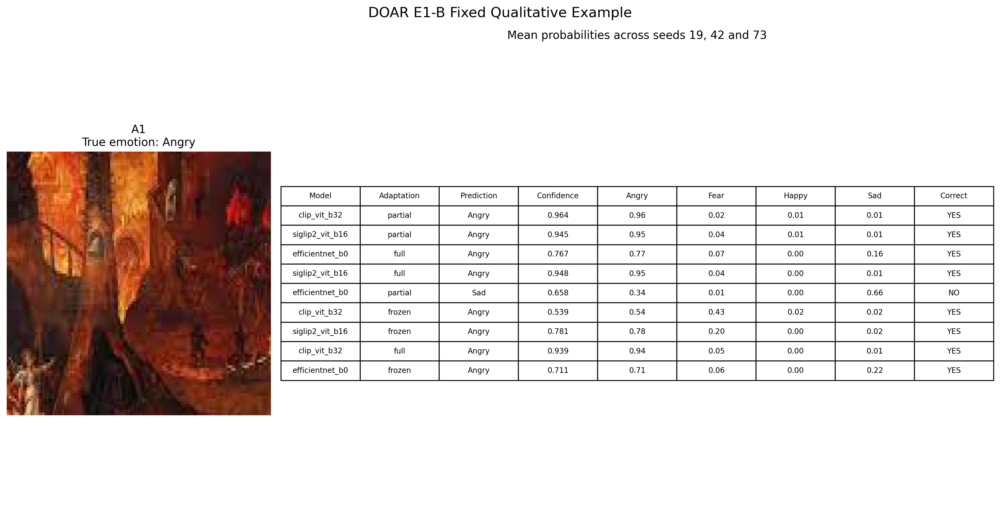


 E1B_A2_7743041b18373dd8.png


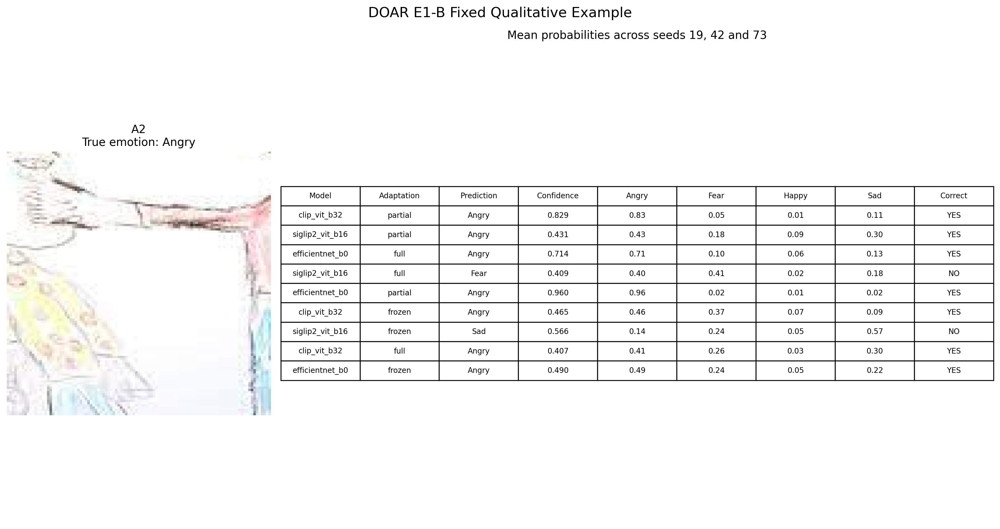


 E1B_A3_d6f2d1cfe6a698a2.png


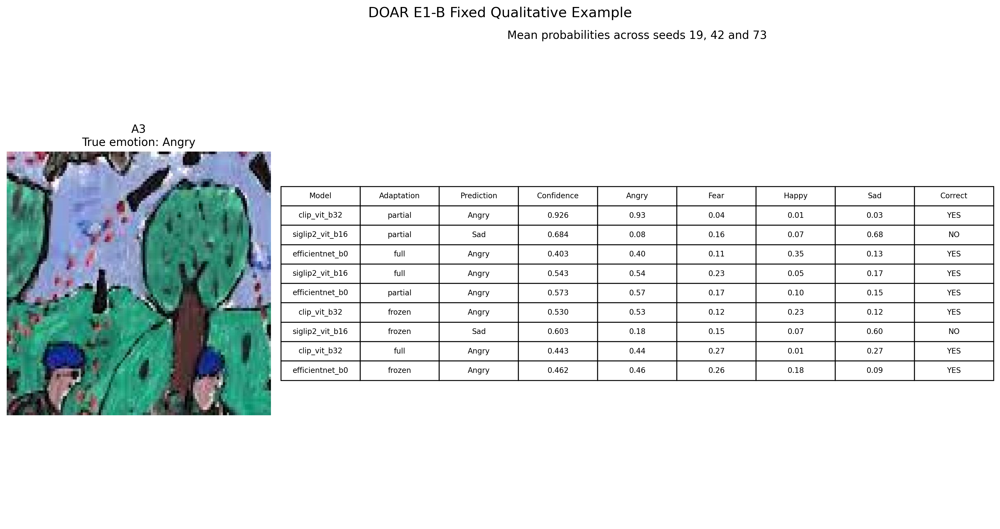


 E1B_F1_c6d0263247d971a2.png


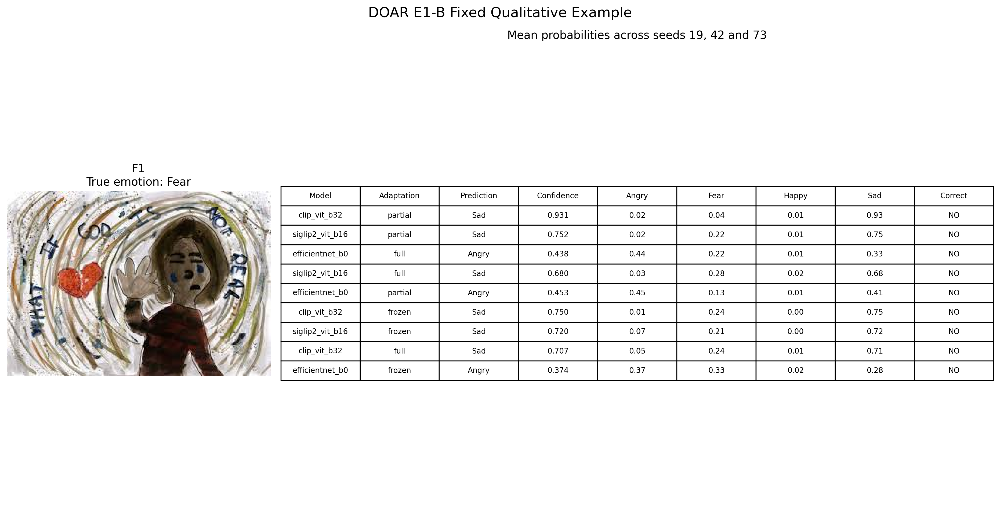


 E1B_F2_d5e8cf785edfc132.png


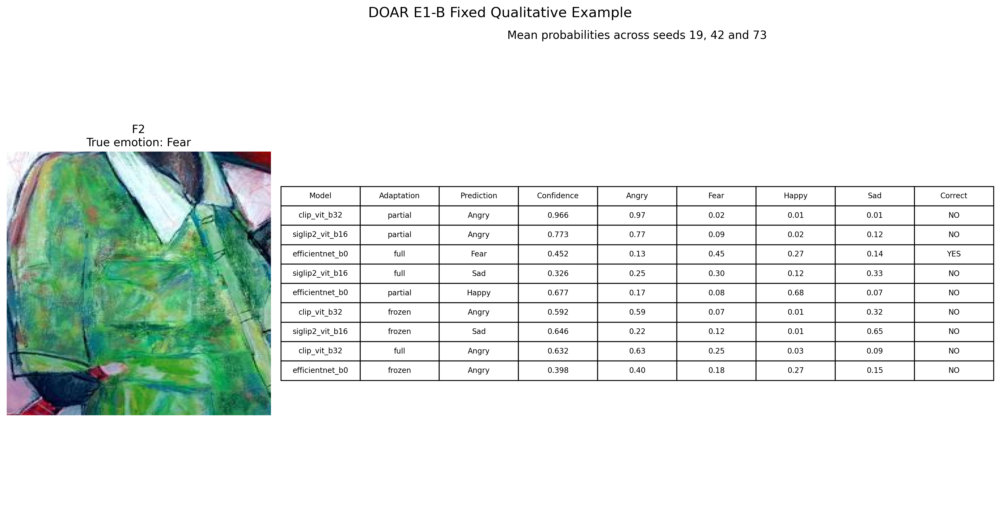


 E1B_F3_3460a336792b356d.png


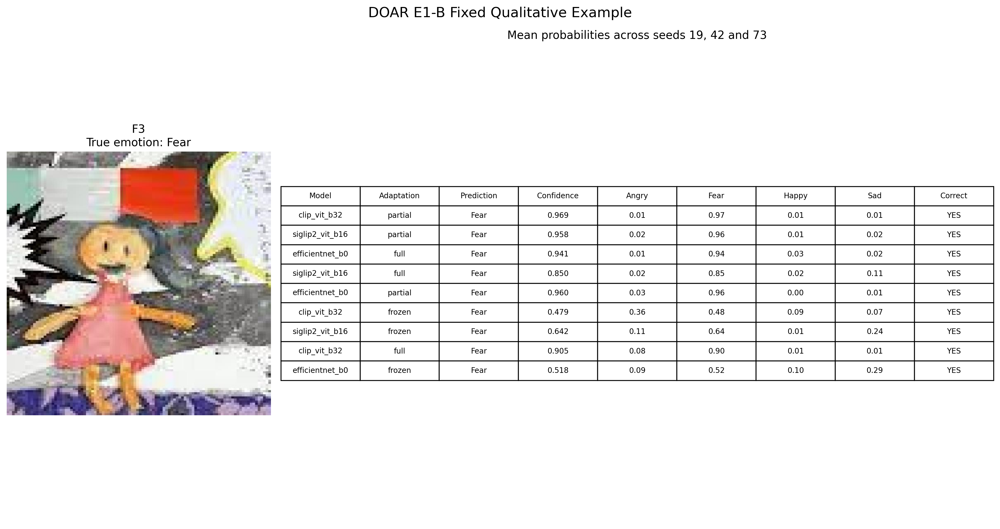


 E1B_H1_9bbbc792abfcebbd.png


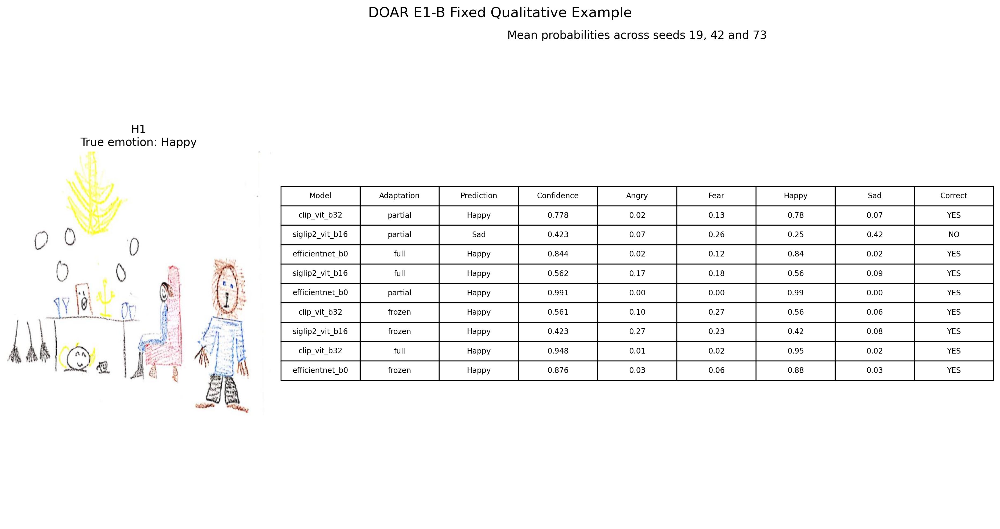


 E1B_H2_ac2a3a4b2dc2307e.png


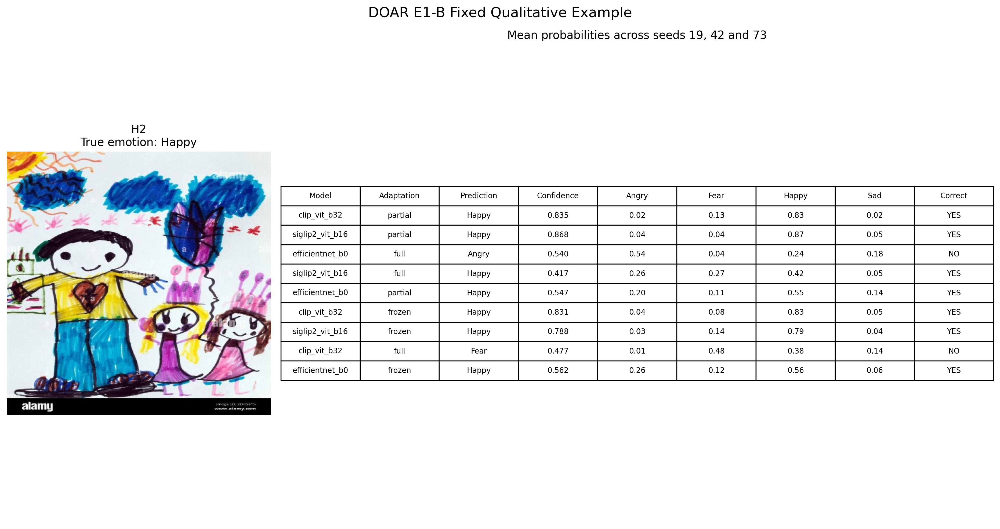


 E1B_H3_aab901f045cff035.png


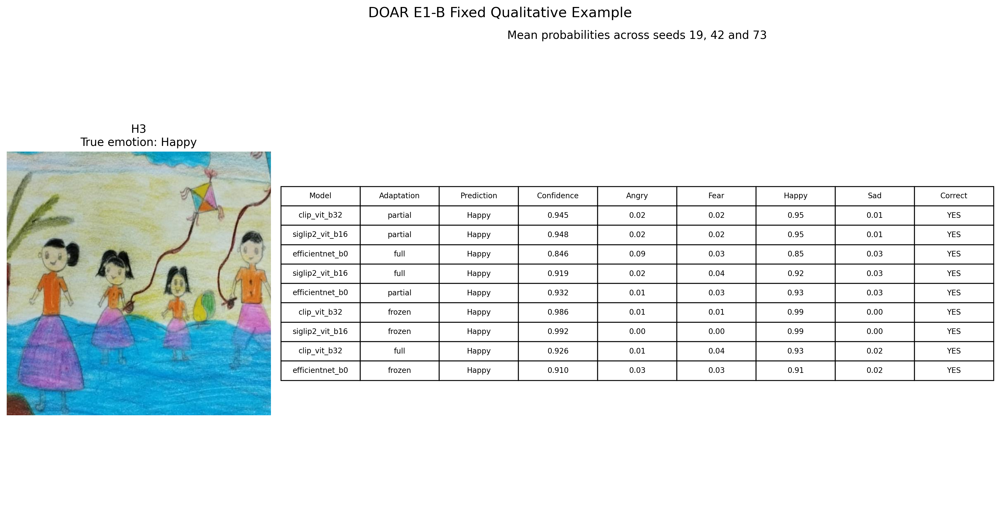


 E1B_S1_dd9e79f7629e353d.png


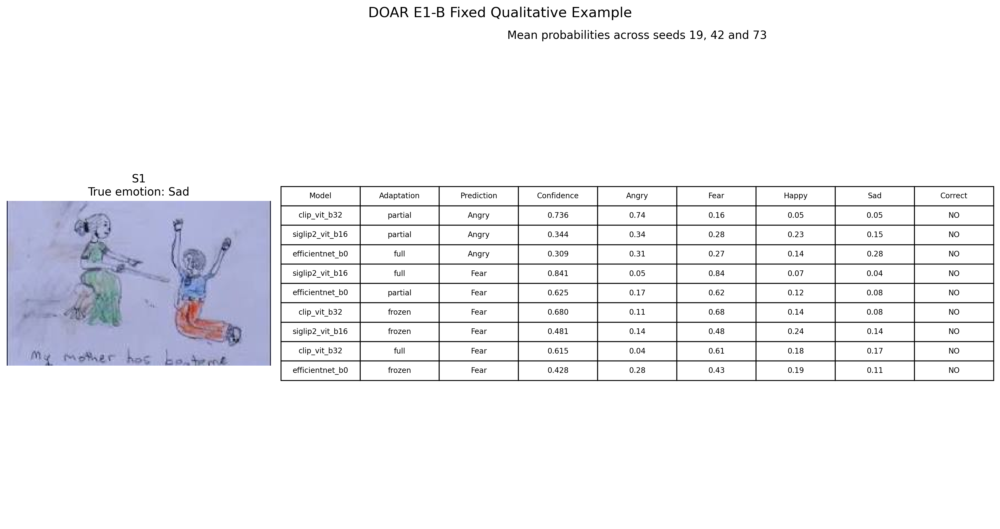


 E1B_S2_4b5a327b6056287b.png


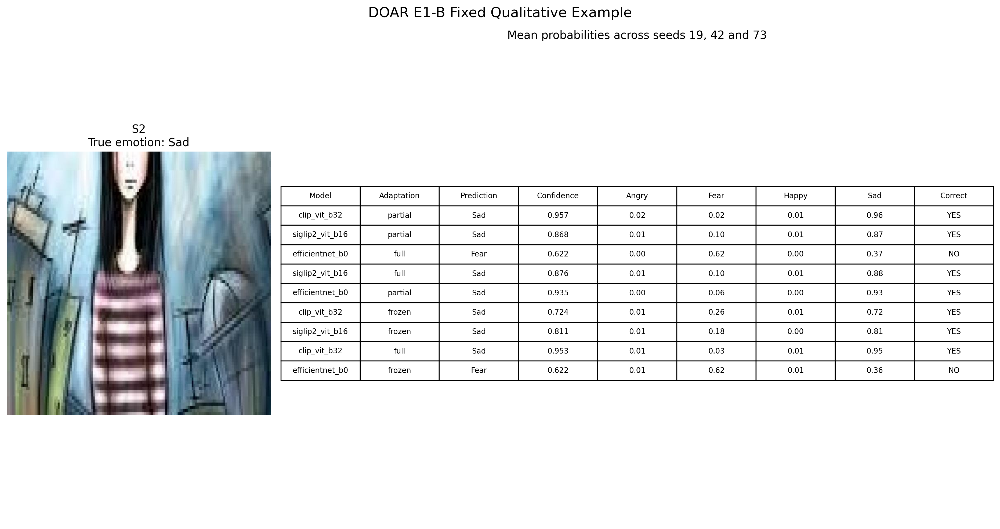


 E1B_S3_e4f0cc81427264fd.png


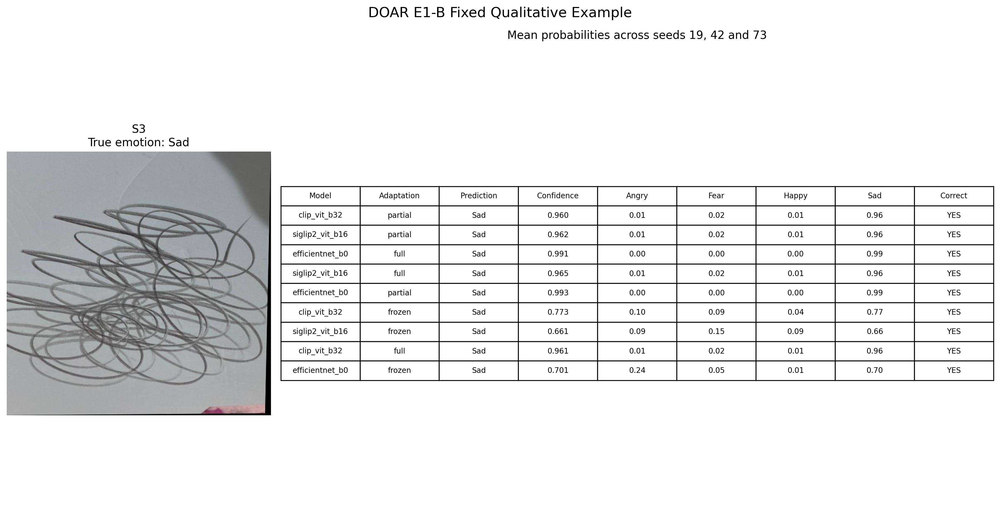

In [ ]:
from pathlib import Path
from IPython.display import display, Image

QUAL_DIR = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1B/qualitative"
)

panels = sorted(QUAL_DIR.glob("*.png"))

print("Found", len(panels), "qualitative panels")

for panel in panels:
    print("\n", panel.name)
    display(Image(filename=str(panel)))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DOAR E1-B CONFUSION MATRIX GENERATION
Loaded predictions: 7668 rows
Loaded summary: 9 configurations

✓ Generated confusion matrices for 9 configurations.
Saved to: /content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1B/figures/confusion_matrices

TOP 3 CONFIGURATIONS

clip_vit_b32 | partial | COUNTS


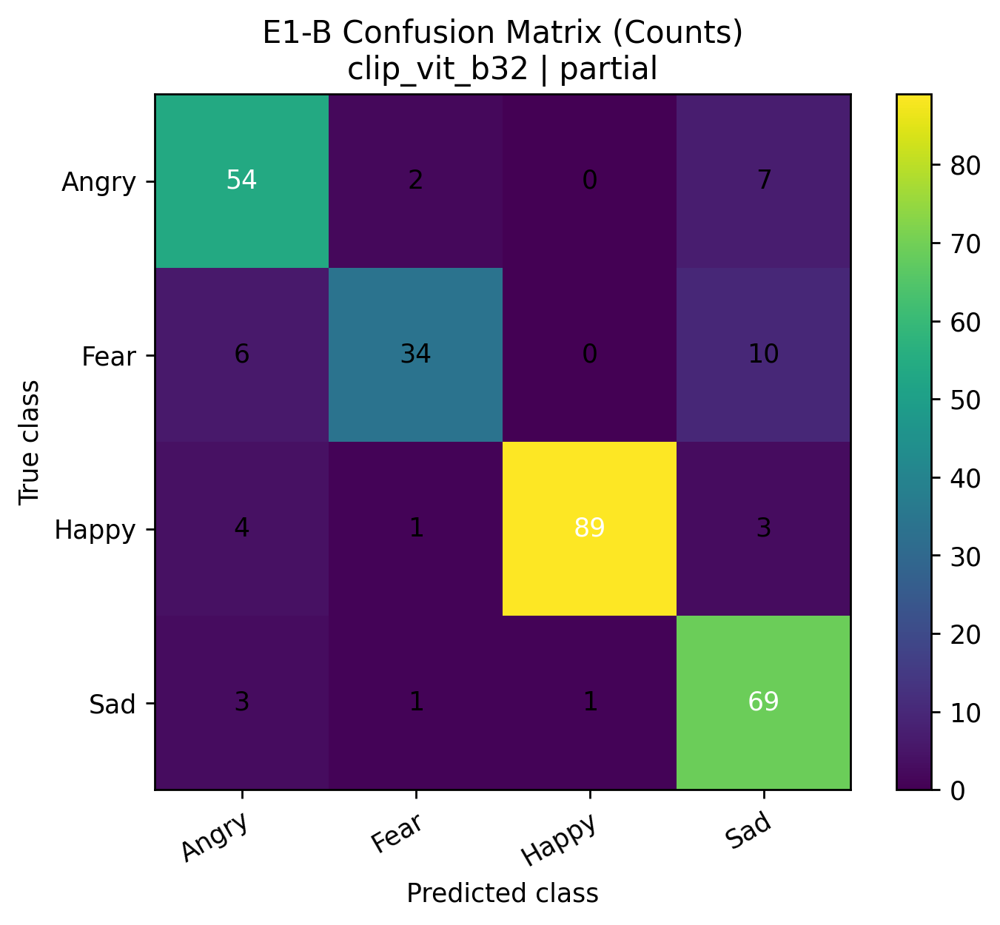

clip_vit_b32 | partial | PERCENT


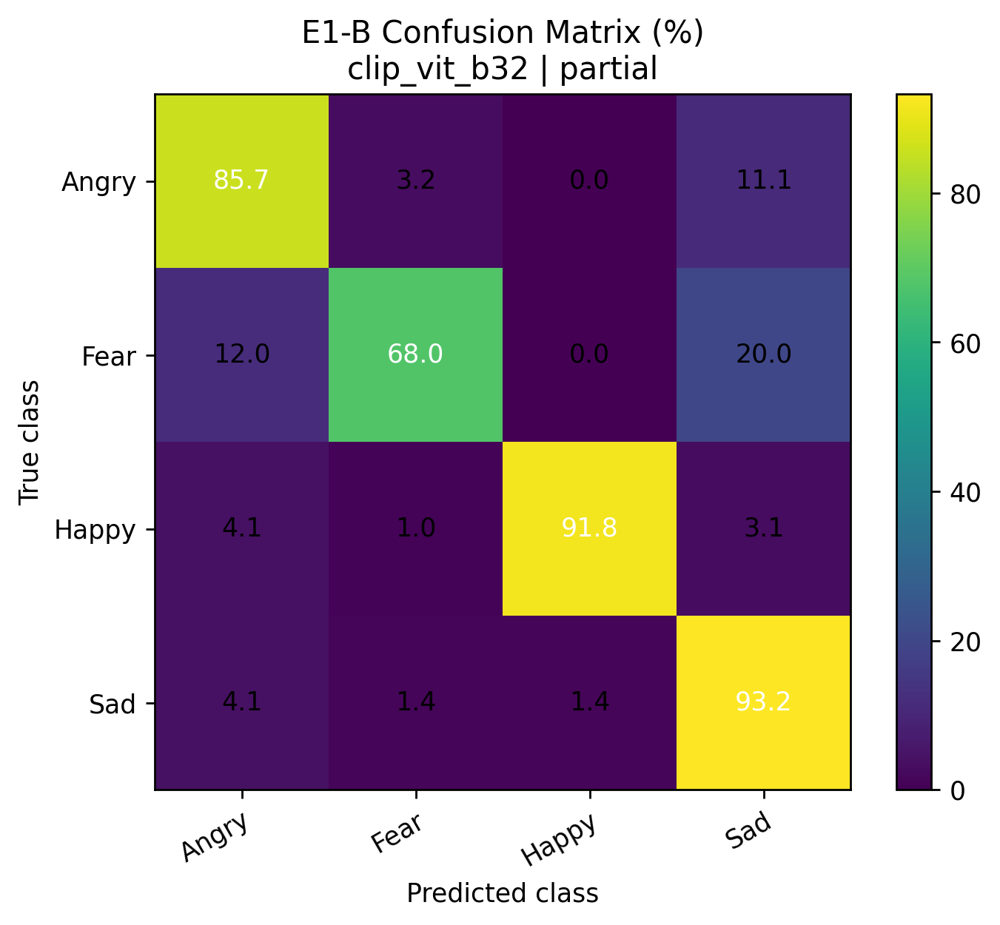


siglip2_vit_b16 | partial | COUNTS


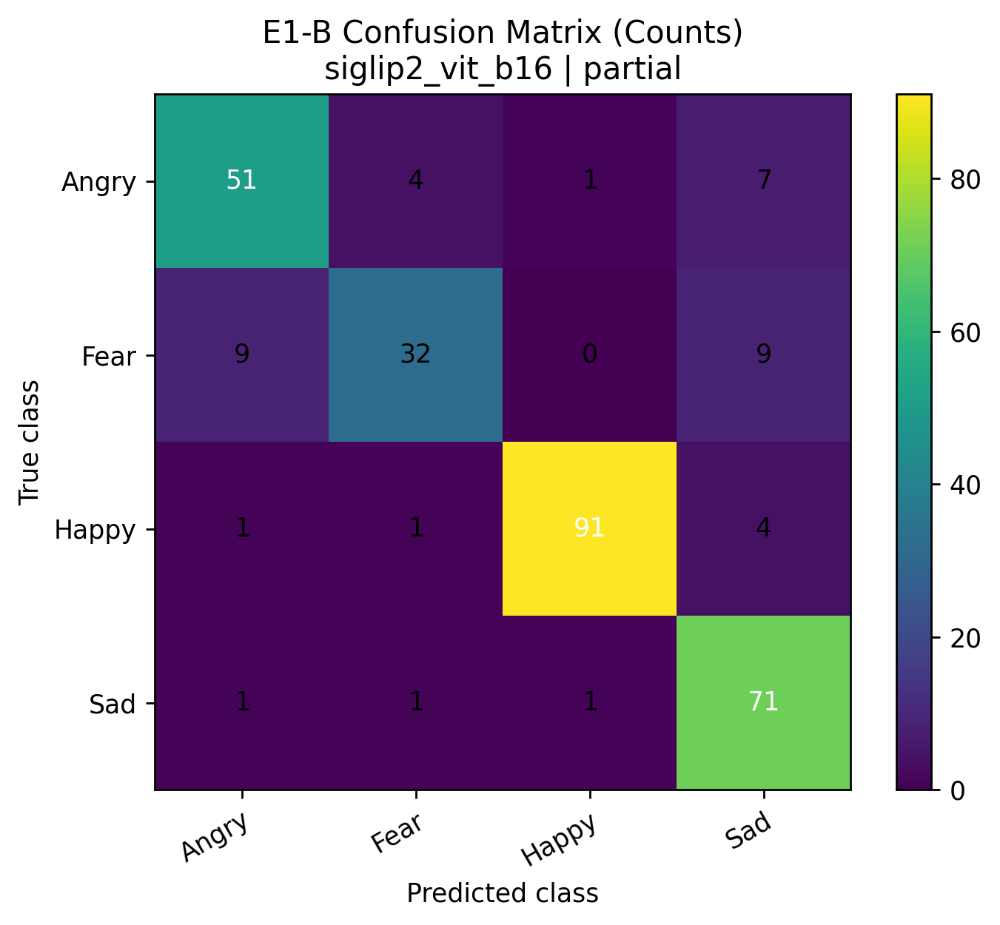

siglip2_vit_b16 | partial | PERCENT


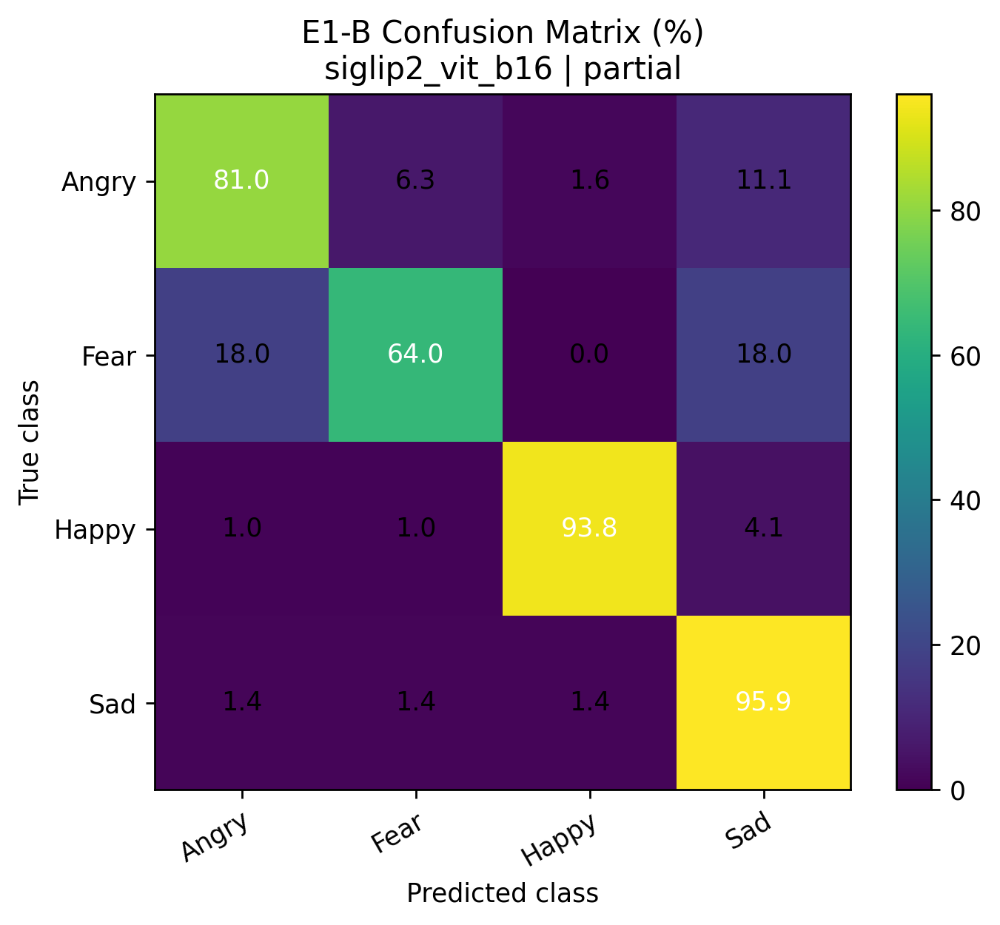


efficientnet_b0 | full | COUNTS


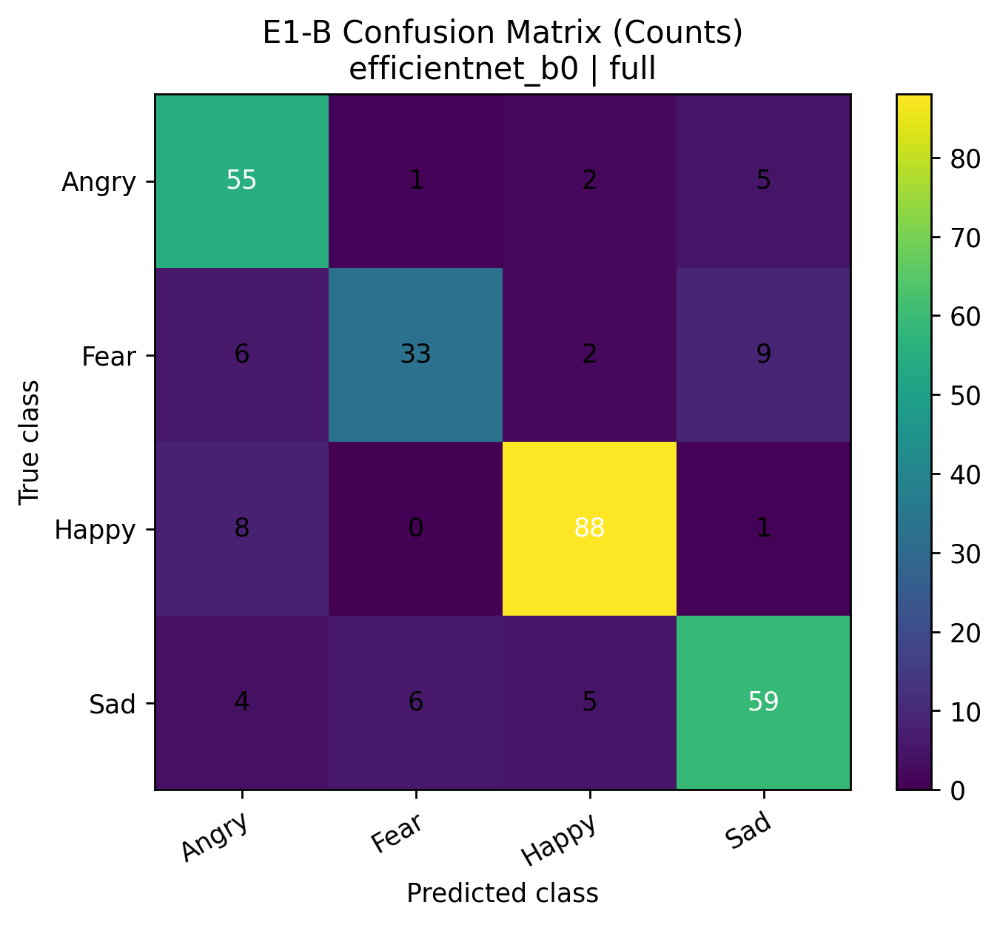

efficientnet_b0 | full | PERCENT


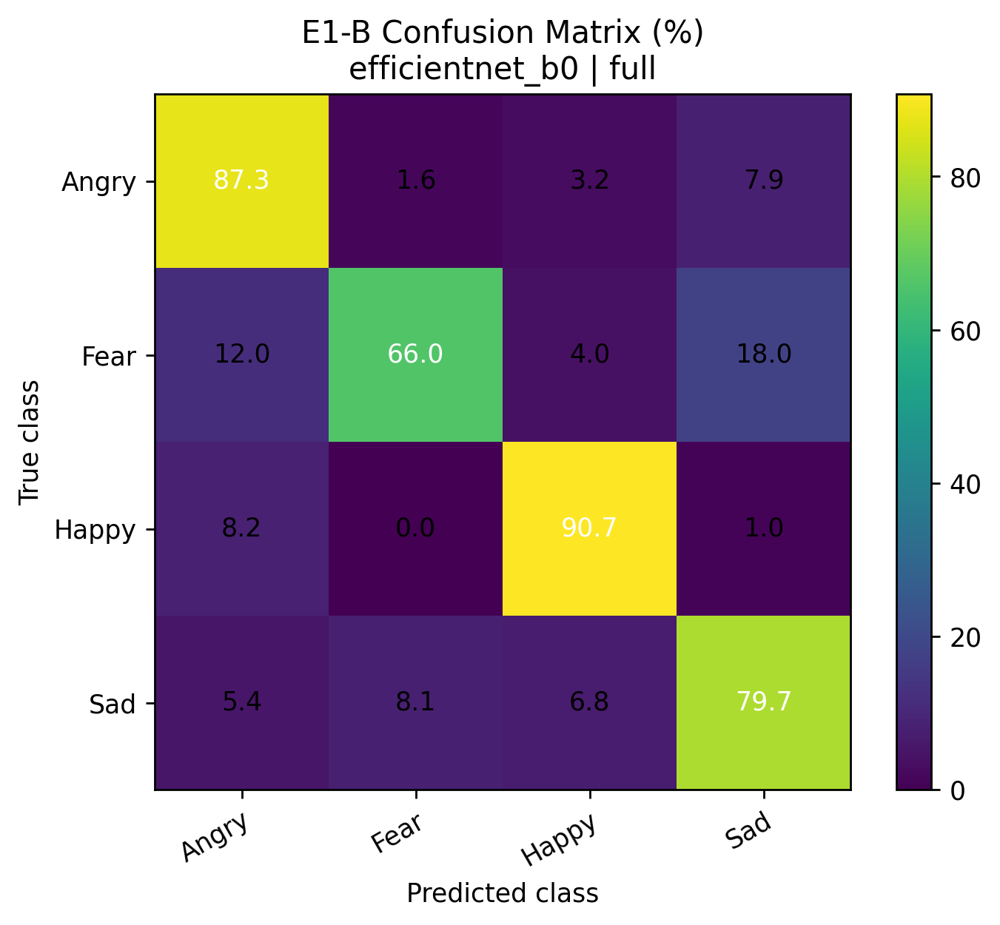


All confusion matrices saved in:
/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1B/figures/confusion_matrices


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from IPython.display import display, Image as IPImage

# ==================================================================================================
# PATHS
# ==================================================================================================

ROOT = Path("/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1B")
TABLE_DIR = ROOT / "tables"
FIG_DIR = ROOT / "figures"
CM_DIR = FIG_DIR / "confusion_matrices"
CM_DIR.mkdir(parents=True, exist_ok=True)

PRED_PATH = TABLE_DIR / "E1B_T2_ALL_VALIDATION_PREDICTIONS.csv"
SUMMARY_PATH = TABLE_DIR / "E1B_T5_FINAL_CONFIGURATION_SUMMARY.csv"

assert PRED_PATH.exists(), f"Missing predictions file: {PRED_PATH}"
assert SUMMARY_PATH.exists(), f"Missing summary file: {SUMMARY_PATH}"

CLASSES = ["Angry", "Fear", "Happy", "Sad"]
PROB_COLS = [f"prob_{c}" for c in CLASSES]

print("=" * 100)
print("DOAR E1-B CONFUSION MATRIX GENERATION")
print("=" * 100)

# ==================================================================================================
# LOAD DATA
# ==================================================================================================

pred = pd.read_csv(PRED_PATH)
summary = pd.read_csv(SUMMARY_PATH)

pred["image_id"] = pred["image_id"].astype(str)

print(f"Loaded predictions: {len(pred)} rows")
print(f"Loaded summary: {len(summary)} configurations")

# ==================================================================================================
# BUILD SEED-ENSEMBLE PREDICTIONS
# For each image within each configuration, average class probabilities across seeds,
# then choose the class with the highest mean probability.
# ==================================================================================================

ensemble = (
    pred.groupby(["image_id", "true_class", "model", "mode"], as_index=False)[PROB_COLS]
    .mean()
)

ensemble["predicted_class"] = (
    ensemble[PROB_COLS]
    .idxmax(axis=1)
    .str.replace("prob_", "", regex=False)
)

ensemble["confidence"] = ensemble[PROB_COLS].max(axis=1)
ensemble["correct"] = ensemble["true_class"] == ensemble["predicted_class"]

ensemble.to_csv(TABLE_DIR / "E1B_T9_ENSEMBLE_PREDICTIONS_FOR_CONFUSION.csv", index=False)

# ==================================================================================================
# PLOTTING FUNCTION
# ==================================================================================================

def plot_confusion_matrix(cm, labels, title, output_path, normalize=False):
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, interpolation="nearest")
    ax.figure.colorbar(im, ax=ax)

    ax.set(
        xticks=np.arange(len(labels)),
        yticks=np.arange(len(labels)),
        xticklabels=labels,
        yticklabels=labels,
        ylabel="True class",
        xlabel="Predicted class",
        title=title,
    )

    plt.setp(ax.get_xticklabels(), rotation=30, ha="right", rotation_mode="anchor")

    if normalize:
        fmt = ".1f"
    else:
        fmt = "d"

    threshold = cm.max() / 2.0 if cm.size else 0.0

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            value = cm[i, j]
            ax.text(
                j,
                i,
                format(value, fmt),
                ha="center",
                va="center",
                color="white" if value > threshold else "black",
                fontsize=10,
            )

    fig.tight_layout()
    fig.savefig(output_path, dpi=250, bbox_inches="tight")
    plt.close(fig)

# ==================================================================================================
# GENERATE 9 CONFIGURATION MATRICES
# ==================================================================================================

saved_files = []

for _, row in summary.iterrows():
    model = row["model"]
    mode = row["mode"]

    subset = ensemble[
        (ensemble["model"] == model) &
        (ensemble["mode"] == mode)
    ].copy()

    assert len(subset) == 284, f"Expected 284 validation rows for {model} {mode}, got {len(subset)}"

    y_true = subset["true_class"].tolist()
    y_pred = subset["predicted_class"].tolist()

    cm_counts = confusion_matrix(y_true, y_pred, labels=CLASSES)

    cm_percent = cm_counts.astype(np.float64)
    row_sums = cm_percent.sum(axis=1, keepdims=True)
    cm_percent = np.divide(
        cm_percent * 100.0,
        row_sums,
        out=np.zeros_like(cm_percent),
        where=row_sums != 0
    )

    stem = f"{model}__{mode}"

    count_path = CM_DIR / f"{stem}__counts.png"
    percent_path = CM_DIR / f"{stem}__percent.png"

    plot_confusion_matrix(
        cm_counts,
        CLASSES,
        title=f"E1-B Confusion Matrix (Counts)\n{model} | {mode}",
        output_path=count_path,
        normalize=False,
    )

    plot_confusion_matrix(
        cm_percent,
        CLASSES,
        title=f"E1-B Confusion Matrix (%)\n{model} | {mode}",
        output_path=percent_path,
        normalize=True,
    )

    pd.DataFrame(cm_counts, index=CLASSES, columns=CLASSES).to_csv(
        CM_DIR / f"{stem}__counts.csv"
    )

    pd.DataFrame(cm_percent, index=CLASSES, columns=CLASSES).to_csv(
        CM_DIR / f"{stem}__percent.csv"
    )

    saved_files.append((model, mode, count_path, percent_path))

print()
print(f"✓ Generated confusion matrices for {len(saved_files)} configurations.")
print(f"Saved to: {CM_DIR}")

# ==================================================================================================
# SHOW TOP 3 CONFIGURATIONS
# ==================================================================================================

top3 = summary.head(3)[["model", "mode"]].values.tolist()

print()
print("=" * 100)
print("TOP 3 CONFIGURATIONS")
print("=" * 100)

for model, mode in top3:
    count_path = CM_DIR / f"{model}__{mode}__counts.png"
    percent_path = CM_DIR / f"{model}__{mode}__percent.png"

    print(f"\n{model} | {mode} | COUNTS")
    display(IPImage(filename=str(count_path)))

    print(f"{model} | {mode} | PERCENT")
    display(IPImage(filename=str(percent_path)))

print()
print("All confusion matrices saved in:")
print(CM_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DOAR E1-C1 — CONFIRMATORY STABILITY
Finalists       : ['clip_vit_b32', 'siglip2_vit_b16']
Adaptation      : partial
Existing seeds  : [19, 42, 73]
NEW seeds       : [11, 37]
Final seed set  : [11, 19, 37, 42, 73]
New runs needed : 4

✓ Exact source commit verified:
a3affe71c1838dc1e0c2b0a606dfbac08c41470c

GPU      : NVIDIA A100-SXM4-40GB
PyTorch  : 2.11.0+cu128
CUDA     : 12.8
AMP dtype: torch.bfloat16

✓ Frozen T0 SHA verified.

✓ Train      = 2599
✓ Validation = 284
✓ Test       = 512 (LOCKED; count only)
✓ Train/Validation overlap = 0

RUN: clip_vit_b32__partial__seed_11


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

Embedding dimension: 512
Visual trainable: 32.72%
epoch=01/30 | train_loss=0.7490 | train_acc=0.7614 | val_acc=0.7746 | val_macro_f1=0.7462 ★ BEST
epoch=02/30 | train_loss=0.3819 | train_acc=0.9373 | val_acc=0.8134 | val_macro_f1=0.7888 ★ BEST
epoch=03/30 | train_loss=0.2843 | train_acc=0.9742 | val_acc=0.8310 | val_macro_f1=0.8211 ★ BEST
epoch=04/30 | train_loss=0.2599 | train_acc=0.9827 | val_acc=0.8239 | val_macro_f1=0.7992
epoch=05/30 | train_loss=0.2461 | train_acc=0.9900 | val_acc=0.8415 | val_macro_f1=0.8242 ★ BEST
epoch=06/30 | train_loss=0.2333 | train_acc=0.9923 | val_acc=0.8169 | val_macro_f1=0.7926
epoch=07/30 | train_loss=0.2401 | train_acc=0.9900 | val_acc=0.8099 | val_macro_f1=0.7813
epoch=08/30 | train_loss=0.2337 | train_acc=0.9938 | val_acc=0.8345 | val_macro_f1=0.8127
epoch=09/30 | train_loss=0.2228 | train_acc=0.9962 | val_acc=0.8345 | val_macro_f1=0.8028
epoch=10/30 | train_loss=0.2252 | train_acc=0.9962 | val_acc=0.8275 | val_macro_f1=0.8025
Early stopping.
✓ COMP

Embedding dimension: 512
Visual trainable: 32.72%
epoch=01/30 | train_loss=0.7299 | train_acc=0.7803 | val_acc=0.7817 | val_macro_f1=0.7545 ★ BEST
epoch=02/30 | train_loss=0.3841 | train_acc=0.9327 | val_acc=0.8169 | val_macro_f1=0.7989 ★ BEST
epoch=03/30 | train_loss=0.2786 | train_acc=0.9777 | val_acc=0.8451 | val_macro_f1=0.8274 ★ BEST
epoch=04/30 | train_loss=0.2451 | train_acc=0.9877 | val_acc=0.8380 | val_macro_f1=0.8230
epoch=05/30 | train_loss=0.2341 | train_acc=0.9908 | val_acc=0.8486 | val_macro_f1=0.8332 ★ BEST
epoch=06/30 | train_loss=0.2339 | train_acc=0.9923 | val_acc=0.8345 | val_macro_f1=0.8114
epoch=07/30 | train_loss=0.2271 | train_acc=0.9958 | val_acc=0.8521 | val_macro_f1=0.8368 ★ BEST
epoch=08/30 | train_loss=0.2379 | train_acc=0.9923 | val_acc=0.8134 | val_macro_f1=0.7857
epoch=09/30 | train_loss=0.2226 | train_acc=0.9958 | val_acc=0.8556 | val_macro_f1=0.8383 ★ BEST
epoch=10/30 | train_loss=0.2263 | train_acc=0.9942 | val_acc=0.7993 | val_macro_f1=0.7756
epoch=11

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

Embedding dimension: 768
Visual trainable: 30.52%
epoch=01/30 | train_loss=0.7890 | train_acc=0.7638 | val_acc=0.7711 | val_macro_f1=0.7455 ★ BEST
epoch=02/30 | train_loss=0.3999 | train_acc=0.9327 | val_acc=0.8063 | val_macro_f1=0.7607 ★ BEST
epoch=03/30 | train_loss=0.2925 | train_acc=0.9719 | val_acc=0.8099 | val_macro_f1=0.7798 ★ BEST
epoch=04/30 | train_loss=0.2548 | train_acc=0.9858 | val_acc=0.8239 | val_macro_f1=0.7894 ★ BEST
epoch=05/30 | train_loss=0.2323 | train_acc=0.9942 | val_acc=0.8239 | val_macro_f1=0.7954 ★ BEST
epoch=06/30 | train_loss=0.2277 | train_acc=0.9950 | val_acc=0.8415 | val_macro_f1=0.8183 ★ BEST
epoch=07/30 | train_loss=0.2302 | train_acc=0.9927 | val_acc=0.8169 | val_macro_f1=0.7853
epoch=08/30 | train_loss=0.2246 | train_acc=0.9958 | val_acc=0.8239 | val_macro_f1=0.7938
epoch=09/30 | train_loss=0.2186 | train_acc=0.9981 | val_acc=0.8310 | val_macro_f1=0.8073
epoch=10/30 | train_loss=0.2276 | train_acc=0.9954 | val_acc=0.8239 | val_macro_f1=0.7979
epoch=11

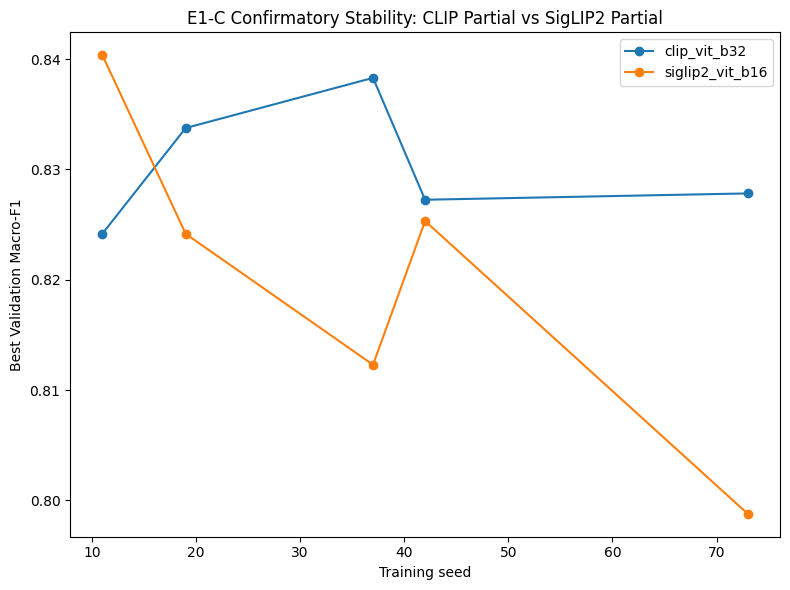


E1-C1 CONFIRMATORY STABILITY COMPLETE

5-SEED FINALIST SUMMARY

 rank           model  mean_macro_f1  std_macro_f1  min_macro_f1  max_macro_f1  mean_accuracy  mean_balanced_accuracy
    1    clip_vit_b32       0.830258      0.005674      0.824175      0.838295       0.849296                0.829367
    2 siglip2_vit_b16       0.820179      0.015562      0.798787      0.840343       0.844366                0.817399

PAIRED SEED RESULTS

 seed  clip_vit_b32  siglip2_vit_b16  clip_minus_siglip
   11      0.824175         0.840343          -0.016167
   19      0.833748         0.824158           0.009591
   37      0.838295         0.812291           0.026004
   42      0.827248         0.825319           0.001929
   73      0.827822         0.798787           0.029036

Mean CLIP - SigLIP Macro-F1 difference: +0.0101
CLIP wins: 4/5 seeds
SigLIP wins: 1/5 seeds
Descriptive seed-bootstrap 95% CI: [-0.0041, +0.0239]
Bootstrap P(delta > 0): 0.915

IMPORTANT: this bootstrap is descriptive only

In [ ]:
# ==================================================================================================
# DOAR MASTER THESIS
# E1-C1 — CONFIRMATORY STABILITY OF THE TWO E1-B FINALISTS
#
# PURPOSE
# -------
# E1-B produced:
#   CLIP ViT-B/32 Partial     = 0.8296 ± 0.0036
#   SigLIP2 ViT-B/16 Partial = 0.8161 ± 0.0150
#
# E1-C1 adds TWO FRESH, PREDECLARED seeds:
#   11 and 37
#
# Existing E1-B seeds:
#   19, 42, 73
#
# After this experiment:
#   5 seeds / finalist
#   2 finalists
#   10 total comparable results
#
# ONLY 4 NEW TRAINING RUNS ARE REQUIRED.
#
# IMPORTANT
# ---------
# - Same T0 dataset
# - Same E1-B partial fine-tuning protocol
# - Same augmentation
# - Same learning rates
# - Same loss
# - Same early stopping
# - Same Validation metric
# - Test remains LOCKED
#
# This cell has checkpoint/resume support.
# ==================================================================================================

from google.colab import drive
drive.mount("/content/drive")

import gc
import csv
import json
import random
import hashlib
import subprocess
import sys
import time
from pathlib import Path

# ==================================================================================================
# 1. CONFIGURATION
# ==================================================================================================

REPO_URL = "https://github.com/HHemaly/DOAR.git"

SOURCE_COMMIT = "a3affe71c1838dc1e0c2b0a606dfbac08c41470c"

EXPECTED_T0_SHA = (
    "4631ce8bddde64755ba44758827310703f1b332bcb28f72b55f22b3b19b92c9d"
)

DATASET_ROOT = Path(
    "/content/drive/MyDrive/Masters/Datasets/Combined_Drawing"
)

T0_SOURCE = Path(
    "/content/drive/MyDrive/Masters/Datasets/DOAR_FROZEN_TO/"
    "final_partition/partition_manifest.csv"
)

E1B_ROOT = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1B"
)

OUT_ROOT = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1C_STABILITY"
)

REPO = Path("/content/DOAR")

CLASSES = [
    "Angry",
    "Fear",
    "Happy",
    "Sad",
]

CLASS_TO_INDEX = {
    c: i
    for i, c in enumerate(CLASSES)
}

# Only the top two E1-B finalists.
MODELS = [
    "clip_vit_b32",
    "siglip2_vit_b16",
]

MODE = "partial"

# Existing E1-B seeds.
EXISTING_SEEDS = [
    19,
    42,
    73,
]

# New E1-C confirmatory seeds.
# These are fixed BEFORE observing E1-C outcomes.
NEW_SEEDS = [
    11,
    37,
]

ALL_SEEDS = sorted(
    EXISTING_SEEDS + NEW_SEEDS
)

MAX_EPOCHS = 30
PATIENCE = 5

BATCH_SIZE = 16

HEAD_LR = 3e-4
ENCODER_LR = 3e-5

WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.05

PARTIAL_TARGET = 0.25

NUM_WORKERS = 2

BOOTSTRAP_REPETITIONS = 20000
BOOTSTRAP_SEED = 20260823

# --------------------------------------------------------------------------------------------------
# Output directories
# --------------------------------------------------------------------------------------------------

RUNS_DIR = OUT_ROOT / "runs"
TABLES_DIR = OUT_ROOT / "tables"
FIGURES_DIR = OUT_ROOT / "figures"

for directory in [
    OUT_ROOT,
    RUNS_DIR,
    TABLES_DIR,
    FIGURES_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

print("=" * 110)
print("DOAR E1-C1 — CONFIRMATORY STABILITY")
print("=" * 110)

print("Finalists       :", MODELS)
print("Adaptation      :", MODE)
print("Existing seeds  :", EXISTING_SEEDS)
print("NEW seeds       :", NEW_SEEDS)
print("Final seed set  :", ALL_SEEDS)
print("New runs needed :", len(MODELS) * len(NEW_SEEDS))


# ==================================================================================================
# 2. CLONE EXACT E1 SCIENTIFIC CHECKPOINT
# ==================================================================================================

if REPO.exists():

    subprocess.run(
        [
            "rm",
            "-rf",
            str(REPO),
        ],
        check=True,
    )

subprocess.run(
    [
        "git",
        "clone",
        "-q",
        REPO_URL,
        str(REPO),
    ],
    check=True,
)

subprocess.run(
    [
        "git",
        "-C",
        str(REPO),
        "checkout",
        "-q",
        SOURCE_COMMIT,
    ],
    check=True,
)

actual_commit = subprocess.check_output(
    [
        "git",
        "-C",
        str(REPO),
        "rev-parse",
        "HEAD",
    ],
    text=True,
).strip()

assert actual_commit == SOURCE_COMMIT

print()
print("✓ Exact source commit verified:")
print(actual_commit)


# ==================================================================================================
# 3. INSTALL DEPENDENCIES
# ==================================================================================================

requirements = (
    REPO
    / "experiments"
    / "E1_visual_representation"
    / "requirements-e1.txt"
)

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "--upgrade-strategy",
        "only-if-needed",
        "-r",
        str(requirements),
    ],
    check=True,
)

import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from PIL import Image

from torch.utils.data import (
    Dataset,
    DataLoader,
)

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
)

from torchvision import transforms

import open_clip

import matplotlib.pyplot as plt


# ==================================================================================================
# 4. GPU
# ==================================================================================================

assert torch.cuda.is_available(), (
    "GPU required."
)

DEVICE = "cuda"

AMP_DTYPE = (
    torch.bfloat16
    if torch.cuda.is_bf16_supported()
    else torch.float16
)

print()
print("GPU      :", torch.cuda.get_device_name(0))
print("PyTorch  :", torch.__version__)
print("CUDA     :", torch.version.cuda)
print("AMP dtype:", AMP_DTYPE)


# ==================================================================================================
# 5. VERIFY FROZEN T0
# ==================================================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b"",
        ):

            h.update(chunk)

    return h.hexdigest()


assert T0_SOURCE.exists()

actual_sha = sha256_file(
    T0_SOURCE
)

assert actual_sha == EXPECTED_T0_SHA, (
    "Frozen T0 SHA mismatch."
)

print()
print("✓ Frozen T0 SHA verified.")


# ==================================================================================================
# 6. LOAD TRAIN + VALID ONLY
#
# Test is counted only.
# No Test sample object is created.
# ==================================================================================================

train_rows = []
valid_rows = []

test_count = 0

with open(
    T0_SOURCE,
    encoding="utf-8",
    newline="",
) as f:

    reader = csv.DictReader(f)

    for row in reader:

        split = row["new_split"]

        if split == "train":

            train_rows.append(
                {
                    "image_id":
                        row["image_id"],

                    "relative_path":
                        row["relative_path"],

                    "path":
                        str(
                            DATASET_ROOT
                            / row["relative_path"]
                        ),

                    "class":
                        row["class"],
                }
            )

        elif split == "valid":

            valid_rows.append(
                {
                    "image_id":
                        row["image_id"],

                    "relative_path":
                        row["relative_path"],

                    "path":
                        str(
                            DATASET_ROOT
                            / row["relative_path"]
                        ),

                    "class":
                        row["class"],
                }
            )

        elif split == "test":

            test_count += 1


assert len(train_rows) == 2599
assert len(valid_rows) == 284
assert test_count == 512

train_ids = {
    row["image_id"]
    for row in train_rows
}

valid_ids = {
    row["image_id"]
    for row in valid_rows
}

assert train_ids.isdisjoint(
    valid_ids
)

print()
print("✓ Train      =", len(train_rows))
print("✓ Validation =", len(valid_rows))
print("✓ Test       =", test_count, "(LOCKED; count only)")
print("✓ Train/Validation overlap = 0")


# ==================================================================================================
# 7. RANDOMNESS
# ==================================================================================================

def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


# ==================================================================================================
# 8. AUGMENTATION
#
# EXACT SAME conservative augmentation as E1-B.
# ==================================================================================================

def conservative_augmentation():

    return [
        transforms.RandomAffine(
            degrees=7,
            translate=(0.03, 0.03),
            scale=(0.95, 1.05),
        ),

        transforms.ColorJitter(
            brightness=0.10,
            contrast=0.10,
            saturation=0.05,
        ),
    ]


# ==================================================================================================
# 9. DATASET
# ==================================================================================================

class DrawingDataset(Dataset):

    def __init__(
        self,
        rows,
        transform,
    ):

        self.rows = rows
        self.transform = transform

    def __len__(self):

        return len(self.rows)

    def __getitem__(
        self,
        index,
    ):

        row = self.rows[index]

        with Image.open(
            row["path"]
        ) as image_file:

            image = image_file.convert(
                "RGB"
            )

        image = self.transform(
            image
        )

        target = CLASS_TO_INDEX[
            row["class"]
        ]

        return (
            image,
            target,
            row["image_id"],
        )


# ==================================================================================================
# 10. OPENCLIP TRAIN TRANSFORM
# ==================================================================================================

def build_openclip_train_transform(
    native_eval_transform
):

    original_steps = list(
        native_eval_transform.transforms
    )

    output = []

    inserted = False

    tensor_step_names = {
        "ToTensor",
        "PILToTensor",
        "ToImage",
    }

    for step in original_steps:

        name = step.__class__.__name__

        if (
            not inserted
            and name in tensor_step_names
        ):

            output.extend(
                conservative_augmentation()
            )

            inserted = True

        output.append(step)

    if not inserted:

        output = []

        for step in original_steps:

            name = step.__class__.__name__

            if (
                not inserted
                and name == "Normalize"
            ):

                output.extend(
                    conservative_augmentation()
                )

                inserted = True

            output.append(step)

    if not inserted:

        raise RuntimeError(
            "Could not safely insert augmentation "
            "into OpenCLIP preprocessing."
        )

    return transforms.Compose(
        output
    )


# ==================================================================================================
# 11. CLASSIFIER WRAPPER
# ==================================================================================================

class OpenCLIPClassifier(nn.Module):

    def __init__(
        self,
        clip_model,
        embedding_dimension,
    ):

        super().__init__()

        self.clip_model = clip_model

        self.head = nn.Linear(
            embedding_dimension,
            len(CLASSES),
        )

    @property
    def visual(self):

        return self.clip_model.visual

    def forward(
        self,
        images,
    ):

        features = (
            self.clip_model
            .encode_image(
                images,
                normalize=False,
            )
            .flatten(1)
        )

        return self.head(
            features
        )


# ==================================================================================================
# 12. EMBEDDING DIMENSION
# ==================================================================================================

def infer_embedding_dimension(
    clip_model,
    eval_transform,
    sample_path,
):

    with Image.open(
        sample_path
    ) as image_file:

        image = image_file.convert(
            "RGB"
        )

    tensor = (
        eval_transform(image)
        .unsqueeze(0)
        .to(DEVICE)
    )

    clip_model = clip_model.to(
        DEVICE
    )

    clip_model.eval()

    with torch.no_grad():

        with torch.autocast(
            device_type="cuda",
            dtype=AMP_DTYPE,
        ):

            features = (
                clip_model
                .encode_image(
                    tensor,
                    normalize=False,
                )
                .flatten(1)
            )

    dimension = int(
        features.shape[1]
    )

    del tensor
    del features

    torch.cuda.empty_cache()

    return dimension


# ==================================================================================================
# 13. PARAMETER HELPERS
# ==================================================================================================

def freeze_module(module):

    for parameter in module.parameters():

        parameter.requires_grad = False


def unfreeze_module(module):

    for parameter in module.parameters():

        parameter.requires_grad = True


def parameter_count(module):

    return sum(
        parameter.numel()
        for parameter in module.parameters()
    )


def trainable_parameter_count(module):

    return sum(
        parameter.numel()
        for parameter in module.parameters()
        if parameter.requires_grad
    )


# ==================================================================================================
# 14. ORDERED VISUAL BLOCKS
# ==================================================================================================

def ordered_visual_units(
    visual
):

    if (
        hasattr(visual, "transformer")
        and hasattr(
            visual.transformer,
            "resblocks"
        )
    ):

        return list(
            visual
            .transformer
            .resblocks
        )

    if (
        hasattr(visual, "transformer")
        and hasattr(
            visual.transformer,
            "blocks"
        )
    ):

        return list(
            visual
            .transformer
            .blocks
        )

    if (
        hasattr(visual, "trunk")
        and hasattr(
            visual.trunk,
            "blocks"
        )
    ):

        return list(
            visual.trunk.blocks
        )

    if hasattr(
        visual,
        "blocks"
    ):

        return list(
            visual.blocks
        )

    if (
        hasattr(visual, "trunk")
        and hasattr(
            visual.trunk,
            "stages"
        )
    ):

        return list(
            visual.trunk.stages
        )

    if hasattr(
        visual,
        "stages"
    ):

        return list(
            visual.stages
        )

    return None


# ==================================================================================================
# 15. PARTIAL FINE-TUNING
#
# EXACT SAME strategy as E1-B:
# select final visual units until >= ~25% of visual parameters.
# ==================================================================================================

def configure_partial_trainability(
    wrapper
):

    freeze_module(
        wrapper.clip_model
    )

    unfreeze_module(
        wrapper.head
    )

    visual = wrapper.visual

    units = ordered_visual_units(
        visual
    )

    if not units:

        raise RuntimeError(
            "Could not identify ordered visual units."
        )

    total_visual = parameter_count(
        visual
    )

    target = (
        total_visual
        * PARTIAL_TARGET
    )

    accumulated = 0
    selected_units = []

    for unit in reversed(
        units
    ):

        selected_units.append(
            unit
        )

        accumulated += parameter_count(
            unit
        )

        if accumulated >= target:

            break

    for unit in selected_units:

        unfreeze_module(
            unit
        )

    # Same final norm/projection handling used in E1-B.
    for attribute_name in [
        "ln_post",
        "norm",
        "fc_norm",
        "head",
    ]:

        item = getattr(
            visual,
            attribute_name,
            None,
        )

        if isinstance(
            item,
            nn.Module,
        ):

            unfreeze_module(
                item
            )

    projection = getattr(
        visual,
        "proj",
        None,
    )

    if isinstance(
        projection,
        nn.Parameter,
    ):

        projection.requires_grad = True


# ==================================================================================================
# 16. BUILD MODEL
# ==================================================================================================

def build_model(
    model_key
):

    if model_key == "clip_vit_b32":

        model_name = (
            "ViT-B-32-quickgelu"
        )

        pretrained = "openai"

    elif model_key == "siglip2_vit_b16":

        model_name = (
            "ViT-B-16-SigLIP2"
        )

        pretrained = "webli"

    else:

        raise ValueError(
            model_key
        )

    (
        clip_model,
        _native_train,
        native_eval,
    ) = (
        open_clip
        .create_model_and_transforms(
            model_name,
            pretrained=pretrained,
        )
    )

    train_transform = (
        build_openclip_train_transform(
            native_eval
        )
    )

    embedding_dimension = (
        infer_embedding_dimension(
            clip_model,
            native_eval,
            train_rows[0]["path"],
        )
    )

    wrapper = OpenCLIPClassifier(
        clip_model,
        embedding_dimension,
    )

    configure_partial_trainability(
        wrapper
    )

    return (
        wrapper,
        train_transform,
        native_eval,
        embedding_dimension,
    )


# ==================================================================================================
# 17. STRICT TRAINING MODE CONTROL
#
# Frozen blocks remain eval-mode.
# Trainable blocks remain train-mode.
# ==================================================================================================

def set_training_mode_respecting_freeze(
    model
):

    model.train()

    modules = list(
        model.modules()
    )

    for module in modules[1:]:

        parameters = list(
            module.parameters(
                recurse=True
            )
        )

        if (
            parameters
            and not any(
                p.requires_grad
                for p in parameters
            )
        ):

            module.eval()


# ==================================================================================================
# 18. CLASS WEIGHTS
# ==================================================================================================

def compute_class_weights(
    rows
):

    targets = np.asarray(
        [
            CLASS_TO_INDEX[
                row["class"]
            ]
            for row in rows
        ],
        dtype=np.int64,
    )

    counts = np.bincount(
        targets,
        minlength=len(CLASSES),
    ).astype(
        np.float64
    )

    return (
        counts.sum()
        /
        (
            len(CLASSES)
            * np.clip(
                counts,
                1,
                None,
            )
        )
    )


CLASS_WEIGHTS = compute_class_weights(
    train_rows
)


# ==================================================================================================
# 19. OPTIMIZER
# ==================================================================================================

def build_optimizer(
    model
):

    head_parameters = []
    encoder_parameters = []

    for name, parameter in (
        model.named_parameters()
    ):

        if not parameter.requires_grad:

            continue

        if name.startswith(
            "head."
        ):

            head_parameters.append(
                parameter
            )

        else:

            encoder_parameters.append(
                parameter
            )

    groups = [
        {
            "params":
                head_parameters,

            "lr":
                HEAD_LR,
        },

        {
            "params":
                encoder_parameters,

            "lr":
                ENCODER_LR,
        },
    ]

    return torch.optim.AdamW(
        groups,
        weight_decay=WEIGHT_DECAY,
    )


# ==================================================================================================
# 20. EVALUATION
#
# bfloat16 is explicitly converted to float32 before NumPy.
# ==================================================================================================

def evaluate(
    model,
    loader,
    criterion,
):

    model.eval()

    total_loss = 0.0
    total_n = 0

    truth = []
    predictions = []
    probabilities = []
    image_ids = []

    with torch.no_grad():

        for (
            images,
            labels,
            ids,
        ) in loader:

            images = images.to(
                DEVICE,
                non_blocking=True,
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True,
            )

            with torch.autocast(
                device_type="cuda",
                dtype=AMP_DTYPE,
            ):

                logits = model(
                    images
                )

                loss = criterion(
                    logits,
                    labels,
                )

            probs = (
                torch.softmax(
                    logits,
                    dim=1,
                )
                .float()
                .cpu()
                .numpy()
            )

            predicted = (
                logits
                .argmax(
                    dim=1
                )
                .cpu()
                .numpy()
            )

            total_loss += (
                float(
                    loss.detach()
                )
                * len(labels)
            )

            total_n += len(
                labels
            )

            truth.extend(
                labels
                .cpu()
                .tolist()
            )

            predictions.extend(
                predicted.tolist()
            )

            probabilities.extend(
                probs.tolist()
            )

            image_ids.extend(
                list(ids)
            )

    return {
        "loss":
            total_loss
            / max(
                1,
                total_n,
            ),

        "truth":
            np.asarray(
                truth,
                dtype=np.int64,
            ),

        "prediction":
            np.asarray(
                predictions,
                dtype=np.int64,
            ),

        "probabilities":
            np.asarray(
                probabilities,
                dtype=np.float32,
            ),

        "image_ids":
            np.asarray(
                image_ids
            ),
    }


# ==================================================================================================
# 21. RNG CHECKPOINT HELPERS
#
# Makes interruption/resume safer than the original E1-B code.
# ==================================================================================================

def capture_rng_state():

    return {
        "python":
            random.getstate(),

        "numpy":
            np.random.get_state(),

        "torch_cpu":
            torch.get_rng_state(),

        "torch_cuda":
            torch.cuda.get_rng_state_all(),
    }


def restore_rng_state(
    state
):

    random.setstate(
        state["python"]
    )

    np.random.set_state(
        state["numpy"]
    )

    torch.set_rng_state(
        state["torch_cpu"]
    )

    torch.cuda.set_rng_state_all(
        state["torch_cuda"]
    )


# ==================================================================================================
# 22. TRAIN ONE NEW E1-C RUN
# ==================================================================================================

def run_one(
    model_key,
    seed,
):

    run_name = (
        f"{model_key}__"
        f"partial__"
        f"seed_{seed}"
    )

    run_dir = (
        RUNS_DIR
        / run_name
    )

    run_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    result_path = (
        run_dir
        / "result.json"
    )

    # ----------------------------------------------------------------------------------------------
    # Already complete -> skip
    # ----------------------------------------------------------------------------------------------

    if result_path.exists():

        existing = json.loads(
            result_path.read_text(
                encoding="utf-8"
            )
        )

        if existing.get(
            "status"
        ) == "complete":

            print(
                f"✓ SKIP completed: {run_name}"
            )

            return existing

    print()
    print("=" * 110)
    print("RUN:", run_name)
    print("=" * 110)

    set_seed(
        seed
    )

    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    (
        model,
        train_transform,
        eval_transform,
        embedding_dimension,
    ) = build_model(
        model_key
    )

    model = model.to(
        DEVICE
    )

    visual_total = parameter_count(
        model.visual
    )

    visual_trainable = (
        trainable_parameter_count(
            model.visual
        )
    )

    visual_percent = (
        100.0
        * visual_trainable
        / visual_total
    )

    print(
        "Embedding dimension:",
        embedding_dimension
    )

    print(
        "Visual trainable:",
        f"{visual_percent:.2f}%"
    )

    assert (
        0.0
        <
        visual_percent
        <
        100.0
    )

    # ----------------------------------------------------------------------------------------------
    # Data
    # ----------------------------------------------------------------------------------------------

    train_dataset = DrawingDataset(
        train_rows,
        train_transform,
    )

    valid_dataset = DrawingDataset(
        valid_rows,
        eval_transform,
    )

    generator = (
        torch.Generator()
        .manual_seed(
            seed
        )
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )

    valid_loader = DataLoader(
        valid_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )

    class_weights = torch.tensor(
        CLASS_WEIGHTS,
        dtype=torch.float32,
        device=DEVICE,
    )

    criterion = nn.CrossEntropyLoss(
        weight=class_weights,
        label_smoothing=LABEL_SMOOTHING,
    )

    optimizer = build_optimizer(
        model
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=(
            AMP_DTYPE
            == torch.float16
        ),
    )

    last_path = (
        run_dir
        / "last.pt"
    )

    best_path = (
        run_dir
        / "best.pt"
    )

    history = []

    best_f1 = -1.0
    best_epoch = -1

    stale = 0
    start_epoch = 0

    # ----------------------------------------------------------------------------------------------
    # Resume interrupted run
    # ----------------------------------------------------------------------------------------------

    if last_path.exists():

        payload = torch.load(
            last_path,
            map_location=DEVICE,
            weights_only=False,
        )

        metadata = payload[
            "metadata"
        ]

        assert (
            metadata["model"]
            == model_key
        )

        assert (
            metadata["seed"]
            == seed
        )

        model.load_state_dict(
            payload[
                "model_state"
            ]
        )

        optimizer.load_state_dict(
            payload[
                "optimizer_state"
            ]
        )

        if (
            payload.get(
                "scaler_state"
            )
            is not None
        ):

            scaler.load_state_dict(
                payload[
                    "scaler_state"
                ]
            )

        if (
            payload.get(
                "generator_state"
            )
            is not None
        ):

            generator.set_state(
                payload[
                    "generator_state"
                ]
            )

        if (
            payload.get(
                "rng_state"
            )
            is not None
        ):

            restore_rng_state(
                payload[
                    "rng_state"
                ]
            )

        history = payload[
            "history"
        ]

        best_f1 = payload[
            "best_f1"
        ]

        best_epoch = payload[
            "best_epoch"
        ]

        stale = payload[
            "stale"
        ]

        start_epoch = (
            payload[
                "epoch"
            ]
            + 1
        )

        print(
            "✓ Resuming from epoch",
            start_epoch + 1,
        )

    run_start = time.perf_counter()

    # ----------------------------------------------------------------------------------------------
    # Training loop
    # ----------------------------------------------------------------------------------------------

    for epoch in range(
        start_epoch,
        MAX_EPOCHS,
    ):

        epoch_start = time.perf_counter()

        set_training_mode_respecting_freeze(
            model
        )

        train_loss = 0.0
        train_correct = 0
        train_n = 0

        for (
            images,
            labels,
            _ids,
        ) in train_loader:

            images = images.to(
                DEVICE,
                non_blocking=True,
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True,
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=AMP_DTYPE,
            ):

                logits = model(
                    images
                )

                loss = criterion(
                    logits,
                    labels,
                )

            if not torch.isfinite(
                loss
            ):

                raise RuntimeError(
                    "Non-finite training loss."
                )

            scaler.scale(
                loss
            ).backward()

            scaler.unscale_(
                optimizer
            )

            torch.nn.utils.clip_grad_norm_(
                [
                    parameter
                    for parameter
                    in model.parameters()
                    if parameter.requires_grad
                ],
                max_norm=1.0,
            )

            scaler.step(
                optimizer
            )

            scaler.update()

            train_loss += (
                float(
                    loss.detach()
                )
                * len(labels)
            )

            train_correct += int(
                (
                    logits.argmax(1)
                    == labels
                ).sum()
            )

            train_n += len(
                labels
            )

        validation = evaluate(
            model,
            valid_loader,
            criterion,
        )

        macro_f1 = f1_score(
            validation[
                "truth"
            ],
            validation[
                "prediction"
            ],
            average="macro",
            zero_division=0,
        )

        accuracy = accuracy_score(
            validation[
                "truth"
            ],
            validation[
                "prediction"
            ],
        )

        balanced_accuracy = (
            balanced_accuracy_score(
                validation[
                    "truth"
                ],
                validation[
                    "prediction"
                ],
            )
        )

        is_best = (
            macro_f1
            >
            best_f1
        )

        record = {
            "epoch":
                epoch,

            "train_loss":
                train_loss
                / max(
                    1,
                    train_n
                ),

            "train_accuracy":
                train_correct
                / max(
                    1,
                    train_n
                ),

            "val_loss":
                validation[
                    "loss"
                ],

            "val_macro_f1":
                float(
                    macro_f1
                ),

            "val_accuracy":
                float(
                    accuracy
                ),

            "val_balanced_accuracy":
                float(
                    balanced_accuracy
                ),

            "epoch_seconds":
                float(
                    time.perf_counter()
                    - epoch_start
                ),

            "is_best":
                bool(
                    is_best
                ),
        }

        history.append(
            record
        )

        if is_best:

            best_f1 = float(
                macro_f1
            )

            best_epoch = int(
                epoch
            )

            stale = 0

            torch.save(
                {
                    "model_state":
                        model.state_dict(),

                    "model":
                        model_key,

                    "mode":
                        "partial",

                    "seed":
                        seed,

                    "best_epoch":
                        best_epoch,

                    "best_f1":
                        best_f1,

                    "embedding_dimension":
                        embedding_dimension,
                },
                best_path,
            )

            prediction_df = pd.DataFrame(
                {
                    "image_id":
                        validation[
                            "image_ids"
                        ],

                    "true_class":
                        [
                            CLASSES[i]
                            for i
                            in validation[
                                "truth"
                            ]
                        ],

                    "predicted_class":
                        [
                            CLASSES[i]
                            for i
                            in validation[
                                "prediction"
                            ]
                        ],
                }
            )

            for i, class_name in enumerate(
                CLASSES
            ):

                prediction_df[
                    f"prob_{class_name}"
                ] = (
                    validation[
                        "probabilities"
                    ][:, i]
                )

            prediction_df.to_csv(
                run_dir
                / "best_valid_predictions.csv",
                index=False,
            )

        else:

            stale += 1

        # ------------------------------------------------------------------------------------------
        # Resume checkpoint
        # ------------------------------------------------------------------------------------------

        torch.save(
            {
                "model_state":
                    model.state_dict(),

                "optimizer_state":
                    optimizer.state_dict(),

                "scaler_state":
                    scaler.state_dict(),

                "generator_state":
                    generator.get_state(),

                "rng_state":
                    capture_rng_state(),

                "epoch":
                    epoch,

                "best_f1":
                    best_f1,

                "best_epoch":
                    best_epoch,

                "stale":
                    stale,

                "history":
                    history,

                "metadata":
                    {
                        "model":
                            model_key,

                        "mode":
                            "partial",

                        "seed":
                            seed,

                        "source_commit":
                            SOURCE_COMMIT,

                        "t0_sha256":
                            EXPECTED_T0_SHA,
                    },
            },
            last_path,
        )

        print(
            f"epoch={epoch + 1:02d}/"
            f"{MAX_EPOCHS} | "
            f"train_loss="
            f"{record['train_loss']:.4f} | "
            f"train_acc="
            f"{record['train_accuracy']:.4f} | "
            f"val_acc="
            f"{accuracy:.4f} | "
            f"val_macro_f1="
            f"{macro_f1:.4f}"
            + (
                " ★ BEST"
                if is_best
                else ""
            )
        )

        if stale >= PATIENCE:

            print(
                "Early stopping."
            )

            break

    run_seconds = (
        time.perf_counter()
        - run_start
    )

    peak_vram_mb = (
        torch.cuda
        .max_memory_allocated()
        / 1e6
    )

    # ----------------------------------------------------------------------------------------------
    # Reload best model
    # ----------------------------------------------------------------------------------------------

    best_payload = torch.load(
        best_path,
        map_location=DEVICE,
        weights_only=False,
    )

    model.load_state_dict(
        best_payload[
            "model_state"
        ]
    )

    validation = evaluate(
        model,
        valid_loader,
        criterion,
    )

    final_f1 = f1_score(
        validation[
            "truth"
        ],
        validation[
            "prediction"
        ],
        average="macro",
        zero_division=0,
    )

    final_accuracy = accuracy_score(
        validation[
            "truth"
        ],
        validation[
            "prediction"
        ],
    )

    final_balanced = (
        balanced_accuracy_score(
            validation[
                "truth"
            ],
            validation[
                "prediction"
            ],
        )
    )

    assert abs(
        final_f1
        - best_f1
    ) < 1e-8

    # ----------------------------------------------------------------------------------------------
    # Per-class metrics
    # ----------------------------------------------------------------------------------------------

    (
        precision,
        recall,
        class_f1,
        support,
    ) = precision_recall_fscore_support(
        validation[
            "truth"
        ],
        validation[
            "prediction"
        ],
        labels=list(
            range(
                len(CLASSES)
            )
        ),
        zero_division=0,
    )

    class_rows = []

    for i, class_name in enumerate(
        CLASSES
    ):

        class_rows.append(
            {
                "model":
                    model_key,

                "mode":
                    "partial",

                "seed":
                    seed,

                "class":
                    class_name,

                "precision":
                    float(
                        precision[i]
                    ),

                "recall":
                    float(
                        recall[i]
                    ),

                "f1":
                    float(
                        class_f1[i]
                    ),

                "support":
                    int(
                        support[i]
                    ),
            }
        )

    pd.DataFrame(
        class_rows
    ).to_csv(
        run_dir
        / "per_class_metrics.csv",
        index=False,
    )

    # ----------------------------------------------------------------------------------------------
    # Confusion matrix data also saved automatically.
    # Image generation can happen later.
    # ----------------------------------------------------------------------------------------------

    cm = confusion_matrix(
        validation[
            "truth"
        ],
        validation[
            "prediction"
        ],
        labels=list(
            range(
                len(CLASSES)
            )
        ),
    )

    pd.DataFrame(
        cm,
        index=CLASSES,
        columns=CLASSES,
    ).to_csv(
        run_dir
        / "confusion_matrix.csv"
    )

    pd.DataFrame(
        history
    ).to_csv(
        run_dir
        / "epoch_history.csv",
        index=False,
    )

    result = {
        "status":
            "complete",

        "model":
            model_key,

        "mode":
            "partial",

        "seed":
            seed,

        "best_valid_macro_f1":
            float(
                final_f1
            ),

        "val_accuracy":
            float(
                final_accuracy
            ),

        "val_balanced_accuracy":
            float(
                final_balanced
            ),

        "best_epoch":
            int(
                best_epoch
            ),

        "best_epoch_human":
            int(
                best_epoch + 1
            ),

        "visual_trainable_percent":
            float(
                visual_percent
            ),

        "embedding_dimension":
            int(
                embedding_dimension
            ),

        "peak_vram_mb":
            float(
                peak_vram_mb
            ),

        "training_seconds":
            float(
                run_seconds
            ),
    }

    result_path.write_text(
        json.dumps(
            result,
            indent=2
        ),
        encoding="utf-8",
    )

    print(
        "✓ COMPLETE | "
        f"Macro-F1={final_f1:.4f} | "
        f"best_epoch={best_epoch + 1} | "
        f"VRAM={peak_vram_mb:.0f} MB"
    )

    del model
    del optimizer
    del scaler
    del train_dataset
    del valid_dataset
    del train_loader
    del valid_loader

    gc.collect()
    torch.cuda.empty_cache()

    return result


# ==================================================================================================
# 23. RUN ONLY THE FOUR NEW EXPERIMENTS
# ==================================================================================================

new_results = []

for model_key in MODELS:

    for seed in NEW_SEEDS:

        result = run_one(
            model_key,
            seed,
        )

        new_results.append(
            result
        )


print()
print("=" * 110)
print("✓ ALL 4 NEW E1-C STABILITY RUNS COMPLETE")
print("=" * 110)


# ==================================================================================================
# 24. COLLECT OLD E1-B + NEW E1-C RESULTS
# ==================================================================================================

combined_rows = []

# Existing E1-B partial runs.
for model_key in MODELS:

    for seed in EXISTING_SEEDS:

        run_dir = (
            E1B_ROOT
            / "runs"
            / (
                f"{model_key}__"
                f"partial__"
                f"seed_{seed}"
            )
        )

        result_path = (
            run_dir
            / "result.json"
        )

        assert result_path.exists(), (
            f"Missing E1-B result: {result_path}"
        )

        result = json.loads(
            result_path.read_text(
                encoding="utf-8"
            )
        )

        assert (
            result["status"]
            == "complete"
        )

        combined_rows.append(
            {
                "source":
                    "E1-B",

                "model":
                    model_key,

                "mode":
                    "partial",

                "seed":
                    seed,

                "macro_f1":
                    float(
                        result[
                            "best_valid_macro_f1"
                        ]
                    ),

                "accuracy":
                    float(
                        result[
                            "val_accuracy"
                        ]
                    ),

                "balanced_accuracy":
                    float(
                        result[
                            "val_balanced_accuracy"
                        ]
                    ),
            }
        )


# New E1-C runs.
for result in new_results:

    combined_rows.append(
        {
            "source":
                "E1-C",

            "model":
                result[
                    "model"
                ],

            "mode":
                "partial",

            "seed":
                result[
                    "seed"
                ],

            "macro_f1":
                result[
                    "best_valid_macro_f1"
                ],

            "accuracy":
                result[
                    "val_accuracy"
                ],

            "balanced_accuracy":
                result[
                    "val_balanced_accuracy"
                ],
        }
    )


combined = pd.DataFrame(
    combined_rows
)

combined = combined.sort_values(
    [
        "model",
        "seed"
    ]
).reset_index(
    drop=True
)


assert len(combined) == 10

for model_key in MODELS:

    assert (
        len(
            combined[
                combined["model"]
                == model_key
            ]
        )
        == 5
    )


combined.to_csv(
    TABLES_DIR
    / "E1C_T1_COMBINED_5_SEED_RESULTS.csv",
    index=False,
)


# ==================================================================================================
# 25. 5-SEED SUMMARY
# ==================================================================================================

summary = (
    combined
    .groupby(
        "model"
    )
    .agg(
        mean_macro_f1=(
            "macro_f1",
            "mean"
        ),

        std_macro_f1=(
            "macro_f1",
            "std"
        ),

        min_macro_f1=(
            "macro_f1",
            "min"
        ),

        max_macro_f1=(
            "macro_f1",
            "max"
        ),

        mean_accuracy=(
            "accuracy",
            "mean"
        ),

        mean_balanced_accuracy=(
            "balanced_accuracy",
            "mean"
        ),
    )
    .reset_index()
    .sort_values(
        "mean_macro_f1",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


summary.insert(
    0,
    "rank",
    np.arange(
        1,
        len(summary) + 1
    )
)


summary.to_csv(
    TABLES_DIR
    / "E1C_T2_5_SEED_STABILITY_SUMMARY.csv",
    index=False,
)


# ==================================================================================================
# 26. PAIRED SEED COMPARISON
#
# Same 5 seeds for both models.
# ==================================================================================================

pivot = (
    combined
    .pivot(
        index="seed",
        columns="model",
        values="macro_f1"
    )
    .sort_index()
)


pivot[
    "clip_minus_siglip"
] = (
    pivot[
        "clip_vit_b32"
    ]
    -
    pivot[
        "siglip2_vit_b16"
    ]
)


paired_mean_difference = float(
    pivot[
        "clip_minus_siglip"
    ].mean()
)

clip_wins = int(
    (
        pivot[
            "clip_minus_siglip"
        ]
        > 0
    ).sum()
)

siglip_wins = int(
    (
        pivot[
            "clip_minus_siglip"
        ]
        < 0
    ).sum()
)


# ==================================================================================================
# 27. DESCRIPTIVE SEED BOOTSTRAP
#
# With only five training seeds this is DESCRIPTIVE.
# Do NOT present it as definitive statistical proof.
# ==================================================================================================

rng = np.random.default_rng(
    BOOTSTRAP_SEED
)

differences = (
    pivot[
        "clip_minus_siglip"
    ]
    .to_numpy(
        dtype=np.float64
    )
)

bootstrap_means = np.empty(
    BOOTSTRAP_REPETITIONS,
    dtype=np.float64,
)

for i in range(
    BOOTSTRAP_REPETITIONS
):

    sample = rng.choice(
        differences,
        size=len(
            differences
        ),
        replace=True,
    )

    bootstrap_means[i] = (
        sample.mean()
    )


ci_low, ci_high = np.percentile(
    bootstrap_means,
    [
        2.5,
        97.5,
    ],
)

bootstrap_probability_positive = float(
    (
        bootstrap_means
        > 0
    ).mean()
)


paired_summary = pd.DataFrame(
    [
        {
            "comparison":
                "CLIP Partial - SigLIP2 Partial",

            "n_paired_seeds":
                len(
                    differences
                ),

            "mean_difference":
                paired_mean_difference,

            "bootstrap_95_ci_low":
                float(
                    ci_low
                ),

            "bootstrap_95_ci_high":
                float(
                    ci_high
                ),

            "bootstrap_probability_difference_gt_0":
                bootstrap_probability_positive,

            "clip_seed_wins":
                clip_wins,

            "siglip_seed_wins":
                siglip_wins,

            "note":
                (
                    "Descriptive bootstrap over 5 training seeds; "
                    "not definitive inferential proof."
                ),
        }
    ]
)


paired_summary.to_csv(
    TABLES_DIR
    / "E1C_T3_PAIRED_SEED_COMPARISON.csv",
    index=False,
)


pivot.reset_index().to_csv(
    TABLES_DIR
    / "E1C_T4_PAIRED_SEED_VALUES.csv",
    index=False,
)


# ==================================================================================================
# 28. STABILITY FIGURE
# ==================================================================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)

for model_key in MODELS:

    model_data = (
        combined[
            combined["model"]
            == model_key
        ]
        .sort_values(
            "seed"
        )
    )

    ax.plot(
        model_data[
            "seed"
        ],
        model_data[
            "macro_f1"
        ],
        marker="o",
        label=model_key,
    )


ax.set_xlabel(
    "Training seed"
)

ax.set_ylabel(
    "Best Validation Macro-F1"
)

ax.set_title(
    "E1-C Confirmatory Stability: CLIP Partial vs SigLIP2 Partial"
)

ax.legend()

fig.tight_layout()

fig.savefig(
    FIGURES_DIR
    / "E1C_F1_5_SEED_STABILITY.png",
    dpi=250,
)

fig.savefig(
    FIGURES_DIR
    / "E1C_F1_5_SEED_STABILITY.pdf",
)

plt.show()

plt.close(fig)


# ==================================================================================================
# 29. PROTOCOL / PROVENANCE
# ==================================================================================================

protocol = {
    "experiment":
        "E1-C1 Confirmatory Stability",

    "purpose":
        (
            "Confirm E1-B ranking between the two leading "
            "partial-fine-tuned visual representations."
        ),

    "source_commit":
        SOURCE_COMMIT,

    "t0_sha256":
        EXPECTED_T0_SHA,

    "models":
        MODELS,

    "adaptation_mode":
        "partial",

    "existing_seeds":
        EXISTING_SEEDS,

    "new_predeclared_seeds":
        NEW_SEEDS,

    "final_seed_set":
        ALL_SEEDS,

    "train_count":
        2599,

    "validation_count":
        284,

    "locked_test_count":
        512,

    "primary_metric":
        "Validation Macro-F1",

    "max_epochs":
        MAX_EPOCHS,

    "patience":
        PATIENCE,

    "batch_size":
        BATCH_SIZE,

    "head_lr":
        HEAD_LR,

    "encoder_lr":
        ENCODER_LR,

    "weight_decay":
        WEIGHT_DECAY,

    "label_smoothing":
        LABEL_SMOOTHING,

    "partial_target":
        PARTIAL_TARGET,

    "bootstrap_note":
        (
            "Seed bootstrap is descriptive because only 5 paired "
            "training seeds are available."
        ),

    "test_policy":
        (
            "Locked Test was counted only. "
            "No Test image, prediction or metric used."
        ),

    "gpu":
        torch.cuda.get_device_name(0),
}


(
    OUT_ROOT
    / "E1C_PROTOCOL.json"
).write_text(
    json.dumps(
        protocol,
        indent=2
    ),
    encoding="utf-8",
)


# ==================================================================================================
# 30. FINAL OUTPUT
# ==================================================================================================

print()
print("=" * 110)
print("E1-C1 CONFIRMATORY STABILITY COMPLETE")
print("=" * 110)

print()
print("5-SEED FINALIST SUMMARY")
print()

print(
    summary.to_string(
        index=False
    )
)

print()
print("PAIRED SEED RESULTS")
print()

print(
    pivot.reset_index().to_string(
        index=False
    )
)

print()
print(
    "Mean CLIP - SigLIP Macro-F1 difference:",
    f"{paired_mean_difference:+.4f}"
)

print(
    "CLIP wins:",
    f"{clip_wins}/5 seeds"
)

print(
    "SigLIP wins:",
    f"{siglip_wins}/5 seeds"
)

print(
    "Descriptive seed-bootstrap 95% CI:",
    f"[{ci_low:+.4f}, {ci_high:+.4f}]"
)

print(
    "Bootstrap P(delta > 0):",
    f"{bootstrap_probability_positive:.3f}"
)

print()
print(
    "IMPORTANT: this bootstrap is descriptive only."
)

print()
print(
    "Locked Test remains untouched."
)

print()
print(
    "Results saved to:"
)

print(
    OUT_ROOT
)

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

E1B_ROOT = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1B/runs"
)

E1C_ROOT = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/E1C_STABILITY/runs"
)

models = [
    "clip_vit_b32",
    "siglip2_vit_b16",
]

old_seeds = [19, 42, 73]
new_seeds = [11, 37]

missing = []

print("=" * 80)
print("E1-C CHECKPOINT PREFLIGHT")
print("=" * 80)

for model in models:

    for seed in old_seeds:

        run = E1B_ROOT / f"{model}__partial__seed_{seed}"

        for filename in [
            "best.pt",
            "result.json",
            "best_valid_predictions.csv",
        ]:

            path = run / filename

            if path.exists():
                print("✓", model, seed, filename)
            else:
                missing.append(str(path))
                print("❌", path)

    for seed in new_seeds:

        run = E1C_ROOT / f"{model}__partial__seed_{seed}"

        for filename in [
            "best.pt",
            "result.json",
            "best_valid_predictions.csv",
        ]:

            path = run / filename

            if path.exists():
                print("✓", model, seed, filename)
            else:
                missing.append(str(path))
                print("❌", path)

print()

if not missing:
    print("✓ ALL 10 FINALIST RUNS ARE SAFE.")
    print("✓ ALL 10 BEST CHECKPOINTS ARE AVAILABLE.")
    print("✓ E1-C2 CAN BE RUN FROM A FRESH RUNTIME.")
    print("✓ NO TRAINING NEEDS TO BE REPEATED.")
else:
    print("❌ Missing files:", len(missing))
    print("Send this output to ChatGPT before running E1-C2.")

Mounted at /content/drive
E1-C CHECKPOINT PREFLIGHT
✓ clip_vit_b32 19 best.pt
✓ clip_vit_b32 19 result.json
✓ clip_vit_b32 19 best_valid_predictions.csv
✓ clip_vit_b32 42 best.pt
✓ clip_vit_b32 42 result.json
✓ clip_vit_b32 42 best_valid_predictions.csv
✓ clip_vit_b32 73 best.pt
✓ clip_vit_b32 73 result.json
✓ clip_vit_b32 73 best_valid_predictions.csv
✓ clip_vit_b32 11 best.pt
✓ clip_vit_b32 11 result.json
✓ clip_vit_b32 11 best_valid_predictions.csv
✓ clip_vit_b32 37 best.pt
✓ clip_vit_b32 37 result.json
✓ clip_vit_b32 37 best_valid_predictions.csv
✓ siglip2_vit_b16 19 best.pt
✓ siglip2_vit_b16 19 result.json
✓ siglip2_vit_b16 19 best_valid_predictions.csv
✓ siglip2_vit_b16 42 best.pt
✓ siglip2_vit_b16 42 result.json
✓ siglip2_vit_b16 42 best_valid_predictions.csv
✓ siglip2_vit_b16 73 best.pt
✓ siglip2_vit_b16 73 result.json
✓ siglip2_vit_b16 73 best_valid_predictions.csv
✓ siglip2_vit_b16 11 best.pt
✓ siglip2_vit_b16 11 result.json
✓ siglip2_vit_b16 11 best_valid_predictions.csv
✓ s

In [ ]:
# ==================================================================================================
# DOAR E1-C — CLIP SEED 37 ARTIFACT CONSISTENCY DIAGNOSTIC
#
# NO TRAINING
# NO TEST ACCESS
# ==================================================================================================

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json

import pandas as pd
import torch

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    balanced_accuracy_score,
)

RUN_DIR = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/"
    "E1C_STABILITY/runs/clip_vit_b32__partial__seed_37"
)

RESULT_PATH = RUN_DIR / "result.json"
PRED_PATH = RUN_DIR / "best_valid_predictions.csv"
HISTORY_PATH = RUN_DIR / "epoch_history.csv"
BEST_PATH = RUN_DIR / "best.pt"
LAST_PATH = RUN_DIR / "last.pt"

print("=" * 100)
print("CLIP PARTIAL — SEED 37 ARTIFACT CONSISTENCY CHECK")
print("=" * 100)

required = [
    RESULT_PATH,
    PRED_PATH,
    HISTORY_PATH,
    BEST_PATH,
    LAST_PATH,
]

for path in required:
    print(
        "✓" if path.exists() else "❌",
        path.name,
        path.stat().st_size if path.exists() else "MISSING"
    )

assert all(path.exists() for path in required), (
    "One or more seed-37 artifacts are missing."
)

# --------------------------------------------------------------------------------------------------
# 1. result.json
# --------------------------------------------------------------------------------------------------

result = json.loads(
    RESULT_PATH.read_text(
        encoding="utf-8"
    )
)

print()
print("-" * 100)
print("RESULT.JSON")
print("-" * 100)

print(
    "status:",
    result.get("status")
)

print(
    "saved Macro-F1:",
    result.get("best_valid_macro_f1")
)

print(
    "saved accuracy:",
    result.get("val_accuracy")
)

print(
    "saved balanced accuracy:",
    result.get("val_balanced_accuracy")
)

print(
    "best epoch zero-indexed:",
    result.get("best_epoch")
)

print(
    "best epoch human:",
    result.get("best_epoch_human")
)

# --------------------------------------------------------------------------------------------------
# 2. Saved best validation predictions
# --------------------------------------------------------------------------------------------------

pred = pd.read_csv(
    PRED_PATH
)

assert len(pred) == 284

csv_macro_f1 = f1_score(
    pred["true_class"],
    pred["predicted_class"],
    average="macro",
    zero_division=0,
)

csv_accuracy = accuracy_score(
    pred["true_class"],
    pred["predicted_class"],
)

csv_balanced = balanced_accuracy_score(
    pred["true_class"],
    pred["predicted_class"],
)

print()
print("-" * 100)
print("BEST_VALID_PREDICTIONS.CSV")
print("-" * 100)

print(
    "rows:",
    len(pred)
)

print(
    "Macro-F1 recomputed from CSV:",
    f"{csv_macro_f1:.10f}"
)

print(
    "Accuracy recomputed from CSV:",
    f"{csv_accuracy:.10f}"
)

print(
    "Balanced accuracy from CSV:",
    f"{csv_balanced:.10f}"
)

# --------------------------------------------------------------------------------------------------
# 3. Epoch history
# --------------------------------------------------------------------------------------------------

history = pd.read_csv(
    HISTORY_PATH
)

best_history_index = (
    history["val_macro_f1"]
    .astype(float)
    .idxmax()
)

best_history = (
    history
    .loc[
        best_history_index
    ]
)

print()
print("-" * 100)
print("EPOCH_HISTORY.CSV")
print("-" * 100)

print(
    "epochs recorded:",
    len(history)
)

print(
    "maximum history Macro-F1:",
    f"{float(best_history['val_macro_f1']):.10f}"
)

print(
    "best history epoch zero-indexed:",
    int(best_history["epoch"])
)

print(
    "best history epoch human:",
    int(best_history["epoch"]) + 1
)

# --------------------------------------------------------------------------------------------------
# 4. best.pt metadata
# --------------------------------------------------------------------------------------------------

best_checkpoint = torch.load(
    BEST_PATH,
    map_location="cpu",
    weights_only=False,
)

print()
print("-" * 100)
print("BEST.PT METADATA")
print("-" * 100)

print(
    "model:",
    best_checkpoint.get("model")
)

print(
    "mode:",
    best_checkpoint.get("mode")
)

print(
    "seed:",
    best_checkpoint.get("seed")
)

print(
    "checkpoint best_f1:",
    best_checkpoint.get(
        "best_f1",
        best_checkpoint.get(
            "val_macro_f1"
        )
    )
)

print(
    "checkpoint best_epoch:",
    best_checkpoint.get(
        "best_epoch",
        best_checkpoint.get(
            "epoch"
        )
    )
)

# --------------------------------------------------------------------------------------------------
# 5. last.pt metadata/history
# --------------------------------------------------------------------------------------------------

last_checkpoint = torch.load(
    LAST_PATH,
    map_location="cpu",
    weights_only=False,
)

last_history = last_checkpoint.get(
    "history",
    []
)

if last_history:

    max_last_history = max(
        last_history,
        key=lambda row:
            float(row["val_macro_f1"])
    )

else:

    max_last_history = None

print()
print("-" * 100)
print("LAST.PT")
print("-" * 100)

print(
    "last checkpoint epoch:",
    last_checkpoint.get("epoch")
)

print(
    "stored best_f1:",
    last_checkpoint.get("best_f1")
)

print(
    "stored best_epoch:",
    last_checkpoint.get("best_epoch")
)

if max_last_history is not None:

    print(
        "maximum Macro-F1 inside last.pt history:",
        f"{float(max_last_history['val_macro_f1']):.10f}"
    )

    print(
        "corresponding epoch:",
        int(max_last_history["epoch"]) + 1
    )

# --------------------------------------------------------------------------------------------------
# 6. Compare all stored values
# --------------------------------------------------------------------------------------------------

stored_values = {
    "result.json":
        float(
            result["best_valid_macro_f1"]
        ),

    "prediction CSV":
        float(
            csv_macro_f1
        ),

    "epoch history":
        float(
            best_history[
                "val_macro_f1"
            ]
        ),
}

checkpoint_f1 = best_checkpoint.get(
    "best_f1",
    best_checkpoint.get(
        "val_macro_f1"
    )
)

if checkpoint_f1 is not None:

    stored_values[
        "best.pt metadata"
    ] = float(
        checkpoint_f1
    )

if last_checkpoint.get(
    "best_f1"
) is not None:

    stored_values[
        "last.pt metadata"
    ] = float(
        last_checkpoint[
            "best_f1"
        ]
    )

print()
print("=" * 100)
print("STORED MACRO-F1 VALUES")
print("=" * 100)

for source, value in stored_values.items():

    print(
        f"{source:<25}: {value:.10f}"
    )

values = list(
    stored_values.values()
)

spread = max(values) - min(values)

print()
print(
    "Maximum stored-value spread:",
    f"{spread:.12f}"
)

if spread < 1e-8:

    print()
    print(
        "✓ ALL SAVED RECORDS AGREE."
    )

    print(
        "The original seed-37 experiment consistently recorded "
        "the same best Validation result."
    )

    print(
        "The problem is specifically CHECKPOINT REPRODUCTION, "
        "not disagreement among the stored E1-C1 metrics."
    )

else:

    print()
    print(
        "❌ SAVED ARTIFACTS DO NOT AGREE."
    )

    print(
        "This suggests a stale/mixed checkpoint or prediction artifact."
    )

    print(
        "Do not continue E1-C2 until this is repaired."
    )

print()
print(
    "No training performed."
)

print(
    "Locked Test was not accessed."
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CLIP PARTIAL — SEED 37 ARTIFACT CONSISTENCY CHECK
✓ result.json 412
✓ best_valid_predictions.csv 20964
✓ epoch_history.csv 2074
✓ best.pt 605220541
✓ last.pt 835265555

----------------------------------------------------------------------------------------------------
RESULT.JSON
----------------------------------------------------------------------------------------------------
status: complete
saved Macro-F1: 0.838295254700891
saved accuracy: 0.8556338028169014
saved balanced accuracy: 0.8394415033590291
best epoch zero-indexed: 8
best epoch human: 9

----------------------------------------------------------------------------------------------------
BEST_VALID_PREDICTIONS.CSV
----------------------------------------------------------------------------------------------------
rows: 284
Macro-F1 recomputed from CSV: 0.8382952547
Accuracy recomputed from CSV

In [ ]:
# ================================================================================================
# E1-C2 CLEAN REPRODUCTION CHECK
# Correct the replay batch size to the ORIGINAL E1-B / E1-C1 value.
# NO TRAINING. NO TEST ACCESS.
# ================================================================================================

import gc
import torch
from torch.utils.data import DataLoader

MODEL_KEY = "clip_vit_b32"
SEED = 37

ORIGINAL_BATCH_SIZE = 16

print("=" * 100)
print("CLEAN REPRODUCTION CHECK — ORIGINAL BATCH SIZE")
print("=" * 100)

run_dir = locate_run_directory(
    MODEL_KEY,
    SEED
)

expected_f1 = float(
    expected_results[
        (MODEL_KEY, SEED)
    ]["best_valid_macro_f1"]
)

model, native_eval = build_evaluation_model(
    MODEL_KEY
)

model = model.to(
    DEVICE
)

checkpoint = torch.load(
    run_dir / "best.pt",
    map_location=DEVICE,
    weights_only=False,
)

model.load_state_dict(
    checkpoint["model_state"],
    strict=True,
)

dataset = RobustnessDataset(
    valid_rows,
    native_eval,
    "clean",
)

loader = DataLoader(
    dataset,
    batch_size=ORIGINAL_BATCH_SIZE,   # IMPORTANT
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

evaluation = evaluate_model(
    model,
    loader
)

actual_f1 = evaluation["macro_f1"]

difference = abs(
    actual_f1 - expected_f1
)

print()
print(f"Saved E1-C1 Macro-F1       : {expected_f1:.10f}")
print(f"Reloaded batch-16 Macro-F1 : {actual_f1:.10f}")
print(f"Absolute difference        : {difference:.12f}")

print()

if difference <= 1e-4:
    print("✓ CLEAN REPRODUCTION PASSED.")
    print("✓ Seed-37 checkpoint is valid.")
    print("✓ No retraining is required.")
    print("✓ E1-C2 batch size must be changed from 32 -> 16.")
else:
    print("❌ Batch-size correction did NOT fully solve reproduction.")
    print("Next step should be a row-level checkpoint/prediction audit.")
    print("Do NOT retrain anything yet.")

del model
del dataset
del loader

gc.collect()
torch.cuda.empty_cache()

print()
print("Locked Test was not accessed.")

CLEAN REPRODUCTION CHECK — ORIGINAL BATCH SIZE

Saved E1-C1 Macro-F1       : 0.8382952547
Reloaded batch-16 Macro-F1 : 0.8285592446
Absolute difference        : 0.009736010111

❌ Batch-size correction did NOT fully solve reproduction.
Next step should be a row-level checkpoint/prediction audit.
Do NOT retrain anything yet.

Locked Test was not accessed.


In [ ]:
# ================================================================================================
# DOAR E1-C — CLIP SEED 37 ROW-LEVEL REPRODUCTION AUDIT
#
# PURPOSE
# -------
# Compare:
#   A) predictions saved during the original E1-C1 seed-37 run
#   B) predictions produced NOW by reloading best.pt
#
# Also:
#   - repeat BF16 inference 3 times
#   - evaluate once in FP32
#   - identify exactly which Validation drawings change
#
# NO TRAINING
# NO TEST ACCESS
# ================================================================================================

from pathlib import Path
import gc
import numpy as np
import pandas as pd
import torch

from torch.utils.data import DataLoader

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    balanced_accuracy_score,
)

MODEL_KEY = "clip_vit_b32"
SEED = 37
REPLAY_BATCH_SIZE = 16

AUDIT_DIR = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/"
    "E1C_FINALIZATION/audits"
)

AUDIT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("=" * 110)
print("CLIP PARTIAL — SEED 37 ROW-LEVEL REPRODUCTION AUDIT")
print("=" * 110)


# ================================================================================================
# 1. LOAD ORIGINAL SAVED PREDICTIONS
# ================================================================================================

run_dir = locate_run_directory(
    MODEL_KEY,
    SEED
)

saved_path = (
    run_dir
    / "best_valid_predictions.csv"
)

checkpoint_path = (
    run_dir
    / "best.pt"
)

assert saved_path.exists()
assert checkpoint_path.exists()

saved = pd.read_csv(
    saved_path
)

saved["image_id"] = (
    saved["image_id"]
    .astype(str)
)

assert len(saved) == 284


# Normalise prediction-column name if needed.
if (
    "prediction"
    in saved.columns
    and
    "predicted_class"
    not in saved.columns
):
    saved = saved.rename(
        columns={
            "prediction":
                "predicted_class"
        }
    )

assert "true_class" in saved.columns
assert "predicted_class" in saved.columns

PROB_COLS = [
    "prob_Angry",
    "prob_Fear",
    "prob_Happy",
    "prob_Sad",
]

for column in PROB_COLS:
    assert column in saved.columns


saved_f1 = f1_score(
    saved["true_class"],
    saved["predicted_class"],
    average="macro",
    zero_division=0,
)


print()
print(
    "Original saved Macro-F1:",
    f"{saved_f1:.10f}"
)


# ================================================================================================
# 2. BUILD MODEL AND LOAD BEST.PT
# ================================================================================================

model, native_eval = build_evaluation_model(
    MODEL_KEY
)

model = model.to(
    DEVICE
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=False,
)

model.load_state_dict(
    checkpoint[
        "model_state"
    ],
    strict=True,
)

model.eval()

print(
    "✓ best.pt loaded successfully."
)


# ================================================================================================
# 3. CLEAN VALIDATION LOADER
# ================================================================================================

clean_dataset = RobustnessDataset(
    valid_rows,
    native_eval,
    "clean",
)

clean_loader = DataLoader(
    clean_dataset,
    batch_size=REPLAY_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)


# ================================================================================================
# 4. REPLAY FUNCTION
# ================================================================================================

def replay(
    precision_mode,
):

    labels_all = []
    ids_all = []
    probs_all = []


    model.eval()


    with torch.no_grad():

        for (
            images,
            labels,
            ids,
        ) in clean_loader:

            images = images.to(
                DEVICE,
                non_blocking=True,
            )


            if precision_mode == "bf16":

                with torch.autocast(
                    device_type="cuda",
                    dtype=torch.bfloat16,
                ):

                    logits = model(
                        images
                    )


            elif precision_mode == "fp32":

                # No autocast.
                logits = model(
                    images.float()
                )


            else:

                raise ValueError(
                    precision_mode
                )


            probabilities = (
                torch.softmax(
                    logits.float(),
                    dim=1,
                )
                .cpu()
                .numpy()
            )


            probs_all.append(
                probabilities
            )

            labels_all.extend(
                labels.tolist()
            )

            ids_all.extend(
                [
                    str(value)
                    for value
                    in ids
                ]
            )


    probabilities = np.concatenate(
        probs_all,
        axis=0,
    )


    predictions = np.argmax(
        probabilities,
        axis=1,
    )


    class_names = np.asarray(
        CLASSES
    )


    frame = pd.DataFrame(
        {
            "image_id":
                ids_all,

            "true_class":
                [
                    CLASSES[index]
                    for index
                    in labels_all
                ],

            "predicted_class":
                class_names[
                    predictions
                ],
        }
    )


    for class_index, class_name in enumerate(
        CLASSES
    ):

        frame[
            f"prob_{class_name}"
        ] = (
            probabilities[
                :,
                class_index
            ]
        )


    macro_f1 = f1_score(
        frame[
            "true_class"
        ],
        frame[
            "predicted_class"
        ],
        average="macro",
        zero_division=0,
    )


    accuracy = accuracy_score(
        frame[
            "true_class"
        ],
        frame[
            "predicted_class"
        ],
    )


    balanced = balanced_accuracy_score(
        frame[
            "true_class"
        ],
        frame[
            "predicted_class"
        ],
    )


    return (
        frame,
        float(
            macro_f1
        ),
        float(
            accuracy
        ),
        float(
            balanced
        ),
    )


# ================================================================================================
# 5. REPEAT BF16 THREE TIMES
# ================================================================================================

bf16_runs = []


for repetition in range(
    1,
    4,
):

    (
        frame,
        macro_f1,
        accuracy,
        balanced,
    ) = replay(
        "bf16"
    )


    bf16_runs.append(
        frame
    )


    print()
    print(
        f"BF16 replay {repetition}:"
    )

    print(
        "  Macro-F1 =",
        f"{macro_f1:.10f}"
    )

    print(
        "  Accuracy =",
        f"{accuracy:.10f}"
    )

    print(
        "  Balanced =",
        f"{balanced:.10f}"
    )


# ================================================================================================
# 6. CHECK WHETHER REPEATED BF16 INFERENCE ITSELF IS STABLE
# ================================================================================================

print()
print("-" * 110)
print("BF16 REPEATABILITY")
print("-" * 110)


reference = (
    bf16_runs[
        0
    ]
    .sort_values(
        "image_id"
    )
    .reset_index(
        drop=True
    )
)


for repetition in [
    1,
    2,
]:

    other = (
        bf16_runs[
            repetition
        ]
        .sort_values(
            "image_id"
        )
        .reset_index(
            drop=True
        )
    )


    prediction_changes = int(
        (
            reference[
                "predicted_class"
            ]
            !=
            other[
                "predicted_class"
            ]
        ).sum()
    )


    probability_difference = np.abs(
        reference[
            PROB_COLS
        ].to_numpy()
        -
        other[
            PROB_COLS
        ].to_numpy()
    )


    print(
        f"BF16 run 1 vs run {repetition + 1}:"
    )

    print(
        "  prediction disagreements:",
        prediction_changes
    )

    print(
        "  max probability difference:",
        f"{probability_difference.max():.12f}"
    )


# ================================================================================================
# 7. FP32 REPLAY
# ================================================================================================

(
    fp32_frame,
    fp32_f1,
    fp32_accuracy,
    fp32_balanced,
) = replay(
    "fp32"
)


print()
print("-" * 110)
print("FP32 REPLAY")
print("-" * 110)

print(
    "Macro-F1 =",
    f"{fp32_f1:.10f}"
)

print(
    "Accuracy =",
    f"{fp32_accuracy:.10f}"
)

print(
    "Balanced =",
    f"{fp32_balanced:.10f}"
)


# ================================================================================================
# 8. ROW-LEVEL SAVED-vs-RELOADED AUDIT
# ================================================================================================

current = (
    bf16_runs[
        0
    ]
    .copy()
)


comparison = (
    saved[
        [
            "image_id",
            "true_class",
            "predicted_class",
        ]
        +
        PROB_COLS
    ]
    .rename(
        columns={
            "predicted_class":
                "saved_prediction",

            "prob_Angry":
                "saved_prob_Angry",

            "prob_Fear":
                "saved_prob_Fear",

            "prob_Happy":
                "saved_prob_Happy",

            "prob_Sad":
                "saved_prob_Sad",
        }
    )
    .merge(
        current[
            [
                "image_id",
                "predicted_class",
            ]
            +
            PROB_COLS
        ]
        .rename(
            columns={
                "predicted_class":
                    "reloaded_prediction",

                "prob_Angry":
                    "reloaded_prob_Angry",

                "prob_Fear":
                    "reloaded_prob_Fear",

                "prob_Happy":
                    "reloaded_prob_Happy",

                "prob_Sad":
                    "reloaded_prob_Sad",
            }
        ),
        on="image_id",
        how="inner",
        validate="one_to_one",
    )
)


assert len(
    comparison
) == 284


comparison[
    "prediction_changed"
] = (
    comparison[
        "saved_prediction"
    ]
    !=
    comparison[
        "reloaded_prediction"
    ]
)


# ================================================================================================
# 9. SAVED AND RELOADED TOP-2 MARGINS
# ================================================================================================

saved_probability_columns = [
    f"saved_prob_{name}"
    for name
    in CLASSES
]

reloaded_probability_columns = [
    f"reloaded_prob_{name}"
    for name
    in CLASSES
]


saved_probs = (
    comparison[
        saved_probability_columns
    ]
    .to_numpy(
        dtype=np.float64
    )
)

reloaded_probs = (
    comparison[
        reloaded_probability_columns
    ]
    .to_numpy(
        dtype=np.float64
    )
)


saved_sorted = np.sort(
    saved_probs,
    axis=1,
)

reloaded_sorted = np.sort(
    reloaded_probs,
    axis=1,
)


comparison[
    "saved_top2_margin"
] = (
    saved_sorted[
        :,
        -1
    ]
    -
    saved_sorted[
        :,
        -2
    ]
)


comparison[
    "reloaded_top2_margin"
] = (
    reloaded_sorted[
        :,
        -1
    ]
    -
    reloaded_sorted[
        :,
        -2
    ]
)


probability_abs_difference = np.abs(
    saved_probs
    -
    reloaded_probs
)


comparison[
    "max_probability_abs_difference"
] = (
    probability_abs_difference.max(
        axis=1
    )
)


# ================================================================================================
# 10. SUMMARY
# ================================================================================================

n_changed = int(
    comparison[
        "prediction_changed"
    ].sum()
)


print()
print("=" * 110)
print("SAVED E1-C1 vs RELOADED BEST.PT")
print("=" * 110)


print()
print(
    "Saved Macro-F1:",
    f"{saved_f1:.10f}"
)

print(
    "Reloaded BF16 Macro-F1:",
    f"{f1_score(current['true_class'], current['predicted_class'], average='macro', zero_division=0):.10f}"
)

print(
    "Reloaded FP32 Macro-F1:",
    f"{fp32_f1:.10f}"
)


print()
print(
    "Prediction disagreements:",
    f"{n_changed} / 284"
)

print(
    "Prediction agreement:",
    f"{100 * (284 - n_changed) / 284:.2f}%"
)


print()
print(
    "Mean absolute probability difference:",
    f"{probability_abs_difference.mean():.10f}"
)

print(
    "Maximum absolute probability difference:",
    f"{probability_abs_difference.max():.10f}"
)


# ================================================================================================
# 11. SHOW ONLY CHANGED DRAWINGS
# ================================================================================================

changed = (
    comparison[
        comparison[
            "prediction_changed"
        ]
    ]
    .copy()
)


changed = (
    changed
    .sort_values(
        [
            "saved_top2_margin",
            "max_probability_abs_difference",
        ],
        ascending=[
            True,
            False,
        ],
    )
)


print()
print("=" * 110)
print("DRAWINGS WHOSE CLASSIFICATION CHANGED")
print("=" * 110)


if len(
    changed
) == 0:

    print(
        "No class predictions changed."
    )

else:

    display_columns = [
        "image_id",
        "true_class",
        "saved_prediction",
        "reloaded_prediction",
        "saved_top2_margin",
        "reloaded_top2_margin",
        "max_probability_abs_difference",
    ]


    print(
        changed[
            display_columns
        ].to_string(
            index=False
        )
    )


# ================================================================================================
# 12. COMPARE BF16 vs FP32 CURRENT CHECKPOINT
# ================================================================================================

bf16_sorted = (
    current
    .sort_values(
        "image_id"
    )
    .reset_index(
        drop=True
    )
)

fp32_sorted = (
    fp32_frame
    .sort_values(
        "image_id"
    )
    .reset_index(
        drop=True
    )
)


assert (
    bf16_sorted[
        "image_id"
    ]
    .tolist()
    ==
    fp32_sorted[
        "image_id"
    ]
    .tolist()
)


bf16_fp32_changed = int(
    (
        bf16_sorted[
            "predicted_class"
        ]
        !=
        fp32_sorted[
            "predicted_class"
        ]
    ).sum()
)


bf16_fp32_prob_difference = np.abs(
    bf16_sorted[
        PROB_COLS
    ].to_numpy()
    -
    fp32_sorted[
        PROB_COLS
    ].to_numpy()
)


print()
print("=" * 110)
print("CURRENT CHECKPOINT: BF16 vs FP32")
print("=" * 110)

print(
    "Prediction disagreements:",
    bf16_fp32_changed,
    "/ 284"
)

print(
    "Mean probability difference:",
    f"{bf16_fp32_prob_difference.mean():.10f}"
)

print(
    "Maximum probability difference:",
    f"{bf16_fp32_prob_difference.max():.10f}"
)


# ================================================================================================
# 13. SAVE AUDIT
# ================================================================================================

comparison.to_csv(
    AUDIT_DIR
    / "clip_partial_seed37_saved_vs_reloaded.csv",
    index=False,
)

changed.to_csv(
    AUDIT_DIR
    / "clip_partial_seed37_changed_predictions.csv",
    index=False,
)


summary = {
    "saved_macro_f1":
        float(
            saved_f1
        ),

    "reloaded_bf16_macro_f1":
        float(
            f1_score(
                current[
                    "true_class"
                ],
                current[
                    "predicted_class"
                ],
                average="macro",
                zero_division=0,
            )
        ),

    "reloaded_fp32_macro_f1":
        float(
            fp32_f1
        ),

    "saved_vs_reloaded_prediction_changes":
        n_changed,

    "bf16_vs_fp32_prediction_changes":
        bf16_fp32_changed,

    "mean_saved_vs_reloaded_probability_difference":
        float(
            probability_abs_difference.mean()
        ),

    "max_saved_vs_reloaded_probability_difference":
        float(
            probability_abs_difference.max()
        ),
}


import json

(
    AUDIT_DIR
    / "clip_partial_seed37_reproduction_summary.json"
).write_text(
    json.dumps(
        summary,
        indent=2,
    ),
    encoding="utf-8",
)


print()
print(
    "Audit saved to:"
)

print(
    AUDIT_DIR
)


# ================================================================================================
# 14. CLEAN UP
# ================================================================================================

del model
del clean_dataset
del clean_loader

gc.collect()
torch.cuda.empty_cache()


print()
print("=" * 110)
print("AUDIT COMPLETE")
print("=" * 110)

print(
    "✓ No training performed."
)

print(
    "✓ Locked Test was not accessed."
)

CLIP PARTIAL — SEED 37 ROW-LEVEL REPRODUCTION AUDIT

Original saved Macro-F1: 0.8382952547
✓ best.pt loaded successfully.

BF16 replay 1:
  Macro-F1 = 0.8285592446
  Accuracy = 0.8485915493
  Balanced = 0.8294415034

BF16 replay 2:
  Macro-F1 = 0.8285592446
  Accuracy = 0.8485915493
  Balanced = 0.8294415034

BF16 replay 3:
  Macro-F1 = 0.8285592446
  Accuracy = 0.8485915493
  Balanced = 0.8294415034

--------------------------------------------------------------------------------------------------------------
BF16 REPEATABILITY
--------------------------------------------------------------------------------------------------------------
BF16 run 1 vs run 2:
  prediction disagreements: 0
  max probability difference: 0.000000000000
BF16 run 1 vs run 3:
  prediction disagreements: 0
  max probability difference: 0.000000000000

--------------------------------------------------------------------------------------------------------------
FP32 REPLAY
--------------------------------------

In [ ]:
# ==================================================================================================
# DOAR E1-C2 — CORRECTED FP32 ROBUSTNESS CONTINUATION
#
# WHY FP32?
# ---------
# Seed-37 audit showed:
#   saved E1-C1 Macro-F1 = 0.8382952547
#   BF16 replay          = 0.8285592446
#   FP32 replay          = 0.8382952547
#
# Only 2/284 predictions changed under BF16.
#
# Therefore:
#   - DO NOT retrain seed 37
#   - DO NOT modify E1-C1 historical results
#   - use FP32 for E1-C2 checkpoint replay / robustness
#
# THIS CELL:
#   1. verifies FP32 clean reproduction for ALL 10 checkpoints
#   2. runs robustness only if all 10 pass
#   3. saves corrected robustness tables/figure
#   4. creates updated 5-seed qualitative panels
#   5. writes corrected E1-C2 provenance
#
# NO TRAINING
# NO TEST ACCESS
# ==================================================================================================

import gc
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    balanced_accuracy_score,
)

from PIL import Image
from IPython.display import display, Image as IPImage


# --------------------------------------------------------------------------------------------------
# Use original training/evaluation batch size for consistency.
# FP32 is the important correction.
# --------------------------------------------------------------------------------------------------

ROBUSTNESS_BATCH_SIZE = 16

print("=" * 110)
print("DOAR E1-C2 — FP32 ROBUSTNESS CONTINUATION")
print("=" * 110)

print("Models :", MODELS)
print("Seeds  :", SEEDS)
print("Precision for checkpoint replay: FP32")
print("Training: NONE")
print("Test: LOCKED")


# ==================================================================================================
# 1. FP32 EVALUATION FUNCTION
# ==================================================================================================

def evaluate_model_fp32(
    model,
    loader,
):

    model.eval()

    labels_all = []
    predictions_all = []
    probabilities_all = []
    ids_all = []

    with torch.inference_mode():

        for (
            images,
            labels,
            ids,
        ) in loader:

            images = images.to(
                DEVICE,
                dtype=torch.float32,
                non_blocking=True,
            )

            # IMPORTANT:
            # no autocast, no BF16
            logits = model(
                images
            )

            probabilities = (
                torch.softmax(
                    logits,
                    dim=1,
                )
                .cpu()
                .numpy()
            )

            predictions = (
                logits
                .argmax(
                    dim=1
                )
                .cpu()
                .numpy()
            )

            labels_all.extend(
                labels.tolist()
            )

            predictions_all.extend(
                predictions.tolist()
            )

            probabilities_all.extend(
                probabilities.tolist()
            )

            ids_all.extend(
                [
                    str(value)
                    for value
                    in ids
                ]
            )

    labels_all = np.asarray(
        labels_all,
        dtype=np.int64,
    )

    predictions_all = np.asarray(
        predictions_all,
        dtype=np.int64,
    )

    probabilities_all = np.asarray(
        probabilities_all,
        dtype=np.float32,
    )

    return {
        "labels":
            labels_all,

        "predictions":
            predictions_all,

        "probabilities":
            probabilities_all,

        "image_ids":
            np.asarray(ids_all),

        "macro_f1":
            float(
                f1_score(
                    labels_all,
                    predictions_all,
                    average="macro",
                    zero_division=0,
                )
            ),

        "accuracy":
            float(
                accuracy_score(
                    labels_all,
                    predictions_all,
                )
            ),

        "balanced_accuracy":
            float(
                balanced_accuracy_score(
                    labels_all,
                    predictions_all,
                )
            ),
    }


# ==================================================================================================
# 2. PREFLIGHT — FP32 CLEAN REPRODUCTION FOR ALL 10 CHECKPOINTS
# ==================================================================================================

reproduction_rows = []

print()
print("=" * 110)
print("FP32 CLEAN REPRODUCTION PREFLIGHT")
print("=" * 110)


for model_key in MODELS:

    print()
    print(model_key)

    model, native_eval = build_evaluation_model(
        model_key
    )

    model = model.to(
        DEVICE
    )

    clean_dataset = RobustnessDataset(
        valid_rows,
        native_eval,
        "clean",
    )

    clean_loader = DataLoader(
        clean_dataset,
        batch_size=ROBUSTNESS_BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )

    for seed in SEEDS:

        run_dir = locate_run_directory(
            model_key,
            seed,
        )

        checkpoint = torch.load(
            run_dir / "best.pt",
            map_location=DEVICE,
            weights_only=False,
        )

        model.load_state_dict(
            checkpoint["model_state"],
            strict=True,
        )

        replay = evaluate_model_fp32(
            model,
            clean_loader,
        )

        expected = float(
            expected_results[
                (
                    model_key,
                    seed,
                )
            ][
                "best_valid_macro_f1"
            ]
        )

        difference = abs(
            replay["macro_f1"]
            - expected
        )

        reproduction_rows.append(
            {
                "model":
                    model_key,

                "seed":
                    seed,

                "saved_macro_f1":
                    expected,

                "fp32_replay_macro_f1":
                    replay["macro_f1"],

                "absolute_difference":
                    difference,

                "passed":
                    difference <= 1e-4,
            }
        )

        print(
            f"  seed {seed:<3} | "
            f"saved={expected:.10f} | "
            f"FP32={replay['macro_f1']:.10f} | "
            f"diff={difference:.10f} | "
            +
            (
                "PASS"
                if difference <= 1e-4
                else "FAIL"
            )
        )

    del model
    del clean_dataset
    del clean_loader

    gc.collect()
    torch.cuda.empty_cache()


reproduction_df = pd.DataFrame(
    reproduction_rows
)

reproduction_df.to_csv(
    TABLE_DIR
    / "E1C2_T13_FP32_CHECKPOINT_REPRODUCTION.csv",
    index=False,
)


failed = reproduction_df[
    ~reproduction_df["passed"]
].copy()


print()
print("-" * 110)

if len(failed) > 0:

    print(
        f"❌ {len(failed)} checkpoint(s) failed FP32 reproduction."
    )

    print()
    print(
        failed.to_string(
            index=False
        )
    )

    raise RuntimeError(
        "STOP: FP32 did not reproduce all saved clean results. "
        "Do not run robustness until these checkpoints are audited."
    )

else:

    print(
        "✓ ALL 10 CHECKPOINTS REPRODUCED THEIR SAVED CLEAN MACRO-F1 IN FP32."
    )

    print(
        "✓ Proceeding automatically to FP32 robustness evaluation."
    )


# ==================================================================================================
# 3. FULL FP32 ROBUSTNESS
# ==================================================================================================

robustness_metric_rows = []

robustness_prediction_frames = []


for model_key in MODELS:

    print()
    print("=" * 110)
    print(
        "FP32 ROBUSTNESS:",
        model_key
    )
    print("=" * 110)

    model, native_eval = build_evaluation_model(
        model_key
    )

    model = model.to(
        DEVICE
    )

    loaders = {}

    for condition in ROBUSTNESS_CONDITIONS:

        dataset = RobustnessDataset(
            valid_rows,
            native_eval,
            condition,
        )

        loaders[
            condition
        ] = DataLoader(
            dataset,
            batch_size=
                ROBUSTNESS_BATCH_SIZE,

            shuffle=False,

            num_workers=
                NUM_WORKERS,

            pin_memory=True,
        )

    for seed in SEEDS:

        run_dir = locate_run_directory(
            model_key,
            seed,
        )

        checkpoint = torch.load(
            run_dir / "best.pt",
            map_location=DEVICE,
            weights_only=False,
        )

        model.load_state_dict(
            checkpoint["model_state"],
            strict=True,
        )

        expected_f1 = float(
            expected_results[
                (
                    model_key,
                    seed,
                )
            ][
                "best_valid_macro_f1"
            ]
        )

        print()
        print(
            f"{model_key} | seed {seed}"
        )

        for condition in ROBUSTNESS_CONDITIONS:

            evaluation = evaluate_model_fp32(
                model,
                loaders[
                    condition
                ],
            )

            # --------------------------------------------------------------------------------------
            # Clean MUST reproduce saved E1-B/E1-C1 result.
            # --------------------------------------------------------------------------------------

            if condition == "clean":

                difference = abs(
                    evaluation[
                        "macro_f1"
                    ]
                    - expected_f1
                )

                assert difference <= 1e-4, (
                    f"Unexpected clean FP32 reproduction failure: "
                    f"{model_key}, seed={seed}, "
                    f"saved={expected_f1}, "
                    f"replay={evaluation['macro_f1']}"
                )

            robustness_metric_rows.append(
                {
                    "model":
                        model_key,

                    "seed":
                        seed,

                    "condition":
                        condition,

                    "precision":
                        "FP32",

                    "macro_f1":
                        evaluation[
                            "macro_f1"
                        ],

                    "accuracy":
                        evaluation[
                            "accuracy"
                        ],

                    "balanced_accuracy":
                        evaluation[
                            "balanced_accuracy"
                        ],
                }
            )

            prediction_frame = pd.DataFrame(
                {
                    "model":
                        model_key,

                    "seed":
                        seed,

                    "condition":
                        condition,

                    "precision":
                        "FP32",

                    "image_id":
                        evaluation[
                            "image_ids"
                        ],

                    "true_class":
                        [
                            CLASSES[
                                index
                            ]
                            for index
                            in evaluation[
                                "labels"
                            ]
                        ],

                    "predicted_class":
                        [
                            CLASSES[
                                index
                            ]
                            for index
                            in evaluation[
                                "predictions"
                            ]
                        ],
                }
            )

            for (
                class_index,
                class_name,
            ) in enumerate(
                CLASSES
            ):

                prediction_frame[
                    f"prob_{class_name}"
                ] = (
                    evaluation[
                        "probabilities"
                    ][
                        :,
                        class_index,
                    ]
                )

            robustness_prediction_frames.append(
                prediction_frame
            )

            print(
                f"  {condition:<18} "
                f"Macro-F1="
                f"{evaluation['macro_f1']:.4f}"
            )

    del model
    del loaders

    gc.collect()
    torch.cuda.empty_cache()


robustness_metrics = pd.DataFrame(
    robustness_metric_rows
)

robustness_predictions = pd.concat(
    robustness_prediction_frames,
    ignore_index=True,
)


robustness_metrics.to_csv(
    TABLE_DIR
    / "E1C2_T6_ROBUSTNESS_PER_SEED_FP32.csv",
    index=False,
)

robustness_predictions.to_csv(
    TABLE_DIR
    / "E1C2_T7_ROBUSTNESS_PREDICTIONS_FP32.csv",
    index=False,
)


# ==================================================================================================
# 4. ROBUSTNESS CONDITION SUMMARY
# ==================================================================================================

robustness_summary = (
    robustness_metrics
    .groupby(
        [
            "model",
            "condition",
        ]
    )
    .agg(
        mean_macro_f1=(
            "macro_f1",
            "mean"
        ),

        std_macro_f1=(
            "macro_f1",
            "std"
        ),

        mean_accuracy=(
            "accuracy",
            "mean"
        ),

        mean_balanced_accuracy=(
            "balanced_accuracy",
            "mean"
        ),
    )
    .reset_index()
)


robustness_summary.to_csv(
    TABLE_DIR
    / "E1C2_T8_ROBUSTNESS_CONDITION_SUMMARY_FP32.csv",
    index=False,
)


# ==================================================================================================
# 5. DELTA FROM CLEAN — PAIRED WITHIN EACH CHECKPOINT
# ==================================================================================================

clean_metrics = (
    robustness_metrics[
        robustness_metrics[
            "condition"
        ]
        == "clean"
    ][
        [
            "model",
            "seed",
            "macro_f1",
        ]
    ]
    .rename(
        columns={
            "macro_f1":
                "clean_macro_f1"
        }
    )
)


perturbed = (
    robustness_metrics[
        robustness_metrics[
            "condition"
        ]
        != "clean"
    ]
    .merge(
        clean_metrics,
        on=[
            "model",
            "seed",
        ],
        how="left",
        validate="many_to_one",
    )
)


perturbed[
    "macro_f1_delta_from_clean"
] = (
    perturbed[
        "macro_f1"
    ]
    -
    perturbed[
        "clean_macro_f1"
    ]
)


perturbed.to_csv(
    TABLE_DIR
    / "E1C2_T9_ROBUSTNESS_DELTAS_FP32.csv",
    index=False,
)


# ==================================================================================================
# 6. OVERALL ROBUSTNESS SUMMARY
# ==================================================================================================

per_seed_robustness = (
    perturbed
    .groupby(
        [
            "model",
            "seed",
        ]
    )
    .agg(
        clean_macro_f1=(
            "clean_macro_f1",
            "first"
        ),

        mean_perturbed_macro_f1=(
            "macro_f1",
            "mean"
        ),

        worst_perturbed_macro_f1=(
            "macro_f1",
            "min"
        ),

        mean_delta_from_clean=(
            "macro_f1_delta_from_clean",
            "mean"
        ),

        worst_delta_from_clean=(
            "macro_f1_delta_from_clean",
            "min"
        ),
    )
    .reset_index()
)


overall_robustness = (
    per_seed_robustness
    .groupby(
        "model"
    )
    .agg(
        clean_mean_macro_f1=(
            "clean_macro_f1",
            "mean"
        ),

        mean_perturbed_macro_f1=(
            "mean_perturbed_macro_f1",
            "mean"
        ),

        mean_delta_from_clean=(
            "mean_delta_from_clean",
            "mean"
        ),

        mean_worst_case_macro_f1=(
            "worst_perturbed_macro_f1",
            "mean"
        ),

        mean_worst_case_delta=(
            "worst_delta_from_clean",
            "mean"
        ),
    )
    .reset_index()
)


per_seed_robustness.to_csv(
    TABLE_DIR
    / "E1C2_T10_ROBUSTNESS_PER_SEED_SUMMARY_FP32.csv",
    index=False,
)

overall_robustness.to_csv(
    TABLE_DIR
    / "E1C2_T11_ROBUSTNESS_OVERALL_FP32.csv",
    index=False,
)


print()
print("=" * 110)
print("FP32 OVERALL ROBUSTNESS SUMMARY")
print("=" * 110)

print(
    overall_robustness.to_string(
        index=False
    )
)


# ==================================================================================================
# 7. ROBUSTNESS FIGURE
# ==================================================================================================

condition_order = ROBUSTNESS_CONDITIONS

x = np.arange(
    len(
        condition_order
    )
)

fig, ax = plt.subplots(
    figsize=(11, 6)
)


for model in MODELS:

    values = []
    errors = []

    for condition in condition_order:

        row = (
            robustness_summary[
                (
                    robustness_summary[
                        "model"
                    ]
                    == model
                )
                &
                (
                    robustness_summary[
                        "condition"
                    ]
                    == condition
                )
            ]
            .iloc[0]
        )

        values.append(
            row[
                "mean_macro_f1"
            ]
        )

        errors.append(
            row[
                "std_macro_f1"
            ]
        )

    ax.errorbar(
        x,
        values,
        yerr=errors,
        marker="o",
        capsize=4,
        label=model,
    )


ax.set_xticks(
    x
)

ax.set_xticklabels(
    condition_order,
    rotation=35,
    ha="right",
)

ax.set_ylabel(
    "Validation Macro-F1 — Mean ± SD across 5 seeds"
)

ax.set_title(
    "E1-C Mild Perturbation Sensitivity — FP32 Checkpoint Replay"
)

ax.legend()

fig.tight_layout()


fig.savefig(
    ROBUST_DIR
    / "E1C2_F2_ROBUSTNESS_BY_CONDITION_FP32.png",
    dpi=250,
)

fig.savefig(
    ROBUST_DIR
    / "E1C2_F2_ROBUSTNESS_BY_CONDITION_FP32.pdf",
)

plt.show()

plt.close(
    fig
)


# ==================================================================================================
# 8. UPDATED FIXED QUALITATIVE PANELS
#
# These use SAVED five-seed clean probabilities (ensemble_clean),
# not perturbation predictions.
# ==================================================================================================

assert QUAL_MANIFEST.exists()

qualitative_manifest = pd.read_csv(
    QUAL_MANIFEST
)

qualitative_manifest[
    "image_id"
] = (
    qualitative_manifest[
        "image_id"
    ]
    .astype(str)
)


qualitative_ids = set(
    qualitative_manifest[
        "image_id"
    ]
)


qualitative_predictions = (
    ensemble_clean[
        ensemble_clean[
            "image_id"
        ]
        .isin(
            qualitative_ids
        )
    ]
    .copy()
)


qualitative_predictions = (
    qualitative_predictions
    .merge(
        qualitative_manifest[
            [
                "example_id",
                "image_id",
                "relative_path",
            ]
        ],
        on="image_id",
        how="left",
    )
)


qualitative_predictions.to_csv(
    TABLE_DIR
    / "E1C2_T12_FIXED_DRAWINGS_5SEED_FINALISTS.csv",
    index=False,
)


def create_qualitative_panel(
    manifest_row
):

    image_id = str(
        manifest_row[
            "image_id"
        ]
    )

    example_id = (
        manifest_row[
            "example_id"
        ]
    )

    true_class = (
        manifest_row[
            "true_class"
        ]
    )

    path = (
        DATASET_ROOT
        / manifest_row[
            "relative_path"
        ]
    )

    with Image.open(
        path
    ) as image_file:

        image = (
            image_file
            .convert("RGB")
            .copy()
        )

    subset = (
        qualitative_predictions[
            qualitative_predictions[
                "image_id"
            ]
            == image_id
        ]
    )

    table_rows = []

    for model in MODELS:

        row = (
            subset[
                subset[
                    "model"
                ]
                == model
            ]
            .iloc[0]
        )

        table_rows.append(
            [
                model,
                "partial",
                row[
                    "prediction"
                ],
                f"{row['confidence']:.3f}",
                f"{row['prob_Angry']:.3f}",
                f"{row['prob_Fear']:.3f}",
                f"{row['prob_Happy']:.3f}",
                f"{row['prob_Sad']:.3f}",
                (
                    "YES"
                    if row[
                        "correct"
                    ]
                    else "NO"
                ),
            ]
        )

    fig = plt.figure(
        figsize=(13, 6)
    )

    grid = fig.add_gridspec(
        1,
        2,
        width_ratios=[
            1,
            2.3,
        ],
    )

    image_axis = fig.add_subplot(
        grid[
            0,
            0
        ]
    )

    image_axis.imshow(
        image
    )

    image_axis.axis(
        "off"
    )

    image_axis.set_title(
        (
            f"{example_id}\n"
            f"True class: {true_class}"
        )
    )

    table_axis = fig.add_subplot(
        grid[
            0,
            1
        ]
    )

    table_axis.axis(
        "off"
    )

    table = table_axis.table(
        cellText=
            table_rows,

        colLabels=[
            "Model",
            "Mode",
            "Prediction",
            "Confidence",
            "Angry",
            "Fear",
            "Happy",
            "Sad",
            "Correct",
        ],

        loc="center",
        cellLoc="center",
    )

    table.auto_set_font_size(
        False
    )

    table.set_fontsize(
        8
    )

    table.scale(
        1,
        1.5
    )

    table_axis.set_title(
        (
            "Five-seed mean saved Validation probabilities\n"
            "Seeds: 11, 19, 37, 42, 73"
        )
    )

    fig.suptitle(
        "DOAR E1-C Finalist Qualitative Comparison",
        fontsize=14,
    )

    fig.tight_layout()

    output_path = (
        QUAL_DIR
        / (
            f"E1C2_{example_id}_"
            f"{image_id}.png"
        )
    )

    fig.savefig(
        output_path,
        dpi=250,
        bbox_inches="tight",
    )

    fig.savefig(
        output_path.with_suffix(
            ".pdf"
        ),
        bbox_inches="tight",
    )

    plt.close(
        fig
    )

    return output_path


created_panels = []

for _, row in (
    qualitative_manifest
    .iterrows()
):

    created_panels.append(
        create_qualitative_panel(
            row
        )
    )


print()
print(
    "✓ Created",
    len(created_panels),
    "five-seed qualitative finalist panels."
)


# ==================================================================================================
# 9. SAVE PRECISION AUDIT / FINAL PROVENANCE
# ==================================================================================================

precision_audit = {
    "finding":
        (
            "CLIP partial seed 37 showed precision-dependent "
            "checkpoint replay."
        ),

    "seed37_saved_macro_f1":
        0.838295254700891,

    "seed37_bf16_replay_macro_f1":
        0.8285592446,

    "seed37_fp32_replay_macro_f1":
        0.8382952547,

    "bf16_repeatability":
        (
            "Three BF16 replays were identical."
        ),

    "saved_vs_bf16_prediction_disagreements":
        2,

    "validation_n":
        284,

    "interpretation":
        (
            "The checkpoint was internally valid. "
            "Two class decisions changed under BF16 replay. "
            "FP32 reproduced the saved clean Macro-F1 exactly. "
            "E1-C2 robustness therefore uses FP32 checkpoint replay."
        ),

    "retraining_required":
        False,
}


(
    OUT_ROOT
    / "E1C2_PRECISION_REPLAY_AUDIT.json"
).write_text(
    json.dumps(
        precision_audit,
        indent=2,
    ),
    encoding="utf-8",
)


provenance = {
    "experiment":
        "E1-C2 Final Representation Validation",

    "training_performed":
        False,

    "source_commit":
        SOURCE_COMMIT,

    "t0_sha256":
        EXPECTED_T0_SHA,

    "models":
        MODELS,

    "mode":
        "partial",

    "seeds":
        SEEDS,

    "validation_count":
        284,

    "locked_test_count":
        512,

    "checkpoint_replay_precision":
        "FP32",

    "checkpoint_replay_reason":
        (
            "FP32 was selected after a documented seed-37 "
            "precision audit: BF16 changed 2/284 predictions, "
            "whereas FP32 reproduced the saved clean Macro-F1."
        ),

    "robustness_batch_size":
        ROBUSTNESS_BATCH_SIZE,

    "robustness_conditions":
        ROBUSTNESS_CONDITIONS,

    "robustness_interpretation":
        (
            "Mild deterministic sensitivity analysis. "
            "Each perturbed condition is compared with the clean "
            "FP32 replay of the same checkpoint."
        ),

    "calibration_interpretation":
        (
            "Supporting/exploratory because Validation was "
            "already used for model selection."
        ),

    "confusion_matrix_policy":
        (
            "Five-seed saved mean probabilities per Validation image, "
            "then argmax; each image counted once."
        ),

    "qualitative_policy":
        (
            "Same 12 Validation drawings selected before E1-B; "
            "five-seed mean saved probabilities for the two finalists."
        ),

    "test_policy":
        (
            "Locked Test count only. "
            "No Test image, prediction or metric accessed."
        ),

    "precision_audit":
        precision_audit,

    "gpu":
        torch.cuda.get_device_name(0),

    "torch_version":
        torch.__version__,
}


(
    OUT_ROOT
    / "E1C2_PROVENANCE_FINAL.json"
).write_text(
    json.dumps(
        provenance,
        indent=2,
    ),
    encoding="utf-8",
)


# ==================================================================================================
# 10. FINAL OUTPUT
# ==================================================================================================

print()
print("=" * 110)
print("E1-C2 FP32 FINALIZATION COMPLETE")
print("=" * 110)

print()
print("FP32 CHECKPOINT REPRODUCTION")
print(
    reproduction_df.to_string(
        index=False
    )
)

print()
print("CALIBRATION")
print(
    calibration_summary.to_string(
        index=False
    )
)

print()
print("FIVE-SEED CLEAN ENSEMBLE")
print(
    confusion_summary.to_string(
        index=False
    )
)

print()
print("FP32 ROBUSTNESS")
print(
    overall_robustness.to_string(
        index=False
    )
)

print()
print("Corrected robustness figure:")
print(
    ROBUST_DIR
    / "E1C2_F2_ROBUSTNESS_BY_CONDITION_FP32.png"
)

print()
print("Qualitative panels:")
print(
    QUAL_DIR
)

print()
print("All tables:")
print(
    TABLE_DIR
)

print()
print("✓ NO TRAINING PERFORMED.")
print("✓ ALL ROBUSTNESS REPLAY USED FP32.")
print("✓ LOCKED TEST REMAINED UNTOUCHED.")

print()
print(
    "Send the FP32 reproduction table + "
    "calibration summary + robustness summary back to ChatGPT."
)

DOAR E1-C2 — FP32 ROBUSTNESS CONTINUATION
Models : ['clip_vit_b32', 'siglip2_vit_b16']
Seeds  : [11, 19, 37, 42, 73]
Precision for checkpoint replay: FP32
Training: NONE
Test: LOCKED

FP32 CLEAN REPRODUCTION PREFLIGHT

clip_vit_b32
  seed 11  | saved=0.8241754857 | FP32=0.8195326168 | diff=0.0046428689 | FAIL
  seed 19  | saved=0.8337481427 | FP32=0.8370874526 | diff=0.0033393098 | FAIL
  seed 37  | saved=0.8382952547 | FP32=0.8382952547 | diff=0.0000000000 | PASS
  seed 42  | saved=0.8272482792 | FP32=0.8286081627 | diff=0.0013598835 | FAIL
  seed 73  | saved=0.8278222852 | FP32=0.8278222852 | diff=0.0000000000 | PASS

siglip2_vit_b16


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

  seed 11  | saved=0.8403426393 | FP32=0.8407928737 | diff=0.0004502344 | FAIL
  seed 19  | saved=0.8241576163 | FP32=0.8238243246 | diff=0.0003332917 | FAIL
  seed 37  | saved=0.8122908848 | FP32=0.8090528110 | diff=0.0032380738 | FAIL
  seed 42  | saved=0.8253194943 | FP32=0.8202370523 | diff=0.0050824421 | FAIL
  seed 73  | saved=0.7987867747 | FP32=0.7958567463 | diff=0.0029300284 | FAIL

--------------------------------------------------------------------------------------------------------------
❌ 8 checkpoint(s) failed FP32 reproduction.

          model  seed  saved_macro_f1  fp32_replay_macro_f1  absolute_difference  passed
   clip_vit_b32    11        0.824175              0.819533             0.004643   False
   clip_vit_b32    19        0.833748              0.837087             0.003339   False
   clip_vit_b32    42        0.827248              0.828608             0.001360   False
siglip2_vit_b16    11        0.840343              0.840793             0.000450   False
sig

RuntimeError: STOP: FP32 did not reproduce all saved clean results. Do not run robustness until these checkpoints are audited.

DOAR E1-C2 — CROSS-RUNTIME COMPATIBILITY + PAIRED ROBUSTNESS
Models: ['clip_vit_b32', 'siglip2_vit_b16']
Seeds : [11, 19, 37, 42, 73]
Current replay precision: FP32, TF32 disabled
Compatibility requirement:
  prediction agreement >= 98.0%
  |Macro-F1 drift|      <  0.010
Training: NONE
Test: LOCKED

CROSS-RUNTIME COMPATIBILITY AUDIT

clip_vit_b32
  seed 11  | historical=0.824175 | current=0.819533 | delta=-0.004643 | changed= 1/284 | agreement=99.65% | PASS
  seed 19  | historical=0.833748 | current=0.837087 | delta=+0.003339 | changed= 2/284 | agreement=99.30% | PASS
  seed 37  | historical=0.838295 | current=0.838295 | delta=+0.000000 | changed= 2/284 | agreement=99.30% | PASS
  seed 42  | historical=0.827248 | current=0.823639 | delta=-0.003609 | changed= 1/284 | agreement=99.65% | PASS
  seed 73  | historical=0.827822 | current=0.827822 | delta=+0.000000 | changed= 0/284 | agreement=100.00% | PASS

siglip2_vit_b16
  seed 11  | historical=0.840343 | current=0.840793 | delta=+0.00045

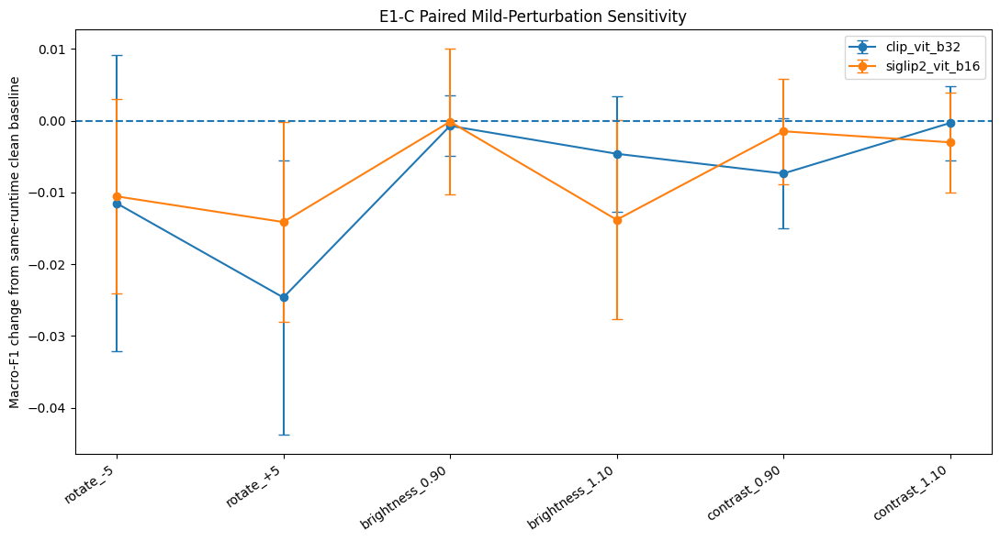


E1-C2 PAIRED ROBUSTNESS COMPLETE

Historical vs current compatibility:
          model  historical_mean_macro_f1  current_clean_mean_macro_f1  current_clean_sd_macro_f1  mean_prediction_agreement  max_prediction_disagreements
   clip_vit_b32                  0.830258                     0.829275                   0.008234                   0.995775                             2
siglip2_vit_b16                  0.820179                     0.817953                   0.016799                   0.994366                             3

Robustness:
          model  current_clean_mean_macro_f1  mean_perturbed_macro_f1  mean_delta_from_clean  mean_worst_case_macro_f1  mean_worst_case_delta
   clip_vit_b32                     0.829275                 0.821088              -0.008187                  0.799830              -0.029446
siglip2_vit_b16                     0.817953                 0.810774              -0.007179                  0.792901              -0.025052

Figure: /content/drive/

In [ ]:
# ==================================================================================================
# DOAR E1-C2 — CROSS-RUNTIME COMPATIBILITY AUDIT + PAIRED ROBUSTNESS
#
# IMPORTANT SCIENTIFIC SEPARATION
# --------------------------------
# E1-B / E1-C1:
#   Historical saved predictions and metrics remain the model-selection evidence.
#
# E1-C2:
#   Robustness uses a NEW clean replay baseline in the SAME current runtime as
#   the perturbed images. Robustness is measured as paired delta from that baseline.
#
# NO TRAINING.
# NO TEST ACCESS.
# ==================================================================================================

import gc
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    balanced_accuracy_score,
)

# --------------------------------------------------------------------------------------------------
# Standardize current E1-C2 replay
# --------------------------------------------------------------------------------------------------

ROBUSTNESS_BATCH_SIZE = 16

# Make "FP32" explicit.
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

try:
    torch.set_float32_matmul_precision("highest")
except Exception:
    pass

torch.backends.cudnn.benchmark = False

# Compatibility gates defined BEFORE looking at row-level results for all 10 checkpoints.
MIN_PREDICTION_AGREEMENT = 0.98
MAX_MACRO_F1_DRIFT = 0.01

AUDIT_DIR = OUT_ROOT / "audits"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 110)
print("DOAR E1-C2 — CROSS-RUNTIME COMPATIBILITY + PAIRED ROBUSTNESS")
print("=" * 110)

print("Models:", MODELS)
print("Seeds :", SEEDS)
print("Current replay precision: FP32, TF32 disabled")
print("Compatibility requirement:")
print(f"  prediction agreement >= {MIN_PREDICTION_AGREEMENT*100:.1f}%")
print(f"  |Macro-F1 drift|      <  {MAX_MACRO_F1_DRIFT:.3f}")
print("Training: NONE")
print("Test: LOCKED")


# ==================================================================================================
# 1. CURRENT-RUNTIME FP32 EVALUATION
# ==================================================================================================

def evaluate_fp32(model, loader):

    model.eval()

    all_labels = []
    all_ids = []
    all_probs = []

    with torch.inference_mode():

        for images, labels, ids in loader:

            images = images.to(
                DEVICE,
                dtype=torch.float32,
                non_blocking=True,
            )

            logits = model(images)

            probs = (
                torch.softmax(logits, dim=1)
                .cpu()
                .numpy()
            )

            all_probs.append(probs)

            all_labels.extend(labels.tolist())
            all_ids.extend([str(x) for x in ids])

    probs = np.concatenate(all_probs, axis=0)

    labels = np.asarray(
        all_labels,
        dtype=np.int64,
    )

    preds = np.argmax(
        probs,
        axis=1,
    )

    return {
        "image_ids": np.asarray(all_ids),
        "labels": labels,
        "predictions": preds,
        "probabilities": probs,
        "macro_f1": float(
            f1_score(
                labels,
                preds,
                average="macro",
                zero_division=0,
            )
        ),
        "accuracy": float(
            accuracy_score(
                labels,
                preds,
            )
        ),
        "balanced_accuracy": float(
            balanced_accuracy_score(
                labels,
                preds,
            )
        ),
    }


# ==================================================================================================
# 2. CROSS-RUNTIME COMPATIBILITY AUDIT FOR ALL 10 CHECKPOINTS
# ==================================================================================================

compatibility_rows = []
current_clean_frames = []

print()
print("=" * 110)
print("CROSS-RUNTIME COMPATIBILITY AUDIT")
print("=" * 110)


for model_key in MODELS:

    print()
    print(model_key)

    model, native_eval = build_evaluation_model(
        model_key
    )

    model = model.to(DEVICE)

    dataset = RobustnessDataset(
        valid_rows,
        native_eval,
        "clean",
    )

    loader = DataLoader(
        dataset,
        batch_size=ROBUSTNESS_BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )

    for seed in SEEDS:

        run_dir = locate_run_directory(
            model_key,
            seed,
        )

        checkpoint = torch.load(
            run_dir / "best.pt",
            map_location=DEVICE,
            weights_only=False,
        )

        model.load_state_dict(
            checkpoint["model_state"],
            strict=True,
        )

        current = evaluate_fp32(
            model,
            loader,
        )

        # ------------------------------------------------------------------------------------------
        # Historical saved predictions
        # ------------------------------------------------------------------------------------------

        saved = pd.read_csv(
            run_dir / "best_valid_predictions.csv"
        )

        saved["image_id"] = (
            saved["image_id"]
            .astype(str)
        )

        if (
            "prediction" in saved.columns
            and
            "predicted_class" not in saved.columns
        ):
            saved = saved.rename(
                columns={
                    "prediction": "predicted_class"
                }
            )

        assert len(saved) == 284

        historical_f1 = float(
            f1_score(
                saved["true_class"],
                saved["predicted_class"],
                average="macro",
                zero_division=0,
            )
        )

        # ------------------------------------------------------------------------------------------
        # Current predictions
        # ------------------------------------------------------------------------------------------

        current_frame = pd.DataFrame(
            {
                "image_id":
                    current["image_ids"],

                "true_class":
                    [
                        CLASSES[i]
                        for i in current["labels"]
                    ],

                "current_prediction":
                    [
                        CLASSES[i]
                        for i in current["predictions"]
                    ],
            }
        )

        for class_index, class_name in enumerate(CLASSES):

            current_frame[
                f"current_prob_{class_name}"
            ] = (
                current["probabilities"][:, class_index]
            )

        comparison = (
            saved[
                [
                    "image_id",
                    "true_class",
                    "predicted_class",
                ]
            ]
            .rename(
                columns={
                    "predicted_class":
                        "historical_prediction"
                }
            )
            .merge(
                current_frame,
                on=[
                    "image_id",
                    "true_class",
                ],
                how="inner",
                validate="one_to_one",
            )
        )

        assert len(comparison) == 284

        disagreements = int(
            (
                comparison["historical_prediction"]
                !=
                comparison["current_prediction"]
            ).sum()
        )

        agreement = (
            1.0
            -
            disagreements / 284.0
        )

        f1_drift = (
            current["macro_f1"]
            -
            historical_f1
        )

        passed = (
            agreement
            >= MIN_PREDICTION_AGREEMENT
            and
            abs(f1_drift)
            < MAX_MACRO_F1_DRIFT
        )

        compatibility_rows.append(
            {
                "model":
                    model_key,

                "seed":
                    seed,

                "historical_macro_f1":
                    historical_f1,

                "current_clean_macro_f1":
                    current["macro_f1"],

                "macro_f1_drift":
                    f1_drift,

                "prediction_disagreements":
                    disagreements,

                "prediction_agreement":
                    agreement,

                "compatibility_pass":
                    passed,
            }
        )

        current_frame["model"] = model_key
        current_frame["seed"] = seed

        current_clean_frames.append(
            current_frame
        )

        comparison.to_csv(
            AUDIT_DIR
            / (
                f"{model_key}__seed_{seed}"
                "__historical_vs_current.csv"
            ),
            index=False,
        )

        print(
            f"  seed {seed:<3} | "
            f"historical={historical_f1:.6f} | "
            f"current={current['macro_f1']:.6f} | "
            f"delta={f1_drift:+.6f} | "
            f"changed={disagreements:>2}/284 | "
            f"agreement={agreement*100:5.2f}% | "
            f"{'PASS' if passed else 'FAIL'}"
        )

    del model
    del dataset
    del loader

    gc.collect()
    torch.cuda.empty_cache()


compatibility_df = pd.DataFrame(
    compatibility_rows
)

compatibility_df.to_csv(
    TABLE_DIR
    / "E1C2_T13_CROSS_RUNTIME_COMPATIBILITY.csv",
    index=False,
)


current_clean_predictions = pd.concat(
    current_clean_frames,
    ignore_index=True,
)

current_clean_predictions.to_csv(
    TABLE_DIR
    / "E1C2_T14_CURRENT_RUNTIME_CLEAN_PREDICTIONS.csv",
    index=False,
)


print()
print("=" * 110)
print("COMPATIBILITY SUMMARY")
print("=" * 110)

print(
    compatibility_df.to_string(
        index=False
    )
)


failures = compatibility_df[
    ~compatibility_df[
        "compatibility_pass"
    ]
]


if len(failures) > 0:

    print()
    print(
        f"❌ {len(failures)} checkpoint(s) exceeded the predeclared compatibility gate."
    )

    print(
        "Robustness will NOT be run."
    )

    raise RuntimeError(
        "STOP: current-runtime replay drift is too large. "
        "Inspect compatibility failures before continuing."
    )


print()
print(
    "✓ ALL 10 CHECKPOINTS PASSED THE CROSS-RUNTIME COMPATIBILITY GATE."
)

print(
    "✓ Historical metrics remain the model-selection evidence."
)

print(
    "✓ Current clean replay will now be used ONLY as the paired robustness baseline."
)


# ==================================================================================================
# 3. SHOW CURRENT-RUNTIME CLEAN SUMMARY
# ==================================================================================================

current_clean_summary = (
    compatibility_df
    .groupby("model")
    .agg(
        historical_mean_macro_f1=(
            "historical_macro_f1",
            "mean"
        ),
        current_clean_mean_macro_f1=(
            "current_clean_macro_f1",
            "mean"
        ),
        current_clean_sd_macro_f1=(
            "current_clean_macro_f1",
            "std"
        ),
        mean_prediction_agreement=(
            "prediction_agreement",
            "mean"
        ),
        max_prediction_disagreements=(
            "prediction_disagreements",
            "max"
        ),
    )
    .reset_index()
)


current_clean_summary.to_csv(
    TABLE_DIR
    / "E1C2_T15_CURRENT_RUNTIME_CLEAN_SUMMARY.csv",
    index=False,
)


print()
print("=" * 110)
print("CURRENT-RUNTIME CLEAN SUMMARY")
print("=" * 110)

print(
    current_clean_summary.to_string(
        index=False
    )
)


# ==================================================================================================
# 4. PAIRED ROBUSTNESS IN THE SAME CURRENT RUNTIME
#
# Critical design:
#
# current clean checkpoint replay
#           versus
# same checkpoint + same runtime + same preprocessing + one perturbation
#
# We do NOT compare perturbations against historical E1-C1 scores.
# ==================================================================================================

robustness_rows = []
robustness_prediction_frames = []


for model_key in MODELS:

    print()
    print("=" * 110)
    print(
        "PAIRED ROBUSTNESS:",
        model_key
    )
    print("=" * 110)

    model, native_eval = build_evaluation_model(
        model_key
    )

    model = model.to(DEVICE)

    loaders = {}

    for condition in ROBUSTNESS_CONDITIONS:

        dataset = RobustnessDataset(
            valid_rows,
            native_eval,
            condition,
        )

        loaders[condition] = DataLoader(
            dataset,
            batch_size=
                ROBUSTNESS_BATCH_SIZE,

            shuffle=False,

            num_workers=
                NUM_WORKERS,

            pin_memory=True,
        )

    for seed in SEEDS:

        run_dir = locate_run_directory(
            model_key,
            seed,
        )

        checkpoint = torch.load(
            run_dir / "best.pt",
            map_location=DEVICE,
            weights_only=False,
        )

        model.load_state_dict(
            checkpoint["model_state"],
            strict=True,
        )

        results_for_seed = {}

        print()
        print(
            f"{model_key} | seed {seed}"
        )

        for condition in ROBUSTNESS_CONDITIONS:

            evaluation = evaluate_fp32(
                model,
                loaders[condition],
            )

            results_for_seed[
                condition
            ] = evaluation

        current_clean_f1 = (
            results_for_seed[
                "clean"
            ][
                "macro_f1"
            ]
        )

        for condition in ROBUSTNESS_CONDITIONS:

            evaluation = (
                results_for_seed[
                    condition
                ]
            )

            delta = (
                evaluation[
                    "macro_f1"
                ]
                -
                current_clean_f1
            )

            robustness_rows.append(
                {
                    "model":
                        model_key,

                    "seed":
                        seed,

                    "condition":
                        condition,

                    "precision":
                        "FP32_TF32_DISABLED",

                    "current_clean_macro_f1":
                        current_clean_f1,

                    "macro_f1":
                        evaluation[
                            "macro_f1"
                        ],

                    "macro_f1_delta_from_current_clean":
                        delta,

                    "accuracy":
                        evaluation[
                            "accuracy"
                        ],

                    "balanced_accuracy":
                        evaluation[
                            "balanced_accuracy"
                        ],
                }
            )

            pred_frame = pd.DataFrame(
                {
                    "model":
                        model_key,

                    "seed":
                        seed,

                    "condition":
                        condition,

                    "image_id":
                        evaluation[
                            "image_ids"
                        ],

                    "true_class":
                        [
                            CLASSES[i]
                            for i
                            in evaluation[
                                "labels"
                            ]
                        ],

                    "predicted_class":
                        [
                            CLASSES[i]
                            for i
                            in evaluation[
                                "predictions"
                            ]
                        ],
                }
            )

            for class_index, class_name in enumerate(
                CLASSES
            ):

                pred_frame[
                    f"prob_{class_name}"
                ] = (
                    evaluation[
                        "probabilities"
                    ][:, class_index]
                )

            robustness_prediction_frames.append(
                pred_frame
            )

            print(
                f"  {condition:<18} "
                f"F1={evaluation['macro_f1']:.4f} | "
                f"delta={delta:+.4f}"
            )

    del model
    del loaders

    gc.collect()
    torch.cuda.empty_cache()


robustness_metrics = pd.DataFrame(
    robustness_rows
)

robustness_predictions = pd.concat(
    robustness_prediction_frames,
    ignore_index=True,
)


robustness_metrics.to_csv(
    TABLE_DIR
    / "E1C2_T16_PAIRED_ROBUSTNESS_PER_SEED.csv",
    index=False,
)

robustness_predictions.to_csv(
    TABLE_DIR
    / "E1C2_T17_PAIRED_ROBUSTNESS_PREDICTIONS.csv",
    index=False,
)


# ==================================================================================================
# 5. CONDITION-LEVEL SUMMARY
# ==================================================================================================

robustness_summary = (
    robustness_metrics
    .groupby(
        [
            "model",
            "condition",
        ]
    )
    .agg(
        mean_macro_f1=(
            "macro_f1",
            "mean"
        ),

        sd_macro_f1=(
            "macro_f1",
            "std"
        ),

        mean_delta_from_clean=(
            "macro_f1_delta_from_current_clean",
            "mean"
        ),

        sd_delta_from_clean=(
            "macro_f1_delta_from_current_clean",
            "std"
        ),

        mean_accuracy=(
            "accuracy",
            "mean"
        ),

        mean_balanced_accuracy=(
            "balanced_accuracy",
            "mean"
        ),
    )
    .reset_index()
)


robustness_summary.to_csv(
    TABLE_DIR
    / "E1C2_T18_PAIRED_ROBUSTNESS_CONDITION_SUMMARY.csv",
    index=False,
)


# ==================================================================================================
# 6. OVERALL PERTURBATION SUMMARY
# ==================================================================================================

perturbed = robustness_metrics[
    robustness_metrics[
        "condition"
    ]
    != "clean"
].copy()


per_seed_robustness = (
    perturbed
    .groupby(
        [
            "model",
            "seed",
        ]
    )
    .agg(
        current_clean_macro_f1=(
            "current_clean_macro_f1",
            "first"
        ),

        mean_perturbed_macro_f1=(
            "macro_f1",
            "mean"
        ),

        worst_perturbed_macro_f1=(
            "macro_f1",
            "min"
        ),

        mean_delta_from_clean=(
            "macro_f1_delta_from_current_clean",
            "mean"
        ),

        worst_delta_from_clean=(
            "macro_f1_delta_from_current_clean",
            "min"
        ),
    )
    .reset_index()
)


overall_robustness = (
    per_seed_robustness
    .groupby("model")
    .agg(
        current_clean_mean_macro_f1=(
            "current_clean_macro_f1",
            "mean"
        ),

        mean_perturbed_macro_f1=(
            "mean_perturbed_macro_f1",
            "mean"
        ),

        mean_delta_from_clean=(
            "mean_delta_from_clean",
            "mean"
        ),

        mean_worst_case_macro_f1=(
            "worst_perturbed_macro_f1",
            "mean"
        ),

        mean_worst_case_delta=(
            "worst_delta_from_clean",
            "mean"
        ),
    )
    .reset_index()
)


per_seed_robustness.to_csv(
    TABLE_DIR
    / "E1C2_T19_PAIRED_ROBUSTNESS_PER_SEED_SUMMARY.csv",
    index=False,
)

overall_robustness.to_csv(
    TABLE_DIR
    / "E1C2_T20_PAIRED_ROBUSTNESS_OVERALL.csv",
    index=False,
)


print()
print("=" * 110)
print("PAIRED ROBUSTNESS SUMMARY")
print("=" * 110)

print(
    overall_robustness.to_string(
        index=False
    )
)


# ==================================================================================================
# 7. ROBUSTNESS FIGURE — DELTA FROM CURRENT CLEAN
# ==================================================================================================

perturbation_order = [
    condition
    for condition
    in ROBUSTNESS_CONDITIONS
    if condition != "clean"
]

x = np.arange(
    len(
        perturbation_order
    )
)

fig, ax = plt.subplots(
    figsize=(11, 6)
)


for model_key in MODELS:

    means = []
    errors = []

    for condition in perturbation_order:

        subset = robustness_metrics[
            (
                robustness_metrics[
                    "model"
                ]
                == model_key
            )
            &
            (
                robustness_metrics[
                    "condition"
                ]
                == condition
            )
        ]

        means.append(
            subset[
                "macro_f1_delta_from_current_clean"
            ].mean()
        )

        errors.append(
            subset[
                "macro_f1_delta_from_current_clean"
            ].std()
        )

    ax.errorbar(
        x,
        means,
        yerr=errors,
        marker="o",
        capsize=4,
        label=model_key,
    )


ax.axhline(
    0.0,
    linestyle="--",
)

ax.set_xticks(x)

ax.set_xticklabels(
    perturbation_order,
    rotation=35,
    ha="right",
)

ax.set_ylabel(
    "Macro-F1 change from same-runtime clean baseline"
)

ax.set_title(
    "E1-C Paired Mild-Perturbation Sensitivity"
)

ax.legend()

fig.tight_layout()


ROBUST_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

fig.savefig(
    ROBUST_DIR
    / "E1C2_F3_PAIRED_ROBUSTNESS_DELTA.png",
    dpi=250,
)

fig.savefig(
    ROBUST_DIR
    / "E1C2_F3_PAIRED_ROBUSTNESS_DELTA.pdf",
)

plt.show()

plt.close(fig)


# ==================================================================================================
# 8. DOCUMENT THE REPLAY ISSUE
# ==================================================================================================

provenance = {
    "experiment":
        "E1-C2 paired robustness",

    "training_performed":
        False,

    "historical_model_selection_metrics":
        (
            "E1-B/E1-C1 saved Validation predictions and result files. "
            "These remain unchanged."
        ),

    "cross_runtime_replay":
        (
            "Fresh-runtime checkpoint inference was not bit-exact "
            "with historical Validation predictions for every checkpoint."
        ),

    "compatibility_gate": {
        "minimum_prediction_agreement":
            MIN_PREDICTION_AGREEMENT,

        "maximum_absolute_macro_f1_drift":
            MAX_MACRO_F1_DRIFT,
    },

    "robustness_protocol":
        (
            "Each perturbation is compared against a clean replay "
            "of the same checkpoint in the same runtime, precision, "
            "batch size and preprocessing environment."
        ),

    "precision":
        "FP32 with TF32 disabled",

    "batch_size":
        ROBUSTNESS_BATCH_SIZE,

    "conditions":
        ROBUSTNESS_CONDITIONS,

    "models":
        MODELS,

    "seeds":
        SEEDS,

    "validation_n":
        284,

    "test_policy":
        (
            "Locked Test not loaded or evaluated."
        ),

    "interpretation":
        (
            "Robustness deltas are supporting sensitivity evidence. "
            "They do not replace historical E1-C1 model-selection scores."
        ),
}


(
    OUT_ROOT
    / "E1C2_CROSS_RUNTIME_PAIRED_ROBUSTNESS_PROVENANCE.json"
).write_text(
    json.dumps(
        provenance,
        indent=2,
    ),
    encoding="utf-8",
)


print()
print("=" * 110)
print("E1-C2 PAIRED ROBUSTNESS COMPLETE")
print("=" * 110)

print()
print("Historical vs current compatibility:")
print(
    current_clean_summary.to_string(
        index=False
    )
)

print()
print("Robustness:")
print(
    overall_robustness.to_string(
        index=False
    )
)

print()
print(
    "Figure:",
    ROBUST_DIR
    / "E1C2_F3_PAIRED_ROBUSTNESS_DELTA.png"
)

print()
print(
    "Tables:",
    TABLE_DIR
)

print()
print("✓ NO TRAINING PERFORMED.")
print("✓ HISTORICAL E1-C1 RESULTS NOT MODIFIED.")
print("✓ LOCKED TEST REMAINED UNTOUCHED.")

In [ ]:
# ==================================================================================================
# DOAR MASTER THESIS
# E1 FINAL FREEZE — LEARNED VISUAL REPRESENTATION SELECTION
#
# PURPOSE
# -------
# Close Experiment E1 and freeze the learned visual representation choice.
#
# THIS CELL:
#   1. Reads existing E1-C1 / E1-C2 results.
#   2. Verifies key evidence artifacts.
#   3. Recomputes the selection from saved result tables.
#   4. Creates SHA-256 hashes for provenance.
#   5. Writes:
#        - E1_FINAL_SELECTION.json
#        - E1_FINAL_SELECTION.md
#        - E1_FINAL_EVIDENCE_MANIFEST.csv
#   6. Does NOT train anything.
#   7. Does NOT load any dataset images.
#   8. Does NOT access/evaluate the locked Test set.
#
# AFTER THIS CELL:
#   E1 is considered FROZEN.
#   Do not modify the selected representation based on later Validation results.
#   Next experiments: E2 / E3.
# ==================================================================================================

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json

import numpy as np
import pandas as pd


# ==================================================================================================
# 1. PATHS
# ==================================================================================================

BASE = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1"
)

E1B_ROOT = BASE / "E1B"

E1C1_ROOT = BASE / "E1C_STABILITY"

E1C2_ROOT = BASE / "E1C_FINALIZATION"

FINAL_ROOT = BASE / "E1_FINAL"

FINAL_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


# ==================================================================================================
# 2. CORE EVIDENCE FILES
# ==================================================================================================

STABILITY_SUMMARY = (
    E1C1_ROOT
    / "tables"
    / "E1C_T2_5_SEED_STABILITY_SUMMARY.csv"
)

PAIRED_SEED_COMPARISON = (
    E1C1_ROOT
    / "tables"
    / "E1C_T3_PAIRED_SEED_COMPARISON.csv"
)

PAIRED_SEED_VALUES = (
    E1C1_ROOT
    / "tables"
    / "E1C_T4_PAIRED_SEED_VALUES.csv"
)

CALIBRATION_SUMMARY = (
    E1C2_ROOT
    / "tables"
    / "E1C2_T3_CALIBRATION_SUMMARY.csv"
)

ENSEMBLE_CONFUSION_SUMMARY = (
    E1C2_ROOT
    / "tables"
    / "E1C2_T5_ENSEMBLE_CONFUSION_SUMMARY.csv"
)

COMPATIBILITY = (
    E1C2_ROOT
    / "tables"
    / "E1C2_T13_CROSS_RUNTIME_COMPATIBILITY.csv"
)

CURRENT_CLEAN_SUMMARY = (
    E1C2_ROOT
    / "tables"
    / "E1C2_T15_CURRENT_RUNTIME_CLEAN_SUMMARY.csv"
)

ROBUSTNESS_CONDITION_SUMMARY = (
    E1C2_ROOT
    / "tables"
    / "E1C2_T18_PAIRED_ROBUSTNESS_CONDITION_SUMMARY.csv"
)

ROBUSTNESS_OVERALL = (
    E1C2_ROOT
    / "tables"
    / "E1C2_T20_PAIRED_ROBUSTNESS_OVERALL.csv"
)

ROBUSTNESS_PROVENANCE = (
    E1C2_ROOT
    / "E1C2_CROSS_RUNTIME_PAIRED_ROBUSTNESS_PROVENANCE.json"
)

PRECISION_AUDIT = (
    E1C2_ROOT
    / "audits"
    / "clip_partial_seed37_reproduction_summary.json"
)


# ==================================================================================================
# 3. REQUIRED VS SUPPORTING EVIDENCE
#
# REQUIRED:
# Must exist before E1 can be frozen.
#
# SUPPORTING:
# Valuable thesis evidence, but absence does not invalidate the selection itself.
# ==================================================================================================

required_artifacts = {
    "E1-C1 five-seed stability summary":
        STABILITY_SUMMARY,

    "E1-C1 paired-seed comparison":
        PAIRED_SEED_COMPARISON,

    "E1-C1 paired-seed values":
        PAIRED_SEED_VALUES,

    "E1-C2 cross-runtime compatibility":
        COMPATIBILITY,

    "E1-C2 current-runtime clean summary":
        CURRENT_CLEAN_SUMMARY,

    "E1-C2 robustness condition summary":
        ROBUSTNESS_CONDITION_SUMMARY,

    "E1-C2 overall paired robustness":
        ROBUSTNESS_OVERALL,

    "E1-C2 robustness provenance":
        ROBUSTNESS_PROVENANCE,
}


supporting_artifacts = {
    "E1-C2 calibration summary":
        CALIBRATION_SUMMARY,

    "E1-C2 ensemble confusion summary":
        ENSEMBLE_CONFUSION_SUMMARY,

    "E1-C2 seed-37 precision audit":
        PRECISION_AUDIT,
}


# ==================================================================================================
# 4. CHECK ARTIFACT EXISTENCE
# ==================================================================================================

print("=" * 110)
print("DOAR E1 FINAL FREEZE")
print("=" * 110)

print()
print("REQUIRED EVIDENCE")
print("-" * 110)

missing_required = []

for name, path in required_artifacts.items():

    if path.exists():

        print(
            f"✓ {name}"
        )

    else:

        print(
            f"❌ {name}"
        )

        print(
            f"   Missing: {path}"
        )

        missing_required.append(
            str(path)
        )


if missing_required:

    raise RuntimeError(
        "\nE1 FREEZE STOPPED.\n"
        "One or more REQUIRED evidence files are missing.\n"
        "Do not freeze the representation yet."
    )


print()
print("SUPPORTING EVIDENCE")
print("-" * 110)

for name, path in supporting_artifacts.items():

    if path.exists():

        print(
            f"✓ {name}"
        )

    else:

        print(
            f"⚠ {name} — not found; selection can still be frozen."
        )


# ==================================================================================================
# 5. LOAD E1-C1 FIVE-SEED STABILITY
# ==================================================================================================

stability = pd.read_csv(
    STABILITY_SUMMARY
)

required_stability_columns = {
    "model",
    "mean_macro_f1",
    "std_macro_f1",
    "min_macro_f1",
    "max_macro_f1",
}

assert required_stability_columns.issubset(
    stability.columns
), (
    "Unexpected E1-C1 stability-summary schema."
)


stability = stability.sort_values(
    "mean_macro_f1",
    ascending=False,
).reset_index(
    drop=True
)


print()
print("=" * 110)
print("E1-C1 FIVE-SEED FINALIST RESULTS")
print("=" * 110)

print(
    stability.to_string(
        index=False
    )
)


# ==================================================================================================
# 6. IDENTIFY FINALISTS
# ==================================================================================================

CLIP_KEY = "clip_vit_b32"
SIGLIP_KEY = "siglip2_vit_b16"


assert CLIP_KEY in set(
    stability["model"]
)

assert SIGLIP_KEY in set(
    stability["model"]
)


clip_stability = (
    stability[
        stability[
            "model"
        ]
        == CLIP_KEY
    ]
    .iloc[0]
)


siglip_stability = (
    stability[
        stability[
            "model"
        ]
        == SIGLIP_KEY
    ]
    .iloc[0]
)


# ==================================================================================================
# 7. LOAD PAIRED SEED EVIDENCE
# ==================================================================================================

paired = pd.read_csv(
    PAIRED_SEED_VALUES
)

assert "seed" in paired.columns
assert CLIP_KEY in paired.columns
assert SIGLIP_KEY in paired.columns


paired[
    "clip_minus_siglip"
] = (
    paired[
        CLIP_KEY
    ]
    -
    paired[
        SIGLIP_KEY
    ]
)


clip_seed_wins = int(
    (
        paired[
            "clip_minus_siglip"
        ]
        > 0
    ).sum()
)


siglip_seed_wins = int(
    (
        paired[
            "clip_minus_siglip"
        ]
        < 0
    ).sum()
)


paired_seed_count = int(
    len(
        paired
    )
)


paired_mean_delta = float(
    paired[
        "clip_minus_siglip"
    ].mean()
)


# ==================================================================================================
# 8. LOAD DESCRIPTIVE BOOTSTRAP RESULT
# ==================================================================================================

paired_comparison = pd.read_csv(
    PAIRED_SEED_COMPARISON
)


bootstrap_ci_low = None
bootstrap_ci_high = None
bootstrap_probability_positive = None


if len(
    paired_comparison
) > 0:

    row = paired_comparison.iloc[0]

    if (
        "bootstrap_95_ci_low"
        in paired_comparison.columns
    ):

        bootstrap_ci_low = float(
            row[
                "bootstrap_95_ci_low"
            ]
        )

    if (
        "bootstrap_95_ci_high"
        in paired_comparison.columns
    ):

        bootstrap_ci_high = float(
            row[
                "bootstrap_95_ci_high"
            ]
        )

    if (
        "bootstrap_probability_difference_gt_0"
        in paired_comparison.columns
    ):

        bootstrap_probability_positive = float(
            row[
                "bootstrap_probability_difference_gt_0"
            ]
        )


# ==================================================================================================
# 9. LOAD CROSS-RUNTIME COMPATIBILITY
# ==================================================================================================

compatibility = pd.read_csv(
    COMPATIBILITY
)


assert len(
    compatibility
) == 10, (
    "Expected 10 finalist checkpoint compatibility rows."
)


assert (
    compatibility[
        "compatibility_pass"
    ]
    .astype(bool)
    .all()
), (
    "Not all 10 checkpoints passed the E1-C2 compatibility gate."
)


compatibility_summary = (
    compatibility
    .groupby(
        "model"
    )
    .agg(
        mean_prediction_agreement=(
            "prediction_agreement",
            "mean"
        ),

        min_prediction_agreement=(
            "prediction_agreement",
            "min"
        ),

        max_prediction_disagreements=(
            "prediction_disagreements",
            "max"
        ),

        max_absolute_macro_f1_drift=(
            "macro_f1_drift",
            lambda x:
                np.max(
                    np.abs(
                        x
                    )
                )
        ),
    )
    .reset_index()
)


# ==================================================================================================
# 10. LOAD CURRENT-RUNTIME CLEAN SUMMARY
# ==================================================================================================

current_clean = pd.read_csv(
    CURRENT_CLEAN_SUMMARY
)


clip_clean = (
    current_clean[
        current_clean[
            "model"
        ]
        == CLIP_KEY
    ]
    .iloc[0]
)


siglip_clean = (
    current_clean[
        current_clean[
            "model"
        ]
        == SIGLIP_KEY
    ]
    .iloc[0]
)


# ==================================================================================================
# 11. LOAD PAIRED ROBUSTNESS
# ==================================================================================================

robustness = pd.read_csv(
    ROBUSTNESS_OVERALL
)


clip_robustness = (
    robustness[
        robustness[
            "model"
        ]
        == CLIP_KEY
    ]
    .iloc[0]
)


siglip_robustness = (
    robustness[
        robustness[
            "model"
        ]
        == SIGLIP_KEY
    ]
    .iloc[0]
)


# ==================================================================================================
# 12. LOAD CALIBRATION IF AVAILABLE
# ==================================================================================================

calibration_record = {
    "available":
        False
}


if CALIBRATION_SUMMARY.exists():

    calibration = pd.read_csv(
        CALIBRATION_SUMMARY
    )

    calibration_record[
        "available"
    ] = True

    calibration_record[
        "table_path"
    ] = str(
        CALIBRATION_SUMMARY
    )

    calibration_record[
        "rows"
    ] = (
        calibration
        .to_dict(
            orient="records"
        )
    )


# ==================================================================================================
# 13. LOAD CONFUSION SUMMARY IF AVAILABLE
# ==================================================================================================

confusion_record = {
    "available":
        False
}


if ENSEMBLE_CONFUSION_SUMMARY.exists():

    confusion_summary = pd.read_csv(
        ENSEMBLE_CONFUSION_SUMMARY
    )

    confusion_record[
        "available"
    ] = True

    confusion_record[
        "table_path"
    ] = str(
        ENSEMBLE_CONFUSION_SUMMARY
    )

    confusion_record[
        "rows"
    ] = (
        confusion_summary
        .to_dict(
            orient="records"
        )
    )


# ==================================================================================================
# 14. DISCOVER FIGURES / QUALITATIVE PANELS
# ==================================================================================================

confusion_dir = (
    E1C2_ROOT
    / "figures"
    / "confusion_matrices"
)

robustness_dir = (
    E1C2_ROOT
    / "figures"
    / "robustness"
)

e1c2_qualitative_dir = (
    E1C2_ROOT
    / "qualitative"
)

e1b_qualitative_dir = (
    E1B_ROOT
    / "qualitative"
)


confusion_pngs = (
    sorted(
        confusion_dir.glob(
            "*.png"
        )
    )
    if confusion_dir.exists()
    else []
)


robustness_pngs = (
    sorted(
        robustness_dir.glob(
            "*.png"
        )
    )
    if robustness_dir.exists()
    else []
)


e1c2_qualitative_pngs = (
    sorted(
        e1c2_qualitative_dir.glob(
            "*.png"
        )
    )
    if e1c2_qualitative_dir.exists()
    else []
)


e1b_qualitative_pngs = (
    sorted(
        e1b_qualitative_dir.glob(
            "*.png"
        )
    )
    if e1b_qualitative_dir.exists()
    else []
)


print()
print("=" * 110)
print("VISUAL EVIDENCE INVENTORY")
print("=" * 110)

print(
    "Confusion-matrix PNGs:",
    len(
        confusion_pngs
    )
)

print(
    "Robustness PNGs:",
    len(
        robustness_pngs
    )
)

print(
    "E1-C2 final qualitative PNGs:",
    len(
        e1c2_qualitative_pngs
    )
)

print(
    "E1-B qualitative PNGs:",
    len(
        e1b_qualitative_pngs
    )
)


if len(
    e1c2_qualitative_pngs
) == 0:

    print()
    print(
        "NOTE: No E1-C2 five-seed finalist qualitative panels were found."
    )

    print(
        "This does NOT block the E1 representation freeze."
    )

    print(
        "The fixed E1-B qualitative examples remain supporting visual evidence."
    )


# ==================================================================================================
# 15. SELECTION RULE
#
# We do NOT select based on one seed or robustness alone.
#
# Primary:
#   highest repeated-seed Validation Macro-F1
#
# Supporting:
#   lower variance
#   paired-seed wins
#   robustness absolute performance
#   compatibility / reproducibility
# ==================================================================================================

clip_mean = float(
    clip_stability[
        "mean_macro_f1"
    ]
)

siglip_mean = float(
    siglip_stability[
        "mean_macro_f1"
    ]
)


clip_sd = float(
    clip_stability[
        "std_macro_f1"
    ]
)

siglip_sd = float(
    siglip_stability[
        "std_macro_f1"
    ]
)


assert (
    clip_mean
    >
    siglip_mean
), (
    "Freeze rule failed: CLIP is no longer the repeated-seed leader."
)


assert (
    clip_seed_wins
    >
    siglip_seed_wins
), (
    "Freeze rule failed: CLIP did not win the majority of paired seeds."
)


clip_robust_mean = float(
    clip_robustness[
        "mean_perturbed_macro_f1"
    ]
)

siglip_robust_mean = float(
    siglip_robustness[
        "mean_perturbed_macro_f1"
    ]
)


assert (
    clip_robust_mean
    >
    siglip_robust_mean
), (
    "Freeze rule failed: CLIP did not maintain higher absolute "
    "mean perturbed Macro-F1."
)


FINAL_MODEL = CLIP_KEY

FINAL_DISPLAY_NAME = (
    "CLIP ViT-B/32"
)

FINAL_MODE = (
    "partial"
)

FINAL_VISUAL_TRAINABLE_PERCENT = (
    32.722250
)


# ==================================================================================================
# 16. HASH FUNCTION
# ==================================================================================================

def sha256_file(
    path,
):

    hasher = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as file:

        for chunk in iter(
            lambda:
                file.read(
                    1024 * 1024
                ),
            b"",
        ):

            hasher.update(
                chunk
            )

    return hasher.hexdigest()


# ==================================================================================================
# 17. BUILD EVIDENCE MANIFEST
# ==================================================================================================

manifest_rows = []


all_known_artifacts = {}


all_known_artifacts.update(
    required_artifacts
)

all_known_artifacts.update(
    supporting_artifacts
)


for name, path in (
    all_known_artifacts.items()
):

    exists = path.exists()

    manifest_rows.append(
        {
            "evidence_name":
                name,

            "path":
                str(
                    path
                ),

            "exists":
                exists,

            "sha256":
                (
                    sha256_file(
                        path
                    )
                    if exists
                    else None
                ),

            "size_bytes":
                (
                    path.stat().st_size
                    if exists
                    else None
                ),
        }
    )


# Add visual artifacts.
for category, paths in [
    (
        "confusion_matrix",
        confusion_pngs
    ),
    (
        "robustness_figure",
        robustness_pngs
    ),
    (
        "E1C2_qualitative",
        e1c2_qualitative_pngs
    ),
    (
        "E1B_qualitative",
        e1b_qualitative_pngs
    ),
]:

    for path in paths:

        manifest_rows.append(
            {
                "evidence_name":
                    f"{category}: {path.name}",

                "path":
                    str(
                        path
                    ),

                "exists":
                    True,

                "sha256":
                    sha256_file(
                        path
                    ),

                "size_bytes":
                    path.stat().st_size,
            }
        )


evidence_manifest = pd.DataFrame(
    manifest_rows
)


MANIFEST_PATH = (
    FINAL_ROOT
    / "E1_FINAL_EVIDENCE_MANIFEST.csv"
)


evidence_manifest.to_csv(
    MANIFEST_PATH,
    index=False,
)


# ==================================================================================================
# 18. FINAL SELECTION RECORD
# ==================================================================================================

selection_record = {
    "status":
        "FROZEN",

    "experiment":
        "E1 Learned Visual Representation",

    "freeze_timestamp_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "selected_representation": {
        "model_key":
            FINAL_MODEL,

        "display_name":
            FINAL_DISPLAY_NAME,

        "adaptation":
            "Partial visual fine-tuning",

        "mode_key":
            FINAL_MODE,

        "visual_trainable_percent":
            FINAL_VISUAL_TRAINABLE_PERCENT,
    },

    "primary_selection_metric":
        "Validation Macro-F1",

    "selection_protocol": {
        "validation_n":
            284,

        "paired_training_seeds":
            [
                11,
                19,
                37,
                42,
                73,
            ],

        "number_of_seeds":
            paired_seed_count,

        "test_policy":
            (
                "Locked Test remains unopened for model selection. "
                "This freeze cell does not load dataset images or Test data."
            ),
    },

    "E1C1_repeated_seed_evidence": {
        "clip_partial_mean_macro_f1":
            clip_mean,

        "clip_partial_sd_macro_f1":
            clip_sd,

        "clip_partial_min_macro_f1":
            float(
                clip_stability[
                    "min_macro_f1"
                ]
            ),

        "clip_partial_max_macro_f1":
            float(
                clip_stability[
                    "max_macro_f1"
                ]
            ),

        "siglip_partial_mean_macro_f1":
            siglip_mean,

        "siglip_partial_sd_macro_f1":
            siglip_sd,

        "paired_mean_clip_minus_siglip":
            paired_mean_delta,

        "clip_seed_wins":
            clip_seed_wins,

        "siglip_seed_wins":
            siglip_seed_wins,

        "paired_seed_count":
            paired_seed_count,

        "descriptive_seed_bootstrap_95_ci":
            [
                bootstrap_ci_low,
                bootstrap_ci_high,
            ],

        "bootstrap_probability_delta_gt_zero":
            bootstrap_probability_positive,

        "statistical_interpretation":
            (
                "The bootstrap is descriptive over five training seeds. "
                "The interval may cross zero and is not treated as "
                "definitive inferential proof of universal superiority."
            ),
    },

    "E1C2_cross_runtime_compatibility": {
        "all_10_checkpoints_passed":
            True,

        "compatibility_gate":
            {
                "minimum_prediction_agreement":
                    0.98,

                "maximum_absolute_macro_f1_drift":
                    0.01,
            },

        "rows":
            compatibility_summary.to_dict(
                orient="records"
            ),

        "interpretation":
            (
                "Fresh-runtime checkpoint replay was not bit-exact "
                "for every borderline Validation prediction. "
                "Historical E1-C1 predictions remain the model-selection "
                "evidence; same-runtime clean replay was used only as "
                "the paired robustness baseline."
            ),
    },

    "E1C2_robustness": {
        "clip_current_clean_mean_macro_f1":
            float(
                clip_robustness[
                    "current_clean_mean_macro_f1"
                ]
            ),

        "clip_mean_perturbed_macro_f1":
            float(
                clip_robustness[
                    "mean_perturbed_macro_f1"
                ]
            ),

        "clip_mean_delta_from_clean":
            float(
                clip_robustness[
                    "mean_delta_from_clean"
                ]
            ),

        "clip_mean_worst_case_macro_f1":
            float(
                clip_robustness[
                    "mean_worst_case_macro_f1"
                ]
            ),

        "clip_mean_worst_case_delta":
            float(
                clip_robustness[
                    "mean_worst_case_delta"
                ]
            ),

        "siglip_current_clean_mean_macro_f1":
            float(
                siglip_robustness[
                    "current_clean_mean_macro_f1"
                ]
            ),

        "siglip_mean_perturbed_macro_f1":
            float(
                siglip_robustness[
                    "mean_perturbed_macro_f1"
                ]
            ),

        "siglip_mean_delta_from_clean":
            float(
                siglip_robustness[
                    "mean_delta_from_clean"
                ]
            ),

        "siglip_mean_worst_case_macro_f1":
            float(
                siglip_robustness[
                    "mean_worst_case_macro_f1"
                ]
            ),

        "siglip_mean_worst_case_delta":
            float(
                siglip_robustness[
                    "mean_worst_case_delta"
                ]
            ),

        "interpretation":
            (
                "Both finalists showed modest average degradation under "
                "the tested mild deterministic perturbations. "
                "CLIP retained the higher absolute perturbed Macro-F1. "
                "Rotation sensitivity remains a documented limitation."
            ),
    },

    "calibration":
        calibration_record,

    "confusion_matrix":
        confusion_record,

    "visual_evidence_inventory": {
        "confusion_matrix_png_count":
            len(
                confusion_pngs
            ),

        "robustness_png_count":
            len(
                robustness_pngs
            ),

        "E1C2_final_qualitative_png_count":
            len(
                e1c2_qualitative_pngs
            ),

        "E1B_qualitative_png_count":
            len(
                e1b_qualitative_pngs
            ),
    },

    "final_decision": (
        "CLIP ViT-B/32 with partial visual fine-tuning is frozen "
        "as the learned visual representation for downstream DOAR "
        "experiments."
    ),

    "selection_rationale": [
        (
            "Highest repeated-seed Validation Macro-F1 among "
            "the E1-C finalists."
        ),

        (
            "Lower seed-to-seed variability than SigLIP2 Partial."
        ),

        (
            "Won the majority of matched training seeds."
        ),

        (
            "Maintained higher absolute Macro-F1 under the evaluated "
            "mild perturbations."
        ),

        (
            "All finalist checkpoints passed the documented "
            "cross-runtime compatibility gate."
        ),
    ],

    "limitations": [
        (
            "The four-emotion benchmark validates learned visual "
            "representation performance; it does not establish "
            "psychological or diagnostic validity."
        ),

        (
            "The five-seed comparison is descriptive and does not "
            "prove universal statistical superiority."
        ),

        (
            "Validation data were used for model selection, so "
            "calibration and error analyses on Validation are "
            "supporting rather than independent confirmatory evidence."
        ),

        (
            "Cross-runtime inference can change a small number of "
            "borderline class decisions."
        ),

        (
            "Mild rotations produced larger degradation than "
            "brightness/contrast changes for some seeds."
        ),
    ],

    "locked_test": {
        "status":
            "LOCKED",

        "used_for_selection":
            False,

        "evaluated_by_this_cell":
            False,

        "instruction":
            (
                "Do not use Test results to alter the frozen "
                "representation selection."
            ),
    },

    "next_stage": {
        "E2":
            (
                "Objective/interpretable drawing characteristics "
                "and measurable visual evidence."
            ),

        "E3":
            (
                "Semantic/object evidence and perception verification."
            ),
    },

    "evidence_manifest":
        str(
            MANIFEST_PATH
        ),
}


# ==================================================================================================
# 19. WRITE FINAL JSON
# ==================================================================================================

FINAL_JSON = (
    FINAL_ROOT
    / "E1_FINAL_SELECTION.json"
)


FINAL_JSON.write_text(
    json.dumps(
        selection_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ==================================================================================================
# 20. WRITE HUMAN-READABLE MARKDOWN
# ==================================================================================================

bootstrap_text = (
    "not available"
)

if (
    bootstrap_ci_low is not None
    and
    bootstrap_ci_high is not None
):

    bootstrap_text = (
        f"[{bootstrap_ci_low:+.4f}, "
        f"{bootstrap_ci_high:+.4f}]"
    )


markdown = f"""
# DOAR E1 Final Representation Freeze

## Status

**FROZEN**

## Selected learned visual representation

**{FINAL_DISPLAY_NAME} — Partial visual fine-tuning**

Visual encoder trainable parameters: approximately **{FINAL_VISUAL_TRAINABLE_PERCENT:.2f}%**

## Primary E1-C1 evidence

| Measure | CLIP Partial | SigLIP2 Partial |
|---|---:|---:|
| 5-seed mean Validation Macro-F1 | {clip_mean:.6f} | {siglip_mean:.6f} |
| SD | {clip_sd:.6f} | {siglip_sd:.6f} |
| Paired seed wins | {clip_seed_wins}/{paired_seed_count} | {siglip_seed_wins}/{paired_seed_count} |

Mean paired CLIP − SigLIP2 difference: **{paired_mean_delta:+.6f}**

Descriptive seed-bootstrap 95% interval: **{bootstrap_text}**

The bootstrap is descriptive over only five training seeds and is not treated as
definitive inferential evidence of universal superiority.

## E1-C2 paired robustness

| Measure | CLIP Partial | SigLIP2 Partial |
|---|---:|---:|
| Current-runtime clean mean Macro-F1 | {float(clip_robustness['current_clean_mean_macro_f1']):.6f} | {float(siglip_robustness['current_clean_mean_macro_f1']):.6f} |
| Mean perturbed Macro-F1 | {float(clip_robustness['mean_perturbed_macro_f1']):.6f} | {float(siglip_robustness['mean_perturbed_macro_f1']):.6f} |
| Mean change from clean | {float(clip_robustness['mean_delta_from_clean']):+.6f} | {float(siglip_robustness['mean_delta_from_clean']):+.6f} |
| Mean worst-case Macro-F1 | {float(clip_robustness['mean_worst_case_macro_f1']):.6f} | {float(siglip_robustness['mean_worst_case_macro_f1']):.6f} |
| Mean worst-case change | {float(clip_robustness['mean_worst_case_delta']):+.6f} | {float(siglip_robustness['mean_worst_case_delta']):+.6f} |

All 10 finalist checkpoints passed the documented cross-runtime compatibility gate.

## Final decision

CLIP ViT-B/32 with partial visual fine-tuning is frozen as the learned visual
representation for downstream DOAR experiments.

The decision is based primarily on repeated-seed Validation Macro-F1 and is
supported by lower seed-to-seed variability, paired-seed wins, and higher
absolute performance under the evaluated mild perturbations.

## Important interpretation

The Angry / Fear / Happy / Sad benchmark is a controlled visual-representation
experiment. It does **not** establish psychological or diagnostic validity.

## Locked Test

**LOCKED.**

The locked Test set was not evaluated by this freeze cell and was not used to
change the representation selection.

## Next stage

E1 is closed.

Proceed to:

1. **E2 — Objective/interpretable drawing characteristics**
2. **E3 — Semantic/object evidence and perception verification**

Evidence manifest:

`{MANIFEST_PATH}`
"""


FINAL_MD = (
    FINAL_ROOT
    / "E1_FINAL_SELECTION.md"
)


FINAL_MD.write_text(
    markdown.strip()
    + "\n",
    encoding="utf-8",
)


# ==================================================================================================
# 21. CREATE SMALL FINAL SUMMARY CSV
# ==================================================================================================

final_summary = pd.DataFrame(
    [
        {
            "selected":
                True,

            "model":
                CLIP_KEY,

            "display_name":
                FINAL_DISPLAY_NAME,

            "mode":
                "partial",

            "visual_trainable_percent":
                FINAL_VISUAL_TRAINABLE_PERCENT,

            "five_seed_mean_macro_f1":
                clip_mean,

            "five_seed_sd_macro_f1":
                clip_sd,

            "paired_seed_wins":
                clip_seed_wins,

            "paired_seed_total":
                paired_seed_count,

            "current_clean_mean_macro_f1":
                float(
                    clip_robustness[
                        "current_clean_mean_macro_f1"
                    ]
                ),

            "mean_perturbed_macro_f1":
                float(
                    clip_robustness[
                        "mean_perturbed_macro_f1"
                    ]
                ),

            "mean_robustness_delta":
                float(
                    clip_robustness[
                        "mean_delta_from_clean"
                    ]
                ),
        },

        {
            "selected":
                False,

            "model":
                SIGLIP_KEY,

            "display_name":
                "SigLIP2 ViT-B/16",

            "mode":
                "partial",

            "visual_trainable_percent":
                30.523470,

            "five_seed_mean_macro_f1":
                siglip_mean,

            "five_seed_sd_macro_f1":
                siglip_sd,

            "paired_seed_wins":
                siglip_seed_wins,

            "paired_seed_total":
                paired_seed_count,

            "current_clean_mean_macro_f1":
                float(
                    siglip_robustness[
                        "current_clean_mean_macro_f1"
                    ]
                ),

            "mean_perturbed_macro_f1":
                float(
                    siglip_robustness[
                        "mean_perturbed_macro_f1"
                    ]
                ),

            "mean_robustness_delta":
                float(
                    siglip_robustness[
                        "mean_delta_from_clean"
                    ]
                ),
        },
    ]
)


FINAL_SUMMARY_CSV = (
    FINAL_ROOT
    / "E1_FINAL_SELECTION_SUMMARY.csv"
)


final_summary.to_csv(
    FINAL_SUMMARY_CSV,
    index=False,
)


# ==================================================================================================
# 22. FINAL VERIFICATION
# ==================================================================================================

assert FINAL_JSON.exists()
assert FINAL_MD.exists()
assert MANIFEST_PATH.exists()
assert FINAL_SUMMARY_CSV.exists()


saved_json = json.loads(
    FINAL_JSON.read_text(
        encoding="utf-8"
    )
)


assert (
    saved_json[
        "status"
    ]
    == "FROZEN"
)


assert (
    saved_json[
        "selected_representation"
    ][
        "model_key"
    ]
    == CLIP_KEY
)


assert (
    saved_json[
        "locked_test"
    ][
        "evaluated_by_this_cell"
    ]
    is False
)


# ==================================================================================================
# 23. FINAL OUTPUT
# ==================================================================================================

print()
print("=" * 110)
print("E1 FINAL FREEZE COMPLETE")
print("=" * 110)

print()
print(
    "SELECTED REPRESENTATION:"
)

print(
    f"  {FINAL_DISPLAY_NAME}"
)

print(
    "  Partial visual fine-tuning"
)

print(
    f"  Visual trainable ≈ "
    f"{FINAL_VISUAL_TRAINABLE_PERCENT:.2f}%"
)


print()
print(
    "E1-C1 FIVE-SEED PERFORMANCE:"
)

print(
    f"  Macro-F1 = "
    f"{clip_mean:.6f} ± "
    f"{clip_sd:.6f}"
)

print(
    f"  Paired wins = "
    f"{clip_seed_wins}/"
    f"{paired_seed_count}"
)


print()
print(
    "E1-C2 ROBUSTNESS:"
)

print(
    f"  Current clean mean = "
    f"{float(clip_robustness['current_clean_mean_macro_f1']):.6f}"
)

print(
    f"  Mean perturbed     = "
    f"{float(clip_robustness['mean_perturbed_macro_f1']):.6f}"
)

print(
    f"  Mean delta         = "
    f"{float(clip_robustness['mean_delta_from_clean']):+.6f}"
)


print()
print(
    "✓ ALL REQUIRED E1 EVIDENCE VERIFIED."
)

print(
    "✓ EVIDENCE SHA-256 MANIFEST CREATED."
)

print(
    "✓ E1 REPRESENTATION STATUS = FROZEN."
)

print(
    "✓ NO TRAINING PERFORMED."
)

print(
    "✓ NO DATASET IMAGES LOADED."
)

print(
    "✓ LOCKED TEST NOT EVALUATED."
)


print()
print(
    "Final files:"
)

print(
    "  JSON    :",
    FINAL_JSON
)

print(
    "  Markdown:",
    FINAL_MD
)

print(
    "  Summary :",
    FINAL_SUMMARY_CSV
)

print(
    "  Manifest:",
    MANIFEST_PATH
)


print()
print("=" * 110)
print("NEXT SCIENTIFIC STAGE")
print("=" * 110)

print(
    "E2 — Objective/interpretable drawing characteristics"
)

print(
    "E3 — Semantic/object evidence and perception verification"
)

print()
print(
    "Do not reopen E1 architecture/model selection "
    "based on later Validation observations."
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DOAR E1 FINAL FREEZE

REQUIRED EVIDENCE
--------------------------------------------------------------------------------------------------------------
✓ E1-C1 five-seed stability summary
✓ E1-C1 paired-seed comparison
✓ E1-C1 paired-seed values
✓ E1-C2 cross-runtime compatibility
✓ E1-C2 current-runtime clean summary
✓ E1-C2 robustness condition summary
✓ E1-C2 overall paired robustness
✓ E1-C2 robustness provenance

SUPPORTING EVIDENCE
--------------------------------------------------------------------------------------------------------------
✓ E1-C2 calibration summary
✓ E1-C2 ensemble confusion summary
✓ E1-C2 seed-37 precision audit

E1-C1 FIVE-SEED FINALIST RESULTS
 rank           model  mean_macro_f1  std_macro_f1  min_macro_f1  max_macro_f1  mean_accuracy  mean_balanced_accuracy
    1    clip_vit_b32       0.830258      0.005674      0.824175      0.

In [ ]:
# ==================================================================================================
# DOAR MASTER THESIS
# E2-A1 — OBJECTIVE / INTERPRETABLE DRAWING FEATURE EXTRACTION
#
# PURPOSE
# -------
# Build the deterministic interpretable evidence layer of DOAR.
#
# THIS EXPERIMENT DOES NOT:
#   - train a neural network
#   - perform psychological diagnosis
#   - map features to psychological rules
#   - use the locked Test set
#   - change the frozen E1 representation
#
# THIS EXPERIMENT DOES:
#   - extract objective measurable drawing characteristics
#   - save one feature vector per Train/Validation drawing
#   - run quality-control checks
#   - create fixed qualitative measurement overlays
#   - create a reproducible feature-definition table
#
# E2-A1 is FEATURE EXTRACTION ONLY.
# Predictive / statistical evaluation comes later in E2-B.
#
# Test remains LOCKED.
# ==================================================================================================

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
from datetime import datetime, timezone

import csv
import hashlib
import json
import math
import warnings

import numpy as np
import pandas as pd

from PIL import Image

import cv2

import matplotlib.pyplot as plt

from tqdm.auto import tqdm


# ==================================================================================================
# 1. CONFIGURATION
# ==================================================================================================

EXPECTED_T0_SHA = (
    "4631ce8bddde64755ba44758827310703f1b332bcb28f72b55f22b3b19b92c9d"
)

DATASET_ROOT = Path(
    "/content/drive/MyDrive/Masters/Datasets/Combined_Drawing"
)

T0_SOURCE = Path(
    "/content/drive/MyDrive/Masters/Datasets/DOAR_FROZEN_TO/"
    "final_partition/partition_manifest.csv"
)

E1_FINAL = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/"
    "E1_FINAL/E1_FINAL_SELECTION.json"
)

QUAL_MANIFEST = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E1/"
    "E1B_PROTOCOL/E1B_QUALITATIVE_EXAMPLE_MANIFEST.csv"
)

E2_ROOT = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E2"
)

OUT_ROOT = (
    E2_ROOT
    / "E2A_INTERPRETABLE_FEATURES"
)

TABLE_DIR = (
    OUT_ROOT
    / "tables"
)

FIG_DIR = (
    OUT_ROOT
    / "figures"
)

OVERLAY_DIR = (
    FIG_DIR
    / "fixed_example_overlays"
)

for directory in [
    OUT_ROOT,
    TABLE_DIR,
    FIG_DIR,
    OVERLAY_DIR,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True
    )


FEATURE_FILE = (
    TABLE_DIR
    / "E2A_T1_INTERPRETABLE_FEATURES.csv"
)

PARTIAL_FILE = (
    TABLE_DIR
    / "E2A_T1_INTERPRETABLE_FEATURES_PARTIAL.csv"
)

FEATURE_DEFINITION_FILE = (
    TABLE_DIR
    / "E2A_T2_FEATURE_DEFINITIONS.csv"
)

QC_FILE = (
    TABLE_DIR
    / "E2A_T3_QC_SUMMARY.csv"
)

FEATURE_STATS_FILE = (
    TABLE_DIR
    / "E2A_T4_FEATURE_STATISTICS.csv"
)

PROTOCOL_FILE = (
    OUT_ROOT
    / "E2A_PROTOCOL.json"
)


print("=" * 110)
print("DOAR E2-A1 — OBJECTIVE / INTERPRETABLE DRAWING FEATURE EXTRACTION")
print("=" * 110)

print("Training: NONE")
print("Psychological interpretation: NONE")
print("Test: LOCKED")


# ==================================================================================================
# 2. VERIFY E1 IS FROZEN
# ==================================================================================================

assert E1_FINAL.exists(), (
    "E1 final-selection record not found."
)

e1_record = json.loads(
    E1_FINAL.read_text(
        encoding="utf-8"
    )
)

assert (
    e1_record[
        "status"
    ]
    == "FROZEN"
)

assert (
    e1_record[
        "selected_representation"
    ][
        "model_key"
    ]
    == "clip_vit_b32"
)

print()
print(
    "✓ E1 status verified: FROZEN"
)

print(
    "✓ Frozen representation:",
    e1_record[
        "selected_representation"
    ][
        "display_name"
    ],
    "/",
    e1_record[
        "selected_representation"
    ][
        "adaptation"
    ],
)


# ==================================================================================================
# 3. VERIFY FROZEN T0
# ==================================================================================================

def sha256_file(
    path
):

    hasher = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as file:

        for chunk in iter(
            lambda:
                file.read(
                    1024 * 1024
                ),
            b"",
        ):

            hasher.update(
                chunk
            )

    return hasher.hexdigest()


assert T0_SOURCE.exists()

actual_t0_sha = sha256_file(
    T0_SOURCE
)

assert actual_t0_sha == EXPECTED_T0_SHA, (
    "Frozen T0 manifest SHA mismatch."
)

print()
print(
    "✓ Frozen T0 SHA verified."
)


# ==================================================================================================
# 4. LOAD TRAIN + VALIDATION ONLY
#
# IMPORTANT:
# Test paths/images are NOT materialized.
# Only Test count is recorded.
# ==================================================================================================

rows = []

train_count = 0
valid_count = 0
test_count = 0


with open(
    T0_SOURCE,
    encoding="utf-8",
    newline=""
) as file:

    reader = csv.DictReader(
        file
    )

    for row in reader:

        split = row[
            "new_split"
        ]

        if split == "train":

            train_count += 1

        elif split == "valid":

            valid_count += 1

        elif split == "test":

            test_count += 1

            # DO NOT materialize Test data.
            continue

        else:

            continue


        rows.append(
            {
                "image_id":
                    str(
                        row[
                            "image_id"
                        ]
                    ),

                "split":
                    split,

                "true_class":
                    row[
                        "class"
                    ],

                "relative_path":
                    row[
                        "relative_path"
                    ],

                "path":
                    str(
                        DATASET_ROOT
                        / row[
                            "relative_path"
                        ]
                    ),
            }
        )


assert train_count == 2599
assert valid_count == 284
assert test_count == 512
assert len(rows) == 2883


print()
print(
    "✓ Train:",
    train_count
)

print(
    "✓ Validation:",
    valid_count
)

print(
    "✓ Train + Validation to process:",
    len(rows)
)

print(
    "✓ Test:",
    test_count,
    "(count only; LOCKED)"
)


# ==================================================================================================
# 5. UTILITY FUNCTIONS
# ==================================================================================================

def safe_divide(
    numerator,
    denominator,
    default=np.nan,
):

    if denominator == 0:

        return default

    return (
        numerator
        / denominator
    )


def entropy_from_histogram(
    histogram
):

    histogram = np.asarray(
        histogram,
        dtype=np.float64
    )

    total = histogram.sum()

    if total <= 0:

        return 0.0

    probability = (
        histogram
        / total
    )

    probability = probability[
        probability > 0
    ]

    return float(
        -np.sum(
            probability
            * np.log2(
                probability
            )
        )
    )


# ==================================================================================================
# 6. BACKGROUND ESTIMATION
#
# Drawings may be scanned/photographed on slightly non-white paper.
# We therefore estimate background colour from the image BORDER,
# rather than assuming pure white [255,255,255].
# ==================================================================================================

def get_border_pixels(
    image_rgb
):

    height, width, _ = (
        image_rgb.shape
    )

    border_y = max(
        2,
        int(
            round(
                height
                * 0.04
            )
        )
    )

    border_x = max(
        2,
        int(
            round(
                width
                * 0.04
            )
        )
    )


    top = (
        image_rgb[
            :border_y,
            :,
            :
        ]
        .reshape(
            -1,
            3
        )
    )

    bottom = (
        image_rgb[
            height-border_y:,
            :,
            :
        ]
        .reshape(
            -1,
            3
        )
    )

    left = (
        image_rgb[
            :,
            :border_x,
            :
        ]
        .reshape(
            -1,
            3
        )
    )

    right = (
        image_rgb[
            :,
            width-border_x:,
            :
        ]
        .reshape(
            -1,
            3
        )
    )


    return np.concatenate(
        [
            top,
            bottom,
            left,
            right,
        ],
        axis=0,
    )


# ==================================================================================================
# 7. FOREGROUND / DRAWING MASK
#
# Goal:
# separate drawing strokes/colours from estimated paper background.
#
# This is an engineering mask, NOT psychological evidence itself.
#
# We use LAB distance from the median border colour.
# ==================================================================================================

def build_foreground_mask(
    image_rgb
):

    image_lab = cv2.cvtColor(
        image_rgb,
        cv2.COLOR_RGB2LAB,
    ).astype(
        np.float32
    )


    border_rgb = get_border_pixels(
        image_rgb
    )


    border_lab = cv2.cvtColor(
        border_rgb.reshape(
            -1,
            1,
            3
        ),
        cv2.COLOR_RGB2LAB,
    ).reshape(
        -1,
        3
    ).astype(
        np.float32
    )


    background_lab = np.median(
        border_lab,
        axis=0
    )


    border_distance = np.linalg.norm(
        border_lab
        -
        background_lab[
            None,
            :
        ],
        axis=1,
    )


    # Dynamic tolerance for scan/photo noise.
    background_noise = float(
        np.percentile(
            border_distance,
            98
        )
    )


    threshold = max(
        10.0,
        background_noise
        + 3.0,
    )


    distance = np.linalg.norm(
        image_lab
        -
        background_lab[
            None,
            None,
            :
        ],
        axis=2,
    )


    mask = (
        distance
        >
        threshold
    ).astype(
        np.uint8
    )


    # ----------------------------------------------------------------------------------------------
    # Very small noise removal only.
    # Do NOT aggressively morph the mask because thin pencil lines matter.
    # ----------------------------------------------------------------------------------------------

    n_labels, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            mask,
            connectivity=8,
        )
    )


    image_area = (
        mask.shape[0]
        * mask.shape[1]
    )


    min_component_area = max(
        3,
        int(
            round(
                image_area
                * 0.000005
            )
        ),
    )


    cleaned = np.zeros_like(
        mask
    )


    for label in range(
        1,
        n_labels
    ):

        area = stats[
            label,
            cv2.CC_STAT_AREA
        ]

        if area >= min_component_area:

            cleaned[
                labels
                == label
            ] = 1


    return (
        cleaned,
        background_lab,
        threshold,
        background_noise,
    )


# ==================================================================================================
# 8. SYMMETRY
#
# The foreground bounding box is resized to a common mask.
# Score = intersection-over-union with its mirrored version.
#
# These are objective geometric symmetry scores only.
# ==================================================================================================

def symmetry_score(
    mask_crop,
    axis,
):

    if (
        mask_crop.size == 0
        or
        mask_crop.sum() == 0
    ):

        return np.nan


    resized = cv2.resize(
        mask_crop.astype(
            np.uint8
        ),
        (
            128,
            128,
        ),
        interpolation=
            cv2.INTER_NEAREST,
    )


    if axis == "vertical":

        mirrored = np.fliplr(
            resized
        )

    elif axis == "horizontal":

        mirrored = np.flipud(
            resized
        )

    else:

        raise ValueError(
            axis
        )


    intersection = np.logical_and(
        resized,
        mirrored
    ).sum()


    union = np.logical_or(
        resized,
        mirrored
    ).sum()


    if union == 0:

        return np.nan


    return float(
        intersection
        / union
    )


# ==================================================================================================
# 9. COLORFULNESS
#
# Hasler-Süsstrunk style objective colourfulness measure.
# Calculated on foreground pixels only.
# ==================================================================================================

def calculate_colorfulness(
    foreground_rgb
):

    if len(
        foreground_rgb
    ) == 0:

        return np.nan


    pixels = foreground_rgb.astype(
        np.float64
    )


    r = pixels[
        :,
        0
    ]

    g = pixels[
        :,
        1
    ]

    b = pixels[
        :,
        2
    ]


    rg = np.abs(
        r - g
    )

    yb = np.abs(
        0.5
        * (
            r + g
        )
        - b
    )


    std_root = math.sqrt(
        np.std(
            rg
        ) ** 2
        +
        np.std(
            yb
        ) ** 2
    )


    mean_root = math.sqrt(
        np.mean(
            rg
        ) ** 2
        +
        np.mean(
            yb
        ) ** 2
    )


    return float(
        std_root
        +
        0.3
        * mean_root
    )


# ==================================================================================================
# 10. EXTRACT ONE DRAWING
# ==================================================================================================

def extract_features(
    row
):

    image_path = Path(
        row[
            "path"
        ]
    )


    with Image.open(
        image_path
    ) as image_file:

        image_rgb = np.asarray(
            image_file
            .convert(
                "RGB"
            )
        )


    height, width = (
        image_rgb.shape[
            :2
        ]
    )


    image_area = (
        width
        * height
    )


    grayscale = cv2.cvtColor(
        image_rgb,
        cv2.COLOR_RGB2GRAY,
    )


    hsv = cv2.cvtColor(
        image_rgb,
        cv2.COLOR_RGB2HSV,
    )


    (
        mask,
        background_lab,
        mask_threshold,
        background_noise,
    ) = build_foreground_mask(
        image_rgb
    )


    foreground_count = int(
        mask.sum()
    )


    foreground_fraction = safe_divide(
        foreground_count,
        image_area,
        default=0.0,
    )


    # ----------------------------------------------------------------------------------------------
    # Default results / metadata
    # ----------------------------------------------------------------------------------------------

    result = {
        "image_id":
            row[
                "image_id"
            ],

        "split":
            row[
                "split"
            ],

        "true_class":
            row[
                "true_class"
            ],

        "relative_path":
            row[
                "relative_path"
            ],

        # Canvas properties
        "canvas_width_px":
            width,

        "canvas_height_px":
            height,

        "canvas_aspect_ratio":
            safe_divide(
                width,
                height
            ),

        # Foreground
        "foreground_pixel_count":
            foreground_count,

        "foreground_fraction":
            foreground_fraction,

        # Mask engineering metadata
        "mask_lab_threshold":
            mask_threshold,

        "estimated_background_noise":
            background_noise,
    }


    # ----------------------------------------------------------------------------------------------
    # QC flag if mask is suspicious
    # ----------------------------------------------------------------------------------------------

    if foreground_count == 0:

        result[
            "qc_flag"
        ] = "NO_FOREGROUND"

    elif foreground_fraction < 0.001:

        result[
            "qc_flag"
        ] = "VERY_LOW_FOREGROUND"

    elif foreground_fraction > 0.80:

        result[
            "qc_flag"
        ] = "VERY_HIGH_FOREGROUND"

    else:

        result[
            "qc_flag"
        ] = "OK"


    # ----------------------------------------------------------------------------------------------
    # Empty foreground fallback
    # ----------------------------------------------------------------------------------------------

    if foreground_count == 0:

        empty_features = [
            "bbox_x_min_ratio",
            "bbox_y_min_ratio",
            "bbox_x_max_ratio",
            "bbox_y_max_ratio",
            "bbox_width_ratio",
            "bbox_height_ratio",
            "bbox_area_ratio",
            "bbox_fill_ratio",

            "left_margin_ratio",
            "right_margin_ratio",
            "top_margin_ratio",
            "bottom_margin_ratio",

            "centroid_x_ratio",
            "centroid_y_ratio",
            "centroid_distance_from_center",

            "foreground_x_std_ratio",
            "foreground_y_std_ratio",

            "ink_left_fraction",
            "ink_right_fraction",
            "ink_top_fraction",
            "ink_bottom_fraction",

            "quadrant_top_left_fraction",
            "quadrant_top_right_fraction",
            "quadrant_bottom_left_fraction",
            "quadrant_bottom_right_fraction",

            "occupied_grid_fraction_4x4",

            "foreground_mean_gray",
            "foreground_std_gray",
            "foreground_mean_darkness",
            "foreground_gray_entropy",

            "foreground_mean_saturation",
            "foreground_std_saturation",
            "foreground_hue_entropy",
            "foreground_colorfulness",

            "edge_density_canvas",
            "edge_density_foreground_bbox",
            "edge_to_foreground_ratio",

            "connected_component_count",
            "largest_component_fraction",
            "median_component_fraction",

            "thickness_proxy_mean_ratio",
            "thickness_proxy_max_ratio",

            "vertical_symmetry_iou",
            "horizontal_symmetry_iou",
        ]


        for feature in empty_features:

            result[
                feature
            ] = np.nan


        return (
            result,
            mask,
        )


    # ==================================================================================================
    # 10A. FOREGROUND COORDINATES
    # ==================================================================================================

    y_coordinates, x_coordinates = np.where(
        mask > 0
    )


    x_min = int(
        x_coordinates.min()
    )

    x_max = int(
        x_coordinates.max()
    )

    y_min = int(
        y_coordinates.min()
    )

    y_max = int(
        y_coordinates.max()
    )


    bbox_width = (
        x_max
        - x_min
        + 1
    )

    bbox_height = (
        y_max
        - y_min
        + 1
    )

    bbox_area = (
        bbox_width
        * bbox_height
    )


    result.update(
        {
            "bbox_x_min_ratio":
                x_min
                / width,

            "bbox_y_min_ratio":
                y_min
                / height,

            "bbox_x_max_ratio":
                x_max
                / width,

            "bbox_y_max_ratio":
                y_max
                / height,

            "bbox_width_ratio":
                bbox_width
                / width,

            "bbox_height_ratio":
                bbox_height
                / height,

            "bbox_area_ratio":
                bbox_area
                / image_area,

            "bbox_fill_ratio":
                foreground_count
                / bbox_area,

            "left_margin_ratio":
                x_min
                / width,

            "right_margin_ratio":
                (
                    width
                    - 1
                    - x_max
                )
                / width,

            "top_margin_ratio":
                y_min
                / height,

            "bottom_margin_ratio":
                (
                    height
                    - 1
                    - y_max
                )
                / height,
        }
    )


    # ==================================================================================================
    # 10B. CENTROID / DISPERSION
    # ==================================================================================================

    centroid_x = float(
        np.mean(
            x_coordinates
        )
    )

    centroid_y = float(
        np.mean(
            y_coordinates
        )
    )


    centroid_x_ratio = (
        centroid_x
        / width
    )

    centroid_y_ratio = (
        centroid_y
        / height
    )


    center_distance = math.sqrt(
        (
            centroid_x_ratio
            - 0.5
        ) ** 2
        +
        (
            centroid_y_ratio
            - 0.5
        ) ** 2
    )


    result.update(
        {
            "centroid_x_ratio":
                centroid_x_ratio,

            "centroid_y_ratio":
                centroid_y_ratio,

            "centroid_distance_from_center":
                center_distance,

            "foreground_x_std_ratio":
                float(
                    np.std(
                        x_coordinates
                    )
                    / width
                ),

            "foreground_y_std_ratio":
                float(
                    np.std(
                        y_coordinates
                    )
                    / height
                ),
        }
    )


    # ==================================================================================================
    # 10C. HALF / QUADRANT OCCUPANCY
    # ==================================================================================================

    left_count = np.sum(
        x_coordinates
        <
        (
            width
            / 2
        )
    )

    right_count = (
        foreground_count
        -
        left_count
    )


    top_count = np.sum(
        y_coordinates
        <
        (
            height
            / 2
        )
    )

    bottom_count = (
        foreground_count
        -
        top_count
    )


    center_x = (
        width
        / 2
    )

    center_y = (
        height
        / 2
    )


    q_tl = np.sum(
        (
            x_coordinates
            < center_x
        )
        &
        (
            y_coordinates
            < center_y
        )
    )


    q_tr = np.sum(
        (
            x_coordinates
            >= center_x
        )
        &
        (
            y_coordinates
            < center_y
        )
    )


    q_bl = np.sum(
        (
            x_coordinates
            < center_x
        )
        &
        (
            y_coordinates
            >= center_y
        )
    )


    q_br = np.sum(
        (
            x_coordinates
            >= center_x
        )
        &
        (
            y_coordinates
            >= center_y
        )
    )


    result.update(
        {
            "ink_left_fraction":
                left_count
                / foreground_count,

            "ink_right_fraction":
                right_count
                / foreground_count,

            "ink_top_fraction":
                top_count
                / foreground_count,

            "ink_bottom_fraction":
                bottom_count
                / foreground_count,

            "quadrant_top_left_fraction":
                q_tl
                / foreground_count,

            "quadrant_top_right_fraction":
                q_tr
                / foreground_count,

            "quadrant_bottom_left_fraction":
                q_bl
                / foreground_count,

            "quadrant_bottom_right_fraction":
                q_br
                / foreground_count,
        }
    )


    # ==================================================================================================
    # 10D. 4×4 SPACE OCCUPANCY
    # ==================================================================================================

    occupied_cells = 0

    grid_size = 4


    for row_index in range(
        grid_size
    ):

        y0 = int(
            round(
                row_index
                * height
                / grid_size
            )
        )

        y1 = int(
            round(
                (
                    row_index
                    + 1
                )
                * height
                / grid_size
            )
        )


        for column_index in range(
            grid_size
        ):

            x0 = int(
                round(
                    column_index
                    * width
                    / grid_size
                )
            )

            x1 = int(
                round(
                    (
                        column_index
                        + 1
                    )
                    * width
                    / grid_size
                )
            )


            cell = mask[
                y0:y1,
                x0:x1
            ]


            if (
                cell.size > 0
                and
                cell.mean()
                > 0.005
            ):

                occupied_cells += 1


    result[
        "occupied_grid_fraction_4x4"
    ] = (
        occupied_cells
        / 16.0
    )


    # ==================================================================================================
    # 10E. GRAYSCALE / DARKNESS
    # ==================================================================================================

    foreground_gray = (
        grayscale[
            mask > 0
        ]
        .astype(
            np.float64
        )
    )


    gray_histogram, _ = np.histogram(
        foreground_gray,
        bins=32,
        range=(
            0,
            256
        ),
    )


    result.update(
        {
            "foreground_mean_gray":
                float(
                    np.mean(
                        foreground_gray
                    )
                ),

            "foreground_std_gray":
                float(
                    np.std(
                        foreground_gray
                    )
                ),

            "foreground_mean_darkness":
                float(
                    1.0
                    -
                    np.mean(
                        foreground_gray
                    )
                    / 255.0
                ),

            "foreground_gray_entropy":
                entropy_from_histogram(
                    gray_histogram
                ),
        }
    )


    # ==================================================================================================
    # 10F. COLOR / SATURATION
    # ==================================================================================================

    foreground_rgb = (
        image_rgb[
            mask > 0
        ]
    )


    foreground_hsv = (
        hsv[
            mask > 0
        ]
    )


    saturation = (
        foreground_hsv[
            :,
            1
        ]
        .astype(
            np.float64
        )
    )


    hue = (
        foreground_hsv[
            :,
            0
        ]
        .astype(
            np.float64
        )
    )


    # Only meaningful hue where some saturation exists.
    colorful_pixels = (
        saturation
        > 25
    )


    if np.any(
        colorful_pixels
    ):

        hue_histogram, _ = np.histogram(
            hue[
                colorful_pixels
            ],
            bins=18,
            range=(
                0,
                180
            ),
        )

        hue_entropy = entropy_from_histogram(
            hue_histogram
        )

    else:

        hue_entropy = 0.0


    result.update(
        {
            "foreground_mean_saturation":
                float(
                    np.mean(
                        saturation
                    )
                ),

            "foreground_std_saturation":
                float(
                    np.std(
                        saturation
                    )
                ),

            "foreground_hue_entropy":
                float(
                    hue_entropy
                ),

            "foreground_colorfulness":
                calculate_colorfulness(
                    foreground_rgb
                ),
        }
    )


    # ==================================================================================================
    # 10G. EDGE / VISUAL COMPLEXITY PROXIES
    # ==================================================================================================

    edges = cv2.Canny(
        grayscale,
        threshold1=50,
        threshold2=150,
    )


    edge_binary = (
        edges
        > 0
    )


    edge_count = int(
        edge_binary.sum()
    )


    bbox_edges = edge_binary[
        y_min:y_max+1,
        x_min:x_max+1
    ]


    result.update(
        {
            "edge_density_canvas":
                edge_count
                / image_area,

            "edge_density_foreground_bbox":
                float(
                    bbox_edges.mean()
                )
                if bbox_edges.size
                else np.nan,

            "edge_to_foreground_ratio":
                safe_divide(
                    edge_count,
                    foreground_count
                ),
        }
    )


    # ==================================================================================================
    # 10H. CONNECTED COMPONENT STRUCTURE
    # ==================================================================================================

    (
        component_count_with_background,
        component_labels,
        component_stats,
        _,
    ) = cv2.connectedComponentsWithStats(
        mask.astype(
            np.uint8
        ),
        connectivity=8,
    )


    component_areas = []


    for component_index in range(
        1,
        component_count_with_background
    ):

        area = int(
            component_stats[
                component_index,
                cv2.CC_STAT_AREA
            ]
        )

        component_areas.append(
            area
        )


    if component_areas:

        component_areas_array = np.asarray(
            component_areas,
            dtype=np.float64
        )

        largest_component_fraction = float(
            component_areas_array.max()
            / foreground_count
        )

        median_component_fraction = float(
            np.median(
                component_areas_array
            )
            / foreground_count
        )

    else:

        largest_component_fraction = np.nan
        median_component_fraction = np.nan


    result.update(
        {
            "connected_component_count":
                len(
                    component_areas
                ),

            "largest_component_fraction":
                largest_component_fraction,

            "median_component_fraction":
                median_component_fraction,
        }
    )


    # ==================================================================================================
    # 10I. STROKE / REGION THICKNESS PROXY
    #
    # Distance transform gives distance from each foreground pixel to nearest background.
    # Twice that distance is used as a local thickness proxy.
    #
    # This is NOT literal pen-pressure measurement.
    # ==================================================================================================

    distance_transform = (
        cv2.distanceTransform(
            mask.astype(
                np.uint8
            ),
            cv2.DIST_L2,
            5,
        )
    )


    distance_values = (
        distance_transform[
            mask > 0
        ]
    )


    normalization_dimension = float(
        min(
            width,
            height
        )
    )


    result.update(
        {
            "thickness_proxy_mean_ratio":
                float(
                    2.0
                    * np.mean(
                        distance_values
                    )
                    / normalization_dimension
                ),

            "thickness_proxy_max_ratio":
                float(
                    2.0
                    * np.max(
                        distance_values
                    )
                    / normalization_dimension
                ),
        }
    )


    # ==================================================================================================
    # 10J. SYMMETRY
    # ==================================================================================================

    mask_crop = mask[
        y_min:y_max+1,
        x_min:x_max+1
    ]


    result.update(
        {
            "vertical_symmetry_iou":
                symmetry_score(
                    mask_crop,
                    "vertical"
                ),

            "horizontal_symmetry_iou":
                symmetry_score(
                    mask_crop,
                    "horizontal"
                ),
        }
    )


    return (
        result,
        mask,
    )


# ==================================================================================================
# 11. FEATURE DEFINITIONS
# ==================================================================================================

feature_definitions = [
    (
        "canvas_aspect_ratio",
        "Canvas geometry",
        "Canvas width divided by canvas height.",
        "Acquisition/control variable; not psychological evidence."
    ),

    (
        "foreground_fraction",
        "Overall use of space",
        "Fraction of canvas pixels identified as drawing foreground.",
        "Objective drawing coverage."
    ),

    (
        "bbox_width_ratio",
        "Drawing extent",
        "Foreground bounding-box width divided by canvas width.",
        "Horizontal extent."
    ),

    (
        "bbox_height_ratio",
        "Drawing extent",
        "Foreground bounding-box height divided by canvas height.",
        "Vertical extent."
    ),

    (
        "bbox_area_ratio",
        "Drawing extent",
        "Foreground bounding-box area divided by canvas area.",
        "Overall spatial extent."
    ),

    (
        "bbox_fill_ratio",
        "Density",
        "Foreground pixels divided by foreground bounding-box area.",
        "How densely the drawing occupies its extent."
    ),

    (
        "left_margin_ratio",
        "Margins",
        "Blank space from left canvas boundary to drawing extent.",
        "Normalized spatial measurement."
    ),

    (
        "right_margin_ratio",
        "Margins",
        "Blank space from right canvas boundary to drawing extent.",
        "Normalized spatial measurement."
    ),

    (
        "top_margin_ratio",
        "Margins",
        "Blank space above drawing extent.",
        "Normalized spatial measurement."
    ),

    (
        "bottom_margin_ratio",
        "Margins",
        "Blank space below drawing extent.",
        "Normalized spatial measurement."
    ),

    (
        "centroid_x_ratio",
        "Drawing position",
        "Horizontal foreground centroid normalized by canvas width.",
        "0=left, 0.5=center, 1=right."
    ),

    (
        "centroid_y_ratio",
        "Drawing position",
        "Vertical foreground centroid normalized by canvas height.",
        "0=top, 0.5=center, 1=bottom."
    ),

    (
        "centroid_distance_from_center",
        "Drawing position",
        "Euclidean distance of normalized foreground centroid from canvas center.",
        "Objective displacement measurement."
    ),

    (
        "foreground_x_std_ratio",
        "Spatial dispersion",
        "Horizontal SD of foreground coordinates normalized by canvas width.",
        "Horizontal spread."
    ),

    (
        "foreground_y_std_ratio",
        "Spatial dispersion",
        "Vertical SD of foreground coordinates normalized by canvas height.",
        "Vertical spread."
    ),

    (
        "ink_left_fraction",
        "Spatial distribution",
        "Fraction of foreground pixels in left half of canvas.",
        "Objective left/right distribution."
    ),

    (
        "ink_right_fraction",
        "Spatial distribution",
        "Fraction of foreground pixels in right half of canvas.",
        "Objective left/right distribution."
    ),

    (
        "ink_top_fraction",
        "Spatial distribution",
        "Fraction of foreground pixels in top half of canvas.",
        "Objective top/bottom distribution."
    ),

    (
        "ink_bottom_fraction",
        "Spatial distribution",
        "Fraction of foreground pixels in bottom half of canvas.",
        "Objective top/bottom distribution."
    ),

    (
        "occupied_grid_fraction_4x4",
        "Spatial coverage",
        "Fraction of cells occupied in a fixed 4×4 canvas grid.",
        "Coarse spatial spread."
    ),

    (
        "foreground_mean_darkness",
        "Tone",
        "Mean normalized darkness of foreground pixels.",
        "Not a direct pen-pressure measurement."
    ),

    (
        "foreground_gray_entropy",
        "Tone complexity",
        "Shannon entropy of foreground grayscale distribution.",
        "Objective tonal variability."
    ),

    (
        "foreground_mean_saturation",
        "Colour",
        "Mean HSV saturation of foreground pixels.",
        "Objective colour intensity."
    ),

    (
        "foreground_hue_entropy",
        "Colour diversity",
        "Entropy of hue distribution among sufficiently saturated foreground pixels.",
        "Objective hue diversity."
    ),

    (
        "foreground_colorfulness",
        "Colour",
        "Hasler-Süsstrunk style colourfulness measure on foreground pixels.",
        "Objective colourfulness proxy."
    ),

    (
        "edge_density_canvas",
        "Visual complexity",
        "Canny edge pixels divided by canvas area.",
        "Objective edge-density proxy."
    ),

    (
        "edge_to_foreground_ratio",
        "Visual complexity",
        "Number of edge pixels divided by drawing foreground pixels.",
        "Structural complexity proxy."
    ),

    (
        "connected_component_count",
        "Structure",
        "Number of connected foreground components.",
        "Can be affected by disconnected strokes and scan quality."
    ),

    (
        "largest_component_fraction",
        "Structure",
        "Fraction of foreground belonging to largest connected component.",
        "Degree of foreground connectivity."
    ),

    (
        "thickness_proxy_mean_ratio",
        "Stroke/region thickness",
        "Distance-transform-based average local foreground thickness normalized by canvas size.",
        "Proxy only; not literal stroke width or pen pressure."
    ),

    (
        "vertical_symmetry_iou",
        "Geometry",
        "IoU between normalized foreground mask and left-right reflection.",
        "Objective vertical symmetry score."
    ),

    (
        "horizontal_symmetry_iou",
        "Geometry",
        "IoU between normalized foreground mask and top-bottom reflection.",
        "Objective horizontal symmetry score."
    ),
]


feature_definition_df = pd.DataFrame(
    feature_definitions,
    columns=[
        "feature",
        "category",
        "definition",
        "interpretation_limit",
    ]
)


feature_definition_df.to_csv(
    FEATURE_DEFINITION_FILE,
    index=False,
)


print()
print(
    "✓ Feature-definition table created:",
    len(
        feature_definition_df
    ),
    "documented features"
)


# ==================================================================================================
# 12. RESUME SUPPORT
# ==================================================================================================

completed_ids = set()

existing_results = []


if PARTIAL_FILE.exists():

    existing_df = pd.read_csv(
        PARTIAL_FILE
    )

    existing_df[
        "image_id"
    ] = (
        existing_df[
            "image_id"
        ]
        .astype(str)
    )

    completed_ids = set(
        existing_df[
            "image_id"
        ]
    )

    existing_results = (
        existing_df
        .to_dict(
            orient="records"
        )
    )


    print()
    print(
        "✓ Resume file found."
    )

    print(
        "✓ Previously extracted:",
        len(
            completed_ids
        )
    )


remaining_rows = [
    row
    for row in rows
    if row[
        "image_id"
    ]
    not in completed_ids
]


print()
print(
    "Remaining drawings:",
    len(
        remaining_rows
    )
)


# ==================================================================================================
# 13. EXTRACT FEATURES
# ==================================================================================================

results = list(
    existing_results
)

errors = []


SAVE_EVERY = 100


for index, row in enumerate(
    tqdm(
        remaining_rows,
        desc="E2-A1 feature extraction"
    ),
    start=1,
):

    try:

        result, _ = extract_features(
            row
        )

        results.append(
            result
        )

    except Exception as error:

        errors.append(
            {
                "image_id":
                    row[
                        "image_id"
                    ],

                "relative_path":
                    row[
                        "relative_path"
                    ],

                "error":
                    repr(
                        error
                    ),
            }
        )


    if (
        index
        % SAVE_EVERY
        == 0
    ):

        temporary_df = pd.DataFrame(
            results
        )

        temporary_df.to_csv(
            PARTIAL_FILE,
            index=False,
        )


# Final save.
features_df = pd.DataFrame(
    results
)


features_df[
    "image_id"
] = (
    features_df[
        "image_id"
    ]
    .astype(str)
)


features_df = (
    features_df
    .drop_duplicates(
        subset=[
            "image_id"
        ],
        keep="last",
    )
    .sort_values(
        [
            "split",
            "image_id",
        ]
    )
    .reset_index(
        drop=True
    )
)


features_df.to_csv(
    FEATURE_FILE,
    index=False,
)


# Keep completed partial copy as checkpoint.
features_df.to_csv(
    PARTIAL_FILE,
    index=False,
)


print()
print("=" * 110)
print("FEATURE EXTRACTION COMPLETE")
print("=" * 110)

print(
    "Successfully extracted:",
    len(
        features_df
    )
)

print(
    "Expected:",
    len(
        rows
    )
)

print(
    "Errors:",
    len(
        errors
    )
)


if errors:

    error_df = pd.DataFrame(
        errors
    )

    error_df.to_csv(
        TABLE_DIR
        / "E2A_EXTRACTION_ERRORS.csv",
        index=False,
    )

    print()
    print(
        "⚠ Extraction errors detected."
    )

    print(
        error_df.to_string(
            index=False
        )
    )


# ==================================================================================================
# 14. INTEGRITY CHECKS
# ==================================================================================================

assert len(
    features_df
) == len(
    rows
), (
    "Feature count does not match Train + Validation count."
)


assert features_df[
    "image_id"
].is_unique


assert (
    features_df[
        "split"
    ]
    ==
    "test"
).sum() == 0


split_counts = (
    features_df[
        "split"
    ]
    .value_counts()
    .to_dict()
)


assert split_counts[
    "train"
] == 2599

assert split_counts[
    "valid"
] == 284


print()
print(
    "✓ 2,883 Train/Validation feature rows verified."
)

print(
    "✓ Duplicate image IDs = 0"
)

print(
    "✓ Test feature rows = 0"
)


# ==================================================================================================
# 15. QC SUMMARY
# ==================================================================================================

qc_counts = (
    features_df[
        "qc_flag"
    ]
    .value_counts(
        dropna=False
    )
    .rename_axis(
        "qc_flag"
    )
    .reset_index(
        name="count"
    )
)


qc_counts[
    "fraction"
] = (
    qc_counts[
        "count"
    ]
    / len(
        features_df
    )
)


qc_counts.to_csv(
    QC_FILE,
    index=False,
)


print()
print("=" * 110)
print("MASK / EXTRACTION QC")
print("=" * 110)

print(
    qc_counts.to_string(
        index=False
    )
)


# ==================================================================================================
# 16. FEATURE STATISTICS / MISSINGNESS
# ==================================================================================================

metadata_columns = {
    "image_id",
    "split",
    "true_class",
    "relative_path",
    "qc_flag",
}


numeric_feature_columns = [
    column
    for column
    in features_df.columns
    if (
        column
        not in metadata_columns
        and
        pd.api.types.is_numeric_dtype(
            features_df[
                column
            ]
        )
    )
]


stats_rows = []


for feature in numeric_feature_columns:

    values = pd.to_numeric(
        features_df[
            feature
        ],
        errors="coerce",
    )


    valid_values = values.dropna()


    stats_rows.append(
        {
            "feature":
                feature,

            "n_total":
                len(
                    values
                ),

            "n_missing":
                int(
                    values.isna().sum()
                ),

            "missing_fraction":
                float(
                    values.isna().mean()
                ),

            "mean":
                (
                    float(
                        valid_values.mean()
                    )
                    if len(
                        valid_values
                    )
                    else np.nan
                ),

            "std":
                (
                    float(
                        valid_values.std()
                    )
                    if len(
                        valid_values
                    )
                    else np.nan
                ),

            "min":
                (
                    float(
                        valid_values.min()
                    )
                    if len(
                        valid_values
                    )
                    else np.nan
                ),

            "q05":
                (
                    float(
                        valid_values.quantile(
                            0.05
                        )
                    )
                    if len(
                        valid_values
                    )
                    else np.nan
                ),

            "median":
                (
                    float(
                        valid_values.median()
                    )
                    if len(
                        valid_values
                    )
                    else np.nan
                ),

            "q95":
                (
                    float(
                        valid_values.quantile(
                            0.95
                        )
                    )
                    if len(
                        valid_values
                    )
                    else np.nan
                ),

            "max":
                (
                    float(
                        valid_values.max()
                    )
                    if len(
                        valid_values
                    )
                    else np.nan
                ),
        }
    )


feature_stats = pd.DataFrame(
    stats_rows
)


feature_stats.to_csv(
    FEATURE_STATS_FILE,
    index=False,
)


print()
print(
    "Numeric features:",
    len(
        numeric_feature_columns
    )
)

print(
    "Maximum missing fraction:",
    f"{feature_stats['missing_fraction'].max():.4f}"
)


# ==================================================================================================
# 17. DISTRIBUTION FIGURE
#
# These are QC distributions — NOT class-comparison evidence yet.
# ==================================================================================================

selected_qc_features = [
    "foreground_fraction",
    "bbox_area_ratio",
    "centroid_x_ratio",
    "centroid_y_ratio",
    "foreground_mean_darkness",
    "foreground_mean_saturation",
    "foreground_colorfulness",
    "edge_density_canvas",
    "connected_component_count",
    "vertical_symmetry_iou",
]


for feature in selected_qc_features:

    if feature not in features_df.columns:

        continue


    values = pd.to_numeric(
        features_df[
            feature
        ],
        errors="coerce",
    ).dropna()


    if len(
        values
    ) == 0:

        continue


    fig, ax = plt.subplots(
        figsize=(
            7,
            5
        )
    )


    ax.hist(
        values,
        bins=40,
    )


    ax.set_xlabel(
        feature
    )

    ax.set_ylabel(
        "Number of drawings"
    )

    ax.set_title(
        (
            "E2-A1 QC Distribution\n"
            f"{feature}"
        )
    )


    fig.tight_layout()


    fig.savefig(
        FIG_DIR
        / (
            f"E2A_QC_{feature}.png"
        ),
        dpi=200,
        bbox_inches="tight",
    )


    plt.close(
        fig
    )


print()
print(
    "✓ QC distribution figures created."
)


# ==================================================================================================
# 18. FIXED QUALITATIVE MEASUREMENT OVERLAYS
#
# Uses the SAME fixed Validation examples that were selected before E1-B predictions.
# This is useful for visually checking whether the deterministic measurements make sense.
# ==================================================================================================

overlay_count = 0


if QUAL_MANIFEST.exists():

    qualitative_manifest = pd.read_csv(
        QUAL_MANIFEST
    )


    qualitative_manifest[
        "image_id"
    ] = (
        qualitative_manifest[
            "image_id"
        ]
        .astype(str)
    )


    feature_lookup = (
        features_df
        .set_index(
            "image_id"
        )
    )


    for _, manifest_row in (
        qualitative_manifest
        .iterrows()
    ):

        image_id = str(
            manifest_row[
                "image_id"
            ]
        )


        if image_id not in (
            feature_lookup.index
        ):

            continue


        row = feature_lookup.loc[
            image_id
        ]


        image_path = (
            DATASET_ROOT
            / manifest_row[
                "relative_path"
            ]
        )


        with Image.open(
            image_path
        ) as image_file:

            image_rgb = np.asarray(
                image_file
                .convert(
                    "RGB"
                )
            )


        (
            _,
            mask,
        ) = extract_features(
            {
                "image_id":
                    image_id,

                "split":
                    row[
                        "split"
                    ],

                "true_class":
                    row[
                        "true_class"
                    ],

                "relative_path":
                    manifest_row[
                        "relative_path"
                    ],

                "path":
                    str(
                        image_path
                    ),
            }
        )


        height, width = (
            image_rgb.shape[
                :2
            ]
        )


        fig, axes = plt.subplots(
            1,
            2,
            figsize=(
                11,
                5
            )
        )


        # ------------------------------------------------------------------------------------------
        # Original + geometric measurements
        # ------------------------------------------------------------------------------------------

        axes[
            0
        ].imshow(
            image_rgb
        )


        if (
            row[
                "qc_flag"
            ]
            != "NO_FOREGROUND"
        ):

            x_min = (
                row[
                    "bbox_x_min_ratio"
                ]
                * width
            )

            x_max = (
                row[
                    "bbox_x_max_ratio"
                ]
                * width
            )

            y_min = (
                row[
                    "bbox_y_min_ratio"
                ]
                * height
            )

            y_max = (
                row[
                    "bbox_y_max_ratio"
                ]
                * height
            )


            rectangle = (
                plt.Rectangle(
                    (
                        x_min,
                        y_min,
                    ),
                    (
                        x_max
                        - x_min
                    ),
                    (
                        y_max
                        - y_min
                    ),
                    fill=False,
                    linewidth=2,
                )
            )


            axes[
                0
            ].add_patch(
                rectangle
            )


            axes[
                0
            ].scatter(
                [
                    row[
                        "centroid_x_ratio"
                    ]
                    * width
                ],
                [
                    row[
                        "centroid_y_ratio"
                    ]
                    * height
                ],
                marker="x",
                s=100,
            )


        axes[
            0
        ].axis(
            "off"
        )


        axes[
            0
        ].set_title(
            (
                f"{manifest_row['example_id']} — "
                f"True benchmark class: "
                f"{row['true_class']}\n"
                "Original + bounding box + centroid"
            )
        )


        # ------------------------------------------------------------------------------------------
        # Foreground mask
        # ------------------------------------------------------------------------------------------

        axes[
            1
        ].imshow(
            mask,
            cmap="gray"
        )


        axes[
            1
        ].axis(
            "off"
        )


        axes[
            1
        ].set_title(
            (
                "Deterministic foreground mask\n"
                f"coverage="
                f"{row['foreground_fraction']:.3f}, "
                f"bbox area="
                f"{row['bbox_area_ratio']:.3f}"
            )
        )


        fig.suptitle(
            (
                "DOAR E2-A1 Objective Measurement QC\n"
                "No psychological interpretation"
            ),
            fontsize=13,
        )


        fig.tight_layout()


        output_path = (
            OVERLAY_DIR
            / (
                f"E2A_{manifest_row['example_id']}_"
                f"{image_id}.png"
            )
        )


        fig.savefig(
            output_path,
            dpi=220,
            bbox_inches="tight",
        )


        plt.close(
            fig
        )


        overlay_count += 1


print()
print(
    "Fixed qualitative overlays:",
    overlay_count
)


# ==================================================================================================
# 19. PROTOCOL / PROVENANCE
# ==================================================================================================

protocol = {
    "experiment":
        "E2-A1 Objective / Interpretable Drawing Feature Extraction",

    "timestamp_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "purpose":
        (
            "Extract deterministic, objective and interpretable "
            "drawing measurements before psychological rule mapping "
            "or predictive evaluation."
        ),

    "training_performed":
        False,

    "psychological_interpretation_performed":
        False,

    "frozen_T0_sha256":
        EXPECTED_T0_SHA,

    "train_count":
        train_count,

    "validation_count":
        valid_count,

    "locked_test_count":
        test_count,

    "test_policy":
        (
            "Test rows were counted only. "
            "No Test paths, images, features, predictions or metrics "
            "were materialized."
        ),

    "E1_status":
        "FROZEN",

    "E1_selected_representation":
        (
            "CLIP ViT-B/32 with partial visual fine-tuning"
        ),

    "feature_categories": [
        "canvas/control",
        "overall use of space",
        "drawing extent",
        "margins",
        "position",
        "spatial dispersion",
        "quadrant distribution",
        "grayscale/tone",
        "colour",
        "edge/complexity proxies",
        "connected-component structure",
        "thickness proxy",
        "geometric symmetry",
    ],

    "foreground_mask_method":
        (
            "LAB colour-distance from median border-estimated "
            "background with adaptive tolerance and minimal "
            "small-component removal."
        ),

    "important_limitations": [
        (
            "Foreground segmentation is an engineering measurement "
            "step and must be visually quality-controlled."
        ),

        (
            "Canvas dimensions/aspect ratio may reflect acquisition "
            "conditions and should not be interpreted psychologically."
        ),

        (
            "Thickness proxy is based on foreground geometry and is "
            "not equivalent to physical pen pressure."
        ),

        (
            "Edge density and connected components can be affected "
            "by scanning/image quality."
        ),

        (
            "No feature in E2-A1 is assigned psychological meaning."
        ),
    ],

    "output_feature_file":
        str(
            FEATURE_FILE
        ),

    "feature_definition_file":
        str(
            FEATURE_DEFINITION_FILE
        ),

    "qc_summary_file":
        str(
            QC_FILE
        ),

    "feature_statistics_file":
        str(
            FEATURE_STATS_FILE
        ),

    "fixed_example_overlay_count":
        overlay_count,
}


PROTOCOL_FILE.write_text(
    json.dumps(
        protocol,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ==================================================================================================
# 20. FINAL SUMMARY
# ==================================================================================================

print()
print("=" * 110)
print("E2-A1 COMPLETE")
print("=" * 110)

print()
print(
    "Feature rows:",
    len(
        features_df
    )
)

print(
    "Train:",
    (
        features_df[
            "split"
        ]
        ==
        "train"
    ).sum()
)

print(
    "Validation:",
    (
        features_df[
            "split"
        ]
        ==
        "valid"
    ).sum()
)

print(
    "Test:",
    (
        features_df[
            "split"
        ]
        ==
        "test"
    ).sum()
)

print()
print(
    "Numeric feature columns:",
    len(
        numeric_feature_columns
    )
)

print(
    "Fixed qualitative overlays:",
    overlay_count
)


print()
print(
    "QC flags:"
)

print(
    qc_counts.to_string(
        index=False
    )
)


print()
print(
    "Files:"
)

print(
    "  Features    :",
    FEATURE_FILE
)

print(
    "  Definitions :",
    FEATURE_DEFINITION_FILE
)

print(
    "  QC          :",
    QC_FILE
)

print(
    "  Statistics  :",
    FEATURE_STATS_FILE
)

print(
    "  Protocol    :",
    PROTOCOL_FILE
)

print(
    "  Overlays    :",
    OVERLAY_DIR
)


print()
print(
    "✓ NO MODEL TRAINING."
)

print(
    "✓ NO PSYCHOLOGICAL INTERPRETATION."
)

print(
    "✓ FROZEN E1 UNCHANGED."
)

print(
    "✓ LOCKED TEST UNTOUCHED."
)


print()
print("=" * 110)
print("NEXT DECISION GATE")
print("=" * 110)

print(
    "Send the final E2-A1 output, especially:"
)

print(
    "  1. QC flags"
)

print(
    "  2. Number of numeric features"
)

print(
    "  3. Maximum missing fraction"
)

print(
    "  4. Number of fixed overlays"
)

print()
print(
    "We will inspect measurement quality BEFORE E2-B predictive/statistical evaluation."
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DOAR E2-A1 — OBJECTIVE / INTERPRETABLE DRAWING FEATURE EXTRACTION
Training: NONE
Psychological interpretation: NONE
Test: LOCKED

✓ E1 status verified: FROZEN
✓ Frozen representation: CLIP ViT-B/32 / Partial visual fine-tuning

✓ Frozen T0 SHA verified.

✓ Train: 2599
✓ Validation: 284
✓ Train + Validation to process: 2883
✓ Test: 512 (count only; LOCKED)

✓ Feature-definition table created: 32 documented features

Remaining drawings: 2883


E2-A1 feature extraction:   0%|          | 0/2883 [00:00<?, ?it/s]


FEATURE EXTRACTION COMPLETE
Successfully extracted: 2883
Expected: 2883
Errors: 0

✓ 2,883 Train/Validation feature rows verified.
✓ Duplicate image IDs = 0
✓ Test feature rows = 0

MASK / EXTRACTION QC
            qc_flag  count  fraction
                 OK   2577  0.893861
      NO_FOREGROUND    224  0.077697
VERY_LOW_FOREGROUND     82  0.028443

Numeric features: 51
Maximum missing fraction: 0.0791

✓ QC distribution figures created.

Fixed qualitative overlays: 12

E2-A1 COMPLETE

Feature rows: 2883
Train: 2599
Validation: 284
Test: 0

Numeric feature columns: 51
Fixed qualitative overlays: 12

QC flags:
            qc_flag  count  fraction
                 OK   2577  0.893861
      NO_FOREGROUND    224  0.077697
VERY_LOW_FOREGROUND     82  0.028443

Files:
  Features    : /content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E2/E2A_INTERPRETABLE_FEATURES/tables/E2A_T1_INTERPRETABLE_FEATURES.csv
  Definitions : /content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E2/E2A_INTERPRETABLE_FEATUR

In [ ]:
# ==================================================================================================
# DOAR MASTER THESIS
# E2-A0-QC — FOREGROUND / MASK QUALITY AUDIT
#
# PURPOSE
# -------
# Audit the already-frozen E2-A0 objective-feature extraction.
#
# THIS CELL DOES:
#   - read the EXISTING E2-A0 feature table
#   - audit all QC flags
#   - calculate QC rates overall / by split / by class / split×class
#   - test whether failures are associated with split or class
#   - calculate raw-image diagnostics for flagged Train/Validation drawings
#   - recreate the EXISTING E2-A0 mask exactly
#   - generate ALL-CASE and representative original-vs-mask contact sheets
#   - generate a failure-review CSV for visual/manual categorization
#   - save protocol, README, tables and plots
#
# THIS CELL DOES NOT:
#   - rerun or overwrite E2-A0
#   - change the foreground algorithm
#   - train a classifier
#   - add the new formal features
#   - use psychological rules
#   - access the Locked Test set
#
# IMPORTANT:
# The final ACCEPTABLE / MINOR / MAJOR decision is NOT made from numbers alone.
# It requires visual review of the actual flagged drawings and masks.
# ==================================================================================================

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
from datetime import datetime, timezone

import hashlib
import json
import math
import warnings

import numpy as np
import pandas as pd
import cv2

from PIL import Image

import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

from scipy.stats import (
    chi2_contingency,
    fisher_exact,
)

from tqdm.auto import tqdm


# ==================================================================================================
# 1. PATHS
# ==================================================================================================

DATASET_ROOT = Path(
    "/content/drive/MyDrive/Masters/Datasets/Combined_Drawing"
)

E2A0_ROOT = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E2/"
    "E2A_INTERPRETABLE_FEATURES"
)

SOURCE_FEATURE_FILE = (
    E2A0_ROOT
    / "tables"
    / "E2A_T1_INTERPRETABLE_FEATURES.csv"
)

SOURCE_PROTOCOL_FILE = (
    E2A0_ROOT
    / "E2A_PROTOCOL.json"
)

# IMPORTANT:
# Separate audit directory.
# Nothing in original E2-A0 is overwritten.
AUDIT_ROOT = (
    E2A0_ROOT
    / "E2A0_QC_AUDIT_V1"
)

TABLE_DIR = (
    AUDIT_ROOT
    / "tables"
)

FIGURE_DIR = (
    AUDIT_ROOT
    / "figures"
)

ALL_CONTACT_DIR = (
    FIGURE_DIR
    / "all_flagged_contact_sheets"
)

REP_CONTACT_DIR = (
    FIGURE_DIR
    / "representative_contact_sheets"
)

PLOT_DIR = (
    FIGURE_DIR
    / "diagnostic_plots"
)

for directory in [
    AUDIT_ROOT,
    TABLE_DIR,
    FIGURE_DIR,
    ALL_CONTACT_DIR,
    REP_CONTACT_DIR,
    PLOT_DIR,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ==================================================================================================
# 2. OUTPUT FILES
# ==================================================================================================

QC_OVERALL_FILE = (
    TABLE_DIR
    / "E2A0_QC_T1_OVERALL.csv"
)

QC_BY_SPLIT_FILE = (
    TABLE_DIR
    / "E2A0_QC_T2_BY_SPLIT.csv"
)

QC_BY_CLASS_FILE = (
    TABLE_DIR
    / "E2A0_QC_T3_BY_CLASS.csv"
)

QC_SPLIT_CLASS_FILE = (
    TABLE_DIR
    / "E2A0_QC_T4_SPLIT_X_CLASS.csv"
)

RAW_DIAGNOSTIC_FILE = (
    TABLE_DIR
    / "E2A0_QC_T5_RAW_IMAGE_DIAGNOSTICS.csv"
)

BIAS_TEST_FILE = (
    TABLE_DIR
    / "E2A0_QC_T6_ASSOCIATION_TESTS.csv"
)

CLASS_RESIDUAL_FILE = (
    TABLE_DIR
    / "E2A0_QC_T7_CLASS_PEARSON_RESIDUALS.csv"
)

SPLIT_RESIDUAL_FILE = (
    TABLE_DIR
    / "E2A0_QC_T8_SPLIT_PEARSON_RESIDUALS.csv"
)

FAILURE_REVIEW_FILE = (
    TABLE_DIR
    / "E2A0_QC_T9_FAILURE_VISUAL_REVIEW.csv"
)

REPRESENTATIVE_SAMPLE_FILE = (
    TABLE_DIR
    / "E2A0_QC_T10_REPRESENTATIVE_VISUAL_SAMPLE.csv"
)

PROTOCOL_FILE = (
    AUDIT_ROOT
    / "E2A0_QC_PROTOCOL.json"
)

README_FILE = (
    AUDIT_ROOT
    / "README_E2A0_QC.md"
)


# ==================================================================================================
# 3. CONFIGURATION
# ==================================================================================================

EXPECTED_TOTAL = 2883

EXPECTED_TRAIN = 2599
EXPECTED_VALID = 284

CLASS_ORDER = [
    "Angry",
    "Fear",
    "Happy",
    "Sad",
]

SPLIT_ORDER = [
    "train",
    "valid",
]

QC_ORDER = [
    "OK",
    "VERY_LOW_FOREGROUND",
    "NO_FOREGROUND",
]

FLAGGED_QC = [
    "VERY_LOW_FOREGROUND",
    "NO_FOREGROUND",
]

# Every flagged case will be included in paginated contact sheets.
CASES_PER_PAGE = 8

# Representative audit:
# up to 3 examples from every:
#
# QC × split × class
#
# Maximum:
# 2 QC states × 2 splits × 4 classes × 3 = 48 examples.
REPRESENTATIVE_PER_STRATUM = 3


print("=" * 110)
print("DOAR E2-A0-QC — FOREGROUND / MASK QUALITY AUDIT")
print("=" * 110)

print("Source experiment : E2-A0 — FROZEN")
print("Classifier training: NONE")
print("New formal features: NOT USED")
print("Psychological rules: NOT USED")
print("Locked Test       : NOT ACCESSED")


# ==================================================================================================
# 4. HASH UTILITY
# ==================================================================================================

def sha256_file(path):

    hasher = hashlib.sha256()

    with open(path, "rb") as file:

        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b"",
        ):

            hasher.update(chunk)

    return hasher.hexdigest()


# ==================================================================================================
# 5. LOAD FROZEN E2-A0 FEATURE TABLE
# ==================================================================================================

assert SOURCE_FEATURE_FILE.exists(), (
    f"E2-A0 feature file does not exist:\n{SOURCE_FEATURE_FILE}"
)

features = pd.read_csv(
    SOURCE_FEATURE_FILE
)

features["image_id"] = (
    features["image_id"]
    .astype(str)
)


required_columns = {
    "image_id",
    "split",
    "true_class",
    "relative_path",
    "foreground_fraction",
    "qc_flag",
}

missing_columns = (
    required_columns
    -
    set(features.columns)
)

assert not missing_columns, (
    f"Missing E2-A0 columns: {missing_columns}"
)


# ==================================================================================================
# 6. DATA INTEGRITY / LOCKED TEST CHECK
# ==================================================================================================

assert len(features) == EXPECTED_TOTAL

assert features[
    "image_id"
].is_unique

assert (
    features["split"]
    == "train"
).sum() == EXPECTED_TRAIN

assert (
    features["split"]
    == "valid"
).sum() == EXPECTED_VALID

# Critical:
# The E2-A0 source feature table contains no Test rows.
assert (
    features["split"]
    == "test"
).sum() == 0


unexpected_splits = (
    set(
        features["split"]
        .dropna()
        .unique()
    )
    -
    set(SPLIT_ORDER)
)

assert not unexpected_splits, (
    f"Unexpected splits found: {unexpected_splits}"
)


print()
print("✓ Existing E2-A0 feature table loaded.")
print("✓ Rows:", len(features))
print("✓ Train:", (features["split"] == "train").sum())
print("✓ Validation:", (features["split"] == "valid").sum())
print("✓ Test rows:", (features["split"] == "test").sum())
print("✓ Duplicate image IDs:", features["image_id"].duplicated().sum())


SOURCE_FEATURE_SHA = sha256_file(
    SOURCE_FEATURE_FILE
)

print()
print("✓ Frozen E2-A0 input SHA256:")
print(SOURCE_FEATURE_SHA)


# ==================================================================================================
# 7. NORMALIZE QC STATUS
# ==================================================================================================

features["qc_flag"] = (
    features["qc_flag"]
    .astype(str)
)

features["is_flagged"] = (
    features["qc_flag"]
    .isin(FLAGGED_QC)
)

features["qc_binary"] = np.where(
    features["is_flagged"],
    "FLAGGED",
    "OK",
)


# ==================================================================================================
# 8. QC OVERALL
# ==================================================================================================

overall_rows = []

for qc_flag in QC_ORDER:

    count = int(
        (
            features["qc_flag"]
            == qc_flag
        ).sum()
    )

    overall_rows.append(
        {
            "qc_flag":
                qc_flag,

            "count":
                count,

            "percentage":
                100.0
                * count
                / len(features),
        }
    )


qc_overall = pd.DataFrame(
    overall_rows
)

qc_overall.to_csv(
    QC_OVERALL_FILE,
    index=False,
)


print()
print("=" * 110)
print("A. QC OVERALL")
print("=" * 110)

print(
    qc_overall.to_string(
        index=False
    )
)


# ==================================================================================================
# 9. QC BY SPLIT
# ==================================================================================================

split_rows = []

for split in SPLIT_ORDER:

    subset = features[
        features["split"]
        == split
    ]

    n = len(subset)

    for qc_flag in QC_ORDER:

        count = int(
            (
                subset["qc_flag"]
                == qc_flag
            ).sum()
        )

        split_rows.append(
            {
                "split":
                    split,

                "split_total":
                    n,

                "qc_flag":
                    qc_flag,

                "count":
                    count,

                "percentage_within_split":
                    100.0
                    * count
                    / n,
            }
        )


qc_by_split = pd.DataFrame(
    split_rows
)

qc_by_split.to_csv(
    QC_BY_SPLIT_FILE,
    index=False,
)


print()
print("=" * 110)
print("B. QC BY SPLIT")
print("=" * 110)

print(
    qc_by_split.to_string(
        index=False
    )
)


# ==================================================================================================
# 10. QC BY CLASS
# ==================================================================================================

class_rows = []

for class_name in CLASS_ORDER:

    subset = features[
        features["true_class"]
        == class_name
    ]

    n = len(subset)

    for qc_flag in QC_ORDER:

        count = int(
            (
                subset["qc_flag"]
                == qc_flag
            ).sum()
        )

        class_rows.append(
            {
                "true_class":
                    class_name,

                "class_total":
                    n,

                "qc_flag":
                    qc_flag,

                "count":
                    count,

                "percentage_within_class":
                    (
                        100.0
                        * count
                        / n
                        if n > 0
                        else np.nan
                    ),
            }
        )


qc_by_class = pd.DataFrame(
    class_rows
)

qc_by_class.to_csv(
    QC_BY_CLASS_FILE,
    index=False,
)


print()
print("=" * 110)
print("C. QC BY CLASS")
print("=" * 110)

print(
    qc_by_class.to_string(
        index=False
    )
)


# ==================================================================================================
# 11. QC BY SPLIT × CLASS
# ==================================================================================================

split_class_rows = []

for split in SPLIT_ORDER:

    for class_name in CLASS_ORDER:

        subset = features[
            (
                features["split"]
                == split
            )
            &
            (
                features["true_class"]
                == class_name
            )
        ]

        n = len(subset)

        for qc_flag in QC_ORDER:

            count = int(
                (
                    subset["qc_flag"]
                    == qc_flag
                ).sum()
            )

            split_class_rows.append(
                {
                    "split":
                        split,

                    "true_class":
                        class_name,

                    "split_class_total":
                        n,

                    "qc_flag":
                        qc_flag,

                    "count":
                        count,

                    "percentage_within_split_class":
                        (
                            100.0
                            * count
                            / n
                            if n > 0
                            else np.nan
                        ),
                }
            )


qc_split_class = pd.DataFrame(
    split_class_rows
)

qc_split_class.to_csv(
    QC_SPLIT_CLASS_FILE,
    index=False,
)


print()
print("=" * 110)
print("D. QC BY SPLIT × CLASS")
print("=" * 110)

print(
    qc_split_class.to_string(
        index=False
    )
)


# ==================================================================================================
# 12. FLAGGED RATE TABLES
# ==================================================================================================

flagged_by_class = (
    features
    .groupby(
        "true_class",
        observed=True,
    )
    .agg(
        total=(
            "image_id",
            "size"
        ),

        flagged=(
            "is_flagged",
            "sum"
        ),
    )
    .reset_index()
)

flagged_by_class[
    "flagged_percentage"
] = (
    100
    * flagged_by_class["flagged"]
    / flagged_by_class["total"]
)


flagged_by_split = (
    features
    .groupby(
        "split",
        observed=True,
    )
    .agg(
        total=(
            "image_id",
            "size"
        ),

        flagged=(
            "is_flagged",
            "sum"
        ),
    )
    .reset_index()
)

flagged_by_split[
    "flagged_percentage"
] = (
    100
    * flagged_by_split["flagged"]
    / flagged_by_split["total"]
)


flagged_by_class.to_csv(
    TABLE_DIR
    / "E2A0_QC_FLAGGED_RATE_BY_CLASS.csv",
    index=False,
)

flagged_by_split.to_csv(
    TABLE_DIR
    / "E2A0_QC_FLAGGED_RATE_BY_SPLIT.csv",
    index=False,
)


print()
print("=" * 110)
print("FLAGGED RATE BY CLASS")
print("=" * 110)

print(
    flagged_by_class.to_string(
        index=False
    )
)

print()
print("=" * 110)
print("FLAGGED RATE BY SPLIT")
print("=" * 110)

print(
    flagged_by_split.to_string(
        index=False
    )
)


# ==================================================================================================
# 13. ASSOCIATION / BIAS TEST UTILITIES
#
# These tests are SUPPORTING evidence.
# Descriptive rates and visual inspection remain primary.
# ==================================================================================================

def cramers_v(contingency):

    matrix = np.asarray(
        contingency,
        dtype=float,
    )

    chi2, _, _, _ = chi2_contingency(
        matrix
    )

    n = matrix.sum()

    if n <= 0:
        return np.nan

    r, k = matrix.shape

    denominator = min(
        k - 1,
        r - 1,
    )

    if denominator <= 0:
        return np.nan

    return float(
        math.sqrt(
            chi2
            /
            (
                n
                * denominator
            )
        )
    )


def pearson_residual_table(
    observed,
    row_names,
    column_names,
):

    observed = np.asarray(
        observed,
        dtype=float,
    )

    _, _, _, expected = (
        chi2_contingency(
            observed
        )
    )

    residuals = (
        observed
        -
        expected
    ) / np.sqrt(
        expected
    )

    rows = []

    for i, row_name in enumerate(
        row_names
    ):

        for j, column_name in enumerate(
            column_names
        ):

            rows.append(
                {
                    "row":
                        row_name,

                    "column":
                        column_name,

                    "observed":
                        observed[i, j],

                    "expected":
                        expected[i, j],

                    "pearson_residual":
                        residuals[i, j],
                }
            )

    return pd.DataFrame(
        rows
    )


association_rows = []


# ==================================================================================================
# 14. CLASS × BINARY FLAG ASSOCIATION
# ==================================================================================================

class_binary = pd.crosstab(
    features["true_class"],
    features["qc_binary"],
).reindex(
    index=CLASS_ORDER,
    columns=[
        "OK",
        "FLAGGED",
    ],
    fill_value=0,
)


chi2, p, dof, expected = (
    chi2_contingency(
        class_binary.values
    )
)

association_rows.append(
    {
        "analysis":
            "Class × binary QC status",

        "test":
            "Pearson chi-square",

        "statistic":
            chi2,

        "df":
            dof,

        "p_value":
            p,

        "effect_size":
            cramers_v(
                class_binary.values
            ),

        "effect_size_name":
            "Cramer's V",

        "interpretation_limit":
            (
                "Supporting association test only; "
                "visual failure audit is primary."
            ),
    }
)


class_residuals = pearson_residual_table(
    class_binary.values,
    class_binary.index.tolist(),
    class_binary.columns.tolist(),
)

class_residuals = class_residuals.rename(
    columns={
        "row":
            "true_class",

        "column":
            "qc_binary",
    }
)

class_residuals.to_csv(
    CLASS_RESIDUAL_FILE,
    index=False,
)


# ==================================================================================================
# 15. CLASS × THREE-LEVEL QC ASSOCIATION
# ==================================================================================================

class_three = pd.crosstab(
    features["true_class"],
    features["qc_flag"],
).reindex(
    index=CLASS_ORDER,
    columns=QC_ORDER,
    fill_value=0,
)


chi2, p, dof, expected = (
    chi2_contingency(
        class_three.values
    )
)

association_rows.append(
    {
        "analysis":
            "Class × three-level QC status",

        "test":
            "Pearson chi-square",

        "statistic":
            chi2,

        "df":
            dof,

        "p_value":
            p,

        "effect_size":
            cramers_v(
                class_three.values
            ),

        "effect_size_name":
            "Cramer's V",

        "interpretation_limit":
            (
                "Supporting association test only; "
                "visual failure audit is primary."
            ),
    }
)


# ==================================================================================================
# 16. SPLIT × BINARY FLAG ASSOCIATION
# ==================================================================================================

split_binary = pd.crosstab(
    features["split"],
    features["qc_binary"],
).reindex(
    index=SPLIT_ORDER,
    columns=[
        "OK",
        "FLAGGED",
    ],
    fill_value=0,
)


chi2, p, dof, expected = (
    chi2_contingency(
        split_binary.values
    )
)

association_rows.append(
    {
        "analysis":
            "Split × binary QC status",

        "test":
            "Pearson chi-square",

        "statistic":
            chi2,

        "df":
            dof,

        "p_value":
            p,

        "effect_size":
            cramers_v(
                split_binary.values
            ),

        "effect_size_name":
            "Cramer's V",

        "interpretation_limit":
            (
                "Supporting association test only; "
                "visual failure audit is primary."
            ),
    }
)


# Fisher exact is valid for the 2×2 split table.
odds_ratio, fisher_p = fisher_exact(
    split_binary.values
)

association_rows.append(
    {
        "analysis":
            "Split × binary QC status",

        "test":
            "Fisher exact",

        "statistic":
            odds_ratio,

        "df":
            np.nan,

        "p_value":
            fisher_p,

        "effect_size":
            np.nan,

        "effect_size_name":
            "Odds ratio stored as statistic",

        "interpretation_limit":
            (
                "Supporting association test only; "
                "Train/Validation were not randomly generated "
                "for the purpose of this QC comparison."
            ),
    }
)


split_residuals = pearson_residual_table(
    split_binary.values,
    split_binary.index.tolist(),
    split_binary.columns.tolist(),
)

split_residuals = split_residuals.rename(
    columns={
        "row":
            "split",

        "column":
            "qc_binary",
    }
)

split_residuals.to_csv(
    SPLIT_RESIDUAL_FILE,
    index=False,
)


# ==================================================================================================
# 17. SPLIT × THREE-LEVEL QC
# ==================================================================================================

split_three = pd.crosstab(
    features["split"],
    features["qc_flag"],
).reindex(
    index=SPLIT_ORDER,
    columns=QC_ORDER,
    fill_value=0,
)


chi2, p, dof, expected = (
    chi2_contingency(
        split_three.values
    )
)

association_rows.append(
    {
        "analysis":
            "Split × three-level QC status",

        "test":
            "Pearson chi-square",

        "statistic":
            chi2,

        "df":
            dof,

        "p_value":
            p,

        "effect_size":
            cramers_v(
                split_three.values
            ),

        "effect_size_name":
            "Cramer's V",

        "interpretation_limit":
            (
                "Supporting association test only; "
                "visual failure audit is primary."
            ),
    }
)


association_tests = pd.DataFrame(
    association_rows
)

association_tests.to_csv(
    BIAS_TEST_FILE,
    index=False,
)


print()
print("=" * 110)
print("SUPPORTING ASSOCIATION / BIAS TESTS")
print("=" * 110)

print(
    association_tests.to_string(
        index=False
    )
)


# ==================================================================================================
# 18. RECREATE EXACT E2-A0 FOREGROUND MASK
#
# DO NOT MODIFY THIS DURING THE AUDIT.
# ==================================================================================================

def get_border_pixels(
    image_rgb
):

    height, width, _ = (
        image_rgb.shape
    )

    border_y = max(
        2,
        int(
            round(
                height
                * 0.04
            )
        )
    )

    border_x = max(
        2,
        int(
            round(
                width
                * 0.04
            )
        )
    )


    top = (
        image_rgb[
            :border_y,
            :,
            :
        ]
        .reshape(
            -1,
            3
        )
    )

    bottom = (
        image_rgb[
            height-border_y:,
            :,
            :
        ]
        .reshape(
            -1,
            3
        )
    )

    left = (
        image_rgb[
            :,
            :border_x,
            :
        ]
        .reshape(
            -1,
            3
        )
    )

    right = (
        image_rgb[
            :,
            width-border_x:,
            :
        ]
        .reshape(
            -1,
            3
        )
    )


    return np.concatenate(
        [
            top,
            bottom,
            left,
            right,
        ],
        axis=0,
    )


def build_e2a0_foreground_mask(
    image_rgb
):

    image_lab = cv2.cvtColor(
        image_rgb,
        cv2.COLOR_RGB2LAB,
    ).astype(
        np.float32
    )


    border_rgb = get_border_pixels(
        image_rgb
    )


    border_lab = cv2.cvtColor(
        border_rgb.reshape(
            -1,
            1,
            3
        ),
        cv2.COLOR_RGB2LAB,
    ).reshape(
        -1,
        3
    ).astype(
        np.float32
    )


    background_lab = np.median(
        border_lab,
        axis=0
    )


    border_distance = np.linalg.norm(
        border_lab
        -
        background_lab[
            None,
            :
        ],
        axis=1,
    )


    background_noise = float(
        np.percentile(
            border_distance,
            98
        )
    )


    threshold = max(
        10.0,
        background_noise
        + 3.0,
    )


    distance = np.linalg.norm(
        image_lab
        -
        background_lab[
            None,
            None,
            :
        ],
        axis=2,
    )


    initial_mask = (
        distance
        >
        threshold
    ).astype(
        np.uint8
    )


    n_labels, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            initial_mask,
            connectivity=8,
        )
    )


    image_area = (
        initial_mask.shape[0]
        *
        initial_mask.shape[1]
    )


    min_component_area = max(
        3,
        int(
            round(
                image_area
                * 0.000005
            )
        ),
    )


    cleaned = np.zeros_like(
        initial_mask
    )


    for label in range(
        1,
        n_labels
    ):

        area = stats[
            label,
            cv2.CC_STAT_AREA
        ]

        if area >= min_component_area:

            cleaned[
                labels
                == label
            ] = 1


    return {
        "mask":
            cleaned,

        "initial_mask":
            initial_mask,

        "distance":
            distance,

        "background_lab":
            background_lab,

        "background_noise":
            background_noise,

        "threshold":
            threshold,

        "min_component_area":
            min_component_area,
    }


# ==================================================================================================
# 19. FLAGGED DRAWINGS ONLY
# ==================================================================================================

flagged = (
    features[
        features["is_flagged"]
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


print()
print("=" * 110)
print("FLAGGED DRAWINGS")
print("=" * 110)

print(
    "Total flagged:",
    len(flagged)
)

print(
    "NO_FOREGROUND:",
    (
        flagged["qc_flag"]
        == "NO_FOREGROUND"
    ).sum()
)

print(
    "VERY_LOW_FOREGROUND:",
    (
        flagged["qc_flag"]
        == "VERY_LOW_FOREGROUND"
    ).sum()
)


# ==================================================================================================
# 20. RAW-IMAGE DIAGNOSTICS
#
# These measurements are explanatory only.
# They DO NOT define the failure category automatically.
# ==================================================================================================

raw_rows = []

diagnostic_errors = []


for _, row in tqdm(
    flagged.iterrows(),
    total=len(flagged),
    desc="Raw-image QC diagnostics",
):

    image_path = (
        DATASET_ROOT
        / row["relative_path"]
    )


    try:

        with Image.open(
            image_path
        ) as image_file:

            image_rgb = np.asarray(
                image_file
                .convert("RGB")
            )


        height, width = (
            image_rgb.shape[
                :2
            ]
        )


        gray = cv2.cvtColor(
            image_rgb,
            cv2.COLOR_RGB2GRAY,
        )


        hsv = cv2.cvtColor(
            image_rgb,
            cv2.COLOR_RGB2HSV,
        )


        mask_info = build_e2a0_foreground_mask(
            image_rgb
        )


        mask = mask_info[
            "mask"
        ]


        border_rgb = get_border_pixels(
            image_rgb
        )


        border_gray = cv2.cvtColor(
            border_rgb.reshape(
                -1,
                1,
                3
            ),
            cv2.COLOR_RGB2GRAY,
        ).reshape(-1)


        border_hsv = cv2.cvtColor(
            border_rgb.reshape(
                -1,
                1,
                3
            ),
            cv2.COLOR_RGB2HSV,
        ).reshape(
            -1,
            3
        )


        gray_p01 = float(
            np.percentile(
                gray,
                1
            )
        )

        gray_p05 = float(
            np.percentile(
                gray,
                5
            )
        )

        gray_p95 = float(
            np.percentile(
                gray,
                95
            )
        )

        gray_p99 = float(
            np.percentile(
                gray,
                99
            )
        )


        raw_rows.append(
            {
                "image_id":
                    str(
                        row["image_id"]
                    ),

                "split":
                    row["split"],

                "true_class":
                    row["true_class"],

                "qc_status":
                    row["qc_flag"],

                "relative_path":
                    row["relative_path"],

                "stored_foreground_ratio":
                    float(
                        row["foreground_fraction"]
                    ),

                "recreated_foreground_ratio":
                    float(
                        mask.mean()
                    ),

                "mask_reproduction_abs_diff":
                    float(
                        abs(
                            mask.mean()
                            -
                            row["foreground_fraction"]
                        )
                    ),

                "width_px":
                    int(width),

                "height_px":
                    int(height),

                # ----------------------------------------------
                # Raw grayscale diagnostics
                # ----------------------------------------------
                "grayscale_mean":
                    float(
                        np.mean(gray)
                    ),

                "grayscale_std":
                    float(
                        np.std(gray)
                    ),

                "grayscale_min":
                    float(
                        np.min(gray)
                    ),

                "grayscale_max":
                    float(
                        np.max(gray)
                    ),

                "contrast_p95_minus_p05":
                    (
                        gray_p95
                        -
                        gray_p05
                    ),

                "contrast_p99_minus_p01":
                    (
                        gray_p99
                        -
                        gray_p01
                    ),

                # ----------------------------------------------
                # Dark-pixel fractions
                # ----------------------------------------------
                "dark_pixel_fraction_lt_200":
                    float(
                        (
                            gray
                            < 200
                        ).mean()
                    ),

                "dark_pixel_fraction_lt_128":
                    float(
                        (
                            gray
                            < 128
                        ).mean()
                    ),

                # ----------------------------------------------
                # Saturation / brightness
                # ----------------------------------------------
                "mean_saturation":
                    float(
                        np.mean(
                            hsv[
                                :,
                                :,
                                1
                            ]
                        )
                    ),

                "high_saturation_fraction_gt_25":
                    float(
                        (
                            hsv[
                                :,
                                :,
                                1
                            ]
                            > 25
                        ).mean()
                    ),

                "mean_brightness_value":
                    float(
                        np.mean(
                            hsv[
                                :,
                                :,
                                2
                            ]
                        )
                    ),

                # ----------------------------------------------
                # Border/background diagnostics
                # ----------------------------------------------
                "border_grayscale_mean":
                    float(
                        np.mean(
                            border_gray
                        )
                    ),

                "border_grayscale_std":
                    float(
                        np.std(
                            border_gray
                        )
                    ),

                "border_mean_saturation":
                    float(
                        np.mean(
                            border_hsv[
                                :,
                                1
                            ]
                        )
                    ),

                # ----------------------------------------------
                # Existing algorithm diagnostics
                # ----------------------------------------------
                "mask_threshold":
                    float(
                        mask_info[
                            "threshold"
                        ]
                    ),

                "estimated_background_noise":
                    float(
                        mask_info[
                            "background_noise"
                        ]
                    ),

                "max_lab_distance_from_background":
                    float(
                        np.max(
                            mask_info[
                                "distance"
                            ]
                        )
                    ),

                "p99_lab_distance_from_background":
                    float(
                        np.percentile(
                            mask_info[
                                "distance"
                            ],
                            99
                        )
                    ),

                "min_component_area":
                    int(
                        mask_info[
                            "min_component_area"
                        ]
                    ),
            }
        )


    except Exception as error:

        diagnostic_errors.append(
            {
                "image_id":
                    str(
                        row["image_id"]
                    ),

                "relative_path":
                    row[
                        "relative_path"
                    ],

                "error":
                    repr(
                        error
                    ),
            }
        )


raw_diagnostics = pd.DataFrame(
    raw_rows
)

raw_diagnostics.to_csv(
    RAW_DIAGNOSTIC_FILE,
    index=False,
)


if diagnostic_errors:

    pd.DataFrame(
        diagnostic_errors
    ).to_csv(
        TABLE_DIR
        / "E2A0_QC_DIAGNOSTIC_ERRORS.csv",
        index=False,
    )


print()
print("✓ Raw-image diagnostics complete.")
print("Diagnostic rows:", len(raw_diagnostics))
print("Errors:", len(diagnostic_errors))


# ==================================================================================================
# 21. VERIFY MASK REPRODUCTION
# ==================================================================================================

max_reproduction_difference = float(
    raw_diagnostics[
        "mask_reproduction_abs_diff"
    ].max()
)


print()
print(
    "Maximum stored-vs-recreated foreground-ratio difference:",
    f"{max_reproduction_difference:.12f}"
)


if max_reproduction_difference <= 1e-8:

    print(
        "✓ Current E2-A0 foreground masks reproduced exactly."
    )

else:

    print(
        "⚠ Mask recreation is not bit-exact for every image."
    )

    print(
        "The audit remains valid for visual inspection, "
        "but investigate if the difference is unexpectedly large."
    )


# ==================================================================================================
# 22. RAW DIAGNOSTIC SUMMARY BY QC STATUS
# ==================================================================================================

diagnostic_metrics = [
    "grayscale_mean",
    "grayscale_std",
    "contrast_p95_minus_p05",
    "contrast_p99_minus_p01",
    "dark_pixel_fraction_lt_200",
    "dark_pixel_fraction_lt_128",
    "mean_saturation",
    "high_saturation_fraction_gt_25",
    "mean_brightness_value",
    "border_grayscale_mean",
    "border_grayscale_std",
    "mask_threshold",
    "estimated_background_noise",
]


diagnostic_summary_rows = []


for qc_status in FLAGGED_QC:

    subset = raw_diagnostics[
        raw_diagnostics[
            "qc_status"
        ]
        == qc_status
    ]

    for metric in diagnostic_metrics:

        values = pd.to_numeric(
            subset[
                metric
            ],
            errors="coerce",
        ).dropna()


        diagnostic_summary_rows.append(
            {
                "qc_status":
                    qc_status,

                "metric":
                    metric,

                "n":
                    len(values),

                "mean":
                    float(
                        values.mean()
                    )
                    if len(values)
                    else np.nan,

                "std":
                    float(
                        values.std()
                    )
                    if len(values) > 1
                    else np.nan,

                "q05":
                    float(
                        values.quantile(
                            0.05
                        )
                    )
                    if len(values)
                    else np.nan,

                "median":
                    float(
                        values.median()
                    )
                    if len(values)
                    else np.nan,

                "q95":
                    float(
                        values.quantile(
                            0.95
                        )
                    )
                    if len(values)
                    else np.nan,
            }
        )


diagnostic_summary = pd.DataFrame(
    diagnostic_summary_rows
)

diagnostic_summary.to_csv(
    TABLE_DIR
    / "E2A0_QC_RAW_DIAGNOSTIC_SUMMARY.csv",
    index=False,
)


# ==================================================================================================
# 23. REPRESENTATIVE SAMPLE
#
# Deterministic selection using SHA256(image_id), not a random runtime sample.
# ==================================================================================================

sample_source = raw_diagnostics.copy()


def deterministic_key(
    image_id
):

    return hashlib.sha256(
        str(
            image_id
        ).encode(
            "utf-8"
        )
    ).hexdigest()


sample_source[
    "_deterministic_key"
] = (
    sample_source[
        "image_id"
    ]
    .map(
        deterministic_key
    )
)


representative_parts = []


for qc_status in FLAGGED_QC:

    for split in SPLIT_ORDER:

        for class_name in CLASS_ORDER:

            subset = (
                sample_source[
                    (
                        sample_source[
                            "qc_status"
                        ]
                        == qc_status
                    )
                    &
                    (
                        sample_source[
                            "split"
                        ]
                        == split
                    )
                    &
                    (
                        sample_source[
                            "true_class"
                        ]
                        == class_name
                    )
                ]
                .sort_values(
                    "_deterministic_key"
                )
            )


            if len(subset) == 0:

                continue


            selected = subset.head(
                REPRESENTATIVE_PER_STRATUM
            )


            representative_parts.append(
                selected
            )


if representative_parts:

    representative_sample = pd.concat(
        representative_parts,
        ignore_index=True,
    )

else:

    representative_sample = (
        sample_source.iloc[
            0:0
        ].copy()
    )


representative_sample = (
    representative_sample
    .drop(
        columns=[
            "_deterministic_key"
        ],
        errors="ignore",
    )
)


representative_sample.to_csv(
    REPRESENTATIVE_SAMPLE_FILE,
    index=False,
)


print()
print(
    "Representative visual sample:",
    len(
        representative_sample
    )
)


# ==================================================================================================
# 24. CONTACT SHEET FUNCTION
#
# Layout per page:
#
# Case 1: ORIGINAL | MASK      Case 2: ORIGINAL | MASK
# Case 3: ORIGINAL | MASK      Case 4: ORIGINAL | MASK
# ...
#
# 8 cases per page by default.
# ==================================================================================================

def create_contact_sheet_set(
    dataframe,
    output_directory,
    base_name,
    cases_per_page=8,
):

    output_directory.mkdir(
        parents=True,
        exist_ok=True,
    )


    dataframe = (
        dataframe
        .sort_values(
            [
                "split",
                "true_class",
                "image_id",
            ]
        )
        .reset_index(
            drop=True
        )
    )


    if len(dataframe) == 0:

        return []


    rows_per_page = (
        cases_per_page
        // 2
    )


    total_pages = math.ceil(
        len(dataframe)
        /
        cases_per_page
    )


    pdf_path = (
        output_directory
        / f"{base_name}.pdf"
    )


    png_paths = []


    with PdfPages(
        pdf_path
    ) as pdf:

        for page_index in tqdm(
            range(
                total_pages
            ),
            desc=f"Contact sheets: {base_name}",
        ):

            start = (
                page_index
                * cases_per_page
            )

            end = min(
                start
                + cases_per_page,
                len(dataframe),
            )


            page_df = (
                dataframe
                .iloc[
                    start:end
                ]
                .reset_index(
                    drop=True
                )
            )


            fig, axes = plt.subplots(
                rows_per_page,
                4,
                figsize=(
                    16,
                    4
                    * rows_per_page
                ),
            )


            axes = np.asarray(
                axes
            ).reshape(
                rows_per_page,
                4
            )


            for axis in axes.flat:

                axis.axis(
                    "off"
                )


            for local_index, (_, row) in enumerate(
                page_df.iterrows()
            ):

                pair_in_row = (
                    local_index
                    % 2
                )

                row_index = (
                    local_index
                    // 2
                )

                original_column = (
                    pair_in_row
                    * 2
                )

                mask_column = (
                    original_column
                    + 1
                )


                image_path = (
                    DATASET_ROOT
                    / row[
                        "relative_path"
                    ]
                )


                with Image.open(
                    image_path
                ) as image_file:

                    image_rgb = np.asarray(
                        image_file
                        .convert(
                            "RGB"
                        )
                    )


                mask_info = (
                    build_e2a0_foreground_mask(
                        image_rgb
                    )
                )


                mask = mask_info[
                    "mask"
                ]


                # ----------------------------------------------------------------------------------
                # Original
                # ----------------------------------------------------------------------------------

                original_axis = axes[
                    row_index,
                    original_column
                ]


                original_axis.imshow(
                    image_rgb
                )


                original_axis.axis(
                    "off"
                )


                original_axis.set_title(
                    (
                        f"ORIGINAL\n"
                        f"id={str(row['image_id'])[:12]}...\n"
                        f"{row['split']} | "
                        f"{row['true_class']}\n"
                        f"FG={float(row['stored_foreground_ratio']):.6f}\n"
                        f"{row['qc_status']}"
                    ),
                    fontsize=8,
                )


                # ----------------------------------------------------------------------------------
                # Existing mask
                # ----------------------------------------------------------------------------------

                mask_axis = axes[
                    row_index,
                    mask_column
                ]


                mask_axis.imshow(
                    mask,
                    cmap="gray",
                    vmin=0,
                    vmax=1,
                )


                mask_axis.axis(
                    "off"
                )


                mask_axis.set_title(
                    (
                        "CURRENT E2-A0 MASK\n"
                        f"threshold="
                        f"{mask_info['threshold']:.2f}"
                    ),
                    fontsize=8,
                )


            fig.suptitle(
                (
                    f"{base_name}\n"
                    f"Page {page_index + 1}/{total_pages}"
                ),
                fontsize=14,
            )


            fig.tight_layout(
                rect=[
                    0,
                    0,
                    1,
                    0.97,
                ]
            )


            png_path = (
                output_directory
                / (
                    f"{base_name}_"
                    f"page_{page_index + 1:03d}.png"
                )
            )


            fig.savefig(
                png_path,
                dpi=180,
                bbox_inches="tight",
            )


            pdf.savefig(
                fig,
                bbox_inches="tight",
            )


            plt.close(
                fig
            )


            png_paths.append(
                png_path
            )


    return {
        "pdf":
            pdf_path,

        "png_pages":
            png_paths,
    }


# ==================================================================================================
# 25. CREATE ALL-CASE CONTACT SHEETS
# ==================================================================================================

all_contact_outputs = {}


for qc_status in FLAGGED_QC:

    subset = raw_diagnostics[
        raw_diagnostics[
            "qc_status"
        ]
        == qc_status
    ].copy()


    all_contact_outputs[
        qc_status
    ] = create_contact_sheet_set(
        dataframe=
            subset,

        output_directory=
            ALL_CONTACT_DIR
            / qc_status,

        base_name=
            f"E2A0_QC_ALL_{qc_status}",

        cases_per_page=
            CASES_PER_PAGE,
    )


print()
print(
    "✓ All-case contact sheets created."
)


# ==================================================================================================
# 26. REPRESENTATIVE CONTACT SHEETS
# ==================================================================================================

representative_contact_outputs = {}


for qc_status in FLAGGED_QC:

    subset = representative_sample[
        representative_sample[
            "qc_status"
        ]
        == qc_status
    ].copy()


    representative_contact_outputs[
        qc_status
    ] = create_contact_sheet_set(
        dataframe=
            subset,

        output_directory=
            REP_CONTACT_DIR
            / qc_status,

        base_name=
            f"E2A0_QC_REPRESENTATIVE_{qc_status}",

        cases_per_page=
            CASES_PER_PAGE,
    )


print()
print(
    "✓ Representative contact sheets created."
)


# ==================================================================================================
# 27. FAILURE VISUAL-REVIEW TABLE
#
# IMPORTANT:
# We deliberately DO NOT auto-populate failure_category from numerical diagnostics.
#
# These columns must be determined from actual drawing + mask inspection.
# ==================================================================================================

review_table = raw_diagnostics.copy()


review_table[
    "valid_drawing_visible"
] = ""


review_table[
    "failure_category"
] = ""


review_table[
    "notes"
] = ""


review_table[
    "visual_review_complete"
] = False


# Allowed primary categories.
ALLOWED_FAILURE_CATEGORIES = [
    "GENUINELY_BLANK_OR_NEAR_BLANK",
    "VERY_FAINT_PENCIL",
    "LIGHT_COLOURED_STROKES",
    "WHITE_OR_VERY_LIGHT_MARKS",
    "TINY_DRAWING",
    "UNUSUAL_BACKGROUND_OR_PAPER_COLOUR",
    "SCAN_OR_PHOTO_BRIGHTNESS",
    "LOW_CONTRAST",
    "THRESHOLD_FAILURE",
    "IMAGE_CORRUPTION",
    "PREPROCESSING_PROBLEM",
    "OTHER",
    "UNCERTAIN",
]


# Add contact-sheet page number for easier lookup.
review_table[
    "contact_sheet_page"
] = np.nan


for qc_status in FLAGGED_QC:

    mask = (
        review_table[
            "qc_status"
        ]
        == qc_status
    )


    ordered_indices = (
        review_table[
            mask
        ]
        .sort_values(
            [
                "split",
                "true_class",
                "image_id",
            ]
        )
        .index
        .tolist()
    )


    for position, dataframe_index in enumerate(
        ordered_indices
    ):

        review_table.loc[
            dataframe_index,
            "contact_sheet_page"
        ] = (
            position
            // CASES_PER_PAGE
        ) + 1


review_table[
    "contact_sheet_page"
] = (
    review_table[
        "contact_sheet_page"
    ]
    .astype(
        "Int64"
    )
)


review_table.to_csv(
    FAILURE_REVIEW_FILE,
    index=False,
)


print()
print(
    "✓ Failure visual-review table created."
)

print(
    "  Rows:",
    len(
        review_table
    )
)

print()
print(
    "Allowed visual failure categories:"
)

for category in ALLOWED_FAILURE_CATEGORIES:

    print(
        "  -",
        category
    )


# ==================================================================================================
# 28. DIAGNOSTIC PLOTS — FLAGGED RATE BY CLASS
# ==================================================================================================

plot_df = (
    flagged_by_class
    .set_index(
        "true_class"
    )
    .reindex(
        CLASS_ORDER
    )
    .reset_index()
)


fig, ax = plt.subplots(
    figsize=(
        7,
        5
    )
)

ax.bar(
    plot_df[
        "true_class"
    ],
    plot_df[
        "flagged_percentage"
    ],
)

ax.set_ylabel(
    "Flagged drawings (%)"
)

ax.set_xlabel(
    "Benchmark class"
)

ax.set_title(
    "E2-A0-QC — Foreground QC Failure Rate by Class"
)

fig.tight_layout()

fig.savefig(
    PLOT_DIR
    / "E2A0_QC_FLAGGED_RATE_BY_CLASS.png",
    dpi=220,
    bbox_inches="tight",
)

plt.close(
    fig
)


# ==================================================================================================
# 29. DIAGNOSTIC PLOT — FLAGGED RATE BY SPLIT
# ==================================================================================================

plot_df = (
    flagged_by_split
    .set_index(
        "split"
    )
    .reindex(
        SPLIT_ORDER
    )
    .reset_index()
)


fig, ax = plt.subplots(
    figsize=(
        6,
        5
    )
)

ax.bar(
    plot_df[
        "split"
    ],
    plot_df[
        "flagged_percentage"
    ],
)

ax.set_ylabel(
    "Flagged drawings (%)"
)

ax.set_xlabel(
    "Split"
)

ax.set_title(
    "E2-A0-QC — Foreground QC Failure Rate by Split"
)

fig.tight_layout()

fig.savefig(
    PLOT_DIR
    / "E2A0_QC_FLAGGED_RATE_BY_SPLIT.png",
    dpi=220,
    bbox_inches="tight",
)

plt.close(
    fig
)


# ==================================================================================================
# 30. RAW DIAGNOSTIC DISTRIBUTION PLOTS
# ==================================================================================================

plot_metrics = [
    (
        "grayscale_std",
        "Raw grayscale standard deviation"
    ),
    (
        "contrast_p95_minus_p05",
        "Raw robust contrast (P95 − P05)"
    ),
    (
        "dark_pixel_fraction_lt_200",
        "Fraction of pixels darker than 200"
    ),
    (
        "mean_saturation",
        "Mean saturation"
    ),
    (
        "mask_threshold",
        "E2-A0 LAB foreground threshold"
    ),
    (
        "estimated_background_noise",
        "Estimated border/background noise"
    ),
]


for metric, label in plot_metrics:

    values_by_group = []

    labels = []


    for qc_status in FLAGGED_QC:

        values = (
            raw_diagnostics[
                raw_diagnostics[
                    "qc_status"
                ]
                == qc_status
            ][
                metric
            ]
            .dropna()
            .to_numpy()
        )


        if len(values) > 0:

            values_by_group.append(
                values
            )

            labels.append(
                qc_status
            )


    if not values_by_group:

        continue


    fig, ax = plt.subplots(
        figsize=(
            8,
            5
        )
    )


    ax.boxplot(
        values_by_group,
        labels=labels,
        showfliers=True,
    )


    ax.set_ylabel(
        label
    )

    ax.set_title(
        (
            "E2-A0-QC Raw-Image Diagnostic\n"
            f"{label}"
        )
    )


    fig.tight_layout()


    fig.savefig(
        PLOT_DIR
        / (
            f"E2A0_QC_RAW_{metric}.png"
        ),
        dpi=220,
        bbox_inches="tight",
    )


    plt.close(
        fig
    )


print()
print(
    "✓ Diagnostic plots saved."
)


# ==================================================================================================
# 31. PROTOCOL / PROVENANCE
# ==================================================================================================

protocol = {
    "experiment":
        "E2-A0-QC Foreground / Mask Quality Audit",

    "timestamp_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "source_experiment":
        "E2-A0 — Baseline Objective Feature Extraction & Measurement QC",

    "source_feature_file":
        str(
            SOURCE_FEATURE_FILE
        ),

    "source_feature_sha256":
        SOURCE_FEATURE_SHA,

    "source_row_count":
        int(
            len(features)
        ),

    "train_count":
        int(
            (
                features[
                    "split"
                ]
                == "train"
            ).sum()
        ),

    "validation_count":
        int(
            (
                features[
                    "split"
                ]
                == "valid"
            ).sum()
        ),

    "test_rows_loaded":
        0,

    "locked_test_accessed":
        False,

    "e2a0_modified":
        False,

    "training_performed":
        False,

    "classifier_started":
        False,

    "new_formal_features_used":
        False,

    "psychological_rules_used":
        False,

    "qc_categories":
        QC_ORDER,

    "flagged_categories":
        FLAGGED_QC,

    "contact_sheet_cases_per_page":
        CASES_PER_PAGE,

    "representative_sample_policy":
        (
            "Deterministic SHA256(image_id) ordering; "
            f"up to {REPRESENTATIVE_PER_STRATUM} examples "
            "per QC × split × class stratum."
        ),

    "failure_categories_allowed":
        ALLOWED_FAILURE_CATEGORIES,

    "important_methodological_rule":
        (
            "Failure categories and final ACCEPTABLE/MINOR/MAJOR "
            "decision must be based on visual inspection of actual "
            "drawings and masks, not automatically inferred from "
            "raw-image statistics."
        ),

    "association_tests":
        (
            "Chi-square/Cramer's V and Fisher exact are supporting "
            "evidence only. Descriptive rates and visual inspection "
            "remain primary."
        ),

    "next_experiment_if_acceptable":
        "E2-A1 — Baseline Objective Feature Predictive Benchmark",

    "next_action_if_correction_required":
        (
            "Propose E2-A0-R1 as a separate corrected extraction. "
            "Do not overwrite E2-A0 and do not simultaneously "
            "introduce new formal features or classifier changes."
        ),
}


PROTOCOL_FILE.write_text(
    json.dumps(
        protocol,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ==================================================================================================
# 32. README
# ==================================================================================================

ok_count = int(
    (
        features["qc_flag"]
        == "OK"
    ).sum()
)

low_count = int(
    (
        features["qc_flag"]
        == "VERY_LOW_FOREGROUND"
    ).sum()
)

no_count = int(
    (
        features["qc_flag"]
        == "NO_FOREGROUND"
    ).sum()
)

flagged_count = (
    low_count
    +
    no_count
)


readme = f"""
# DOAR E2-A0-QC — Foreground / Mask Quality Audit

## Scope

This audit evaluates the foreground-mask quality of the already-completed
E2-A0 objective-feature extraction.

E2-A0 itself was not changed or overwritten.

No classifier was trained.

No expanded formal features were used.

No psychological rules were used.

The Locked Test set was not accessed.

## Source

Source feature file:

`{SOURCE_FEATURE_FILE}`

SHA256:

`{SOURCE_FEATURE_SHA}`

## Dataset rows audited

Train + Validation rows: {len(features)}

Train: {(features["split"] == "train").sum()}

Validation: {(features["split"] == "valid").sum()}

Test rows: 0

## Existing E2-A0 QC status

OK: {ok_count}

VERY_LOW_FOREGROUND: {low_count}

NO_FOREGROUND: {no_count}

Total flagged: {flagged_count}

Flagged percentage:

{100.0 * flagged_count / len(features):.4f}%

## Visual audit requirement

The numerical diagnostics must NOT be used to automatically assign a
failure category.

Each flagged image must be assessed against its actual original drawing
and recreated E2-A0 foreground mask.

Allowed primary visual categories:

{chr(10).join("- " + x for x in ALLOWED_FAILURE_CATEGORIES)}

## Decision gate

The final classification must be one of:

### A — ACCEPTABLE

Most flagged cases are genuinely blank, near-blank, or visually
unmeasurable and the extractor is not systematically losing normal
valid drawings.

### B — NEEDS MINOR CORRECTION

A limited subset of otherwise valid drawings is lost through one or a
small number of clear, controlled causes such as faint/light strokes or
a threshold/background issue.

A correction must be isolated as E2-A0-R1.

### C — NEEDS MAJOR CORRECTION

A substantial number of ordinary valid drawings are incorrectly lost,
multiple major failure modes are present, or the extractor shows
practically important class/split-dependent loss.

## Important

Statistical association tests are supporting evidence only.

The final A/B/C decision must be based on the visual audit.

If ACCEPTABLE, the next experiment is:

E2-A1 — Baseline Objective Feature Predictive Benchmark

If a correction is required, E2-A0 remains frozen and a new corrected
extraction must be created separately.
"""


README_FILE.write_text(
    readme.strip()
    + "\n",
    encoding="utf-8",
)


# ==================================================================================================
# 33. FINAL OUTPUT
# ==================================================================================================

print()
print("=" * 110)
print("E2-A0-QC COMPUTATIONAL AUDIT COMPLETE")
print("=" * 110)


print()
print("QC OVERALL")
print(
    qc_overall.to_string(
        index=False
    )
)


print()
print("FLAGGED RATE BY SPLIT")
print(
    flagged_by_split.to_string(
        index=False
    )
)


print()
print("FLAGGED RATE BY CLASS")
print(
    flagged_by_class.to_string(
        index=False
    )
)


print()
print("ASSOCIATION TESTS")
print(
    association_tests.to_string(
        index=False
    )
)


print()
print("Artifacts:")
print(
    "  Overall QC        :",
    QC_OVERALL_FILE
)

print(
    "  QC by split       :",
    QC_BY_SPLIT_FILE
)

print(
    "  QC by class       :",
    QC_BY_CLASS_FILE
)

print(
    "  Split × class QC  :",
    QC_SPLIT_CLASS_FILE
)

print(
    "  Raw diagnostics   :",
    RAW_DIAGNOSTIC_FILE
)

print(
    "  Bias tests        :",
    BIAS_TEST_FILE
)

print(
    "  Failure review CSV:",
    FAILURE_REVIEW_FILE
)

print(
    "  Representative CSV:",
    REPRESENTATIVE_SAMPLE_FILE
)

print(
    "  All contact sheets:",
    ALL_CONTACT_DIR
)

print(
    "  Representative sheets:",
    REP_CONTACT_DIR
)

print(
    "  Diagnostic plots  :",
    PLOT_DIR
)

print(
    "  Protocol           :",
    PROTOCOL_FILE
)

print(
    "  README             :",
    README_FILE
)


print()
print("✓ ORIGINAL E2-A0 NOT MODIFIED.")
print("✓ NO CLASSIFIER TRAINING.")
print("✓ NO EXPANDED FORMAL FEATURES.")
print("✓ NO PSYCHOLOGICAL RULES.")
print("✓ LOCKED TEST NOT ACCESSED.")


print()
print("=" * 110)
print("VISUAL DECISION STILL REQUIRED")
print("=" * 110)

print(
    "The failure_category column is intentionally blank."
)

print(
    "Do NOT assign categories from grayscale/contrast statistics alone."
)

print()
print(
    "Next send to ChatGPT:"
)

print(
    "1. Final QC overall / by split / by class output"
)

print(
    "2. Association-test output"
)

print(
    "3. Representative NO_FOREGROUND contact-sheet PNG pages"
)

print(
    "4. Representative VERY_LOW_FOREGROUND contact-sheet PNG pages"
)

print()
print(
    "Then we will visually classify the failure modes and decide:"
)

print(
    "A = ACCEPTABLE"
)

print(
    "B = NEEDS MINOR CORRECTION"
)

print(
    "C = NEEDS MAJOR CORRECTION"
)

print()
print(
    "Do NOT start E2-A1 or E2-B before that review."
)

Mounted at /content/drive
DOAR E2-A0-QC — FOREGROUND / MASK QUALITY AUDIT
Source experiment : E2-A0 — FROZEN
Classifier training: NONE
New formal features: NOT USED
Psychological rules: NOT USED
Locked Test       : NOT ACCESSED

✓ Existing E2-A0 feature table loaded.
✓ Rows: 2883
✓ Train: 2599
✓ Validation: 284
✓ Test rows: 0
✓ Duplicate image IDs: 0

✓ Frozen E2-A0 input SHA256:
6ea50e3a9517e4681eda1f05e802b384e07b54295850d43fa8cd0a7dd78d1fda

A. QC OVERALL
            qc_flag  count  percentage
                 OK   2577   89.386056
VERY_LOW_FOREGROUND     82    2.844259
      NO_FOREGROUND    224    7.769684

B. QC BY SPLIT
split  split_total             qc_flag  count  percentage_within_split
train         2599                  OK   2331                89.688342
train         2599 VERY_LOW_FOREGROUND     71                 2.731820
train         2599       NO_FOREGROUND    197                 7.579838
valid          284                  OK    246                86.619718
valid     

Raw-image QC diagnostics:   0%|          | 0/306 [00:00<?, ?it/s]


✓ Raw-image diagnostics complete.
Diagnostic rows: 306
Errors: 0

Maximum stored-vs-recreated foreground-ratio difference: 0.000000000000
✓ Current E2-A0 foreground masks reproduced exactly.

Representative visual sample: 44


Contact sheets: E2A0_QC_ALL_VERY_LOW_FOREGROUND:   0%|          | 0/11 [00:00<?, ?it/s]

Contact sheets: E2A0_QC_ALL_NO_FOREGROUND:   0%|          | 0/28 [00:00<?, ?it/s]

...

Contact sheets: E2A0_QC_REPRESENTATIVE_VERY_LOW_FOREGROUND:   0%|          | 0/3 [00:00<?, ?it/s]

Contact sheets: E2A0_QC_REPRESENTATIVE_NO_FOREGROUND:   0%|          | 0/3 [00:00<?, ?it/s]


✓ Representative contact sheets created.

✓ Failure visual-review table created.
  Rows: 306

Allowed visual failure categories:
  - GENUINELY_BLANK_OR_NEAR_BLANK
  - VERY_FAINT_PENCIL
  - LIGHT_COLOURED_STROKES
  - WHITE_OR_VERY_LIGHT_MARKS
  - TINY_DRAWING
  - UNUSUAL_BACKGROUND_OR_PAPER_COLOUR
  - SCAN_OR_PHOTO_BRIGHTNESS
  - LOW_CONTRAST
  - THRESHOLD_FAILURE
  - IMAGE_CORRUPTION
  - PREPROCESSING_PROBLEM
  - OTHER
  - UNCERTAIN


/tmp/ipykernel_601/54592513.py:2875: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_601/54592513.py:2875: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_601/54592513.py:2875: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_601/54592513.py:2875: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_601/54592513.py:2875: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 


✓ Diagnostic plots saved.

E2-A0-QC COMPUTATIONAL AUDIT COMPLETE

QC OVERALL
            qc_flag  count  percentage
                 OK   2577   89.386056
VERY_LOW_FOREGROUND     82    2.844259
      NO_FOREGROUND    224    7.769684

FLAGGED RATE BY SPLIT
split  total  flagged  flagged_percentage
train   2599      268           10.311658
valid    284       38           13.380282

FLAGGED RATE BY CLASS
true_class  total  flagged  flagged_percentage
     Angry    635       91           14.330709
      Fear    511       52           10.176125
     Happy    984       84            8.536585
       Sad    753       79           10.491368

ASSOCIATION TESTS
                     analysis               test  statistic  df      p_value  effect_size               effect_size_name                                                                                                  interpretation_limit
     Class × binary QC status Pearson chi-square  13.837050 3.0 3.135559e-03     0.069279            

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DOAR E2-A0-R1-PILOT
Source E2-A0 SHA verified: 6ea50e3a9517e4681eda1f05e802b384e07b54295850d43fa8cd0a7dd78d1fda
Training                : NONE
Classifier              : NONE
New formal features     : NONE
Psychological rules     : NONE
Locked Test             : NOT ACCESSED

Representative failure cases: 44
Deterministic OK controls: 40
Total pilot images: 84


E2-A0-R1 pilot masks:   0%|          | 0/84 [00:00<?, ?it/s]


✓ A0 mask reproduction exact for pilot sample.

AUTOMATIC PILOT SUMMARY
                                metric     value
                   pilot_failure_cases 44.000000
        failure_cases_auto_OK_under_R1 39.000000
                  failure_auto_OK_rate  0.886364
                     pilot_OK_controls 40.000000
            controls_remaining_auto_OK 34.000000
                  control_auto_OK_rate  0.850000
controls_becoming_VERY_HIGH_FOREGROUND  6.000000
   median_R1_foreground_ratio_failures  0.497336
   median_R1_foreground_ratio_controls  0.536594
          median_A0_vs_R1_IoU_controls  0.060625

A0 → R1 QC STATUS TRANSITIONS
r1_qc_status         OK  VERY_HIGH_FOREGROUND  All
a0_qc_status                                      
NO_FOREGROUND        20                     3   23
OK                   34                     6   40
VERY_LOW_FOREGROUND  19                     2   21
All                  73                    11   84


Creating R1 comparison panels:   0%|          | 0/84 [00:00<?, ?it/s]


Failure comparison panels: 44
OK-control comparison panels: 40


E2A0_R1_FAILURES_ORIGINAL_A0_R1:   0%|          | 0/11 [00:00<?, ?it/s]

E2A0_R1_CONTROLS_ORIGINAL_A0_R1:   0%|          | 0/10 [00:00<?, ?it/s]


THRESHOLD SUMMARY
    pilot_group  n  median_a0_threshold  max_a0_threshold  median_r1_lab_threshold  max_r1_lab_threshold  median_a0_foreground_ratio  median_r1_foreground_ratio
FLAGGED_FAILURE 44           170.620949             257.0                12.105324                  38.0                    0.000000                    0.497336
     OK_CONTROL 40           110.037075             248.0                11.430400                  38.0                    0.027214                    0.536594

PILOT ARTIFACT GENERATION COMPLETE

First FAILURE comparison page:


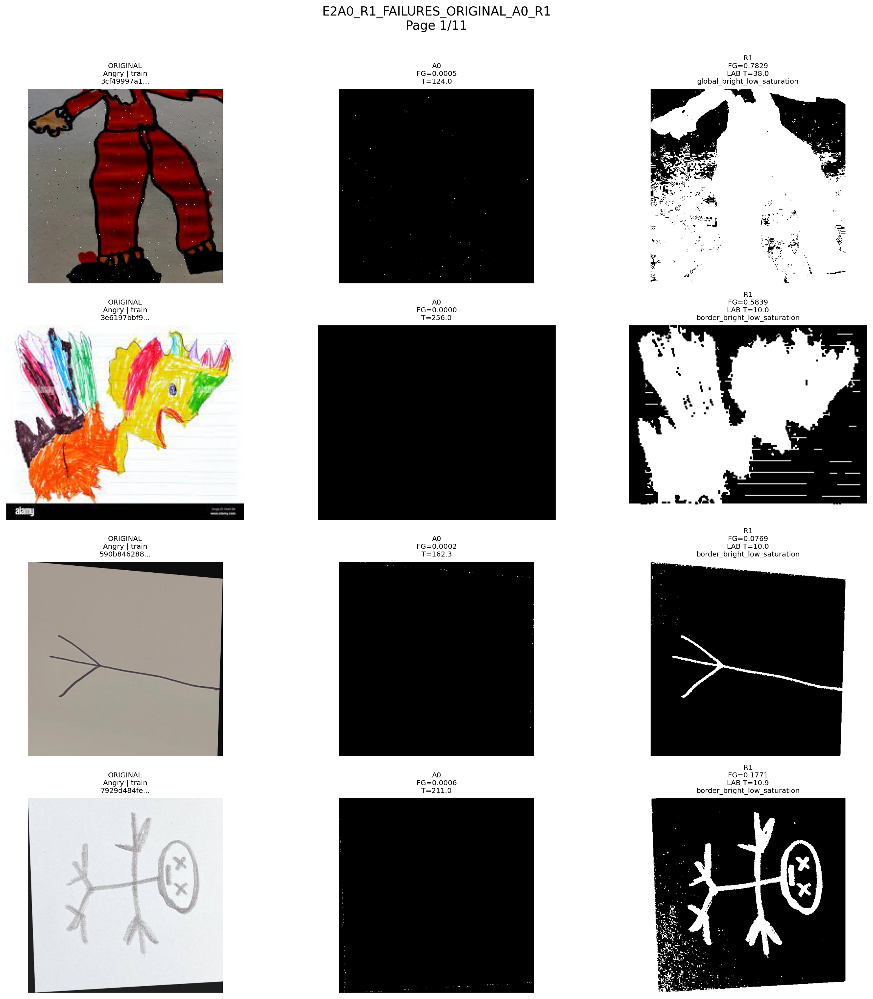


First CONTROL comparison page:


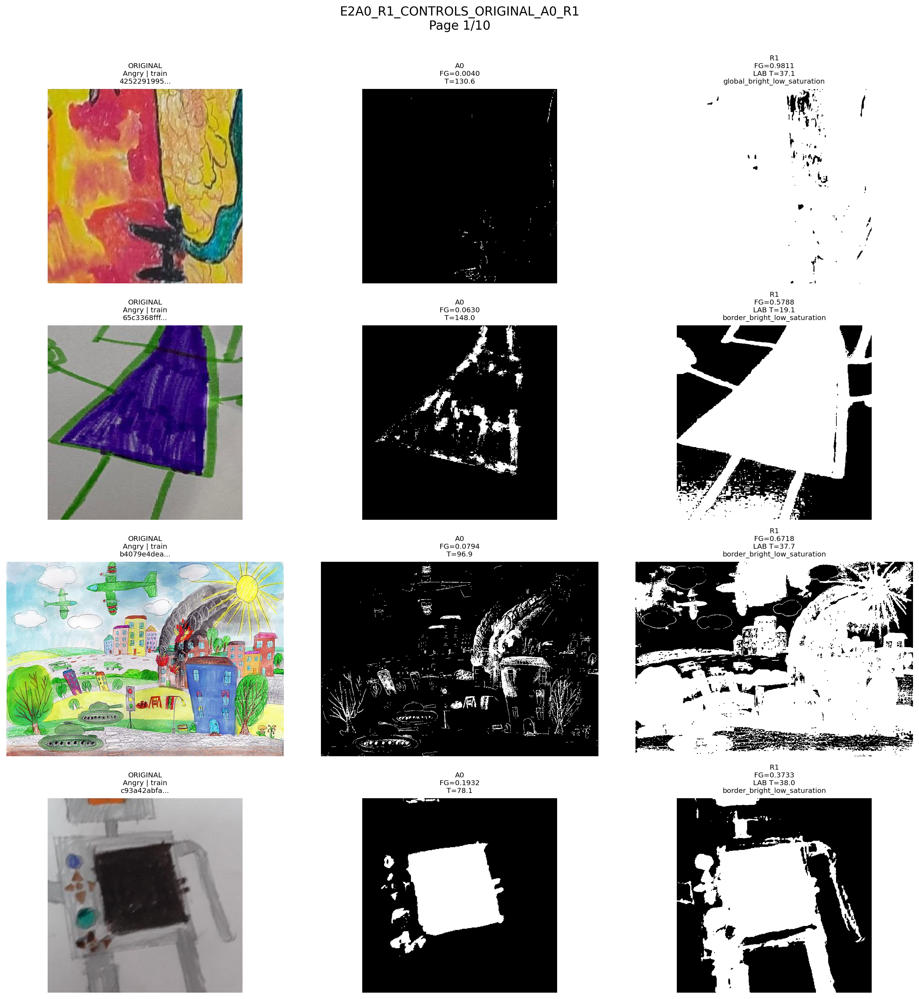


E2-A0-R1-PILOT COMPLETE

Failure sample: 44
OK controls: 40

Automatic failure cases now QC=OK: 39 / 44 (88.6%)
Automatic OK controls remaining QC=OK: 34 / 40 (85.0%)
Controls becoming VERY_HIGH_FOREGROUND: 6

Files:
  Results: /content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E2/E2A_INTERPRETABLE_FEATURES/E2A0_R1_PILOT_V1/tables/E2A0_R1_PILOT_MASK_RESULTS.csv
  Automatic summary: /content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E2/E2A_INTERPRETABLE_FEATURES/E2A0_R1_PILOT_V1/tables/E2A0_R1_PILOT_AUTOMATIC_SUMMARY.csv
  Visual review CSV: /content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E2/E2A_INTERPRETABLE_FEATURES/E2A0_R1_PILOT_V1/tables/E2A0_R1_PILOT_VISUAL_REVIEW.csv
  Failure contact PDF: /content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E2/E2A_INTERPRETABLE_FEATURES/E2A0_R1_PILOT_V1/figures/failure_contact_sheets/E2A0_R1_FAILURES_ORIGINAL_A0_R1.pdf
  Control contact PDF: /content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E2/E2A_INTERPRETABLE_FEATURES/E2A0_R1_PILOT_V1/figures/control_conta

In [ ]:
# ==================================================================================================
# DOAR MASTER THESIS
# E2-A0-R1-PILOT — CORRECTED DETERMINISTIC FOREGROUND EXTRACTION PILOT
#
# PURPOSE
# -------
# Test ONE isolated correction to the E2-A0 foreground-mask algorithm.
#
# PILOT DATA:
#   A) the frozen 44 representative E2-A0 QC failures
#   B) 40 deterministic E2-A0 "OK" control drawings
#
# WHAT CHANGES:
#   ONLY foreground-mask extraction.
#
# WHAT DOES NOT CHANGE:
#   - dataset split
#   - E2-A0 feature definitions
#   - E1
#   - classifiers
#   - formal feature branch
#   - psychological rules
#   - Locked Test
#
# THIS IS ONLY A PILOT.
# It does NOT overwrite or replace E2-A0.
#
# OUTPUT:
#   ORIGINAL | A0 MASK | R1 MASK comparison panels
#   automatic mask diagnostics
#   manual-review CSV
#   protocol / README
#
# Final R1 acceptance requires visual review.
# ==================================================================================================

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
from datetime import datetime, timezone
from matplotlib.backends.backend_pdf import PdfPages
from IPython.display import display, Image as IPImage

import hashlib
import json
import math

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm


# ==================================================================================================
# 1. PATHS
# ==================================================================================================

DATASET_ROOT = Path(
    "/content/drive/MyDrive/Masters/Datasets/Combined_Drawing"
)

E2A0_ROOT = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E2/"
    "E2A_INTERPRETABLE_FEATURES"
)

SOURCE_FEATURE_FILE = (
    E2A0_ROOT
    / "tables"
    / "E2A_T1_INTERPRETABLE_FEATURES.csv"
)

QC_ROOT = (
    E2A0_ROOT
    / "E2A0_QC_AUDIT_V1"
)

REPRESENTATIVE_FAILURE_FILE = (
    QC_ROOT
    / "tables"
    / "E2A0_QC_T10_REPRESENTATIVE_VISUAL_SAMPLE.csv"
)

R1_ROOT = (
    E2A0_ROOT
    / "E2A0_R1_PILOT_V1"
)

TABLE_DIR = (
    R1_ROOT
    / "tables"
)

FIGURE_DIR = (
    R1_ROOT
    / "figures"
)

FAILURE_PANEL_DIR = (
    FIGURE_DIR
    / "failure_cases"
)

CONTROL_PANEL_DIR = (
    FIGURE_DIR
    / "ok_controls"
)

for directory in [
    R1_ROOT,
    TABLE_DIR,
    FIGURE_DIR,
    FAILURE_PANEL_DIR,
    CONTROL_PANEL_DIR,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ==================================================================================================
# 2. FROZEN SOURCE CHECK
# ==================================================================================================

EXPECTED_E2A0_SHA256 = (
    "6ea50e3a9517e4681eda1f05e802b384e07b54295850d43fa8cd0a7dd78d1fda"
)


def sha256_file(path):

    hasher = hashlib.sha256()

    with open(path, "rb") as file:

        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b"",
        ):

            hasher.update(chunk)

    return hasher.hexdigest()


assert SOURCE_FEATURE_FILE.exists()
assert REPRESENTATIVE_FAILURE_FILE.exists()

actual_sha = sha256_file(
    SOURCE_FEATURE_FILE
)

assert actual_sha == EXPECTED_E2A0_SHA256, (
    "STOP: frozen E2-A0 feature table changed."
)


print("=" * 110)
print("DOAR E2-A0-R1-PILOT")
print("=" * 110)

print("Source E2-A0 SHA verified:", actual_sha)
print("Training                : NONE")
print("Classifier              : NONE")
print("New formal features     : NONE")
print("Psychological rules     : NONE")
print("Locked Test             : NOT ACCESSED")


# ==================================================================================================
# 3. LOAD FROZEN E2-A0 TABLE
# ==================================================================================================

features = pd.read_csv(
    SOURCE_FEATURE_FILE
)

features["image_id"] = (
    features["image_id"]
    .astype(str)
)

assert len(features) == 2883
assert features["image_id"].is_unique
assert (features["split"] == "test").sum() == 0
assert (features["split"] == "train").sum() == 2599
assert (features["split"] == "valid").sum() == 284


# ==================================================================================================
# 4. LOAD FROZEN REPRESENTATIVE FAILURE SAMPLE
# ==================================================================================================

failures = pd.read_csv(
    REPRESENTATIVE_FAILURE_FILE
)

failures["image_id"] = (
    failures["image_id"]
    .astype(str)
)

assert len(failures) == 44, (
    f"Expected frozen 44-case representative sample, found {len(failures)}."
)

assert set(
    failures["qc_status"].unique()
).issubset(
    {
        "NO_FOREGROUND",
        "VERY_LOW_FOREGROUND",
    }
)


print()
print("Representative failure cases:", len(failures))


# ==================================================================================================
# 5. CREATE 40 DETERMINISTIC OK CONTROLS
#
# 5 controls from each:
#
# train Angry
# train Fear
# train Happy
# train Sad
# valid Angry
# valid Fear
# valid Happy
# valid Sad
#
# = 8 strata × 5 = 40
#
# Deterministic SHA256 ordering means the sample can be recreated.
# ==================================================================================================

CLASS_ORDER = [
    "Angry",
    "Fear",
    "Happy",
    "Sad",
]

SPLIT_ORDER = [
    "train",
    "valid",
]

CONTROLS_PER_STRATUM = 5


def deterministic_key(image_id):

    return hashlib.sha256(
        str(image_id).encode("utf-8")
    ).hexdigest()


ok_pool = (
    features[
        features["qc_flag"]
        == "OK"
    ]
    .copy()
)

ok_pool["_selection_key"] = (
    ok_pool["image_id"]
    .map(deterministic_key)
)


control_parts = []


for split in SPLIT_ORDER:

    for class_name in CLASS_ORDER:

        subset = (
            ok_pool[
                (
                    ok_pool["split"]
                    == split
                )
                &
                (
                    ok_pool["true_class"]
                    == class_name
                )
            ]
            .sort_values("_selection_key")
        )

        assert len(subset) >= CONTROLS_PER_STRATUM

        control_parts.append(
            subset.head(
                CONTROLS_PER_STRATUM
            )
        )


controls = pd.concat(
    control_parts,
    ignore_index=True,
)

controls = controls.drop(
    columns=[
        "_selection_key"
    ]
)

assert len(controls) == 40


controls.to_csv(
    TABLE_DIR
    / "E2A0_R1_PILOT_OK_CONTROLS.csv",
    index=False,
)


print("Deterministic OK controls:", len(controls))
print("Total pilot images:", len(failures) + len(controls))


# ==================================================================================================
# 6. ORIGINAL E2-A0 MASK — EXACT REPRODUCTION
# ==================================================================================================

def get_border_pixels(image_rgb):

    height, width, _ = image_rgb.shape

    border_y = max(
        2,
        int(round(height * 0.04))
    )

    border_x = max(
        2,
        int(round(width * 0.04))
    )

    top = (
        image_rgb[:border_y, :, :]
        .reshape(-1, 3)
    )

    bottom = (
        image_rgb[height-border_y:, :, :]
        .reshape(-1, 3)
    )

    left = (
        image_rgb[:, :border_x, :]
        .reshape(-1, 3)
    )

    right = (
        image_rgb[:, width-border_x:, :]
        .reshape(-1, 3)
    )

    return np.concatenate(
        [
            top,
            bottom,
            left,
            right,
        ],
        axis=0,
    )


def build_a0_mask(image_rgb):

    image_lab = cv2.cvtColor(
        image_rgb,
        cv2.COLOR_RGB2LAB,
    ).astype(np.float32)

    border_rgb = get_border_pixels(
        image_rgb
    )

    border_lab = cv2.cvtColor(
        border_rgb.reshape(-1, 1, 3),
        cv2.COLOR_RGB2LAB,
    ).reshape(-1, 3).astype(np.float32)

    background_lab = np.median(
        border_lab,
        axis=0,
    )

    border_distance = np.linalg.norm(
        border_lab
        -
        background_lab[None, :],
        axis=1,
    )

    background_noise = float(
        np.percentile(
            border_distance,
            98,
        )
    )

    threshold = max(
        10.0,
        background_noise + 3.0,
    )

    distance = np.linalg.norm(
        image_lab
        -
        background_lab[
            None,
            None,
            :
        ],
        axis=2,
    )

    raw_mask = (
        distance
        >
        threshold
    ).astype(np.uint8)

    n_labels, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            raw_mask,
            connectivity=8,
        )
    )

    image_area = (
        raw_mask.shape[0]
        *
        raw_mask.shape[1]
    )

    min_component_area = max(
        3,
        int(
            round(
                image_area
                * 0.000005
            )
        ),
    )

    cleaned = np.zeros_like(
        raw_mask
    )

    for label in range(
        1,
        n_labels
    ):

        area = stats[
            label,
            cv2.CC_STAT_AREA
        ]

        if area >= min_component_area:

            cleaned[
                labels == label
            ] = 1

    return {
        "mask":
            cleaned,

        "threshold":
            threshold,

        "background_noise":
            background_noise,

        "background_lab":
            background_lab,
    }


# ==================================================================================================
# 7. R1 — ROBUST LIKELY-PAPER ESTIMATION
#
# DESIGN:
#
# 1. Do NOT trust every border pixel.
#
# 2. Find likely paper candidates using:
#      - relatively high brightness
#      - relatively low saturation
#
# 3. Prefer candidates near the border, but use whole-image candidates
#    when border candidates are scarce.
#
# 4. Estimate paper/background using medians.
#
# 5. Estimate background variation using MAD, not extreme 98th percentile.
#
# 6. Cap the LAB threshold to prevent values such as 150–250.
#
# 7. Foreground may be detected by:
#      A) LAB difference from estimated paper
#      B) significantly darker than paper
#      C) sufficiently chromatic relative to paper
#
# This remains deterministic.
# ==================================================================================================

def robust_mad(values):

    values = np.asarray(
        values,
        dtype=np.float64,
    )

    median = np.median(
        values
    )

    mad = np.median(
        np.abs(
            values
            -
            median
        )
    )

    # Gaussian-consistent robust scale.
    return float(
        1.4826
        * mad
    )


def build_border_selector(
    height,
    width,
    fraction=0.06,
):

    border_y = max(
        2,
        int(round(height * fraction))
    )

    border_x = max(
        2,
        int(round(width * fraction))
    )

    selector = np.zeros(
        (height, width),
        dtype=bool,
    )

    selector[:border_y, :] = True
    selector[height-border_y:, :] = True
    selector[:, :border_x] = True
    selector[:, width-border_x:] = True

    return selector


def build_r1_mask(image_rgb):

    image_rgb_float = (
        image_rgb.astype(
            np.float32
        )
    )

    image_lab = cv2.cvtColor(
        image_rgb,
        cv2.COLOR_RGB2LAB,
    ).astype(
        np.float32
    )

    image_hsv = cv2.cvtColor(
        image_rgb,
        cv2.COLOR_RGB2HSV,
    ).astype(
        np.float32
    )

    gray = cv2.cvtColor(
        image_rgb,
        cv2.COLOR_RGB2GRAY,
    ).astype(
        np.float32
    )

    height, width = gray.shape
    image_area = height * width


    # ----------------------------------------------------------------------------------------------
    # 7A. Candidate paper pixels
    # ----------------------------------------------------------------------------------------------

    value = image_hsv[:, :, 2]
    saturation = image_hsv[:, :, 1]

    # Relative thresholds make this more robust across scans.
    bright_cut = float(
        np.percentile(
            value,
            60
        )
    )

    saturation_cut = float(
        np.percentile(
            saturation,
            45
        )
    )

    # Do not let thresholds become too permissive.
    bright_cut = max(
        bright_cut,
        150.0,
    )

    saturation_cut = min(
        max(
            saturation_cut,
            12.0,
        ),
        70.0,
    )


    likely_paper_global = (
        (value >= bright_cut)
        &
        (saturation <= saturation_cut)
    )


    border_selector = build_border_selector(
        height,
        width,
        fraction=0.06,
    )


    likely_paper_border = (
        likely_paper_global
        &
        border_selector
    )


    minimum_candidate_count = max(
        100,
        int(
            round(
                image_area
                * 0.002
            )
        ),
    )


    if (
        likely_paper_border.sum()
        >= minimum_candidate_count
    ):

        candidate_selector = (
            likely_paper_border
        )

        paper_source = (
            "border_bright_low_saturation"
        )

    elif (
        likely_paper_global.sum()
        >= minimum_candidate_count
    ):

        candidate_selector = (
            likely_paper_global
        )

        paper_source = (
            "global_bright_low_saturation"
        )

    else:

        # Last deterministic fallback:
        # take brightest 10% of image.
        fallback_cut = float(
            np.percentile(
                value,
                90
            )
        )

        candidate_selector = (
            value
            >= fallback_cut
        )

        paper_source = (
            "brightest_10_percent_fallback"
        )


    candidate_lab = (
        image_lab[
            candidate_selector
        ]
    )

    candidate_gray = (
        gray[
            candidate_selector
        ]
    )

    candidate_sat = (
        saturation[
            candidate_selector
        ]
    )


    # ----------------------------------------------------------------------------------------------
    # 7B. Robust background estimate
    # ----------------------------------------------------------------------------------------------

    background_lab = np.median(
        candidate_lab,
        axis=0,
    )

    background_gray = float(
        np.median(
            candidate_gray
        )
    )

    background_saturation = float(
        np.median(
            candidate_sat
        )
    )


    lab_distance = np.linalg.norm(
        image_lab
        -
        background_lab[
            None,
            None,
            :
        ],
        axis=2,
    )


    candidate_distance = np.linalg.norm(
        candidate_lab
        -
        background_lab[
            None,
            :
        ],
        axis=1,
    )


    distance_median = float(
        np.median(
            candidate_distance
        )
    )

    distance_robust_scale = (
        robust_mad(
            candidate_distance
        )
    )


    # ----------------------------------------------------------------------------------------------
    # 7C. Controlled LAB threshold
    #
    # The original A0 could explode above 200.
    #
    # R1:
    #   median + 4 robust SD
    #
    # with explicit conservative limits.
    # ----------------------------------------------------------------------------------------------

    lab_threshold = (
        distance_median
        +
        4.0
        * distance_robust_scale
        +
        3.0
    )

    lab_threshold = float(
        np.clip(
            lab_threshold,
            10.0,
            38.0,
        )
    )


    mask_lab = (
        lab_distance
        >
        lab_threshold
    )


    # ----------------------------------------------------------------------------------------------
    # 7D. Dark-stroke evidence
    # ----------------------------------------------------------------------------------------------

    candidate_gray_scale = (
        robust_mad(
            candidate_gray
        )
    )

    darkness_delta = max(
        15.0,
        4.0
        * candidate_gray_scale,
    )

    darkness_delta = min(
        darkness_delta,
        55.0,
    )


    dark_threshold = (
        background_gray
        -
        darkness_delta
    )


    mask_dark = (
        gray
        <
        dark_threshold
    )


    # ----------------------------------------------------------------------------------------------
    # 7E. Chromatic evidence
    #
    # A coloured mark may still be similar in luminance to the paper.
    # ----------------------------------------------------------------------------------------------

    chromatic_threshold = max(
        35.0,
        background_saturation
        +
        25.0,
    )

    chromatic_threshold = min(
        chromatic_threshold,
        90.0,
    )


    mask_chromatic = (
        saturation
        >
        chromatic_threshold
    )


    # Avoid treating bright coloured scan tint everywhere as foreground:
    # require some colour-distance from estimated paper too.
    mask_chromatic = (
        mask_chromatic
        &
        (
            lab_distance
            >
            max(
                7.0,
                lab_threshold
                * 0.55
            )
        )
    )


    # ----------------------------------------------------------------------------------------------
    # 7F. Combined evidence
    # ----------------------------------------------------------------------------------------------

    raw_mask = (
        mask_lab
        |
        mask_dark
        |
        mask_chromatic
    ).astype(
        np.uint8
    )


    # ----------------------------------------------------------------------------------------------
    # 7G. Small-component cleanup
    #
    # Keep this conservative because pencil lines can be thin.
    # ----------------------------------------------------------------------------------------------

    n_labels, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            raw_mask,
            connectivity=8,
        )
    )

    min_component_area = max(
        3,
        int(
            round(
                image_area
                * 0.000003
            )
        ),
    )

    cleaned = np.zeros_like(
        raw_mask
    )

    for label in range(
        1,
        n_labels
    ):

        area = stats[
            label,
            cv2.CC_STAT_AREA
        ]

        if area >= min_component_area:

            cleaned[
                labels
                == label
            ] = 1


    # ----------------------------------------------------------------------------------------------
    # 7H. Very small closing to join tiny gaps.
    #
    # Only 2×2.
    # ----------------------------------------------------------------------------------------------

    kernel = np.ones(
        (2, 2),
        dtype=np.uint8,
    )

    cleaned = cv2.morphologyEx(
        cleaned,
        cv2.MORPH_CLOSE,
        kernel,
        iterations=1,
    )


    # ----------------------------------------------------------------------------------------------
    # 7I. Paper-confidence diagnostics
    # ----------------------------------------------------------------------------------------------

    candidate_fraction = float(
        candidate_selector.mean()
    )

    border_candidate_fraction = float(
        (
            likely_paper_border
        ).sum()
        /
        max(
            border_selector.sum(),
            1,
        )
    )


    return {
        "mask":
            cleaned.astype(
                np.uint8
            ),

        "raw_mask":
            raw_mask,

        "mask_lab":
            mask_lab.astype(
                np.uint8
            ),

        "mask_dark":
            mask_dark.astype(
                np.uint8
            ),

        "mask_chromatic":
            mask_chromatic.astype(
                np.uint8
            ),

        "paper_source":
            paper_source,

        "background_lab":
            background_lab,

        "background_gray":
            background_gray,

        "background_saturation":
            background_saturation,

        "lab_threshold":
            lab_threshold,

        "dark_threshold":
            float(
                dark_threshold
            ),

        "chromatic_threshold":
            float(
                chromatic_threshold
            ),

        "candidate_fraction":
            candidate_fraction,

        "border_candidate_fraction":
            border_candidate_fraction,

        "candidate_count":
            int(
                candidate_selector.sum()
            ),

        "min_component_area":
            min_component_area,
    }


# ==================================================================================================
# 8. COMMON QC STATUS
# ==================================================================================================

def qc_status_from_ratio(
    foreground_ratio
):

    if foreground_ratio <= 0:

        return "NO_FOREGROUND"

    if foreground_ratio < 0.001:

        return "VERY_LOW_FOREGROUND"

    if foreground_ratio > 0.80:

        return "VERY_HIGH_FOREGROUND"

    return "OK"


# ==================================================================================================
# 9. MASK IOU
# ==================================================================================================

def mask_iou(
    mask_a,
    mask_b
):

    a = (
        mask_a
        > 0
    )

    b = (
        mask_b
        > 0
    )

    union = np.logical_or(
        a,
        b,
    ).sum()

    if union == 0:

        return 1.0

    intersection = np.logical_and(
        a,
        b,
    ).sum()

    return float(
        intersection
        /
        union
    )


# ==================================================================================================
# 10. BUILD PILOT TABLE
# ==================================================================================================

failure_ids = set(
    failures["image_id"]
)

control_ids = set(
    controls["image_id"]
)


pilot_rows = []


for _, row in failures.iterrows():

    pilot_rows.append(
        {
            "pilot_group":
                "FLAGGED_FAILURE",

            "image_id":
                row["image_id"],

            "split":
                row["split"],

            "true_class":
                row["true_class"],

            "relative_path":
                row["relative_path"],

            "a0_qc_status":
                row["qc_status"],

            "a0_foreground_ratio":
                float(
                    row["stored_foreground_ratio"]
                ),
        }
    )


for _, row in controls.iterrows():

    pilot_rows.append(
        {
            "pilot_group":
                "OK_CONTROL",

            "image_id":
                row["image_id"],

            "split":
                row["split"],

            "true_class":
                row["true_class"],

            "relative_path":
                row["relative_path"],

            "a0_qc_status":
                row["qc_flag"],

            "a0_foreground_ratio":
                float(
                    row["foreground_fraction"]
                ),
        }
    )


pilot = pd.DataFrame(
    pilot_rows
)

assert len(pilot) == 84
assert pilot["image_id"].is_unique


# ==================================================================================================
# 11. RUN A0 + R1 ON THE 84 PILOT IMAGES
# ==================================================================================================

result_rows = []


for _, row in tqdm(
    pilot.iterrows(),
    total=len(pilot),
    desc="E2-A0-R1 pilot masks",
):

    image_path = (
        DATASET_ROOT
        / row["relative_path"]
    )


    with Image.open(
        image_path
    ) as image_file:

        image_rgb = np.asarray(
            image_file.convert("RGB")
        )


    a0 = build_a0_mask(
        image_rgb
    )

    r1 = build_r1_mask(
        image_rgb
    )


    a0_ratio_recreated = float(
        a0["mask"].mean()
    )

    r1_ratio = float(
        r1["mask"].mean()
    )


    a0_ratio_diff = abs(
        a0_ratio_recreated
        -
        float(
            row["a0_foreground_ratio"]
        )
    )


    result_rows.append(
        {
            "pilot_group":
                row["pilot_group"],

            "image_id":
                row["image_id"],

            "split":
                row["split"],

            "true_class":
                row["true_class"],

            "relative_path":
                row["relative_path"],

            "a0_qc_status":
                row["a0_qc_status"],

            "a0_foreground_ratio_saved":
                float(
                    row["a0_foreground_ratio"]
                ),

            "a0_foreground_ratio_recreated":
                a0_ratio_recreated,

            "a0_reproduction_abs_diff":
                a0_ratio_diff,

            "a0_threshold":
                float(
                    a0["threshold"]
                ),

            "a0_background_noise":
                float(
                    a0["background_noise"]
                ),

            "r1_foreground_ratio":
                r1_ratio,

            "r1_qc_status":
                qc_status_from_ratio(
                    r1_ratio
                ),

            "r1_lab_threshold":
                r1["lab_threshold"],

            "r1_dark_threshold":
                r1["dark_threshold"],

            "r1_chromatic_threshold":
                r1["chromatic_threshold"],

            "r1_paper_source":
                r1["paper_source"],

            "r1_candidate_fraction":
                r1["candidate_fraction"],

            "r1_border_candidate_fraction":
                r1[
                    "border_candidate_fraction"
                ],

            "a0_vs_r1_mask_iou":
                mask_iou(
                    a0["mask"],
                    r1["mask"],
                ),

            "foreground_ratio_change":
                (
                    r1_ratio
                    -
                    a0_ratio_recreated
                ),
        }
    )


results = pd.DataFrame(
    result_rows
)


RESULT_FILE = (
    TABLE_DIR
    / "E2A0_R1_PILOT_MASK_RESULTS.csv"
)

results.to_csv(
    RESULT_FILE,
    index=False,
)


assert results[
    "a0_reproduction_abs_diff"
].max() <= 1e-8


print()
print("✓ A0 mask reproduction exact for pilot sample.")


# ==================================================================================================
# 12. AUTOMATIC DIAGNOSTIC SUMMARY
#
# IMPORTANT:
# These are NOT sufficient to accept R1.
# Visual review remains required.
# ==================================================================================================

failure_results = results[
    results["pilot_group"]
    == "FLAGGED_FAILURE"
].copy()

control_results = results[
    results["pilot_group"]
    == "OK_CONTROL"
].copy()


auto_failure_recovered = int(
    (
        failure_results[
            "r1_qc_status"
        ]
        == "OK"
    ).sum()
)


auto_control_remained_ok = int(
    (
        control_results[
            "r1_qc_status"
        ]
        == "OK"
    ).sum()
)


auto_control_very_high = int(
    (
        control_results[
            "r1_qc_status"
        ]
        == "VERY_HIGH_FOREGROUND"
    ).sum()
)


summary = pd.DataFrame(
    [
        {
            "metric":
                "pilot_failure_cases",

            "value":
                len(
                    failure_results
                ),
        },

        {
            "metric":
                "failure_cases_auto_OK_under_R1",

            "value":
                auto_failure_recovered,
        },

        {
            "metric":
                "failure_auto_OK_rate",

            "value":
                auto_failure_recovered
                / len(
                    failure_results
                ),
        },

        {
            "metric":
                "pilot_OK_controls",

            "value":
                len(
                    control_results
                ),
        },

        {
            "metric":
                "controls_remaining_auto_OK",

            "value":
                auto_control_remained_ok,
        },

        {
            "metric":
                "control_auto_OK_rate",

            "value":
                auto_control_remained_ok
                / len(
                    control_results
                ),
        },

        {
            "metric":
                "controls_becoming_VERY_HIGH_FOREGROUND",

            "value":
                auto_control_very_high,
        },

        {
            "metric":
                "median_R1_foreground_ratio_failures",

            "value":
                float(
                    failure_results[
                        "r1_foreground_ratio"
                    ].median()
                ),
        },

        {
            "metric":
                "median_R1_foreground_ratio_controls",

            "value":
                float(
                    control_results[
                        "r1_foreground_ratio"
                    ].median()
                ),
        },

        {
            "metric":
                "median_A0_vs_R1_IoU_controls",

            "value":
                float(
                    control_results[
                        "a0_vs_r1_mask_iou"
                    ].median()
                ),
        },
    ]
)


SUMMARY_FILE = (
    TABLE_DIR
    / "E2A0_R1_PILOT_AUTOMATIC_SUMMARY.csv"
)


summary.to_csv(
    SUMMARY_FILE,
    index=False,
)


print()
print("=" * 110)
print("AUTOMATIC PILOT SUMMARY")
print("=" * 110)

print(
    summary.to_string(
        index=False
    )
)


# ==================================================================================================
# 13. QC STATUS TRANSITION TABLE
# ==================================================================================================

transition_table = pd.crosstab(
    results["a0_qc_status"],
    results["r1_qc_status"],
    margins=True,
)


TRANSITION_FILE = (
    TABLE_DIR
    / "E2A0_R1_PILOT_QC_TRANSITIONS.csv"
)


transition_table.to_csv(
    TRANSITION_FILE
)


print()
print("=" * 110)
print("A0 → R1 QC STATUS TRANSITIONS")
print("=" * 110)

print(
    transition_table
)


# ==================================================================================================
# 14. MANUAL VISUAL-REVIEW TABLE
#
# IMPORTANT:
# Blank by design.
#
# Review ORIGINAL | A0 | R1.
#
# Allowed score:
#   GOOD
#   PARTIAL
#   FAILED
#   OVERSEGMENTED
#   UNCERTAIN
# ==================================================================================================

review = results.copy()


review["r1_visual_score"] = ""

review["r1_visual_notes"] = ""

review["visual_review_complete"] = False


REVIEW_FILE = (
    TABLE_DIR
    / "E2A0_R1_PILOT_VISUAL_REVIEW.csv"
)


review.to_csv(
    REVIEW_FILE,
    index=False,
)


# ==================================================================================================
# 15. INDIVIDUAL THREE-WAY PANEL
# ==================================================================================================

def make_three_way_panel(
    row,
    output_directory,
):

    image_path = (
        DATASET_ROOT
        / row["relative_path"]
    )


    with Image.open(
        image_path
    ) as image_file:

        image_rgb = np.asarray(
            image_file.convert("RGB")
        )


    a0 = build_a0_mask(
        image_rgb
    )

    r1 = build_r1_mask(
        image_rgb
    )


    fig, axes = plt.subplots(
        1,
        3,
        figsize=(14, 5),
    )


    axes[0].imshow(
        image_rgb
    )

    axes[0].axis(
        "off"
    )

    axes[0].set_title(
        (
            "ORIGINAL\n"
            f"{row['true_class']} | {row['split']}\n"
            f"id={str(row['image_id'])[:12]}..."
        )
    )


    axes[1].imshow(
        a0["mask"],
        cmap="gray",
        vmin=0,
        vmax=1,
    )

    axes[1].axis(
        "off"
    )

    axes[1].set_title(
        (
            "E2-A0 MASK\n"
            f"FG={a0['mask'].mean():.4f}\n"
            f"T={a0['threshold']:.1f}"
        )
    )


    axes[2].imshow(
        r1["mask"],
        cmap="gray",
        vmin=0,
        vmax=1,
    )

    axes[2].axis(
        "off"
    )

    axes[2].set_title(
        (
            "E2-A0-R1 MASK\n"
            f"FG={r1['mask'].mean():.4f}\n"
            f"LAB T={r1['lab_threshold']:.1f}"
        )
    )


    fig.suptitle(
        (
            f"{row['pilot_group']} — R1 Pilot\n"
            "Only foreground extraction changed"
        ),
        fontsize=13,
    )


    fig.tight_layout()


    output_path = (
        output_directory
        / (
            f"{row['pilot_group']}__"
            f"{row['true_class']}__"
            f"{row['split']}__"
            f"{row['image_id']}.png"
        )
    )


    fig.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight",
    )


    plt.close(
        fig
    )


    return output_path


# ==================================================================================================
# 16. CREATE ALL INDIVIDUAL PANELS
# ==================================================================================================

created_failure_panels = []

created_control_panels = []


for _, row in tqdm(
    results.iterrows(),
    total=len(results),
    desc="Creating R1 comparison panels",
):

    if (
        row["pilot_group"]
        == "FLAGGED_FAILURE"
    ):

        output_path = make_three_way_panel(
            row,
            FAILURE_PANEL_DIR,
        )

        created_failure_panels.append(
            output_path
        )

    else:

        output_path = make_three_way_panel(
            row,
            CONTROL_PANEL_DIR,
        )

        created_control_panels.append(
            output_path
        )


print()
print(
    "Failure comparison panels:",
    len(created_failure_panels)
)

print(
    "OK-control comparison panels:",
    len(created_control_panels)
)


# ==================================================================================================
# 17. PAGINATED CONTACT SHEETS
#
# 4 cases per page.
#
# Each case:
# ORIGINAL | A0 MASK | R1 MASK
# ==================================================================================================

def create_three_way_contact_sheet(
    dataframe,
    output_directory,
    base_name,
    cases_per_page=4,
):

    output_directory.mkdir(
        parents=True,
        exist_ok=True,
    )

    dataframe = (
        dataframe
        .sort_values(
            [
                "split",
                "true_class",
                "image_id",
            ]
        )
        .reset_index(
            drop=True
        )
    )

    total_pages = math.ceil(
        len(dataframe)
        /
        cases_per_page
    )

    pdf_path = (
        output_directory
        / f"{base_name}.pdf"
    )

    png_paths = []


    with PdfPages(
        pdf_path
    ) as pdf:

        for page_index in tqdm(
            range(total_pages),
            desc=base_name,
        ):

            start = (
                page_index
                * cases_per_page
            )

            end = min(
                start
                +
                cases_per_page,
                len(dataframe),
            )

            page = (
                dataframe
                .iloc[start:end]
                .reset_index(drop=True)
            )


            fig, axes = plt.subplots(
                cases_per_page,
                3,
                figsize=(
                    15,
                    4
                    * cases_per_page
                ),
            )

            axes = np.asarray(
                axes
            ).reshape(
                cases_per_page,
                3
            )


            for axis in axes.flat:

                axis.axis(
                    "off"
                )


            for row_index, (_, row) in enumerate(
                page.iterrows()
            ):

                image_path = (
                    DATASET_ROOT
                    / row["relative_path"]
                )


                with Image.open(
                    image_path
                ) as image_file:

                    image_rgb = np.asarray(
                        image_file.convert("RGB")
                    )


                a0 = build_a0_mask(
                    image_rgb
                )

                r1 = build_r1_mask(
                    image_rgb
                )


                axes[
                    row_index,
                    0
                ].imshow(
                    image_rgb
                )

                axes[
                    row_index,
                    0
                ].axis(
                    "off"
                )

                axes[
                    row_index,
                    0
                ].set_title(
                    (
                        "ORIGINAL\n"
                        f"{row['true_class']} | "
                        f"{row['split']}\n"
                        f"{str(row['image_id'])[:10]}..."
                    ),
                    fontsize=8,
                )


                axes[
                    row_index,
                    1
                ].imshow(
                    a0["mask"],
                    cmap="gray",
                    vmin=0,
                    vmax=1,
                )

                axes[
                    row_index,
                    1
                ].axis(
                    "off"
                )

                axes[
                    row_index,
                    1
                ].set_title(
                    (
                        "A0\n"
                        f"FG={a0['mask'].mean():.4f}\n"
                        f"T={a0['threshold']:.1f}"
                    ),
                    fontsize=8,
                )


                axes[
                    row_index,
                    2
                ].imshow(
                    r1["mask"],
                    cmap="gray",
                    vmin=0,
                    vmax=1,
                )

                axes[
                    row_index,
                    2
                ].axis(
                    "off"
                )

                axes[
                    row_index,
                    2
                ].set_title(
                    (
                        "R1\n"
                        f"FG={r1['mask'].mean():.4f}\n"
                        f"LAB T={r1['lab_threshold']:.1f}\n"
                        f"{r1['paper_source']}"
                    ),
                    fontsize=8,
                )


            fig.suptitle(
                (
                    f"{base_name}\n"
                    f"Page {page_index + 1}/{total_pages}"
                ),
                fontsize=14,
            )


            fig.tight_layout(
                rect=[
                    0,
                    0,
                    1,
                    0.975,
                ]
            )


            png_path = (
                output_directory
                / (
                    f"{base_name}_"
                    f"page_{page_index + 1:03d}.png"
                )
            )


            fig.savefig(
                png_path,
                dpi=180,
                bbox_inches="tight",
            )


            pdf.savefig(
                fig,
                bbox_inches="tight",
            )


            plt.close(
                fig
            )


            png_paths.append(
                png_path
            )


    return {
        "pdf":
            pdf_path,

        "png_pages":
            png_paths,
    }


FAILURE_CONTACT_DIR = (
    FIGURE_DIR
    / "failure_contact_sheets"
)

CONTROL_CONTACT_DIR = (
    FIGURE_DIR
    / "control_contact_sheets"
)


failure_contact = (
    create_three_way_contact_sheet(
        failure_results,
        FAILURE_CONTACT_DIR,
        "E2A0_R1_FAILURES_ORIGINAL_A0_R1",
        cases_per_page=4,
    )
)


control_contact = (
    create_three_way_contact_sheet(
        control_results,
        CONTROL_CONTACT_DIR,
        "E2A0_R1_CONTROLS_ORIGINAL_A0_R1",
        cases_per_page=4,
    )
)


# ==================================================================================================
# 18. THRESHOLD COMPARISON TABLE / FIGURE
# ==================================================================================================

threshold_summary = (
    results
    .groupby(
        "pilot_group"
    )
    .agg(
        n=(
            "image_id",
            "size"
        ),

        median_a0_threshold=(
            "a0_threshold",
            "median"
        ),

        max_a0_threshold=(
            "a0_threshold",
            "max"
        ),

        median_r1_lab_threshold=(
            "r1_lab_threshold",
            "median"
        ),

        max_r1_lab_threshold=(
            "r1_lab_threshold",
            "max"
        ),

        median_a0_foreground_ratio=(
            "a0_foreground_ratio_recreated",
            "median"
        ),

        median_r1_foreground_ratio=(
            "r1_foreground_ratio",
            "median"
        ),
    )
    .reset_index()
)


threshold_summary.to_csv(
    TABLE_DIR
    / "E2A0_R1_PILOT_THRESHOLD_SUMMARY.csv",
    index=False,
)


print()
print("=" * 110)
print("THRESHOLD SUMMARY")
print("=" * 110)

print(
    threshold_summary.to_string(
        index=False
    )
)


fig, ax = plt.subplots(
    figsize=(8, 6)
)


ax.scatter(
    results["a0_threshold"],
    results["r1_lab_threshold"],
)


ax.set_xlabel(
    "E2-A0 LAB threshold"
)

ax.set_ylabel(
    "E2-A0-R1 LAB threshold"
)

ax.set_title(
    "E2-A0-R1 Pilot — Foreground Threshold Comparison"
)


ax.axhline(
    38,
    linestyle="--",
)


fig.tight_layout()


fig.savefig(
    FIGURE_DIR
    / "E2A0_R1_THRESHOLD_COMPARISON.png",
    dpi=220,
    bbox_inches="tight",
)


plt.close(
    fig
)


# ==================================================================================================
# 19. PREDECLARED VISUAL ACCEPTANCE GATE
#
# IMPORTANT:
# These are PILOT operational criteria.
#
# The code DOES NOT automatically declare R1 successful.
#
# After manual review:
#
# FAILURE CASES:
#   GOOD or PARTIAL = recovered
#
# CONTROL CASES:
#   GOOD or PARTIAL = retained
#
# R1 candidate may proceed to full extraction if:
#
#   >= 85% representative failure recovery
#   >= 90% existing OK-control retention
#   <= 5% OVERSEGMENTED controls
#
# AND:
#   no obvious systematic failure by class/image type
#
# These thresholds are not psychological validity claims.
# ==================================================================================================

acceptance_gate = {
    "minimum_failure_recovery_rate":
        0.85,

    "minimum_OK_control_retention_rate":
        0.90,

    "maximum_control_oversegmentation_rate":
        0.05,

    "recovered_visual_scores": [
        "GOOD",
        "PARTIAL",
    ],

    "retained_visual_scores": [
        "GOOD",
        "PARTIAL",
    ],

    "important_requirement":
        (
            "No obvious systematic failure by class, "
            "drawing medium, background or acquisition type."
        ),

    "decision_is_automatic":
        False,
}


# ==================================================================================================
# 20. PROTOCOL
# ==================================================================================================

protocol = {
    "experiment":
        "E2-A0-R1-PILOT",

    "timestamp_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "purpose":
        (
            "Evaluate one isolated deterministic correction "
            "to the E2-A0 foreground extraction after visual QC "
            "showed valid drawings being lost."
        ),

    "source_E2A0_sha256":
        actual_sha,

    "source_E2A0_modified":
        False,

    "failure_sample_n":
        int(
            len(
                failure_results
            )
        ),

    "control_sample_n":
        int(
            len(
                control_results
            )
        ),

    "control_sampling":
        (
            "Deterministic SHA256(image_id) ordering; "
            "5 existing E2-A0 OK drawings per split × class."
        ),

    "only_changed_component":
        "Foreground-mask algorithm",

    "new_formal_features_used":
        False,

    "classifier_used":
        False,

    "psychological_rules_used":
        False,

    "locked_test_accessed":
        False,

    "r1_method": {
        "background_candidate_policy":
            (
                "Bright + low-saturation candidate pixels, "
                "prefer border candidates then global fallback."
            ),

        "background_estimator":
            "Median",

        "noise_estimator":
            "MAD-based robust scale",

        "LAB_threshold":
            (
                "median candidate LAB distance + "
                "4*MAD scale + 3, clipped to [10,38]"
            ),

        "additional_evidence":
            [
                "dark-stroke evidence",
                "chromatic-stroke evidence",
            ],

        "cleanup":
            (
                "minimal small-component removal + "
                "single 2×2 morphological closing"
            ),
    },

    "acceptance_gate":
        acceptance_gate,

    "important_limitations": [
        (
            "This is an engineering foreground-mask pilot, "
            "not psychological validation."
        ),

        (
            "Automatic QC status does not prove mask correctness."
        ),

        (
            "Visual review of ORIGINAL|A0|R1 panels is required."
        ),

        (
            "No R1 results may overwrite the frozen E2-A0 baseline."
        ),
    ],
}


PROTOCOL_FILE = (
    R1_ROOT
    / "E2A0_R1_PILOT_PROTOCOL.json"
)


PROTOCOL_FILE.write_text(
    json.dumps(
        protocol,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ==================================================================================================
# 21. README
# ==================================================================================================

README_FILE = (
    R1_ROOT
    / "README_E2A0_R1_PILOT.md"
)


readme = f"""
# DOAR E2-A0-R1 Pilot

## Purpose

Evaluate an isolated correction to the frozen E2-A0 foreground-mask method.

## Source baseline

E2-A0 remains frozen and unchanged.

SHA256:

`{actual_sha}`

## Pilot sample

Representative known failures: {len(failure_results)}

Existing E2-A0 OK controls: {len(control_results)}

Total: {len(results)}

## What changed

Only foreground-mask extraction.

No feature definitions changed.

No classifiers were trained.

No expanded formal features were introduced.

No psychological rules were used.

Locked Test was not accessed.

## R1 concept

The original E2-A0 threshold was vulnerable to contaminated border pixels.

R1 uses:

- bright / low-saturation likely-paper candidates;
- median paper/background estimate;
- MAD-based robust variation;
- bounded LAB-distance threshold;
- complementary dark-stroke evidence;
- complementary chromatic-stroke evidence;
- minimal cleanup.

## Manual review

Every pilot case must be scored using:

- GOOD
- PARTIAL
- FAILED
- OVERSEGMENTED
- UNCERTAIN

Review:

ORIGINAL | A0 MASK | R1 MASK

## Pilot gate

R1 may proceed to a full Train+Validation extraction only if:

- failure recovery >= 85%;
- OK-control retention >= 90%;
- control oversegmentation <= 5%;
- no clear systematic regression is visible.

These are engineering pilot criteria, not psychological validity criteria.
"""


README_FILE.write_text(
    readme.strip()
    + "\n",
    encoding="utf-8",
)


# ==================================================================================================
# 22. DISPLAY FIRST COMPARISON PAGES IN COLAB
# ==================================================================================================

print()
print("=" * 110)
print("PILOT ARTIFACT GENERATION COMPLETE")
print("=" * 110)


if (
    failure_contact[
        "png_pages"
    ]
):

    print()
    print(
        "First FAILURE comparison page:"
    )

    display(
        IPImage(
            filename=str(
                failure_contact[
                    "png_pages"
                ][0]
            )
        )
    )


if (
    control_contact[
        "png_pages"
    ]
):

    print()
    print(
        "First CONTROL comparison page:"
    )

    display(
        IPImage(
            filename=str(
                control_contact[
                    "png_pages"
                ][0]
            )
        )
    )


# ==================================================================================================
# 23. FINAL OUTPUT
# ==================================================================================================

print()
print("=" * 110)
print("E2-A0-R1-PILOT COMPLETE")
print("=" * 110)

print()
print(
    "Failure sample:",
    len(
        failure_results
    )
)

print(
    "OK controls:",
    len(
        control_results
    )
)

print()
print(
    "Automatic failure cases now QC=OK:",
    auto_failure_recovered,
    "/",
    len(
        failure_results
    ),
    (
        f"({100*auto_failure_recovered/len(failure_results):.1f}%)"
    )
)

print(
    "Automatic OK controls remaining QC=OK:",
    auto_control_remained_ok,
    "/",
    len(
        control_results
    ),
    (
        f"({100*auto_control_remained_ok/len(control_results):.1f}%)"
    )
)

print(
    "Controls becoming VERY_HIGH_FOREGROUND:",
    auto_control_very_high
)

print()
print(
    "Files:"
)

print(
    "  Results:",
    RESULT_FILE
)

print(
    "  Automatic summary:",
    SUMMARY_FILE
)

print(
    "  Visual review CSV:",
    REVIEW_FILE
)

print(
    "  Failure contact PDF:",
    failure_contact[
        "pdf"
    ]
)

print(
    "  Control contact PDF:",
    control_contact[
        "pdf"
    ]
)

print(
    "  Protocol:",
    PROTOCOL_FILE
)

print(
    "  README:",
    README_FILE
)


print()
print(
    "✓ ORIGINAL E2-A0 UNCHANGED."
)

print(
    "✓ ONLY FOREGROUND EXTRACTION CHANGED."
)

print(
    "✓ NO CLASSIFIER."
)

print(
    "✓ NO EXPANDED FORMAL FEATURES."
)

print(
    "✓ NO PSYCHOLOGICAL RULES."
)

print(
    "✓ LOCKED TEST NOT ACCESSED."
)


print()
print("=" * 110)
print("DO NOT RUN FULL E2-A0-R1 YET")
print("=" * 110)

print()
print(
    "Send ChatGPT:"
)

print(
    "1. AUTOMATIC PILOT SUMMARY"
)

print(
    "2. THRESHOLD SUMMARY"
)

print(
    "3. Failure comparison PDF or PNG pages"
)

print(
    "4. Control comparison PDF or PNG pages"
)

print()
print(
    "We will visually decide whether R1 passes the pilot gate "
    "before processing all 2,883 Train+Validation drawings."
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DOAR E2-A0-R1-V2-PILOT
Frozen E2-A0 SHA       : 6ea50e3a9517e4681eda1f05e802b384e07b54295850d43fa8cd0a7dd78d1fda
Development images     : SAME 84 FROM V1
Training               : NONE
Classifier             : NONE
Expanded formal features: NONE
Psychological rules    : NONE
Locked Test            : NOT ACCESSED

✓ Development pilot loaded.
Flagged failures: 44
OK controls: 40


E2-A0 R1-V2 development pilot:   0%|          | 0/84 [00:00<?, ?it/s]


✓ V2 processing complete: 84

V2 SUPPORT REGIME SUMMARY
    pilot_group     v2_support_regime v2_support_confidence  count
FLAGGED_FAILURE          DARK_SUPPORT                MEDIUM      3
FLAGGED_FAILURE         LIGHT_SUPPORT                  HIGH     14
FLAGGED_FAILURE         LIGHT_SUPPORT                MEDIUM     18
FLAGGED_FAILURE           MID_SUPPORT                  HIGH      3
FLAGGED_FAILURE           MID_SUPPORT                MEDIUM      6
     OK_CONTROL AMBIGUOUS_FULL_CANVAS                   LOW      2
     OK_CONTROL          DARK_SUPPORT                MEDIUM      2
     OK_CONTROL         LIGHT_SUPPORT                  HIGH     20
     OK_CONTROL         LIGHT_SUPPORT                MEDIUM     10
     OK_CONTROL           MID_SUPPORT                  HIGH      2
     OK_CONTROL           MID_SUPPORT                MEDIUM      4

V2 QC SUMMARY
    pilot_group              v2_qc_status  count  group_total  percentage
FLAGGED_FAILURE                        OK     39  

Creating V2 four-way panels:   0%|          | 0/84 [00:00<?, ?it/s]

E2A0_R1_V2_FAILURES_ORIGINAL_A0_V1_V2:   0%|          | 0/11 [00:00<?, ?it/s]

E2A0_R1_V2_CONTROLS_ORIGINAL_A0_V1_V2:   0%|          | 0/10 [00:00<?, ?it/s]


V2 ARTIFACT GENERATION COMPLETE

First FAILURE page:


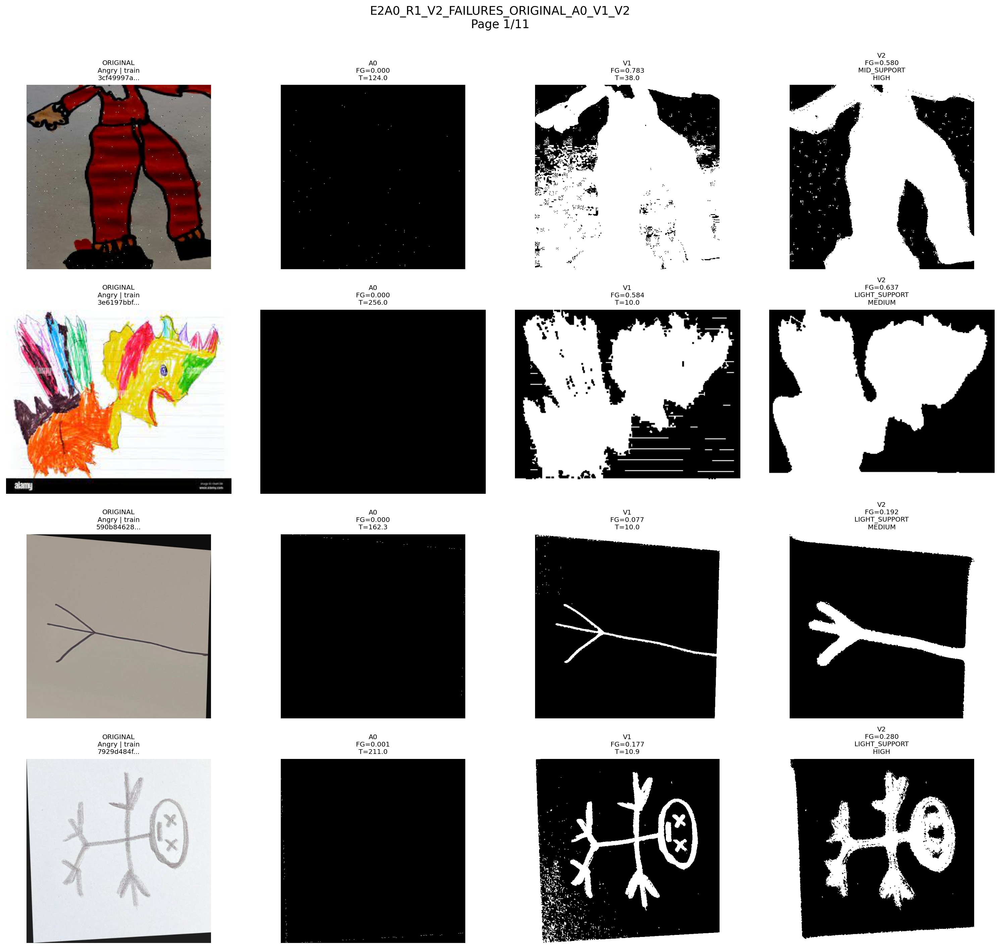


First CONTROL page:


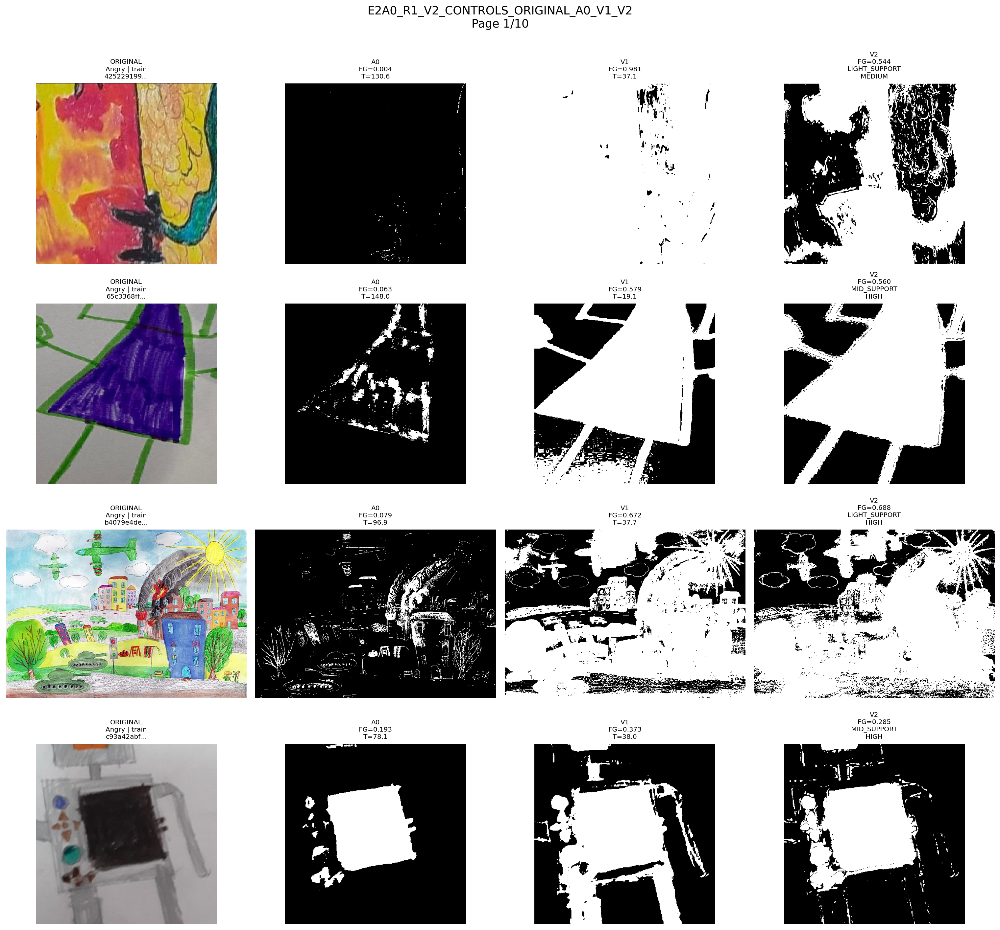


E2-A0-R1-V2 DEVELOPMENT PILOT COMPLETE

Development images: 84
Known A0 failures: 44
Existing A0 controls: 40

Files:
  Results: /content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E2/E2A_INTERPRETABLE_FEATURES/E2A0_R1_V2_PILOT/tables/E2A0_R1_V2_PILOT_RESULTS.csv
  QC summary: /content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E2/E2A_INTERPRETABLE_FEATURES/E2A0_R1_V2_PILOT/tables/E2A0_R1_V2_QC_SUMMARY.csv
  Support summary: /content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E2/E2A_INTERPRETABLE_FEATURES/E2A0_R1_V2_PILOT/tables/E2A0_R1_V2_SUPPORT_REGIME_SUMMARY.csv
  Comparison summary: /content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E2/E2A_INTERPRETABLE_FEATURES/E2A0_R1_V2_PILOT/tables/E2A0_R1_V2_COMPARISON_SUMMARY.csv
  Automatic diagnostics: /content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E2/E2A_INTERPRETABLE_FEATURES/E2A0_R1_V2_PILOT/tables/E2A0_R1_V2_AUTOMATIC_SUMMARY.csv
  Visual review CSV: /content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E2/E2A_INTERPRETABLE_FEATURES/E2A0_R1_V2_PILOT/tabl

In [ ]:
# ==================================================================================================
# DOAR MASTER THESIS
# E2-A0-R1-V2-PILOT — SUPPORT-AWARE DETERMINISTIC FOREGROUND EXTRACTION
#
# DEVELOPMENT PILOT ONLY
#
# PURPOSE
# -------
# Improve R1-V1 after visual review showed:
#
#   1. A0 often used absurdly high thresholds and lost valid drawings.
#   2. R1-V1 recovered many drawings successfully.
#   3. R1-V1 sometimes flooded backgrounds / shadows / photographed paper.
#   4. R1-V1 assumed a bright paper-like support.
#   5. Dataset images also include:
#        - dark supports
#        - photographed pages
#        - gradients / shadows
#        - full-canvas artwork
#        - drawings touching the image boundary
#
# V2 PRINCIPLE
# ------------
# First estimate whether a coherent support/background exists.
#
# IMAGE
#   |
#   |-- reliable LIGHT support
#   |-- reliable DARK support
#   |-- reliable MID-TONE support
#   |-- AMBIGUOUS / FULL-CANVAS support
#
# For reliable support:
#   - background colour estimated by deterministic border clustering
#   - polarity is NOT assumed
#   - global LAB difference + local contrast + chromatic evidence
#   - large smooth border-connected background floods are suppressed
#
# For ambiguous/full-canvas images:
#   - V2 DOES NOT pretend that blank paper was identified
#   - a conservative local-content mask is generated only for visualization
#   - QC status becomes AMBIGUOUS_SUPPORT
#
# IMPORTANT
# ---------
# - Same 84 DEVELOPMENT images from R1-V1.
# - Do NOT use the future unseen QC holdout yet.
# - Do NOT process all 2,883 drawings yet.
# - No classifier.
# - No new formal features.
# - No psychological rules.
# - Locked Test untouched.
#
# OUTPUT
# ------
# ORIGINAL | A0 | R1-V1 | R1-V2
#
# plus:
#   - support regime
#   - support confidence
#   - foreground ratios
#   - flood warnings
#   - QC transition tables
#   - visual review CSV
#
# ==================================================================================================

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
from datetime import datetime, timezone
from matplotlib.backends.backend_pdf import PdfPages
from IPython.display import display, Image as IPImage

import hashlib
import json
import math

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm


# ==================================================================================================
# 1. PATHS
# ==================================================================================================

DATASET_ROOT = Path(
    "/content/drive/MyDrive/Masters/Datasets/Combined_Drawing"
)

E2A0_ROOT = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E2/"
    "E2A_INTERPRETABLE_FEATURES"
)

SOURCE_FEATURE_FILE = (
    E2A0_ROOT
    / "tables"
    / "E2A_T1_INTERPRETABLE_FEATURES.csv"
)

V1_ROOT = (
    E2A0_ROOT
    / "E2A0_R1_PILOT_V1"
)

V1_RESULT_FILE = (
    V1_ROOT
    / "tables"
    / "E2A0_R1_PILOT_MASK_RESULTS.csv"
)

V2_ROOT = (
    E2A0_ROOT
    / "E2A0_R1_V2_PILOT"
)

TABLE_DIR = (
    V2_ROOT
    / "tables"
)

FIGURE_DIR = (
    V2_ROOT
    / "figures"
)

FAILURE_CONTACT_DIR = (
    FIGURE_DIR
    / "failure_contact_sheets"
)

CONTROL_CONTACT_DIR = (
    FIGURE_DIR
    / "control_contact_sheets"
)

INDIVIDUAL_FAILURE_DIR = (
    FIGURE_DIR
    / "failure_individual"
)

INDIVIDUAL_CONTROL_DIR = (
    FIGURE_DIR
    / "control_individual"
)

for directory in [
    V2_ROOT,
    TABLE_DIR,
    FIGURE_DIR,
    FAILURE_CONTACT_DIR,
    CONTROL_CONTACT_DIR,
    INDIVIDUAL_FAILURE_DIR,
    INDIVIDUAL_CONTROL_DIR,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ==================================================================================================
# 2. FROZEN SOURCE VERIFICATION
# ==================================================================================================

EXPECTED_E2A0_SHA256 = (
    "6ea50e3a9517e4681eda1f05e802b384e07b54295850d43fa8cd0a7dd78d1fda"
)


def sha256_file(path):

    hasher = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b"",
        ):

            hasher.update(chunk)

    return hasher.hexdigest()


assert SOURCE_FEATURE_FILE.exists(), SOURCE_FEATURE_FILE
assert V1_RESULT_FILE.exists(), V1_RESULT_FILE

actual_sha = sha256_file(
    SOURCE_FEATURE_FILE
)

assert actual_sha == EXPECTED_E2A0_SHA256, (
    "STOP: frozen E2-A0 feature table SHA changed."
)


print("=" * 112)
print("DOAR E2-A0-R1-V2-PILOT")
print("=" * 112)

print("Frozen E2-A0 SHA       :", actual_sha)
print("Development images     : SAME 84 FROM V1")
print("Training               : NONE")
print("Classifier             : NONE")
print("Expanded formal features: NONE")
print("Psychological rules    : NONE")
print("Locked Test            : NOT ACCESSED")


# ==================================================================================================
# 3. LOAD ORIGINAL E2-A0 TABLE
# ==================================================================================================

features = pd.read_csv(
    SOURCE_FEATURE_FILE
)

features["image_id"] = (
    features["image_id"]
    .astype(str)
)

assert len(features) == 2883
assert features["image_id"].is_unique

assert (
    features["split"]
    == "train"
).sum() == 2599

assert (
    features["split"]
    == "valid"
).sum() == 284

assert (
    features["split"]
    == "test"
).sum() == 0


# ==================================================================================================
# 4. LOAD EXACT 84-IMAGE DEVELOPMENT PILOT
# ==================================================================================================

pilot = pd.read_csv(
    V1_RESULT_FILE
)

pilot["image_id"] = (
    pilot["image_id"]
    .astype(str)
)

assert len(pilot) == 84
assert pilot["image_id"].is_unique

assert (
    pilot["pilot_group"]
    == "FLAGGED_FAILURE"
).sum() == 44

assert (
    pilot["pilot_group"]
    == "OK_CONTROL"
).sum() == 40


print()
print("✓ Development pilot loaded.")
print(
    "Flagged failures:",
    (
        pilot["pilot_group"]
        == "FLAGGED_FAILURE"
    ).sum()
)

print(
    "OK controls:",
    (
        pilot["pilot_group"]
        == "OK_CONTROL"
    ).sum()
)


# ==================================================================================================
# 5. ROBUST SCALE
# ==================================================================================================

def robust_mad(values):

    values = np.asarray(
        values,
        dtype=np.float64,
    )

    values = values[
        np.isfinite(values)
    ]

    if len(values) == 0:

        return 0.0

    median = np.median(
        values
    )

    mad = np.median(
        np.abs(
            values
            -
            median
        )
    )

    return float(
        1.4826
        * mad
    )


# ==================================================================================================
# 6. EXACT A0 MASK
# ==================================================================================================

def get_border_pixels(
    image_rgb
):

    h, w, _ = (
        image_rgb.shape
    )

    by = max(
        2,
        int(
            round(
                h
                * 0.04
            )
        ),
    )

    bx = max(
        2,
        int(
            round(
                w
                * 0.04
            )
        ),
    )

    top = (
        image_rgb[
            :by,
            :,
            :
        ]
        .reshape(
            -1,
            3
        )
    )

    bottom = (
        image_rgb[
            h-by:,
            :,
            :
        ]
        .reshape(
            -1,
            3
        )
    )

    left = (
        image_rgb[
            :,
            :bx,
            :
        ]
        .reshape(
            -1,
            3
        )
    )

    right = (
        image_rgb[
            :,
            w-bx:,
            :
        ]
        .reshape(
            -1,
            3
        )
    )

    return np.concatenate(
        [
            top,
            bottom,
            left,
            right,
        ],
        axis=0,
    )


def cleanup_components(
    raw_mask,
    minimum_fraction=0.000005,
):

    raw_mask = (
        raw_mask
        > 0
    ).astype(
        np.uint8
    )

    h, w = (
        raw_mask.shape
    )

    image_area = (
        h
        * w
    )

    min_area = max(
        3,
        int(
            round(
                image_area
                * minimum_fraction
            )
        ),
    )

    n_labels, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            raw_mask,
            connectivity=8,
        )
    )

    cleaned = np.zeros_like(
        raw_mask
    )

    for label in range(
        1,
        n_labels
    ):

        area = stats[
            label,
            cv2.CC_STAT_AREA
        ]

        if area >= min_area:

            cleaned[
                labels
                == label
            ] = 1

    return (
        cleaned,
        min_area,
    )


def build_a0_mask(
    image_rgb
):

    lab = cv2.cvtColor(
        image_rgb,
        cv2.COLOR_RGB2LAB,
    ).astype(
        np.float32
    )

    border_rgb = get_border_pixels(
        image_rgb
    )

    border_lab = cv2.cvtColor(
        border_rgb.reshape(
            -1,
            1,
            3
        ),
        cv2.COLOR_RGB2LAB,
    ).reshape(
        -1,
        3
    ).astype(
        np.float32
    )

    bg_lab = np.median(
        border_lab,
        axis=0,
    )

    border_dist = np.linalg.norm(
        border_lab
        -
        bg_lab[
            None,
            :
        ],
        axis=1,
    )

    background_noise = float(
        np.percentile(
            border_dist,
            98
        )
    )

    threshold = max(
        10.0,
        background_noise
        + 3.0,
    )

    distance = np.linalg.norm(
        lab
        -
        bg_lab[
            None,
            None,
            :
        ],
        axis=2,
    )

    raw_mask = (
        distance
        >
        threshold
    ).astype(
        np.uint8
    )

    cleaned, min_area = (
        cleanup_components(
            raw_mask,
            0.000005,
        )
    )

    return {
        "mask":
            cleaned,

        "threshold":
            float(
                threshold
            ),

        "background_noise":
            background_noise,

        "background_lab":
            bg_lab,

        "min_component_area":
            min_area,
    }


# ==================================================================================================
# 7. EXACT R1-V1 MASK
#
# This reproduces the previous pilot so we can generate:
#
# ORIGINAL | A0 | V1 | V2
# ==================================================================================================

def build_border_selector(
    height,
    width,
    fraction=0.06,
):

    by = max(
        2,
        int(
            round(
                height
                * fraction
            )
        ),
    )

    bx = max(
        2,
        int(
            round(
                width
                * fraction
            )
        ),
    )

    selector = np.zeros(
        (
            height,
            width
        ),
        dtype=bool,
    )

    selector[
        :by,
        :
    ] = True

    selector[
        height-by:,
        :
    ] = True

    selector[
        :,
        :bx
    ] = True

    selector[
        :,
        width-bx:
    ] = True

    return selector


def build_v1_mask(
    image_rgb
):

    lab = cv2.cvtColor(
        image_rgb,
        cv2.COLOR_RGB2LAB,
    ).astype(
        np.float32
    )

    hsv = cv2.cvtColor(
        image_rgb,
        cv2.COLOR_RGB2HSV,
    ).astype(
        np.float32
    )

    gray = cv2.cvtColor(
        image_rgb,
        cv2.COLOR_RGB2GRAY,
    ).astype(
        np.float32
    )

    h, w = (
        gray.shape
    )

    area = (
        h
        * w
    )

    value = (
        hsv[
            :,
            :,
            2
        ]
    )

    saturation = (
        hsv[
            :,
            :,
            1
        ]
    )

    bright_cut = max(
        float(
            np.percentile(
                value,
                60
            )
        ),
        150.0,
    )

    saturation_cut = float(
        np.percentile(
            saturation,
            45
        )
    )

    saturation_cut = min(
        max(
            saturation_cut,
            12.0,
        ),
        70.0,
    )

    likely_global = (
        (
            value
            >= bright_cut
        )
        &
        (
            saturation
            <= saturation_cut
        )
    )

    border_selector = (
        build_border_selector(
            h,
            w,
            0.06,
        )
    )

    likely_border = (
        likely_global
        &
        border_selector
    )

    minimum_candidates = max(
        100,
        int(
            round(
                area
                * 0.002
            )
        ),
    )

    if (
        likely_border.sum()
        >= minimum_candidates
    ):

        candidate_selector = (
            likely_border
        )

        paper_source = (
            "border_bright_low_saturation"
        )

    elif (
        likely_global.sum()
        >= minimum_candidates
    ):

        candidate_selector = (
            likely_global
        )

        paper_source = (
            "global_bright_low_saturation"
        )

    else:

        fallback_cut = float(
            np.percentile(
                value,
                90
            )
        )

        candidate_selector = (
            value
            >= fallback_cut
        )

        paper_source = (
            "brightest_10_percent_fallback"
        )

    candidate_lab = (
        lab[
            candidate_selector
        ]
    )

    candidate_gray = (
        gray[
            candidate_selector
        ]
    )

    candidate_sat = (
        saturation[
            candidate_selector
        ]
    )

    bg_lab = np.median(
        candidate_lab,
        axis=0,
    )

    bg_gray = float(
        np.median(
            candidate_gray
        )
    )

    bg_sat = float(
        np.median(
            candidate_sat
        )
    )

    lab_distance = np.linalg.norm(
        lab
        -
        bg_lab[
            None,
            None,
            :
        ],
        axis=2,
    )

    candidate_distance = np.linalg.norm(
        candidate_lab
        -
        bg_lab[
            None,
            :
        ],
        axis=1,
    )

    distance_median = float(
        np.median(
            candidate_distance
        )
    )

    distance_scale = (
        robust_mad(
            candidate_distance
        )
    )

    lab_threshold = (
        distance_median
        +
        4.0
        * distance_scale
        +
        3.0
    )

    lab_threshold = float(
        np.clip(
            lab_threshold,
            10.0,
            38.0,
        )
    )

    mask_lab = (
        lab_distance
        >
        lab_threshold
    )

    candidate_gray_scale = (
        robust_mad(
            candidate_gray
        )
    )

    darkness_delta = max(
        15.0,
        4.0
        * candidate_gray_scale,
    )

    darkness_delta = min(
        darkness_delta,
        55.0,
    )

    dark_threshold = (
        bg_gray
        -
        darkness_delta
    )

    mask_dark = (
        gray
        <
        dark_threshold
    )

    chromatic_threshold = max(
        35.0,
        bg_sat
        +
        25.0,
    )

    chromatic_threshold = min(
        chromatic_threshold,
        90.0,
    )

    mask_chromatic = (
        (
            saturation
            >
            chromatic_threshold
        )
        &
        (
            lab_distance
            >
            max(
                7.0,
                lab_threshold
                * 0.55
            )
        )
    )

    raw = (
        mask_lab
        |
        mask_dark
        |
        mask_chromatic
    ).astype(
        np.uint8
    )

    cleaned, min_area = (
        cleanup_components(
            raw,
            0.000003,
        )
    )

    kernel = np.ones(
        (
            2,
            2
        ),
        dtype=np.uint8,
    )

    cleaned = cv2.morphologyEx(
        cleaned,
        cv2.MORPH_CLOSE,
        kernel,
        iterations=1,
    )

    return {
        "mask":
            cleaned,

        "lab_threshold":
            lab_threshold,

        "paper_source":
            paper_source,

        "background_lab":
            bg_lab,

        "min_component_area":
            min_area,
    }


# ==================================================================================================
# 8. V2 BORDER SAMPLING
#
# Use all four sides explicitly.
# The dominant support must appear spatially across multiple sides.
# ==================================================================================================

def border_samples_with_side_ids(
    image_rgb,
    fraction=0.08,
):

    h, w, _ = (
        image_rgb.shape
    )

    by = max(
        2,
        int(
            round(
                h
                * fraction
            )
        ),
    )

    bx = max(
        2,
        int(
            round(
                w
                * fraction
            )
        ),
    )

    samples = []
    side_ids = []

    top = (
        image_rgb[
            :by,
            :,
            :
        ]
        .reshape(
            -1,
            3
        )
    )

    samples.append(
        top
    )

    side_ids.extend(
        [0]
        * len(
            top
        )
    )

    bottom = (
        image_rgb[
            h-by:,
            :,
            :
        ]
        .reshape(
            -1,
            3
        )
    )

    samples.append(
        bottom
    )

    side_ids.extend(
        [1]
        * len(
            bottom
        )
    )

    left = (
        image_rgb[
            :,
            :bx,
            :
        ]
        .reshape(
            -1,
            3
        )
    )

    samples.append(
        left
    )

    side_ids.extend(
        [2]
        * len(
            left
        )
    )

    right = (
        image_rgb[
            :,
            w-bx:,
            :
        ]
        .reshape(
            -1,
            3
        )
    )

    samples.append(
        right
    )

    side_ids.extend(
        [3]
        * len(
            right
        )
    )

    rgb = np.concatenate(
        samples,
        axis=0,
    )

    side_ids = np.asarray(
        side_ids,
        dtype=np.int32,
    )

    return (
        rgb,
        side_ids,
    )


# ==================================================================================================
# 9. DETERMINISTIC SUPPORT ESTIMATION
#
# No bright-paper assumption.
#
# Border LAB pixels are clustered into 3 colour/support candidates.
#
# Candidate support score considers:
#   - how dominant it is at the border
#   - whether it occurs on several sides
#   - how compact the cluster is
#
# ==================================================================================================

def estimate_support_v2(
    image_rgb
):

    border_rgb, side_ids = (
        border_samples_with_side_ids(
            image_rgb,
            fraction=0.08,
        )
    )

    border_lab = cv2.cvtColor(
        border_rgb.reshape(
            -1,
            1,
            3
        ),
        cv2.COLOR_RGB2LAB,
    ).reshape(
        -1,
        3
    ).astype(
        np.float32
    )


    # ----------------------------------------------------------------------------------------------
    # Limit clustering size deterministically for speed.
    # ----------------------------------------------------------------------------------------------

    max_samples = 12000

    if len(
        border_lab
    ) > max_samples:

        indices = np.linspace(
            0,
            len(
                border_lab
            )
            - 1,
            max_samples,
            dtype=int,
        )

        cluster_lab = (
            border_lab[
                indices
            ]
        )

        cluster_sides = (
            side_ids[
                indices
            ]
        )

    else:

        cluster_lab = (
            border_lab
        )

        cluster_sides = (
            side_ids
        )


    # ----------------------------------------------------------------------------------------------
    # Deterministic K-means.
    # ----------------------------------------------------------------------------------------------

    cv2.setRNGSeed(
        20260824
    )

    criteria = (
        cv2.TERM_CRITERIA_EPS
        +
        cv2.TERM_CRITERIA_MAX_ITER,
        40,
        0.1,
    )

    compactness, labels, centers = (
        cv2.kmeans(
            cluster_lab,
            3,
            None,
            criteria,
            1,
            cv2.KMEANS_PP_CENTERS,
        )
    )

    labels = (
        labels
        .reshape(
            -1
        )
    )

    cluster_records = []


    for k in range(
        3
    ):

        selector = (
            labels
            == k
        )

        count = int(
            selector.sum()
        )

        if count == 0:

            continue

        ratio = (
            count
            /
            len(
                labels
            )
        )

        values = (
            cluster_lab[
                selector
            ]
        )

        center = (
            centers[
                k
            ]
        )

        distances = np.linalg.norm(
            values
            -
            center[
                None,
                :
            ],
            axis=1,
        )

        dispersion = float(
            np.median(
                distances
            )
        )

        dispersion_scale = (
            robust_mad(
                distances
            )
        )

        covered_sides = 0

        side_fractions = []

        for side in range(
            4
        ):

            side_selector = (
                cluster_sides
                == side
            )

            side_total = int(
                side_selector.sum()
            )

            if side_total == 0:

                side_fraction = 0.0

            else:

                side_fraction = float(
                    (
                        selector
                        &
                        side_selector
                    ).sum()
                    /
                    side_total
                )

            side_fractions.append(
                side_fraction
            )

            if (
                side_fraction
                >= 0.05
            ):

                covered_sides += 1


        side_factor = (
            0.70
            +
            0.30
            * (
                covered_sides
                /
                4.0
            )
        )

        compactness_factor = (
            1.0
            /
            (
                1.0
                +
                dispersion
                /
                25.0
            )
        )

        score = (
            ratio
            *
            side_factor
            *
            compactness_factor
        )


        cluster_records.append(
            {
                "cluster":
                    k,

                "count":
                    count,

                "ratio":
                    ratio,

                "covered_sides":
                    covered_sides,

                "side_fractions":
                    side_fractions,

                "dispersion":
                    dispersion,

                "dispersion_scale":
                    dispersion_scale,

                "score":
                    score,

                "center":
                    center,
            }
        )


    best = max(
        cluster_records,
        key=lambda x: x[
            "score"
        ],
    )


    support_center = (
        np.asarray(
            best[
                "center"
            ],
            dtype=np.float32,
        )
    )


    # ----------------------------------------------------------------------------------------------
    # Support radius around dominant cluster.
    # ----------------------------------------------------------------------------------------------

    best_selector = (
        labels
        == best[
            "cluster"
        ]
    )

    best_values = (
        cluster_lab[
            best_selector
        ]
    )

    best_distances = np.linalg.norm(
        best_values
        -
        support_center[
            None,
            :
        ],
        axis=1,
    )

    median_distance = float(
        np.median(
            best_distances
        )
    )

    distance_scale = (
        robust_mad(
            best_distances
        )
    )

    support_radius = (
        median_distance
        +
        4.0
        * distance_scale
        +
        2.0
    )

    support_radius = float(
        np.clip(
            support_radius,
            8.0,
            28.0,
        )
    )


    # ----------------------------------------------------------------------------------------------
    # Determine how much of whole image resembles that support.
    # ----------------------------------------------------------------------------------------------

    h, w = (
        image_rgb.shape[
            :2
        ]
    )

    scale = min(
        1.0,
        320.0
        /
        max(
            h,
            w
        ),
    )

    small_w = max(
        32,
        int(
            round(
                w
                * scale
            )
        ),
    )

    small_h = max(
        32,
        int(
            round(
                h
                * scale
            )
        ),
    )

    small_rgb = cv2.resize(
        image_rgb,
        (
            small_w,
            small_h
        ),
        interpolation=cv2.INTER_AREA,
    )

    small_lab = cv2.cvtColor(
        small_rgb,
        cv2.COLOR_RGB2LAB,
    ).astype(
        np.float32
    )

    whole_distance = np.linalg.norm(
        small_lab
        -
        support_center[
            None,
            None,
            :
        ],
        axis=2,
    )

    whole_support_fraction = float(
        (
            whole_distance
            <= support_radius
        ).mean()
    )


    dominant_ratio = float(
        best[
            "ratio"
        ]
    )

    covered_sides = int(
        best[
            "covered_sides"
        ]
    )

    dispersion = float(
        best[
            "dispersion"
        ]
    )


    # ----------------------------------------------------------------------------------------------
    # Support confidence.
    # ----------------------------------------------------------------------------------------------

    if (
        dominant_ratio
        >= 0.55
        and
        covered_sides
        == 4
        and
        whole_support_fraction
        >= 0.20
        and
        dispersion
        <= 18.0
    ):

        confidence = (
            "HIGH"
        )

    elif (
        dominant_ratio
        >= 0.35
        and
        covered_sides
        >= 3
        and
        whole_support_fraction
        >= 0.12
        and
        dispersion
        <= 25.0
    ):

        confidence = (
            "MEDIUM"
        )

    else:

        confidence = (
            "LOW"
        )


    # ----------------------------------------------------------------------------------------------
    # Support regime.
    #
    # OpenCV LAB L is 0–255.
    # ----------------------------------------------------------------------------------------------

    L = float(
        support_center[
            0
        ]
    )

    if confidence == "LOW":

        regime = (
            "AMBIGUOUS_FULL_CANVAS"
        )

    elif L >= 170:

        regime = (
            "LIGHT_SUPPORT"
        )

    elif L <= 90:

        regime = (
            "DARK_SUPPORT"
        )

    else:

        regime = (
            "MID_SUPPORT"
        )


    return {
        "support_center_lab":
            support_center,

        "support_radius":
            support_radius,

        "dominant_border_ratio":
            dominant_ratio,

        "covered_sides":
            covered_sides,

        "whole_support_fraction":
            whole_support_fraction,

        "cluster_dispersion":
            dispersion,

        "support_confidence":
            confidence,

        "support_regime":
            regime,

        "cluster_score":
            float(
                best[
                    "score"
                ]
            ),
    }


# ==================================================================================================
# 10. REMOVE LARGE SMOOTH BACKGROUND-LIKE COMPONENTS
#
# Applied ONLY when support is reliable.
#
# Intended to suppress:
#   - smooth shadows
#   - photo borders
#   - broad lighting gradients
#
# while retaining:
#   - actual lines
#   - chromatic regions
#   - strongly different filled areas
#
# ==================================================================================================

def suppress_smooth_border_floods(
    mask,
    local_residual,
    saturation_difference,
    local_threshold,
):

    mask = (
        mask
        > 0
    ).astype(
        np.uint8
    )

    h, w = (
        mask.shape
    )

    image_area = (
        h
        * w
    )

    n_labels, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            mask,
            connectivity=8,
        )
    )

    result = (
        mask.copy()
    )


    for label in range(
        1,
        n_labels
    ):

        component = (
            labels
            == label
        )

        area = int(
            stats[
                label,
                cv2.CC_STAT_AREA
            ]
        )

        area_fraction = (
            area
            /
            image_area
        )

        x = int(
            stats[
                label,
                cv2.CC_STAT_LEFT
            ]
        )

        y = int(
            stats[
                label,
                cv2.CC_STAT_TOP
            ]
        )

        width = int(
            stats[
                label,
                cv2.CC_STAT_WIDTH
            ]
        )

        height = int(
            stats[
                label,
                cv2.CC_STAT_HEIGHT
            ]
        )

        touches_border = (
            x <= 1
            or
            y <= 1
            or
            (
                x
                +
                width
            )
            >= (
                w
                - 1
            )
            or
            (
                y
                +
                height
            )
            >= (
                h
                - 1
            )
        )


        if (
            not touches_border
            or
            area_fraction
            < 0.15
        ):

            continue


        mean_local = float(
            np.mean(
                local_residual[
                    component
                ]
            )
        )

        mean_sat_difference = float(
            np.mean(
                saturation_difference[
                    component
                ]
            )
        )


        # ------------------------------------------------------------------------------------------
        # Large smooth border component:
        # likely page shadow / lighting / external border rather than graphic content.
        # ------------------------------------------------------------------------------------------

        if (
            mean_local
            <
            (
                local_threshold
                * 1.15
            )
            and
            mean_sat_difference
            <
            18.0
        ):

            result[
                component
            ] = 0


    return result


# ==================================================================================================
# 11. V2 MASK
# ==================================================================================================

def build_v2_mask(
    image_rgb
):

    lab = cv2.cvtColor(
        image_rgb,
        cv2.COLOR_RGB2LAB,
    ).astype(
        np.float32
    )

    hsv = cv2.cvtColor(
        image_rgb,
        cv2.COLOR_RGB2HSV,
    ).astype(
        np.float32
    )

    gray = cv2.cvtColor(
        image_rgb,
        cv2.COLOR_RGB2GRAY,
    ).astype(
        np.float32
    )


    L_channel = (
        lab[
            :,
            :,
            0
        ]
    )

    saturation = (
        hsv[
            :,
            :,
            1
        ]
    )


    support = estimate_support_v2(
        image_rgb
    )

    support_center = (
        support[
            "support_center_lab"
        ]
    )

    support_radius = float(
        support[
            "support_radius"
        ]
    )

    regime = (
        support[
            "support_regime"
        ]
    )

    confidence = (
        support[
            "support_confidence"
        ]
    )


    h, w = (
        gray.shape
    )

    image_area = (
        h
        * w
    )


    # ----------------------------------------------------------------------------------------------
    # Distance from dominant support colour.
    # ----------------------------------------------------------------------------------------------

    distance = np.linalg.norm(
        lab
        -
        support_center[
            None,
            None,
            :
        ],
        axis=2,
    )


    # ----------------------------------------------------------------------------------------------
    # Slowly varying local background.
    #
    # This reduces sensitivity to photo lighting gradients.
    # ----------------------------------------------------------------------------------------------

    sigma = max(
        5.0,
        min(
            h,
            w
        )
        /
        55.0,
    )


    local_L_background = cv2.GaussianBlur(
        L_channel,
        (
            0,
            0
        ),
        sigmaX=sigma,
        sigmaY=sigma,
    )


    local_residual = np.abs(
        L_channel
        -
        local_L_background
    )


    local_sat_background = cv2.GaussianBlur(
        saturation,
        (
            0,
            0
        ),
        sigmaX=sigma,
        sigmaY=sigma,
    )


    local_sat_residual = np.abs(
        saturation
        -
        local_sat_background
    )


    # ==============================================================================================
    # 11A. AMBIGUOUS / FULL-CANVAS MODE
    #
    # We do NOT claim to know the blank-page/background support.
    #
    # Build conservative structural-content mask only for visualization.
    # Final QC remains AMBIGUOUS_SUPPORT.
    # ==============================================================================================

    if regime == "AMBIGUOUS_FULL_CANVAS":

        local_scale = robust_mad(
            local_residual.reshape(
                -1
            )
        )

        local_threshold = float(
            np.clip(
                np.median(
                    local_residual
                )
                +
                4.5
                * local_scale,
                6.0,
                22.0,
            )
        )


        sat_scale = robust_mad(
            local_sat_residual.reshape(
                -1
            )
        )

        sat_threshold = float(
            np.clip(
                np.median(
                    local_sat_residual
                )
                +
                4.0
                * sat_scale,
                8.0,
                35.0,
            )
        )


        gray_u8 = np.clip(
            gray,
            0,
            255,
        ).astype(
            np.uint8
        )


        edges = cv2.Canny(
            gray_u8,
            50,
            150,
        ) > 0


        edge_kernel = np.ones(
            (
                2,
                2
            ),
            dtype=np.uint8,
        )


        edges = (
            cv2.dilate(
                edges.astype(
                    np.uint8
                ),
                edge_kernel,
                iterations=1,
            )
            > 0
        )


        raw = (
            (
                local_residual
                >
                local_threshold
            )
            |
            (
                local_sat_residual
                >
                sat_threshold
            )
            |
            edges
        ).astype(
            np.uint8
        )


        cleaned, min_area = (
            cleanup_components(
                raw,
                0.000003,
            )
        )


        final_mask = (
            cleaned
        )


        return {
            "mask":
                final_mask,

            "support_regime":
                regime,

            "support_confidence":
                confidence,

            "support_radius":
                support_radius,

            "dominant_border_ratio":
                support[
                    "dominant_border_ratio"
                ],

            "covered_sides":
                support[
                    "covered_sides"
                ],

            "whole_support_fraction":
                support[
                    "whole_support_fraction"
                ],

            "cluster_dispersion":
                support[
                    "cluster_dispersion"
                ],

            "global_threshold":
                np.nan,

            "local_threshold":
                local_threshold,

            "sat_threshold":
                sat_threshold,

            "mask_strategy":
                "AMBIGUOUS_LOCAL_CONTENT_ONLY",

            "min_component_area":
                min_area,
        }


    # ==============================================================================================
    # 11B. RELIABLE SUPPORT
    # ==============================================================================================

    support_selector = (
        distance
        <= support_radius
    )


    # ----------------------------------------------------------------------------------------------
    # Guard against too few support pixels.
    # ----------------------------------------------------------------------------------------------

    if (
        support_selector.sum()
        <
        max(
            100,
            int(
                0.002
                * image_area
            ),
        )
    ):

        # Conservative fallback.
        support_selector = (
            distance
            <= (
                support_radius
                * 1.5
            )
        )


    support_L = (
        L_channel[
            support_selector
        ]
    )

    support_sat = (
        saturation[
            support_selector
        ]
    )

    support_local_residual = (
        local_residual[
            support_selector
        ]
    )


    bg_L = float(
        np.median(
            support_L
        )
    )

    bg_sat = float(
        np.median(
            support_sat
        )
    )


    # ----------------------------------------------------------------------------------------------
    # Global support-difference threshold.
    # ----------------------------------------------------------------------------------------------

    global_threshold = float(
        np.clip(
            support_radius
            +
            6.0,
            14.0,
            42.0,
        )
    )


    # ----------------------------------------------------------------------------------------------
    # Local line/stroke threshold.
    # ----------------------------------------------------------------------------------------------

    local_threshold = (
        np.median(
            support_local_residual
        )
        +
        5.0
        * robust_mad(
            support_local_residual
        )
    )

    local_threshold = float(
        np.clip(
            local_threshold,
            5.0,
            18.0,
        )
    )


    # ----------------------------------------------------------------------------------------------
    # Luminance deviation threshold.
    #
    # Symmetric:
    # works for dark ink on light support AND light chalk on dark support.
    # ----------------------------------------------------------------------------------------------

    L_scale = robust_mad(
        support_L
    )

    luminance_delta = float(
        np.clip(
            max(
                22.0,
                4.0
                * L_scale,
            ),
            22.0,
            55.0,
        )
    )


    luminance_difference = np.abs(
        L_channel
        -
        bg_L
    )


    strong_luminance = (
        luminance_difference
        >
        luminance_delta
    )


    # ----------------------------------------------------------------------------------------------
    # Chromatic difference.
    # ----------------------------------------------------------------------------------------------

    sat_scale = robust_mad(
        support_sat
    )

    saturation_delta = float(
        np.clip(
            max(
                22.0,
                4.0
                * sat_scale,
            ),
            22.0,
            60.0,
        )
    )


    saturation_difference = np.abs(
        saturation
        -
        bg_sat
    )


    chromatic_difference = (
        saturation_difference
        >
        saturation_delta
    )


    # ----------------------------------------------------------------------------------------------
    # Local structure.
    # ----------------------------------------------------------------------------------------------

    local_structure = (
        local_residual
        >
        local_threshold
    )


    # ----------------------------------------------------------------------------------------------
    # Candidate foreground.
    #
    # A pixel can become foreground if:
    #
    # A) local line/edge evidence
    #
    # OR
    #
    # B) it is globally different from support AND has strong luminance
    #    or chromatic evidence.
    #
    # This prevents broad mild illumination gradients from entering solely
    # because they differ somewhat from one global support centre.
    # ----------------------------------------------------------------------------------------------

    global_difference = (
        distance
        >
        global_threshold
    )


    raw = (
        local_structure
        |
        (
            global_difference
            &
            (
                strong_luminance
                |
                chromatic_difference
            )
        )
    ).astype(
        np.uint8
    )


    # ----------------------------------------------------------------------------------------------
    # Remove huge smooth border-connected floods.
    # ----------------------------------------------------------------------------------------------

    raw = suppress_smooth_border_floods(
        mask=
            raw,

        local_residual=
            local_residual,

        saturation_difference=
            saturation_difference,

        local_threshold=
            local_threshold,
    )


    cleaned, min_area = (
        cleanup_components(
            raw,
            0.000003,
        )
    )


    # ----------------------------------------------------------------------------------------------
    # Minimal closing only.
    # ----------------------------------------------------------------------------------------------

    kernel = np.ones(
        (
            2,
            2
        ),
        dtype=np.uint8,
    )


    cleaned = cv2.morphologyEx(
        cleaned,
        cv2.MORPH_CLOSE,
        kernel,
        iterations=1,
    )


    return {
        "mask":
            cleaned,

        "support_regime":
            regime,

        "support_confidence":
            confidence,

        "support_radius":
            support_radius,

        "dominant_border_ratio":
            support[
                "dominant_border_ratio"
            ],

        "covered_sides":
            support[
                "covered_sides"
            ],

        "whole_support_fraction":
            support[
                "whole_support_fraction"
            ],

        "cluster_dispersion":
            support[
                "cluster_dispersion"
            ],

        "global_threshold":
            global_threshold,

        "local_threshold":
            local_threshold,

        "sat_threshold":
            saturation_delta,

        "mask_strategy":
            "SUPPORT_AWARE_GLOBAL_PLUS_LOCAL",

        "min_component_area":
            min_area,
    }


# ==================================================================================================
# 12. V2 QC CLASSIFICATION
#
# IMPORTANT:
#
# VERY_HIGH_FOREGROUND is now a warning, not an automatic segmentation failure.
#
# AMBIGUOUS_SUPPORT explicitly identifies images where a reliable support/background
# could not be inferred.
# ==================================================================================================

def border_foreground_fraction(
    mask,
    fraction=0.05,
):

    h, w = (
        mask.shape
    )

    selector = (
        build_border_selector(
            h,
            w,
            fraction,
        )
    )

    return float(
        (
            mask[
                selector
            ]
            > 0
        ).mean()
    )


def v2_qc_status(
    foreground_ratio,
    border_fg_ratio,
    support_regime,
):

    if (
        support_regime
        == "AMBIGUOUS_FULL_CANVAS"
    ):

        return (
            "AMBIGUOUS_SUPPORT"
        )

    if foreground_ratio <= 0:

        return (
            "NO_FOREGROUND"
        )

    if foreground_ratio < 0.001:

        return (
            "VERY_LOW_FOREGROUND"
        )

    if (
        foreground_ratio
        > 0.80
    ):

        return (
            "VERY_HIGH_FOREGROUND"
        )

    if (
        foreground_ratio
        > 0.50
        and
        border_fg_ratio
        > 0.75
    ):

        return (
            "POSSIBLE_BACKGROUND_FLOOD"
        )

    return (
        "OK"
    )


# ==================================================================================================
# 13. RUN A0 / V1 / V2 ON SAME 84 DEVELOPMENT IMAGES
# ==================================================================================================

rows = []


for _, row in tqdm(
    pilot.iterrows(),
    total=len(pilot),
    desc="E2-A0 R1-V2 development pilot",
):

    image_path = (
        DATASET_ROOT
        / row[
            "relative_path"
        ]
    )


    with Image.open(
        image_path
    ) as image_file:

        image_rgb = np.asarray(
            image_file.convert(
                "RGB"
            )
        )


    a0 = build_a0_mask(
        image_rgb
    )

    v1 = build_v1_mask(
        image_rgb
    )

    v2 = build_v2_mask(
        image_rgb
    )


    a0_ratio = float(
        a0[
            "mask"
        ].mean()
    )

    v1_ratio = float(
        v1[
            "mask"
        ].mean()
    )

    v2_ratio = float(
        v2[
            "mask"
        ].mean()
    )


    v2_border_ratio = (
        border_foreground_fraction(
            v2[
                "mask"
            ]
        )
    )


    qc_v2 = v2_qc_status(
        foreground_ratio=
            v2_ratio,

        border_fg_ratio=
            v2_border_ratio,

        support_regime=
            v2[
                "support_regime"
            ],
    )


    rows.append(
        {
            "pilot_group":
                row[
                    "pilot_group"
                ],

            "image_id":
                str(
                    row[
                        "image_id"
                    ]
                ),

            "split":
                row[
                    "split"
                ],

            "true_class":
                row[
                    "true_class"
                ],

            "relative_path":
                row[
                    "relative_path"
                ],

            "a0_original_qc":
                row[
                    "a0_qc_status"
                ],

            "a0_foreground_ratio":
                a0_ratio,

            "a0_threshold":
                float(
                    a0[
                        "threshold"
                    ]
                ),

            "v1_foreground_ratio":
                v1_ratio,

            "v1_lab_threshold":
                float(
                    v1[
                        "lab_threshold"
                    ]
                ),

            "v1_paper_source":
                v1[
                    "paper_source"
                ],

            "v2_foreground_ratio":
                v2_ratio,

            "v2_border_foreground_ratio":
                v2_border_ratio,

            "v2_qc_status":
                qc_v2,

            "v2_support_regime":
                v2[
                    "support_regime"
                ],

            "v2_support_confidence":
                v2[
                    "support_confidence"
                ],

            "v2_support_radius":
                float(
                    v2[
                        "support_radius"
                    ]
                ),

            "v2_dominant_border_ratio":
                float(
                    v2[
                        "dominant_border_ratio"
                    ]
                ),

            "v2_covered_sides":
                int(
                    v2[
                        "covered_sides"
                    ]
                ),

            "v2_whole_support_fraction":
                float(
                    v2[
                        "whole_support_fraction"
                    ]
                ),

            "v2_cluster_dispersion":
                float(
                    v2[
                        "cluster_dispersion"
                    ]
                ),

            "v2_global_threshold":
                v2[
                    "global_threshold"
                ],

            "v2_local_threshold":
                float(
                    v2[
                        "local_threshold"
                    ]
                ),

            "v2_saturation_threshold":
                float(
                    v2[
                        "sat_threshold"
                    ]
                ),

            "v2_mask_strategy":
                v2[
                    "mask_strategy"
                ],
        }
    )


results = pd.DataFrame(
    rows
)


RESULT_FILE = (
    TABLE_DIR
    / "E2A0_R1_V2_PILOT_RESULTS.csv"
)


results.to_csv(
    RESULT_FILE,
    index=False,
)


print()
print(
    "✓ V2 processing complete:",
    len(
        results
    ),
)


# ==================================================================================================
# 14. SUPPORT REGIME SUMMARY
# ==================================================================================================

support_summary = (
    results
    .groupby(
        [
            "pilot_group",
            "v2_support_regime",
            "v2_support_confidence",
        ],
        dropna=False,
    )
    .size()
    .reset_index(
        name="count"
    )
)


SUPPORT_SUMMARY_FILE = (
    TABLE_DIR
    / "E2A0_R1_V2_SUPPORT_REGIME_SUMMARY.csv"
)


support_summary.to_csv(
    SUPPORT_SUMMARY_FILE,
    index=False,
)


print()
print("=" * 112)
print("V2 SUPPORT REGIME SUMMARY")
print("=" * 112)

print(
    support_summary.to_string(
        index=False
    )
)


# ==================================================================================================
# 15. QC SUMMARY
# ==================================================================================================

qc_summary = (
    results
    .groupby(
        [
            "pilot_group",
            "v2_qc_status",
        ],
        dropna=False,
    )
    .size()
    .reset_index(
        name="count"
    )
)


group_totals = (
    results
    .groupby(
        "pilot_group"
    )
    .size()
    .rename(
        "group_total"
    )
    .reset_index()
)


qc_summary = (
    qc_summary
    .merge(
        group_totals,
        on="pilot_group",
        how="left",
    )
)


qc_summary[
    "percentage"
] = (
    100.0
    * qc_summary[
        "count"
    ]
    /
    qc_summary[
        "group_total"
    ]
)


QC_SUMMARY_FILE = (
    TABLE_DIR
    / "E2A0_R1_V2_QC_SUMMARY.csv"
)


qc_summary.to_csv(
    QC_SUMMARY_FILE,
    index=False,
)


print()
print("=" * 112)
print("V2 QC SUMMARY")
print("=" * 112)

print(
    qc_summary.to_string(
        index=False
    )
)


# ==================================================================================================
# 16. A0 → V1 → V2 SUMMARY
# ==================================================================================================

comparison_summary = (
    results
    .groupby(
        "pilot_group"
    )
    .agg(
        n=(
            "image_id",
            "size"
        ),

        median_A0_FG=(
            "a0_foreground_ratio",
            "median"
        ),

        median_V1_FG=(
            "v1_foreground_ratio",
            "median"
        ),

        median_V2_FG=(
            "v2_foreground_ratio",
            "median"
        ),

        median_A0_threshold=(
            "a0_threshold",
            "median"
        ),

        median_V1_threshold=(
            "v1_lab_threshold",
            "median"
        ),

        median_V2_global_threshold=(
            "v2_global_threshold",
            "median"
        ),
    )
    .reset_index()
)


COMPARISON_SUMMARY_FILE = (
    TABLE_DIR
    / "E2A0_R1_V2_COMPARISON_SUMMARY.csv"
)


comparison_summary.to_csv(
    COMPARISON_SUMMARY_FILE,
    index=False,
)


print()
print("=" * 112)
print("A0 → V1 → V2 SUMMARY")
print("=" * 112)

print(
    comparison_summary.to_string(
        index=False
    )
)


# ==================================================================================================
# 17. AUTOMATIC WARNINGS
#
# These are diagnostics only.
# They do NOT declare V2 a success.
# ==================================================================================================

failure_results = (
    results[
        results[
            "pilot_group"
        ]
        == "FLAGGED_FAILURE"
    ].copy()
)


control_results = (
    results[
        results[
            "pilot_group"
        ]
        == "OK_CONTROL"
    ].copy()
)


def count_status(
    dataframe,
    status
):

    return int(
        (
            dataframe[
                "v2_qc_status"
            ]
            == status
        ).sum()
    )


automatic_summary = pd.DataFrame(
    [
        {
            "metric":
                "development_failure_cases",

            "value":
                len(
                    failure_results
                ),
        },

        {
            "metric":
                "failure_cases_v2_OK",

            "value":
                count_status(
                    failure_results,
                    "OK",
                ),
        },

        {
            "metric":
                "failure_cases_v2_AMBIGUOUS_SUPPORT",

            "value":
                count_status(
                    failure_results,
                    "AMBIGUOUS_SUPPORT",
                ),
        },

        {
            "metric":
                "failure_cases_v2_VERY_HIGH",

            "value":
                count_status(
                    failure_results,
                    "VERY_HIGH_FOREGROUND",
                ),
        },

        {
            "metric":
                "failure_cases_v2_BACKGROUND_FLOOD_WARNING",

            "value":
                count_status(
                    failure_results,
                    "POSSIBLE_BACKGROUND_FLOOD",
                ),
        },

        {
            "metric":
                "development_OK_controls",

            "value":
                len(
                    control_results
                ),
        },

        {
            "metric":
                "control_cases_v2_OK",

            "value":
                count_status(
                    control_results,
                    "OK",
                ),
        },

        {
            "metric":
                "control_cases_v2_AMBIGUOUS_SUPPORT",

            "value":
                count_status(
                    control_results,
                    "AMBIGUOUS_SUPPORT",
                ),
        },

        {
            "metric":
                "control_cases_v2_VERY_HIGH",

            "value":
                count_status(
                    control_results,
                    "VERY_HIGH_FOREGROUND",
                ),
        },

        {
            "metric":
                "control_cases_v2_BACKGROUND_FLOOD_WARNING",

            "value":
                count_status(
                    control_results,
                    "POSSIBLE_BACKGROUND_FLOOD",
                ),
        },

        {
            "metric":
                "median_V2_FG_failures",

            "value":
                float(
                    failure_results[
                        "v2_foreground_ratio"
                    ].median()
                ),
        },

        {
            "metric":
                "median_V2_FG_controls",

            "value":
                float(
                    control_results[
                        "v2_foreground_ratio"
                    ].median()
                ),
        },
    ]
)


AUTOMATIC_SUMMARY_FILE = (
    TABLE_DIR
    / "E2A0_R1_V2_AUTOMATIC_SUMMARY.csv"
)


automatic_summary.to_csv(
    AUTOMATIC_SUMMARY_FILE,
    index=False,
)


print()
print("=" * 112)
print("AUTOMATIC V2 DIAGNOSTICS")
print("=" * 112)

print(
    automatic_summary.to_string(
        index=False
    )
)


# ==================================================================================================
# 18. MANUAL VISUAL REVIEW CSV
#
# Development review only.
#
# Suggested mask scores:
#
# GOOD
# PARTIAL
# FAILED
# OVERSEGMENTED
# UNDERSEGMENTED
# SUPPORT_CLASSIFICATION_WRONG
# UNCERTAIN
#
# For ambiguous support:
#
# support_review:
# CORRECTLY_AMBIGUOUS
# SHOULD_HAVE_IDENTIFIED_SUPPORT
# WRONG_SUPPORT_REGIME
# UNCERTAIN
#
# ==================================================================================================

review = (
    results.copy()
)


review[
    "v2_visual_mask_score"
] = ""


review[
    "v2_support_review"
] = ""


review[
    "v2_visual_notes"
] = ""


review[
    "review_complete"
] = False


REVIEW_FILE = (
    TABLE_DIR
    / "E2A0_R1_V2_VISUAL_REVIEW.csv"
)


review.to_csv(
    REVIEW_FILE,
    index=False,
)


# ==================================================================================================
# 19. FOUR-WAY PANEL
#
# ORIGINAL | A0 | V1 | V2
# ==================================================================================================

def make_four_way_panel(
    row,
    output_directory,
):

    image_path = (
        DATASET_ROOT
        / row[
            "relative_path"
        ]
    )


    with Image.open(
        image_path
    ) as image_file:

        image_rgb = np.asarray(
            image_file.convert(
                "RGB"
            )
        )


    a0 = build_a0_mask(
        image_rgb
    )

    v1 = build_v1_mask(
        image_rgb
    )

    v2 = build_v2_mask(
        image_rgb
    )


    fig, axes = plt.subplots(
        1,
        4,
        figsize=(
            18,
            5
        ),
    )


    axes[
        0
    ].imshow(
        image_rgb
    )

    axes[
        0
    ].axis(
        "off"
    )

    axes[
        0
    ].set_title(
        (
            "ORIGINAL\n"
            f"{row['true_class']} | "
            f"{row['split']}\n"
            f"{str(row['image_id'])[:12]}..."
        )
    )


    axes[
        1
    ].imshow(
        a0[
            "mask"
        ],
        cmap="gray",
        vmin=0,
        vmax=1,
    )

    axes[
        1
    ].axis(
        "off"
    )

    axes[
        1
    ].set_title(
        (
            "A0\n"
            f"FG={a0['mask'].mean():.3f}\n"
            f"T={a0['threshold']:.1f}"
        )
    )


    axes[
        2
    ].imshow(
        v1[
            "mask"
        ],
        cmap="gray",
        vmin=0,
        vmax=1,
    )

    axes[
        2
    ].axis(
        "off"
    )

    axes[
        2
    ].set_title(
        (
            "R1-V1\n"
            f"FG={v1['mask'].mean():.3f}\n"
            f"T={v1['lab_threshold']:.1f}"
        )
    )


    axes[
        3
    ].imshow(
        v2[
            "mask"
        ],
        cmap="gray",
        vmin=0,
        vmax=1,
    )

    axes[
        3
    ].axis(
        "off"
    )

    axes[
        3
    ].set_title(
        (
            "R1-V2\n"
            f"FG={v2['mask'].mean():.3f}\n"
            f"{v2['support_regime']}\n"
            f"CONF={v2['support_confidence']}"
        ),
        fontsize=9,
    )


    fig.suptitle(
        (
            f"{row['pilot_group']} — V2 DEVELOPMENT PILOT\n"
            "Only foreground/support extraction changed"
        ),
        fontsize=13,
    )


    fig.tight_layout()


    output_path = (
        output_directory
        /
        (
            f"{row['pilot_group']}__"
            f"{row['true_class']}__"
            f"{row['split']}__"
            f"{row['image_id']}.png"
        )
    )


    fig.savefig(
        output_path,
        dpi=190,
        bbox_inches="tight",
    )


    plt.close(
        fig
    )


    return output_path


# ==================================================================================================
# 20. CREATE INDIVIDUAL PANELS
# ==================================================================================================

for _, row in tqdm(
    results.iterrows(),
    total=len(
        results
    ),
    desc="Creating V2 four-way panels",
):

    if (
        row[
            "pilot_group"
        ]
        == "FLAGGED_FAILURE"
    ):

        directory = (
            INDIVIDUAL_FAILURE_DIR
        )

    else:

        directory = (
            INDIVIDUAL_CONTROL_DIR
        )


    make_four_way_panel(
        row,
        directory,
    )


# ==================================================================================================
# 21. PAGINATED FOUR-WAY CONTACT SHEETS
#
# 4 cases/page.
# ==================================================================================================

def create_four_way_contact_sheets(
    dataframe,
    output_directory,
    base_name,
    cases_per_page=4,
):

    output_directory.mkdir(
        parents=True,
        exist_ok=True,
    )

    dataframe = (
        dataframe
        .sort_values(
            [
                "split",
                "true_class",
                "image_id",
            ]
        )
        .reset_index(
            drop=True
        )
    )

    total_pages = math.ceil(
        len(
            dataframe
        )
        /
        cases_per_page
    )


    pdf_path = (
        output_directory
        /
        f"{base_name}.pdf"
    )


    png_pages = []


    with PdfPages(
        pdf_path
    ) as pdf:

        for page_idx in tqdm(
            range(
                total_pages
            ),
            desc=base_name,
        ):

            start = (
                page_idx
                *
                cases_per_page
            )

            end = min(
                start
                +
                cases_per_page,
                len(
                    dataframe
                ),
            )


            page_df = (
                dataframe
                .iloc[
                    start:end
                ]
                .reset_index(
                    drop=True
                )
            )


            fig, axes = plt.subplots(
                cases_per_page,
                4,
                figsize=(
                    17,
                    4
                    *
                    cases_per_page
                ),
            )


            axes = np.asarray(
                axes
            ).reshape(
                cases_per_page,
                4
            )


            for axis in axes.flat:

                axis.axis(
                    "off"
                )


            for r, (_, row) in enumerate(
                page_df.iterrows()
            ):

                image_path = (
                    DATASET_ROOT
                    /
                    row[
                        "relative_path"
                    ]
                )


                with Image.open(
                    image_path
                ) as image_file:

                    image_rgb = np.asarray(
                        image_file.convert(
                            "RGB"
                        )
                    )


                a0 = build_a0_mask(
                    image_rgb
                )

                v1 = build_v1_mask(
                    image_rgb
                )

                v2 = build_v2_mask(
                    image_rgb
                )


                axes[
                    r,
                    0
                ].imshow(
                    image_rgb
                )

                axes[
                    r,
                    0
                ].set_title(
                    (
                        "ORIGINAL\n"
                        f"{row['true_class']} | "
                        f"{row['split']}\n"
                        f"{str(row['image_id'])[:9]}..."
                    ),
                    fontsize=8,
                )


                axes[
                    r,
                    1
                ].imshow(
                    a0[
                        "mask"
                    ],
                    cmap="gray",
                    vmin=0,
                    vmax=1,
                )

                axes[
                    r,
                    1
                ].set_title(
                    (
                        "A0\n"
                        f"FG={a0['mask'].mean():.3f}\n"
                        f"T={a0['threshold']:.1f}"
                    ),
                    fontsize=8,
                )


                axes[
                    r,
                    2
                ].imshow(
                    v1[
                        "mask"
                    ],
                    cmap="gray",
                    vmin=0,
                    vmax=1,
                )

                axes[
                    r,
                    2
                ].set_title(
                    (
                        "V1\n"
                        f"FG={v1['mask'].mean():.3f}\n"
                        f"T={v1['lab_threshold']:.1f}"
                    ),
                    fontsize=8,
                )


                axes[
                    r,
                    3
                ].imshow(
                    v2[
                        "mask"
                    ],
                    cmap="gray",
                    vmin=0,
                    vmax=1,
                )

                axes[
                    r,
                    3
                ].set_title(
                    (
                        "V2\n"
                        f"FG={v2['mask'].mean():.3f}\n"
                        f"{v2['support_regime']}\n"
                        f"{v2['support_confidence']}"
                    ),
                    fontsize=8,
                )


                for c in range(
                    4
                ):

                    axes[
                        r,
                        c
                    ].axis(
                        "off"
                    )


            fig.suptitle(
                (
                    f"{base_name}\n"
                    f"Page {page_idx + 1}/{total_pages}"
                ),
                fontsize=14,
            )


            fig.tight_layout(
                rect=[
                    0,
                    0,
                    1,
                    0.975,
                ]
            )


            png_path = (
                output_directory
                /
                (
                    f"{base_name}_"
                    f"page_{page_idx + 1:03d}.png"
                )
            )


            fig.savefig(
                png_path,
                dpi=180,
                bbox_inches="tight",
            )


            pdf.savefig(
                fig,
                bbox_inches="tight",
            )


            plt.close(
                fig
            )


            png_pages.append(
                png_path
            )


    return {
        "pdf":
            pdf_path,

        "png_pages":
            png_pages,
    }


failure_contact = (
    create_four_way_contact_sheets(
        failure_results,
        FAILURE_CONTACT_DIR,
        "E2A0_R1_V2_FAILURES_ORIGINAL_A0_V1_V2",
    )
)


control_contact = (
    create_four_way_contact_sheets(
        control_results,
        CONTROL_CONTACT_DIR,
        "E2A0_R1_V2_CONTROLS_ORIGINAL_A0_V1_V2",
    )
)


# ==================================================================================================
# 22. SUPPORT REGIME PLOT
# ==================================================================================================

regime_counts = (
    pd.crosstab(
        results[
            "pilot_group"
        ],
        results[
            "v2_support_regime"
        ],
    )
)


fig, ax = plt.subplots(
    figsize=(
        10,
        5
    )
)


regime_counts.T.plot(
    kind="bar",
    ax=ax,
)


ax.set_ylabel(
    "Number of development images"
)

ax.set_xlabel(
    "V2 support regime"
)

ax.set_title(
    "E2-A0-R1-V2 — Support Regime Distribution"
)

fig.tight_layout()


fig.savefig(
    FIGURE_DIR
    / "E2A0_R1_V2_SUPPORT_REGIME_DISTRIBUTION.png",
    dpi=220,
    bbox_inches="tight",
)


plt.close(
    fig
)


# ==================================================================================================
# 23. FOREGROUND RATIO COMPARISON
# ==================================================================================================

fig, ax = plt.subplots(
    figsize=(
        8,
        6
    )
)


ax.scatter(
    results[
        "v1_foreground_ratio"
    ],
    results[
        "v2_foreground_ratio"
    ],
)


ax.set_xlabel(
    "R1-V1 foreground fraction"
)

ax.set_ylabel(
    "R1-V2 foreground fraction"
)

ax.set_title(
    "E2-A0 R1 Pilot — V1 vs V2 Foreground Fraction"
)


fig.tight_layout()


fig.savefig(
    FIGURE_DIR
    / "E2A0_R1_V1_V2_FOREGROUND_RATIO_COMPARISON.png",
    dpi=220,
    bbox_inches="tight",
)


plt.close(
    fig
)


# ==================================================================================================
# 24. DEVELOPMENT ACCEPTANCE RULE
#
# IMPORTANT:
# This is NOT automatically evaluated.
#
# We visually inspect the same 84 development images.
#
# Development target:
#
# 1. Known simple paper drawings missed by A0 should be recovered.
#
# 2. V1 background flooding should be reduced.
#
# 3. Dark-support cases should not be polarity-inverted.
#
# 4. Full-canvas/ambiguous images should preferably be flagged
#    AMBIGUOUS_SUPPORT rather than falsely claiming a reliable paper mask.
#
# 5. Previously sensible A0/V1 control masks should not regress materially.
#
# If V2 is acceptable:
#
# FREEZE V2 ALGORITHM.
#
# THEN, AND ONLY THEN:
#
# expose a NEW QC holdout:
#
#   40 unseen A0 flagged images
#   +
#   40 unseen A0 OK images
#
# stratified by split/class and never used to modify V2.
#
# ==================================================================================================

development_gate = {

    "automatic_pass":
        False,

    "requirements": [

        (
            "Recover known ordinary paper-based drawings "
            "that A0 incorrectly missed."
        ),

        (
            "Reduce V1 background flooding on photographed "
            "paper, shadows and gradients."
        ),

        (
            "Avoid assuming all supports are bright."
        ),

        (
            "Correctly flag uncertain/full-canvas cases "
            "as AMBIGUOUS_SUPPORT when support cannot be "
            "reliably identified."
        ),

        (
            "Avoid substantial regressions on existing "
            "reasonable control masks."
        ),
    ],

    "next_if_visual_development_passes":
        (
            "Freeze V2 before creating unseen "
            "80-image QC holdout."
        ),

    "next_if_visual_development_fails":
        (
            "Do not expose unseen holdout. "
            "Diagnose V2 development failures first."
        ),
}


# ==================================================================================================
# 25. PROTOCOL
# ==================================================================================================

protocol = {

    "experiment":
        "E2-A0-R1-V2-PILOT",

    "timestamp_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "development_sample_n":
        int(
            len(
                results
            )
        ),

    "development_failure_n":
        int(
            len(
                failure_results
            )
        ),

    "development_control_n":
        int(
            len(
                control_results
            )
        ),

    "same_development_sample_as_V1":
        True,

    "unseen_QC_holdout_accessed":
        False,

    "source_E2A0_sha256":
        actual_sha,

    "source_E2A0_modified":
        False,

    "only_changed_component":
        (
            "Foreground/support estimation algorithm"
        ),

    "support_regimes": [
        "LIGHT_SUPPORT",
        "MID_SUPPORT",
        "DARK_SUPPORT",
        "AMBIGUOUS_FULL_CANVAS",
    ],

    "support_confidence": [
        "HIGH",
        "MEDIUM",
        "LOW",
    ],

    "V2_design": {

        "border_support_estimation":
            (
                "Deterministic 3-cluster LAB K-means "
                "using all four image sides."
            ),

        "candidate_scoring":
            (
                "Border dominance + side coverage + "
                "cluster compactness."
            ),

        "polarity_assumption":
            "NONE",

        "reliable_support_mask":
            (
                "Local luminance residual OR "
                "(global LAB difference AND "
                "(strong luminance OR chromatic difference))."
            ),

        "background_flood_suppression":
            (
                "Remove large smooth border-connected "
                "components under controlled criteria."
            ),

        "ambiguous_support_policy":
            (
                "Do not claim paper/background segmentation. "
                "Generate conservative local-content mask "
                "for visualization and set QC=AMBIGUOUS_SUPPORT."
            ),
    },

    "classifier_used":
        False,

    "expanded_formal_features_used":
        False,

    "psychological_rules_used":
        False,

    "locked_test_accessed":
        False,

    "development_gate":
        development_gate,
}


PROTOCOL_FILE = (
    V2_ROOT
    / "E2A0_R1_V2_PROTOCOL.json"
)


PROTOCOL_FILE.write_text(
    json.dumps(
        protocol,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ==================================================================================================
# 26. README
# ==================================================================================================

README_FILE = (
    V2_ROOT
    / "README_E2A0_R1_V2.md"
)


README_FILE.write_text(
    f"""
# DOAR E2-A0-R1-V2 Development Pilot

## Scope

This experiment develops a support-aware correction to the frozen E2-A0
foreground extraction.

It uses the SAME 84 development images already exposed during R1-V1.

No new evaluation holdout was exposed.

## Frozen source

E2-A0 SHA256:

{actual_sha}

## Why V2 exists

Visual inspection of R1-V1 showed that:

- A0 frequently lost valid drawings because border-derived thresholds became extremely high.
- V1 recovered many valid drawings.
- V1 sometimes flooded shadows and photographed backgrounds.
- V1 implicitly assumed a bright paper-like support.
- some images have dark supports or full-canvas artwork where the concept of blank paper is unreliable.

## V2 strategy

1. Cluster border colours deterministically.
2. Identify a dominant support candidate only when spatial evidence is sufficient.
3. Handle light, medium and dark supports symmetrically.
4. Combine local line contrast with global colour/luminance difference.
5. Suppress large smooth border-connected illumination regions.
6. Explicitly label low-confidence images as AMBIGUOUS_SUPPORT.

## Important

AMBIGUOUS_SUPPORT is not an error by itself.

It means the algorithm declines to claim that a reliable support/background
was identified.

## Development-only rule

The same 84 images may be used to debug V2.

If V2 passes visual development review, the V2 algorithm must be frozen
before exposing a new unseen QC holdout.

Planned unseen QC holdout:

- 40 previously unseen A0-flagged images
- 40 previously unseen A0-OK images

No further V2 tuning should occur after reviewing that holdout.

## Boundaries

- no classifier
- no expanded formal features
- no psychological rules
- no Locked Test
- no full 2,883-image R1 extraction yet
""".strip()
    + "\n",
    encoding="utf-8",
)


# ==================================================================================================
# 27. DISPLAY FIRST FAILURE AND CONTROL PAGES
# ==================================================================================================

print()
print("=" * 112)
print("V2 ARTIFACT GENERATION COMPLETE")
print("=" * 112)


if (
    failure_contact[
        "png_pages"
    ]
):

    print()
    print(
        "First FAILURE page:"
    )

    display(
        IPImage(
            filename=str(
                failure_contact[
                    "png_pages"
                ][0]
            )
        )
    )


if (
    control_contact[
        "png_pages"
    ]
):

    print()
    print(
        "First CONTROL page:"
    )

    display(
        IPImage(
            filename=str(
                control_contact[
                    "png_pages"
                ][0]
            )
        )
    )


# ==================================================================================================
# 28. FINAL OUTPUT
# ==================================================================================================

print()
print("=" * 112)
print("E2-A0-R1-V2 DEVELOPMENT PILOT COMPLETE")
print("=" * 112)


print()
print(
    "Development images:",
    len(
        results
    )
)

print(
    "Known A0 failures:",
    len(
        failure_results
    )
)

print(
    "Existing A0 controls:",
    len(
        control_results
    )
)


print()
print(
    "Files:"
)

print(
    "  Results:",
    RESULT_FILE
)

print(
    "  QC summary:",
    QC_SUMMARY_FILE
)

print(
    "  Support summary:",
    SUPPORT_SUMMARY_FILE
)

print(
    "  Comparison summary:",
    COMPARISON_SUMMARY_FILE
)

print(
    "  Automatic diagnostics:",
    AUTOMATIC_SUMMARY_FILE
)

print(
    "  Visual review CSV:",
    REVIEW_FILE
)

print(
    "  Failure PDF:",
    failure_contact[
        "pdf"
    ]
)

print(
    "  Control PDF:",
    control_contact[
        "pdf"
    ]
)

print(
    "  Protocol:",
    PROTOCOL_FILE
)

print(
    "  README:",
    README_FILE
)


print()
print(
    "✓ ORIGINAL E2-A0 UNCHANGED."
)

print(
    "✓ SAME 84 DEVELOPMENT IMAGES ONLY."
)

print(
    "✓ UNSEEN QC HOLDOUT NOT CREATED."
)

print(
    "✓ FULL 2,883 RERUN NOT STARTED."
)

print(
    "✓ NO CLASSIFIER."
)

print(
    "✓ NO EXPANDED FORMAL FEATURES."
)

print(
    "✓ NO PSYCHOLOGICAL RULES."
)

print(
    "✓ LOCKED TEST NOT ACCESSED."
)


print()
print("=" * 112)
print("NEXT DECISION")
print("=" * 112)

print()
print(
    "Send ChatGPT:"
)

print(
    "1. V2 SUPPORT REGIME SUMMARY"
)

print(
    "2. V2 QC SUMMARY"
)

print(
    "3. A0 → V1 → V2 SUMMARY"
)

print(
    "4. AUTOMATIC V2 DIAGNOSTICS"
)

print(
    "5. Failure comparison PDF"
)

print(
    "6. Control comparison PDF"
)

print()
print(
    "Do NOT create the unseen QC holdout yet."
)

print(
    "Do NOT run the full 2,883-image extraction yet."
)

print()
print(
    "If V2 visually passes development review, "
    "we will FREEZE the algorithm first and then create "
    "the new 80-image unseen QC holdout."
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DOAR E2-A0-R1-V2 — FROZEN UNSEEN QC HOLDOUT
V2 algorithm          : FROZEN
New tuning            : FORBIDDEN
Classifier            : NONE
Expanded formal layer : NONE
Psychological rules   : NONE
Locked Test           : NOT ACCESSED

✓ E2-A0 SHA verified:
6ea50e3a9517e4681eda1f05e802b384e07b54295850d43fa8cd0a7dd78d1fda

✓ Development images excluded: 84

Unseen A0-flagged pool: 262
Unseen A0-OK pool     : 2537

UNSEEN HOLDOUT CREATED
A0 flagged: 40
A0 OK     : 40
Total     : 80

Split × class composition:
true_class           Angry  Fear  Happy  Sad  All
holdout_group split                              
A0_FLAGGED    train     17     1     10    9   37
              valid      1     0      1    1    3
A0_OK         train      1     1     33    1   36
              valid      1     1      1    1    4
All                     20     3     45   12   80


Frozen V2 unseen holdout:   0%|          | 0/80 [00:00<?, ?it/s]


✓ Frozen V2 evaluated on all 80 unseen images.

QC SUMMARY
holdout_group              v2_qc_status  count  group_total  percentage
   A0_FLAGGED         AMBIGUOUS_SUPPORT      4           40        10.0
   A0_FLAGGED                        OK     31           40        77.5
   A0_FLAGGED POSSIBLE_BACKGROUND_FLOOD      1           40         2.5
   A0_FLAGGED      VERY_HIGH_FOREGROUND      4           40        10.0
        A0_OK         AMBIGUOUS_SUPPORT      1           40         2.5
        A0_OK                        OK     38           40        95.0
        A0_OK      VERY_HIGH_FOREGROUND      1           40         2.5

SUPPORT SUMMARY
holdout_group     v2_support_regime v2_support_confidence  count
   A0_FLAGGED AMBIGUOUS_FULL_CANVAS                   LOW      4
   A0_FLAGGED          DARK_SUPPORT                  HIGH      2
   A0_FLAGGED          DARK_SUPPORT                MEDIUM      1
   A0_FLAGGED         LIGHT_SUPPORT                  HIGH     14
   A0_FLAGGED         

E2A0_R1_V2_UNSEEN_FLAGGED:   0%|          | 0/10 [00:00<?, ?it/s]

E2A0_R1_V2_UNSEEN_CONTROLS:   0%|          | 0/10 [00:00<?, ?it/s]


First unseen A0-FLAGGED page:


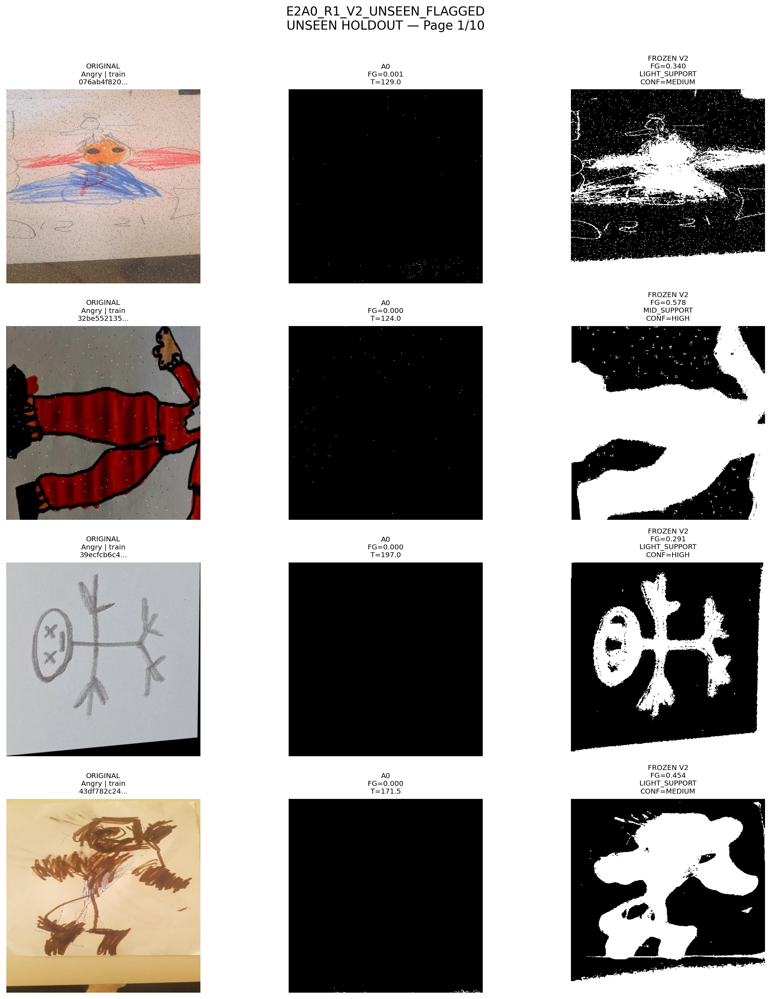


First unseen A0-OK page:


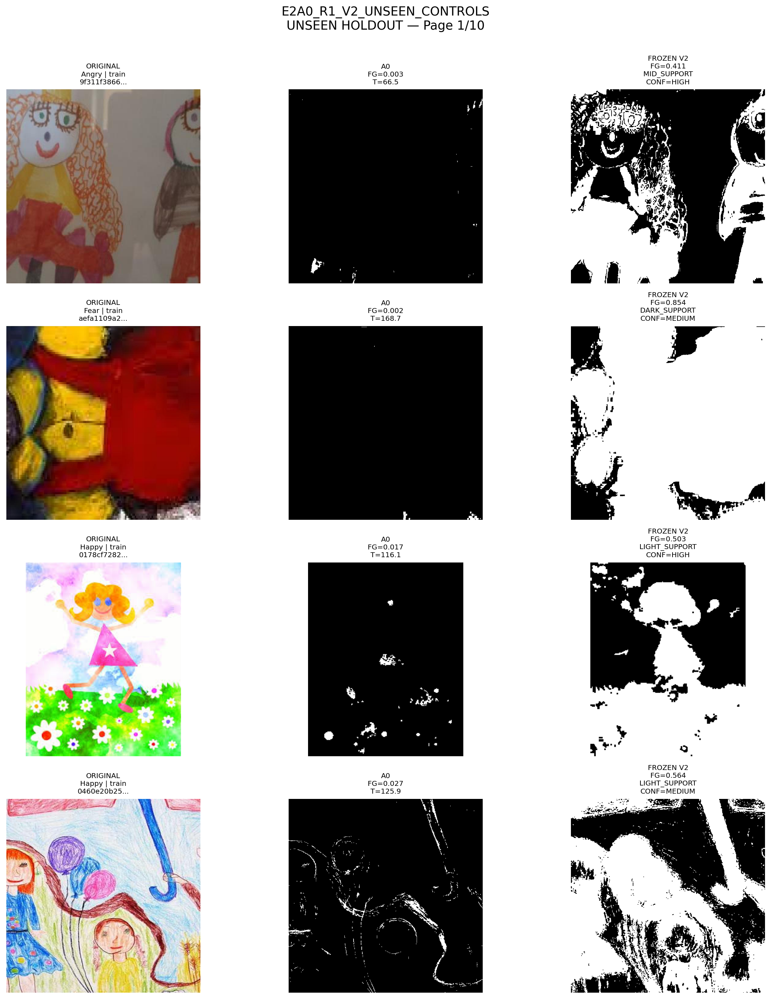


FROZEN V2 UNSEEN HOLDOUT COMPLETE

Holdout total: 80
A0 flagged   : 40
A0 OK        : 40

QC SUMMARY
holdout_group              v2_qc_status  count  group_total  percentage
   A0_FLAGGED         AMBIGUOUS_SUPPORT      4           40        10.0
   A0_FLAGGED                        OK     31           40        77.5
   A0_FLAGGED POSSIBLE_BACKGROUND_FLOOD      1           40         2.5
   A0_FLAGGED      VERY_HIGH_FOREGROUND      4           40        10.0
        A0_OK         AMBIGUOUS_SUPPORT      1           40         2.5
        A0_OK                        OK     38           40        95.0
        A0_OK      VERY_HIGH_FOREGROUND      1           40         2.5

MEASUREMENT POLICY SUMMARY
holdout_group v2_measurement_policy  count  group_total  percentage
   A0_FLAGGED  MASK_REVIEW_REQUIRED      5           40        12.5
   A0_FLAGGED       MASK_UNRELIABLE      4           40        10.0
   A0_FLAGGED           MASK_USABLE     31           40        77.5
        A0_OK  MASK_RE

In [ ]:
# ==================================================================================================
# DOAR MASTER THESIS
# E2-A0-R1-V2 — FROZEN UNSEEN QC HOLDOUT
#
# FINAL FOREGROUND-DEVELOPMENT GATE BEFORE FULL E2 EXTRACTION
#
# PURPOSE
# -------
# Evaluate the FROZEN V2 foreground extractor on images that were NOT used
# during A0-R1-V1/V2 development.
#
# HOLDOUT:
#   40 previously unseen A0-flagged images
#   40 previously unseen A0-OK images
#   = 80 total
#
# Stratified proportionally by:
#   split × benchmark class
#
# CRITICAL RULE:
# ----------------
# V2 MUST NOT BE MODIFIED AFTER THESE 80 IMAGES ARE EXPOSED.
#
# If the holdout is acceptable:
#   -> V2 becomes the frozen corrected deterministic foreground baseline
#   -> run full Train+Validation corrected extraction
#   -> proceed to E2-A1
#
# If problems remain:
#   -> document limitation
#   -> use mask-confidence / reliability gating
#   -> do NOT start endless V3/V4/V5 tuning unless a catastrophic systematic failure appears
#
# NO CLASSIFIER
# NO NEW FORMAL FEATURES
# NO PSYCHOLOGICAL RULES
# NO LOCKED TEST
# ==================================================================================================

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
from datetime import datetime, timezone
from matplotlib.backends.backend_pdf import PdfPages
from IPython.display import display, Image as IPImage

import hashlib
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm


# ==================================================================================================
# 1. VERIFY THE FROZEN V2 FUNCTIONS STILL EXIST
# ==================================================================================================

required_functions = [
    "build_v2_mask",
    "build_a0_mask",
    "border_foreground_fraction",
    "v2_qc_status",
]

missing_functions = [
    name
    for name in required_functions
    if name not in globals()
]

if missing_functions:

    raise RuntimeError(
        "\n"
        "STOP — the frozen V2 functions are not loaded in this runtime.\n\n"
        f"Missing: {missing_functions}\n\n"
        "Rerun the SAME E2-A0-R1-V2 DEVELOPMENT PILOT cell that you already used.\n"
        "Do NOT edit its thresholds or implementation.\n"
        "Then rerun this holdout cell."
    )


print("=" * 112)
print("DOAR E2-A0-R1-V2 — FROZEN UNSEEN QC HOLDOUT")
print("=" * 112)

print("V2 algorithm          : FROZEN")
print("New tuning            : FORBIDDEN")
print("Classifier            : NONE")
print("Expanded formal layer : NONE")
print("Psychological rules   : NONE")
print("Locked Test           : NOT ACCESSED")


# ==================================================================================================
# 2. PATHS
# ==================================================================================================

DATASET_ROOT = Path(
    "/content/drive/MyDrive/Masters/Datasets/Combined_Drawing"
)

E2A0_ROOT = Path(
    "/content/drive/MyDrive/Masters/DOAR_GPU_RESULTS/E2/"
    "E2A_INTERPRETABLE_FEATURES"
)

SOURCE_FEATURE_FILE = (
    E2A0_ROOT
    / "tables"
    / "E2A_T1_INTERPRETABLE_FEATURES.csv"
)

V1_RESULT_FILE = (
    E2A0_ROOT
    / "E2A0_R1_PILOT_V1"
    / "tables"
    / "E2A0_R1_PILOT_MASK_RESULTS.csv"
)

V2_DEV_RESULT_FILE = (
    E2A0_ROOT
    / "E2A0_R1_V2_PILOT"
    / "tables"
    / "E2A0_R1_V2_PILOT_RESULTS.csv"
)

HOLDOUT_ROOT = (
    E2A0_ROOT
    / "E2A0_R1_V2_UNSEEN_HOLDOUT"
)

TABLE_DIR = (
    HOLDOUT_ROOT
    / "tables"
)

FIGURE_DIR = (
    HOLDOUT_ROOT
    / "figures"
)

FLAGGED_CONTACT_DIR = (
    FIGURE_DIR
    / "flagged_contact_sheets"
)

CONTROL_CONTACT_DIR = (
    FIGURE_DIR
    / "control_contact_sheets"
)

for directory in [
    HOLDOUT_ROOT,
    TABLE_DIR,
    FIGURE_DIR,
    FLAGGED_CONTACT_DIR,
    CONTROL_CONTACT_DIR,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ==================================================================================================
# 3. VERIFY FROZEN E2-A0 SOURCE
# ==================================================================================================

EXPECTED_E2A0_SHA256 = (
    "6ea50e3a9517e4681eda1f05e802b384e07b54295850d43fa8cd0a7dd78d1fda"
)


def sha256_file(path):

    hasher = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b"",
        ):

            hasher.update(chunk)

    return hasher.hexdigest()


assert SOURCE_FEATURE_FILE.exists()
assert V1_RESULT_FILE.exists()
assert V2_DEV_RESULT_FILE.exists()


source_sha = sha256_file(
    SOURCE_FEATURE_FILE
)


assert source_sha == EXPECTED_E2A0_SHA256, (
    "STOP: frozen E2-A0 source changed."
)


print()
print("✓ E2-A0 SHA verified:")
print(source_sha)


# ==================================================================================================
# 4. LOAD SOURCE DATA
# ==================================================================================================

features = pd.read_csv(
    SOURCE_FEATURE_FILE
)

features["image_id"] = (
    features["image_id"]
    .astype(str)
)


assert len(features) == 2883
assert features["image_id"].is_unique

assert (
    features["split"]
    == "train"
).sum() == 2599

assert (
    features["split"]
    == "valid"
).sum() == 284

assert (
    features["split"]
    == "test"
).sum() == 0


# ==================================================================================================
# 5. IDENTIFY ALL DEVELOPMENT IMAGES THAT MUST BE EXCLUDED
# ==================================================================================================

v1_dev = pd.read_csv(
    V1_RESULT_FILE
)

v1_dev["image_id"] = (
    v1_dev["image_id"]
    .astype(str)
)


v2_dev = pd.read_csv(
    V2_DEV_RESULT_FILE
)

v2_dev["image_id"] = (
    v2_dev["image_id"]
    .astype(str)
)


development_ids = set(
    v1_dev["image_id"]
).union(
    set(
        v2_dev["image_id"]
    )
)


assert len(development_ids) == 84, (
    f"Expected 84 unique development images; found {len(development_ids)}."
)


print()
print("✓ Development images excluded:", len(development_ids))


# ==================================================================================================
# 6. CREATE UNSEEN POOLS
# ==================================================================================================

unseen = (
    features[
        ~features[
            "image_id"
        ].isin(
            development_ids
        )
    ]
    .copy()
)


unseen[
    "selection_group"
] = np.where(
    unseen[
        "qc_flag"
    ].isin(
        [
            "NO_FOREGROUND",
            "VERY_LOW_FOREGROUND",
        ]
    ),
    "A0_FLAGGED",
    "A0_OK",
)


flagged_pool = (
    unseen[
        unseen[
            "selection_group"
        ]
        == "A0_FLAGGED"
    ]
    .copy()
)


ok_pool = (
    unseen[
        unseen[
            "selection_group"
        ]
        == "A0_OK"
    ]
    .copy()
)


assert len(flagged_pool) >= 40
assert len(ok_pool) >= 40


print()
print("Unseen A0-flagged pool:", len(flagged_pool))
print("Unseen A0-OK pool     :", len(ok_pool))


# ==================================================================================================
# 7. DETERMINISTIC PROPORTIONAL STRATIFIED SAMPLING
#
# Stratification:
#   split × true_class
#
# The method:
#   - gives every available stratum at least one sample where possible
#   - distributes remaining quota proportionally
#   - uses SHA256 ordering inside each stratum
#
# This avoids cherry-picking.
# ==================================================================================================

STRATA = [
    "split",
    "true_class",
]


def deterministic_hash(
    image_id,
    salt,
):

    return hashlib.sha256(
        (
            str(salt)
            +
            "::"
            +
            str(image_id)
        ).encode(
            "utf-8"
        )
    ).hexdigest()


def proportional_stratified_sample(
    dataframe,
    n_total,
    salt,
):

    df = (
        dataframe.copy()
    )


    counts = (
        df.groupby(
            STRATA,
            observed=True,
        )
        .size()
        .reset_index(
            name="available"
        )
    )


    active_count = len(
        counts
    )


    if n_total < active_count:

        raise ValueError(
            "Requested sample is smaller than number of non-empty strata."
        )


    # ----------------------------------------------------------------------------------------------
    # Give each stratum one sample first.
    # ----------------------------------------------------------------------------------------------

    counts[
        "quota"
    ] = 1


    remaining = (
        n_total
        -
        int(
            counts[
                "quota"
            ].sum()
        )
    )


    # ----------------------------------------------------------------------------------------------
    # Allocate remaining quota iteratively in proportion to available capacity.
    # ----------------------------------------------------------------------------------------------

    while remaining > 0:

        counts[
            "capacity"
        ] = (
            counts[
                "available"
            ]
            -
            counts[
                "quota"
            ]
        )


        eligible = (
            counts[
                "capacity"
            ]
            > 0
        )


        if not eligible.any():

            raise RuntimeError(
                "Not enough samples available to satisfy requested total."
            )


        total_capacity = float(
            counts.loc[
                eligible,
                "capacity"
            ].sum()
        )


        counts[
            "_allocation_score"
        ] = -1.0


        counts.loc[
            eligible,
            "_allocation_score"
        ] = (
            counts.loc[
                eligible,
                "capacity"
            ]
            /
            total_capacity
        )


        # Deterministically allocate one at a time to highest-capacity proportion.
        best_index = (
            counts[
                "_allocation_score"
            ]
            .idxmax()
        )


        counts.loc[
            best_index,
            "quota"
        ] += 1


        remaining -= 1


    sampled_parts = []


    for _, quota_row in counts.iterrows():

        subset = df.copy()


        for column in STRATA:

            subset = subset[
                subset[
                    column
                ]
                ==
                quota_row[
                    column
                ]
            ]


        subset = (
            subset.copy()
        )


        subset[
            "_selection_hash"
        ] = subset[
            "image_id"
        ].map(
            lambda x:
            deterministic_hash(
                x,
                salt,
            )
        )


        subset = (
            subset
            .sort_values(
                "_selection_hash"
            )
            .head(
                int(
                    quota_row[
                        "quota"
                    ]
                )
            )
        )


        sampled_parts.append(
            subset
        )


    sampled = pd.concat(
        sampled_parts,
        ignore_index=True,
    )


    sampled = sampled.drop(
        columns=[
            "_selection_hash"
        ],
        errors="ignore",
    )


    assert len(sampled) == n_total
    assert sampled["image_id"].is_unique


    return (
        sampled,
        counts.drop(
            columns=[
                "_allocation_score",
                "capacity",
            ],
            errors="ignore",
        ),
    )


# ==================================================================================================
# 8. SELECT THE FROZEN 80-IMAGE HOLDOUT
# ==================================================================================================

holdout_flagged, flagged_quota = (
    proportional_stratified_sample(
        flagged_pool,
        n_total=40,
        salt="DOAR_E2A0_R1_V2_HOLDOUT_FLAGGED_V1",
    )
)


holdout_ok, ok_quota = (
    proportional_stratified_sample(
        ok_pool,
        n_total=40,
        salt="DOAR_E2A0_R1_V2_HOLDOUT_OK_V1",
    )
)


holdout_flagged[
    "holdout_group"
] = "A0_FLAGGED"


holdout_ok[
    "holdout_group"
] = "A0_OK"


holdout = pd.concat(
    [
        holdout_flagged,
        holdout_ok,
    ],
    ignore_index=True,
)


assert len(holdout) == 80
assert holdout["image_id"].is_unique

assert not set(
    holdout["image_id"]
).intersection(
    development_ids
)


HOLDOUT_MANIFEST_FILE = (
    TABLE_DIR
    / "E2A0_R1_V2_UNSEEN_HOLDOUT_MANIFEST.csv"
)


holdout.to_csv(
    HOLDOUT_MANIFEST_FILE,
    index=False,
)


flagged_quota.to_csv(
    TABLE_DIR
    / "E2A0_R1_V2_HOLDOUT_FLAGGED_QUOTAS.csv",
    index=False,
)


ok_quota.to_csv(
    TABLE_DIR
    / "E2A0_R1_V2_HOLDOUT_OK_QUOTAS.csv",
    index=False,
)


print()
print("=" * 112)
print("UNSEEN HOLDOUT CREATED")
print("=" * 112)

print("A0 flagged:", len(holdout_flagged))
print("A0 OK     :", len(holdout_ok))
print("Total     :", len(holdout))

print()
print("Split × class composition:")

print(
    pd.crosstab(
        [
            holdout[
                "holdout_group"
            ],
            holdout[
                "split"
            ],
        ],
        holdout[
            "true_class"
        ],
        margins=True,
    )
)


# ==================================================================================================
# 9. ENGINEERING RELIABILITY POLICY
#
# This does NOT replace visual evaluation.
#
# It tells downstream E2 code whether mask-dependent features may be trusted.
#
# MASK_USABLE
#   -> support is HIGH/MEDIUM confidence and no obvious algorithmic QC warning
#
# MASK_REVIEW_REQUIRED
#   -> unusual very-high foreground or possible flooding
#
# MASK_UNRELIABLE
#   -> support/background could not be established or foreground was effectively absent
#
# ==================================================================================================

def measurement_policy(
    qc_status,
    support_confidence,
):

    if qc_status in [
        "AMBIGUOUS_SUPPORT",
        "NO_FOREGROUND",
        "VERY_LOW_FOREGROUND",
    ]:

        return (
            "MASK_UNRELIABLE"
        )


    if qc_status in [
        "POSSIBLE_BACKGROUND_FLOOD",
        "VERY_HIGH_FOREGROUND",
    ]:

        return (
            "MASK_REVIEW_REQUIRED"
        )


    if (
        support_confidence
        in [
            "HIGH",
            "MEDIUM",
        ]
        and
        qc_status
        == "OK"
    ):

        return (
            "MASK_USABLE"
        )


    return (
        "MASK_REVIEW_REQUIRED"
    )


# ==================================================================================================
# 10. RUN FROZEN V2
# ==================================================================================================

result_rows = []


for _, row in tqdm(
    holdout.iterrows(),
    total=len(holdout),
    desc="Frozen V2 unseen holdout",
):

    image_path = (
        DATASET_ROOT
        /
        row[
            "relative_path"
        ]
    )


    with Image.open(
        image_path
    ) as image_file:

        image_rgb = np.asarray(
            image_file.convert(
                "RGB"
            )
        )


    a0 = build_a0_mask(
        image_rgb
    )


    v2 = build_v2_mask(
        image_rgb
    )


    a0_ratio = float(
        a0[
            "mask"
        ].mean()
    )


    v2_ratio = float(
        v2[
            "mask"
        ].mean()
    )


    border_ratio = (
        border_foreground_fraction(
            v2[
                "mask"
            ]
        )
    )


    qc_status = (
        v2_qc_status(
            foreground_ratio=
                v2_ratio,

            border_fg_ratio=
                border_ratio,

            support_regime=
                v2[
                    "support_regime"
                ],
        )
    )


    policy = measurement_policy(
        qc_status=
            qc_status,

        support_confidence=
            v2[
                "support_confidence"
            ],
    )


    result_rows.append(
        {
            "holdout_group":
                row[
                    "holdout_group"
                ],

            "image_id":
                str(
                    row[
                        "image_id"
                    ]
                ),

            "split":
                row[
                    "split"
                ],

            "true_class":
                row[
                    "true_class"
                ],

            "relative_path":
                row[
                    "relative_path"
                ],

            "a0_qc_status":
                row[
                    "qc_flag"
                ],

            "a0_foreground_fraction_saved":
                float(
                    row[
                        "foreground_fraction"
                    ]
                ),

            "a0_foreground_fraction_recreated":
                a0_ratio,

            "a0_threshold":
                float(
                    a0[
                        "threshold"
                    ]
                ),

            "v2_foreground_fraction":
                v2_ratio,

            "v2_border_foreground_fraction":
                border_ratio,

            "v2_qc_status":
                qc_status,

            "v2_support_regime":
                v2[
                    "support_regime"
                ],

            "v2_support_confidence":
                v2[
                    "support_confidence"
                ],

            "v2_measurement_policy":
                policy,

            "v2_support_radius":
                float(
                    v2[
                        "support_radius"
                    ]
                ),

            "v2_dominant_border_ratio":
                float(
                    v2[
                        "dominant_border_ratio"
                    ]
                ),

            "v2_covered_sides":
                int(
                    v2[
                        "covered_sides"
                    ]
                ),

            "v2_whole_support_fraction":
                float(
                    v2[
                        "whole_support_fraction"
                    ]
                ),

            "v2_cluster_dispersion":
                float(
                    v2[
                        "cluster_dispersion"
                    ]
                ),

            "v2_global_threshold":
                v2[
                    "global_threshold"
                ],

            "v2_local_threshold":
                float(
                    v2[
                        "local_threshold"
                    ]
                ),

            "v2_mask_strategy":
                v2[
                    "mask_strategy"
                ],
        }
    )


results = pd.DataFrame(
    result_rows
)


RESULT_FILE = (
    TABLE_DIR
    / "E2A0_R1_V2_UNSEEN_HOLDOUT_RESULTS.csv"
)


results.to_csv(
    RESULT_FILE,
    index=False,
)


print()
print("✓ Frozen V2 evaluated on all 80 unseen images.")


# ==================================================================================================
# 11. QC SUMMARY
# ==================================================================================================

qc_summary = (
    results
    .groupby(
        [
            "holdout_group",
            "v2_qc_status",
        ],
        dropna=False,
    )
    .size()
    .reset_index(
        name="count"
    )
)


totals = (
    results
    .groupby(
        "holdout_group"
    )
    .size()
    .rename(
        "group_total"
    )
    .reset_index()
)


qc_summary = qc_summary.merge(
    totals,
    on="holdout_group",
    how="left",
)


qc_summary[
    "percentage"
] = (
    100.0
    *
    qc_summary[
        "count"
    ]
    /
    qc_summary[
        "group_total"
    ]
)


QC_SUMMARY_FILE = (
    TABLE_DIR
    / "E2A0_R1_V2_HOLDOUT_QC_SUMMARY.csv"
)


qc_summary.to_csv(
    QC_SUMMARY_FILE,
    index=False,
)


# ==================================================================================================
# 12. SUPPORT SUMMARY
# ==================================================================================================

support_summary = (
    results
    .groupby(
        [
            "holdout_group",
            "v2_support_regime",
            "v2_support_confidence",
        ],
        dropna=False,
    )
    .size()
    .reset_index(
        name="count"
    )
)


SUPPORT_SUMMARY_FILE = (
    TABLE_DIR
    / "E2A0_R1_V2_HOLDOUT_SUPPORT_SUMMARY.csv"
)


support_summary.to_csv(
    SUPPORT_SUMMARY_FILE,
    index=False,
)


# ==================================================================================================
# 13. MEASUREMENT POLICY SUMMARY
# ==================================================================================================

policy_summary = (
    results
    .groupby(
        [
            "holdout_group",
            "v2_measurement_policy",
        ]
    )
    .size()
    .reset_index(
        name="count"
    )
)


policy_summary = policy_summary.merge(
    totals,
    on="holdout_group",
    how="left",
)


policy_summary[
    "percentage"
] = (
    100.0
    *
    policy_summary[
        "count"
    ]
    /
    policy_summary[
        "group_total"
    ]
)


POLICY_SUMMARY_FILE = (
    TABLE_DIR
    / "E2A0_R1_V2_HOLDOUT_MEASUREMENT_POLICY_SUMMARY.csv"
)


policy_summary.to_csv(
    POLICY_SUMMARY_FILE,
    index=False,
)


print()
print("=" * 112)
print("QC SUMMARY")
print("=" * 112)

print(
    qc_summary.to_string(
        index=False
    )
)


print()
print("=" * 112)
print("SUPPORT SUMMARY")
print("=" * 112)

print(
    support_summary.to_string(
        index=False
    )
)


print()
print("=" * 112)
print("MEASUREMENT RELIABILITY SUMMARY")
print("=" * 112)

print(
    policy_summary.to_string(
        index=False
    )
)


# ==================================================================================================
# 14. MANUAL VISUAL REVIEW TABLE
#
# DO NOT AUTO-FILL THESE.
#
# Allowed mask quality:
#
# GOOD
# PARTIAL
# FAILED
# OVERSEGMENTED
# UNDERSEGMENTED
# APPROPRIATELY_AMBIGUOUS
# UNCERTAIN
#
# The final decision comes from this visual review.
# ==================================================================================================

review = results.copy()


review[
    "visual_mask_quality"
] = ""


review[
    "support_classification_quality"
] = ""


review[
    "visual_notes"
] = ""


review[
    "review_complete"
] = False


REVIEW_FILE = (
    TABLE_DIR
    / "E2A0_R1_V2_HOLDOUT_VISUAL_REVIEW.csv"
)


review.to_csv(
    REVIEW_FILE,
    index=False,
)


# ==================================================================================================
# 15. CONTACT SHEETS
#
# ORIGINAL | A0 | FROZEN V2
#
# 4 cases/page
# ==================================================================================================

def create_holdout_contact_sheets(
    dataframe,
    output_directory,
    base_name,
    cases_per_page=4,
):

    output_directory.mkdir(
        parents=True,
        exist_ok=True,
    )


    dataframe = (
        dataframe
        .sort_values(
            [
                "split",
                "true_class",
                "image_id",
            ]
        )
        .reset_index(
            drop=True
        )
    )


    total_pages = math.ceil(
        len(
            dataframe
        )
        /
        cases_per_page
    )


    pdf_path = (
        output_directory
        /
        f"{base_name}.pdf"
    )


    png_pages = []


    with PdfPages(
        pdf_path
    ) as pdf:

        for page_idx in tqdm(
            range(
                total_pages
            ),
            desc=base_name,
        ):

            start = (
                page_idx
                *
                cases_per_page
            )

            end = min(
                start
                +
                cases_per_page,
                len(
                    dataframe
                ),
            )


            page_df = (
                dataframe
                .iloc[
                    start:end
                ]
                .reset_index(
                    drop=True
                )
            )


            fig, axes = plt.subplots(
                cases_per_page,
                3,
                figsize=(
                    14,
                    4
                    *
                    cases_per_page
                ),
            )


            axes = np.asarray(
                axes
            ).reshape(
                cases_per_page,
                3
            )


            for axis in axes.flat:

                axis.axis(
                    "off"
                )


            for r, (_, row) in enumerate(
                page_df.iterrows()
            ):

                image_path = (
                    DATASET_ROOT
                    /
                    row[
                        "relative_path"
                    ]
                )


                with Image.open(
                    image_path
                ) as image_file:

                    image_rgb = np.asarray(
                        image_file.convert(
                            "RGB"
                        )
                    )


                a0 = build_a0_mask(
                    image_rgb
                )

                v2 = build_v2_mask(
                    image_rgb
                )


                axes[
                    r,
                    0
                ].imshow(
                    image_rgb
                )

                axes[
                    r,
                    0
                ].set_title(
                    (
                        "ORIGINAL\n"
                        f"{row['true_class']} | "
                        f"{row['split']}\n"
                        f"{str(row['image_id'])[:10]}..."
                    ),
                    fontsize=8,
                )


                axes[
                    r,
                    1
                ].imshow(
                    a0[
                        "mask"
                    ],
                    cmap="gray",
                    vmin=0,
                    vmax=1,
                )

                axes[
                    r,
                    1
                ].set_title(
                    (
                        "A0\n"
                        f"FG={a0['mask'].mean():.3f}\n"
                        f"T={a0['threshold']:.1f}"
                    ),
                    fontsize=8,
                )


                axes[
                    r,
                    2
                ].imshow(
                    v2[
                        "mask"
                    ],
                    cmap="gray",
                    vmin=0,
                    vmax=1,
                )

                axes[
                    r,
                    2
                ].set_title(
                    (
                        "FROZEN V2\n"
                        f"FG={v2['mask'].mean():.3f}\n"
                        f"{v2['support_regime']}\n"
                        f"CONF={v2['support_confidence']}"
                    ),
                    fontsize=8,
                )


                for c in range(
                    3
                ):

                    axes[
                        r,
                        c
                    ].axis(
                        "off"
                    )


            fig.suptitle(
                (
                    f"{base_name}\n"
                    f"UNSEEN HOLDOUT — Page "
                    f"{page_idx + 1}/{total_pages}"
                ),
                fontsize=14,
            )


            fig.tight_layout(
                rect=[
                    0,
                    0,
                    1,
                    0.975,
                ]
            )


            png_path = (
                output_directory
                /
                (
                    f"{base_name}_"
                    f"page_{page_idx + 1:03d}.png"
                )
            )


            fig.savefig(
                png_path,
                dpi=180,
                bbox_inches="tight",
            )


            pdf.savefig(
                fig,
                bbox_inches="tight",
            )


            plt.close(
                fig
            )


            png_pages.append(
                png_path
            )


    return {
        "pdf":
            pdf_path,

        "png_pages":
            png_pages,
    }


flagged_results = (
    results[
        results[
            "holdout_group"
        ]
        == "A0_FLAGGED"
    ]
    .copy()
)


ok_results = (
    results[
        results[
            "holdout_group"
        ]
        == "A0_OK"
    ]
    .copy()
)


flagged_contact = (
    create_holdout_contact_sheets(
        flagged_results,
        FLAGGED_CONTACT_DIR,
        "E2A0_R1_V2_UNSEEN_FLAGGED",
    )
)


control_contact = (
    create_holdout_contact_sheets(
        ok_results,
        CONTROL_CONTACT_DIR,
        "E2A0_R1_V2_UNSEEN_CONTROLS",
    )
)


# ==================================================================================================
# 16. PROTOCOL / FREEZE RECORD
# ==================================================================================================

protocol = {

    "experiment":
        "E2-A0-R1-V2 Frozen Unseen QC Holdout",

    "timestamp_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "source_E2A0_sha256":
        source_sha,

    "v2_algorithm_status_before_holdout":
        "FROZEN_CANDIDATE",

    "algorithm_modification_after_holdout_allowed":
        False,

    "development_images_excluded":
        int(
            len(
                development_ids
            )
        ),

    "holdout_total":
        int(
            len(
                results
            )
        ),

    "holdout_A0_flagged":
        int(
            len(
                flagged_results
            )
        ),

    "holdout_A0_OK":
        int(
            len(
                ok_results
            )
        ),

    "sampling":
        (
            "Deterministic proportional stratification "
            "by split × benchmark class using SHA256 ordering."
        ),

    "measurement_policy": {

        "MASK_USABLE":
            (
                "HIGH/MEDIUM support confidence and QC=OK."
            ),

        "MASK_REVIEW_REQUIRED":
            (
                "Very-high foreground, possible flood, or "
                "otherwise unusual extraction."
            ),

        "MASK_UNRELIABLE":
            (
                "Ambiguous support, no foreground, or "
                "very-low foreground."
            ),
    },

    "visual_review_required":
        True,

    "training":
        False,

    "classifier":
        False,

    "expanded_formal_features":
        False,

    "psychological_rules":
        False,

    "locked_test_accessed":
        False,

    "decision_rule":
        (
            "If frozen V2 shows no catastrophic systematic "
            "failure on the unseen holdout, accept it as the "
            "confidence-aware deterministic baseline. "
            "Document residual limitations rather than retuning "
            "after seeing the holdout."
        ),
}


PROTOCOL_FILE = (
    HOLDOUT_ROOT
    / "E2A0_R1_V2_UNSEEN_HOLDOUT_PROTOCOL.json"
)


PROTOCOL_FILE.write_text(
    json.dumps(
        protocol,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ==================================================================================================
# 17. README
# ==================================================================================================

README_FILE = (
    HOLDOUT_ROOT
    / "README_E2A0_R1_V2_UNSEEN_HOLDOUT.md"
)


README_FILE.write_text(
    f"""
# E2-A0-R1-V2 Frozen Unseen QC Holdout

## Purpose

This is the final external QC gate for the deterministic corrected
foreground extractor before full Train+Validation extraction.

## Development exclusion

84 images used during A0/R1/V2 development were excluded.

## Unseen holdout

40 previously unseen A0-flagged drawings.

40 previously unseen A0-OK drawings.

Total = 80.

Selection was deterministic and stratified by split × benchmark class.

## Critical rule

The V2 algorithm was frozen before this holdout was exposed.

No threshold or algorithmic tuning should occur after visual inspection
of these 80 images.

If residual errors are non-catastrophic, they are documented as
limitations and handled using measurement-confidence gating.

## Measurement reliability

MASK_USABLE

Mask-derived measurements may be used normally.

MASK_REVIEW_REQUIRED

Mask-derived measurements are retained with caution / sensitivity handling.

MASK_UNRELIABLE

Mask-dependent objective measurements should not be treated as reliable
observations.

Whole-image measurements that do not depend on foreground segmentation
may still be computed.

## Boundaries

No classifier.

No expanded formal-feature experiment.

No psychological-rule aggregation.

Locked Test untouched.

E2-A0 frozen and unchanged.
""".strip()
    + "\n",
    encoding="utf-8",
)


# ==================================================================================================
# 18. DISPLAY FIRST PAGES
# ==================================================================================================

if flagged_contact["png_pages"]:

    print()
    print("First unseen A0-FLAGGED page:")

    display(
        IPImage(
            filename=str(
                flagged_contact[
                    "png_pages"
                ][0]
            )
        )
    )


if control_contact["png_pages"]:

    print()
    print("First unseen A0-OK page:")

    display(
        IPImage(
            filename=str(
                control_contact[
                    "png_pages"
                ][0]
            )
        )
    )


# ==================================================================================================
# 19. FINAL OUTPUT
# ==================================================================================================

print()
print("=" * 112)
print("FROZEN V2 UNSEEN HOLDOUT COMPLETE")
print("=" * 112)

print()
print("Holdout total:", len(results))
print("A0 flagged   :", len(flagged_results))
print("A0 OK        :", len(ok_results))

print()
print("QC SUMMARY")
print(
    qc_summary.to_string(
        index=False
    )
)

print()
print("MEASUREMENT POLICY SUMMARY")
print(
    policy_summary.to_string(
        index=False
    )
)

print()
print("Files:")

print(
    "  Holdout manifest:",
    HOLDOUT_MANIFEST_FILE
)

print(
    "  Results:",
    RESULT_FILE
)

print(
    "  Visual review:",
    REVIEW_FILE
)

print(
    "  Flagged PDF:",
    flagged_contact["pdf"]
)

print(
    "  Control PDF:",
    control_contact["pdf"]
)

print(
    "  Protocol:",
    PROTOCOL_FILE
)

print(
    "  README:",
    README_FILE
)


print()
print("✓ V2 FROZEN BEFORE HOLDOUT.")
print("✓ DEVELOPMENT IMAGES EXCLUDED.")
print("✓ NO V2 RETUNING ALLOWED AFTER THIS RUN.")
print("✓ NO CLASSIFIER.")
print("✓ NO FORMAL-FEATURE EXPANSION.")
print("✓ NO PSYCHOLOGICAL RULES.")
print("✓ LOCKED TEST NOT ACCESSED.")


print()
print("=" * 112)
print("NEXT")
print("=" * 112)

print(
    "Send ChatGPT:"
)

print(
    "1. QC SUMMARY"
)

print(
    "2. MEASUREMENT POLICY SUMMARY"
)

print(
    "3. SUPPORT SUMMARY"
)

print(
    "4. Unseen flagged PDF"
)

print(
    "5. Unseen control PDF"
)

print()
print(
    "If the holdout shows no catastrophic systematic failure, "
    "we ACCEPT V2 WITH CONFIDENCE GATING and move to the "
    "full corrected 2,883-image extraction."
)

print()
print(
    "Do NOT modify V2 after reviewing these holdout images."
)